# Phase 2 — Amazon Reviews ’23: data preparation, features, and exploratory clusters

**Research question:** Can we predict a review's *recorded number of helpful votes* from its text and available structured/product information? `helpful_vote` is a nonnegative count and is the **future Phase 3 supervised target**, not a clustering feature.

**Phase 2 scope:** All clustering (`k`, feature weights, preprocessing, fitting and stability checks) is **target-free**. Once a partition is frozen, helpful-vote summaries on **train/validation only** are permitted as *post-hoc, descriptive* analyses. A difference in votes between clusters is not proof of predictive improvement. Exposure, age, and product visibility remain important confounders.

**Model history:** A is retained as a failed reference baseline; B/C are text-oriented diagnostics; D/E and S/E1 are mixed/structured controls; F is an archived negative control. E2 and the revised E2B examine other review characteristics. None is an automatic final predictive model.

**Evaluation protocol:** Keep `RUN_FINAL_TEST_AUDIT=False` during Phase 2. Historical notebook revisions inspected some target-free test features; disclose this previous inspection. The corrected workflow fixes the chronological split immediately after cleaning and restricts exploratory missingness/feature-quality summaries to TRAIN. The held-out test helpful-vote values remain uninspected.

**Images:** Section 8.18 selects product IDs deterministically (independent of cache contents), requires cached pixels to have URL-bound provenance and a successful current HTTP verification (200 or conditional 304) before reuse; otherwise it attempts bounded HTTPS downloads. Legacy caches are not automatically trusted. A frozen ImageNet-pretrained ResNet-18 extracts image embeddings for a matched-row (i) text + structured vs. (ii) text + structured + image comparison. Image embeddings are saved when pixels and pretrained weights are available. No image fetching is mandatory. Product-listing images must not be mistaken for customer-uploaded review photos.

**Run and verification:** This is a revised **source** notebook; its original saved outputs are intentionally removed so results cannot be mistaken for a fresh execution of the corrected code. Run from top to bottom in the complete project environment with `src/`, Amazon JSONL review/metadata files, and configured local paths. Recreate all figures, tables and exports and review numerical results before submission. A reproducible frozen-history reference bundle is saved locally as `phase2_reference_workflow_PRIVATE.joblib` (contains training reviewer/product keys: NEVER publish). Current joined product metadata supports **retrospective fixed-snapshot analysis only**, not verified at-publication inference.


## 0. Reproducibility and project configuration

The sample configuration below matches Phase 1: 40,000 reviews per category, reservoir sampling, and seed 42. Phase 1 is not modified or imported. Its reusable loading and cleaning logic has been moved into the `src/` modules supplied with this notebook.


In [1]:
from pathlib import Path
import sys
import json
import warnings
import math
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler, normalize

# Find this local VS Code project from root or notebooks/ working directory.
_here = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_here, *_here.parents)
     if (p / "src" / "project_paths.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate src/project_paths.py. Open the extracted project folder in VS Code."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
LOCAL = None  # Initialized after importing project configuration.

from src.project_paths import load_local_settings
from src.data_io import build_reviews_dataframe
from src.cleaning import clean_review_dataframe, has_value
from src.features import (
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
    engineer_review_features,
    get_feature_columns,
    get_feature_registry,
)
from src.preprocessing import (
    build_phase2_preprocessing_pipeline,
    build_structured_preprocessor,
)
from src.representations import (
    fit_svd_reduction,
    fit_pca_projection,
    extract_sentence_embeddings,
    combine_modalities,
    fit_umap_projection,
)
from src.diagnostics import (
    audit_duplicate_signatures,
    duplicate_audit_table,
    cross_split_duplicate_audit,
    missing_value_audit,
    review_quality_audit,
    distinctive_terms_by_cluster,
    cluster_size_and_drift,
)

from src.clustering import (
    evaluate_kmeans_candidates,
    evaluate_seed_stability,
    evaluate_subsample_stability,
    evaluate_scaling_sensitivity,
    summarize_clusters,
    cluster_category_mix,
    top_terms_by_cluster,
)

LOCAL = load_local_settings(PROJECT_ROOT)
SEED = LOCAL.seed
CATEGORIES = LOCAL.categories
REVIEW_SAMPLE_SIZE_PER_CATEGORY = LOCAL.sample_size_per_category
SEARCH_ROOTS = list(LOCAL.search_roots)
REVIEW_PATHS = LOCAL.review_paths
META_PATHS = LOCAL.metadata_paths

MAX_TFIDF_FEATURES = 15_000
TFIDF_MIN_DF = 3
N_REDUCED_COMPONENTS = 30

# Optional methods. The default notebook does not download external model weights.
USE_PRETRAINED_SENTENCE_EMBEDDINGS = False
SENTENCE_TRANSFORMER_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
USE_UMAP = False

CLUSTER_K_VALUES = range(2, 9)
CLUSTER_SEARCH_MAX_ROWS = 15_000
SILHOUETTE_SAMPLE_SIZE = 3_000
SELECTED_K_OVERRIDE = None  # Only override for reasons independent of helpful_vote.

# Optional sensitivity checks use a reproducible TRAINING subset, not held-out labels.
RUN_EXTENDED_DIAGNOSTICS = True
DIAGNOSTIC_SAMPLE_SIZE = 4_000     # Increase to 8,000 for more precise, slower checks.
DIAGNOSTIC_SVD_COMPONENTS = (15, 30, 60)
DIAGNOSTIC_SILHOUETTE_SAMPLE = 1_000
DIAGNOSTIC_VALIDATION_SIZE = 1_500

# Every execution writes to a fresh folder so optional/old artifacts cannot appear current.
# To choose a reproducible run name, set DA_PHASE2_RUN_ID in your environment.
RUN_FINAL_TEST_AUDIT = False   # Switch on only for ONE final audit after model choice is frozen.
# Joined product metadata may postdate the review. This project predicts *recorded*
# helpful votes from information in a fixed retrospective metadata snapshot.
# Do NOT claim at-publication deployability without timestamped/as-of metadata.
PREDICTION_CONTEXT = 'retrospective_fixed_snapshot'
assert PREDICTION_CONTEXT == 'retrospective_fixed_snapshot', (
    'At-publication prediction needs verified point-in-time product metadata and different feature policies.')
PRIOR_EXPLORATORY_TEST_INSPECTION = True  # Historical notebook had inspected target-free test outputs.
RUN_ID = os.environ.get('DA_PHASE2_RUN_ID') or pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ')
OUTPUT_DIR = LOCAL.output_root / 'phase2_revised_runs' / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)


np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Project root:", PROJECT_ROOT)
print("Local data search roots:", [str(path) for path in SEARCH_ROOTS])
print("Output directory:", OUTPUT_DIR)
print("Random seed:", SEED)
print("Sample size per category:", REVIEW_SAMPLE_SIZE_PER_CATEGORY)

Project root: D:\Uni\Term 7\Data Analysis\Project\Data-Analysis-Project
Local data search roots: ['D:\\Uni\\Term 7\\Data Analysis\\Project\\Data-Analysis-Project\\data\\raw']
Output directory: D:\Uni\Term 7\Data Analysis\Project\Data-Analysis-Project\outputs\phase2_revised_runs\20261120T213445744036Z
Random seed: 42
Sample size per category: 40000


# 1. ساخت زنجیره پیش‌پردازش — Build the preprocessing chain

We reconstruct the same sampled review/metadata table used in Phase 1 and apply deterministic cleaning and type conversion. **Chronological membership is fixed immediately after cleaning in Section 1.2**. Subsequent descriptive statistics, missingness audits, and feature-choice diagnostics run on training data only. These are transformations that do not estimate parameters from the data.

The chain will be completed in the following sections: missing-value handling is added in Section 2, domain-informed features in Section 3, and train-fitted encoding/scaling/text vectorization in Section 4. This order avoids introducing every transformation before it is needed.

### Phase 1 components reused here

- Exact JSONL discovery and plain/gzip reading.
- Seeded reservoir sampling.
- Streaming product-metadata lookup for sampled products.
- Deduplication of product metadata before a many-to-one join.
- HTML cleaning, numeric parsing, Boolean normalization, image counts, and timestamp conversion.

The original Phase 1 notebook remains unchanged.


### 1.1 Reconstruct the Phase 1 sample

The data are read from the configured local input directory. No direct download from the dataset website is performed.


In [2]:
analysis_raw, file_audit, file_paths, join_audit = build_reviews_dataframe(
    categories=CATEGORIES,
    roots=SEARCH_ROOTS,
    sample_size_per_category=REVIEW_SAMPLE_SIZE_PER_CATEGORY,
    seed=SEED,
    review_paths=REVIEW_PATHS,
    metadata_paths=META_PATHS,
)

display(file_audit)
display(pd.DataFrame([join_audit]))
display(
    analysis_raw.groupby("dataset_category")
    .size()
    .rename("sampled_review_rows")
    .to_frame()
)

print("Raw joined sample shape:", analysis_raw.shape)
print("Number of columns:", len(analysis_raw.columns))
print('Helpful-vote target retained for TRAIN-only audit after chronological splitting.')

# No global target distribution or missingness is inspected at this stage.


,category,review_file,metadata_file,valid_review_rows_scanned,sampled_review_rows,review_sample_fraction,blank_review_lines,invalid_review_json_lines,valid_metadata_rows_scanned,matched_metadata_rows_before_deduplication,blank_metadata_lines,invalid_metadata_json_lines
0,Musical_Instruments,D:\Uni\Term 7\Data Analysis\Project\Data-Analysis-Project\data\raw\Musical_Instruments.jsonl.gz,D:\Uni\Term 7\Data Analysis\Project\Data-Analysis-Project\data\raw\meta_Musical_Instruments.jsonl.gz,3017439,40000,0.013256,0,0,213593,20864,0,0
1,Video_Games,D:\Uni\Term 7\Data Analysis\Project\Data-Analysis-Project\data\raw\Video_Games.jsonl.gz,D:\Uni\Term 7\Data Analysis\Project\Data-Analysis-Project\data\raw\meta_Video_Games.jsonl.gz,4624615,40000,0.008649,0,0,137269,16324,0,0


,metadata_duplicate_rows_removed,review_rows,metadata_matched_rows,metadata_match_rate
0,0,80000,80000,1.0


,sampled_review_rows
dataset_category,
Musical_Instruments,40000
Video_Games,40000


Raw joined sample shape: (80000, 32)
Number of columns: 32
Helpful-vote target retained for TRAIN-only audit after chronological splitting.


### 1.2 Deterministic cleaning and immediate chronological split

Raw columns are retained. Cleaned values are added in separate columns so that the original source values remain available for auditing.


In [3]:
analysis_df = clean_review_dataframe(analysis_raw)

# Privacy/leakage boundary: create chronological partitions immediately after
# deterministic cleaning, before ANY training-data exploration or feature choice.
# Only timestamps are used to determine membership; no target values enter.
def chronological_split(df, timestamp_column="timestamp_dt",
                        train_fraction=0.70, validation_fraction=0.15):
    timestamps = pd.to_datetime(df[timestamp_column], errors="coerce", utc=True)
    valid_timestamps = timestamps.dropna().drop_duplicates().sort_values()

    if len(valid_timestamps) < 3:
        raise ValueError("Too few distinct valid timestamps for a chronological split.")

    train_position = max(0, min(
        len(valid_timestamps) - 3,
        int((len(valid_timestamps) - 1) * train_fraction)
    ))
    validation_position = max(
        train_position + 1,
        min(
            len(valid_timestamps) - 2,
            int((len(valid_timestamps) - 1) * (train_fraction + validation_fraction))
        )
    )

    train_cutoff = valid_timestamps.iloc[train_position]
    validation_cutoff = valid_timestamps.iloc[validation_position]

    train_mask = timestamps.le(train_cutoff) | timestamps.isna()
    validation_mask = timestamps.gt(train_cutoff) & timestamps.le(validation_cutoff)
    test_mask = timestamps.gt(validation_cutoff)

    train_df = df.loc[train_mask].copy()
    validation_df = df.loc[validation_mask].copy()
    test_df = df.loc[test_mask].copy()

    if min(len(train_df), len(validation_df), len(test_df)) == 0:
        raise ValueError(
            "A chronological partition is empty. Inspect timestamp coverage "
            "and the selected boundaries before proceeding."
        )

    split_info = pd.DataFrame([
        {
            "partition": "train",
            "rows": len(train_df),
            "start_timestamp": timestamps.loc[train_df.index].min(),
            "end_timestamp": timestamps.loc[train_df.index].max(),
        },
        {
            "partition": "validation",
            "rows": len(validation_df),
            "start_timestamp": timestamps.loc[validation_df.index].min(),
            "end_timestamp": timestamps.loc[validation_df.index].max(),
        },
        {
            "partition": "test",
            "rows": len(test_df),
            "start_timestamp": timestamps.loc[test_df.index].min(),
            "end_timestamp": timestamps.loc[test_df.index].max(),
        },
    ])
    return train_df, validation_df, test_df, split_info


train_clean, validation_clean, test_clean, split_info = chronological_split(analysis_df)
EARLY_TRAIN_INDEX = train_clean.index.copy()
EARLY_VALIDATION_INDEX = validation_clean.index.copy()
EARLY_TEST_INDEX = test_clean.index.copy()
assert len(EARLY_TRAIN_INDEX) + len(EARLY_VALIDATION_INDEX) + len(EARLY_TEST_INDEX) == len(analysis_df)
assert not EARLY_TRAIN_INDEX.intersection(EARLY_VALIDATION_INDEX).size
assert not EARLY_TRAIN_INDEX.intersection(EARLY_TEST_INDEX).size
assert not EARLY_VALIDATION_INDEX.intersection(EARLY_TEST_INDEX).size
# Only TRAIN is used for exploratory columns/missingness/feature quality below.
analysis_train = analysis_df.loc[EARLY_TRAIN_INDEX].copy()

cleaning_audit = pd.DataFrame([
    {
        "check": "Rows retained (TRAIN)",
        "value": len(analysis_train),
        "interpretation": "Deterministic cleaning retained training rows.",
    },
    {
        "check": "Nonempty cleaned review text (TRAIN)",
        "value": int(analysis_train["text_present"].sum()),
        "interpretation": "At least one cleaned title/body character is available.",
    },
    {
        "check": "Valid parsed timestamps (TRAIN)",
        "value": int(analysis_train["timestamp_dt"].notna().sum()),
        "interpretation": "Timestamp parsed to UTC.",
    },
    {
        "check": "Valid numeric ratings (TRAIN)",
        "value": int(analysis_train["rating_num"].notna().sum()),
        "interpretation": "Rating parsed numerically; range checks are reported separately.",
    },
    {
        "check": "Rows with joined product metadata (TRAIN)",
        "value": int(analysis_train["metadata_matched"].sum()),
        "interpretation": "A product metadata record matched the review product key.",
    },
])
display(cleaning_audit)
display(analysis_train[
    ["dataset_category", "rating", "rating_num", "title", "cleaned_title",
     "text", "cleaned_body", "timestamp", "timestamp_dt",
     "product_price", "product_price_num"]
].head(8))
print('Chronological split fixed BEFORE exploratory feature inspection. TRAIN rows:', len(analysis_train))


,check,value,interpretation
0,Rows retained (TRAIN),56000,Deterministic cleaning retained training rows.
1,Nonempty cleaned review text (TRAIN),56000,At least one cleaned title/body character is available.
2,Valid parsed timestamps (TRAIN),56000,Timestamp parsed to UTC.
3,Valid numeric ratings (TRAIN),56000,Rating parsed numerically; range checks are reported separately.
4,Rows with joined product metadata (TRAIN),56000,A product metadata record matched the review product key.


,dataset_category,rating,rating_num,title,cleaned_title,text,cleaned_body,timestamp,timestamp_dt,product_price,product_price_num
0,Musical_Instruments,5.0,5.0,I like this little pick carrier,I like this little pick carrier,I like this little pick carrier. Carries a few picks. Matches my Leather purse and keychain. I like this product....,I like this little pick carrier. Carries a few picks. Matches my Leather purse and keychain. I like this product. :),1475946965000,2016-10-08 17:16:05.000+00:00,10.61,10.61
1,Musical_Instruments,5.0,5.0,Five Stars,Five Stars,What an awesome guitar can't ask for more,What an awesome guitar can't ask for more,1502187900838,2017-08-08 10:25:00.838+00:00,None,NaN
3,Musical_Instruments,4.0,4.0,Good for Beginners,Good for Beginners,I watched a video of DJ TLM and decided this would be a good controller to start introducing myself to DJing. Its a ...,I watched a video of DJ TLM and decided this would be a good controller to start introducing myself to DJing. Its a ...,1454287033000,2016-02-01 00:37:13.000+00:00,228.0,228.00
4,Musical_Instruments,1.0,1.0,Saxophone Stand Not Pleased With This,Saxophone Stand Not Pleased With This,I purchased this stand for my child to use during his performances. The stand does not work for it did notsupport th...,I purchased this stand for my child to use during his performances. The stand does not work for it did notsupport th...,1358779744000,2013-01-21 14:49:04.000+00:00,None,NaN
5,Musical_Instruments,4.0,4.0,I had the previous shure headset mic and it was ...,I had the previous shure headset mic and it was ...,I had the previous shure headset mic and it was chronically uncomfortable. This one was worth buying even though my ...,I had the previous shure headset mic and it was chronically uncomfortable. This one was worth buying even though my ...,1447517740000,2015-11-14 16:15:40.000+00:00,99.0,99.00
6,Musical_Instruments,5.0,5.0,Had to have one,Had to have one,Love it,Love it,1437511327000,2015-07-21 20:42:07.000+00:00,27.55,27.55
7,Musical_Instruments,5.0,5.0,The power supply is perfect!!,The power supply is perfect!!,Great!!,Great!!,1575736581112,2019-12-07 16:36:21.112+00:00,389.95,389.95
9,Musical_Instruments,5.0,5.0,Great buy!,Great buy!,Exactly as described. The stick is so helpful for placing the stickers!,Exactly as described. The stick is so helpful for placing the stickers!,1503553569038,2017-08-24 05:46:09.038+00:00,5.99,5.99


Chronological split fixed BEFORE exploratory feature inspection. TRAIN rows: 56000


### 1.3 Check the deterministic transformations

These checks verify that the transformations produced the expected data types and that raw source columns were not overwritten.


In [4]:
type_check = pd.DataFrame({
    "column": [
        "rating", "rating_num",
        "timestamp", "timestamp_dt",
        "cleaned_title", "cleaned_body", "cleaned_text",
        "product_price", "product_price_num",
        "verified_purchase_clean",
    ],
    "dtype": [
        str(analysis_train[c].dtype) if c in analysis_train else "not available"
        for c in [
                "rating", "rating_num",
            "timestamp", "timestamp_dt",
            "cleaned_title", "cleaned_body", "cleaned_text",
            "product_price", "product_price_num",
            "verified_purchase_clean",
        ]
    ],
    "missing_rate": [
        float(analysis_train[c].isna().mean()) if c in analysis_train else np.nan
        for c in [
                "rating", "rating_num",
            "timestamp", "timestamp_dt",
            "cleaned_title", "cleaned_body", "cleaned_text",
            "product_price", "product_price_num",
            "verified_purchase_clean",
        ]
    ],
})
display(type_check)

assert "title" in analysis_train.columns and "cleaned_title" in analysis_train.columns
assert "text" in analysis_train.columns and "cleaned_body" in analysis_train.columns
assert "helpful_vote_num" in analysis_train.columns
print("Deterministic cleaning checks completed.")


,column,dtype,missing_rate
0,rating,float64,0.000000
1,rating_num,float64,0.000000
2,timestamp,int64,0.000000
3,timestamp_dt,"datetime64[us, UTC]",0.000000
4,cleaned_title,str,0.000000
5,cleaned_body,str,0.000000
6,cleaned_text,str,0.000000
7,product_price,object,0.352589
8,product_price_num,float64,0.352625
9,verified_purchase_clean,bool,0.000000


Deterministic cleaning checks completed.


### 1.3a Data-validity and duplicate-review checks

**Decision rule:** This cell audits but does not silently delete records. Exact duplicate fingerprints match the Phase 1 definition (same category, product, reviewer, timestamp, rating and normalized text); a separate signature ignoring timestamp flags possible resubmissions. A repeated text is not automatically a duplicate—manual review is needed before deciding whether to remove records. We will also check whether such groups cross the time split in Section 4.

**Leakage boundary:** The split is already fixed. This audit computes opaque target-free duplicate signatures for all rows to support cross-split checks, but displays validity and duplicate summaries **only for training**. Target validity, missingness, and conflicting target labels are checked on **training only**, after Section 4.1. The test partition is included in a separate **identifier-only** cross-split audit without accessing its outcomes.


In [5]:
# Train-only data-quality summaries; the chronological split was already fixed in Section 1.2.
# Never call review_quality_audit(analysis_df): its target checks would inspect test votes.
_rating_quality = pd.to_numeric(analysis_train['rating_num'], errors='coerce')
_timestamp_quality = pd.to_datetime(analysis_train['timestamp_dt'], utc=True, errors='coerce')
_text_quality = analysis_train['cleaned_text'].fillna('').astype(str).str.strip()
quality_checks = pd.DataFrame([
    {'check':'Invalid nonmissing rating outside 1–5',
     'affected_rows':int((_rating_quality.notna() & ~_rating_quality.between(1, 5)).sum())},
    {'check':'Missing or unparseable rating', 'affected_rows':int(_rating_quality.isna().sum())},
    {'check':'Missing or unparseable timestamp', 'affected_rows':int(_timestamp_quality.isna().sum())},
    {'check':'Missing or empty combined cleaned review text', 'affected_rows':int(_text_quality.eq('').sum())},
])
# The signatures are calculated without helpful_vote; do not examine targets here.
analysis_df = audit_duplicate_signatures(analysis_df)  # target-free opaque signatures ONLY
analysis_train = analysis_df.loc[EARLY_TRAIN_INDEX].copy()
duplicate_checks = duplicate_audit_table(analysis_train)
print('TRAIN-only target-blind validity checks:')
display(quality_checks)
print('Duplicate and possible-resubmission checks (no target comparisons):')
display(duplicate_checks)
assert not quality_checks['check'].str.contains('helpful|target|vote', case=False).any()


TRAIN-only target-blind validity checks:


,check,affected_rows
0,Invalid nonmissing rating outside 1–5,0
1,Missing or unparseable rating,0
2,Missing or unparseable timestamp,0
3,Missing or empty combined cleaned review text,0


Duplicate and possible-resubmission checks (no target comparisons):


,signature,duplicate_rows,duplicate_groups,largest_group
0,Exact normalized review fingerprint,14,7,2
1,"Same reviewer, product, rating, text (timestamps may differ)",16,8,2


### 1.4 Preprocessing-chain design

| Stage | Transformation | Where it is implemented |
|---|---|---|
| Input reconstruction | JSONL reading, sampling, metadata join | `src/data_io.py` |
| Deterministic cleaning | HTML removal, text normalization, parsing | `src/cleaning.py` |
| Missing-value management | Type-specific imputation and missing indicators | Section 2 + `src/preprocessing.py` |
| Feature engineering | Text, temporal, product and prior-activity features | Section 3 + `src/features.py` |
| Encoding and scaling | One-hot encoding, median imputation, scaling | Section 4 + `src/preprocessing.py` |
| Text representation | TF-IDF; optional pretrained sentence embeddings | Section 4 + `src/representations.py` |
| Dimensionality reduction | Train-fitted TruncatedSVD and PCA projection | Section 4 + `src/representations.py` |

No learned preprocessing statistic is fitted on the validation or test partitions.


# 2. مدیریت داده‌های گمشده — Missing-data management

Missingness is examined on the **chronological training partition only**, before imputation. We distinguish a missing value from an explicitly empty list where possible. The target `helpful_vote_num` is never imputed: a missing target is not automatically equivalent to zero votes.

### 2.1 Missingness audit


,column,missing_n,missing_rate,measurement
7,product_price,19745,35.3%,NaN/null in raw or parsed column
0,rating,0,0.0%,NaN/null in raw or parsed column
2,timestamp,0,0.0%,NaN/null in raw or parsed column
1,rating_num,0,0.0%,NaN/null in raw or parsed column
3,timestamp_dt,0,0.0%,NaN/null in raw or parsed column
4,title,0,0.0%,NaN/null in raw or parsed column
5,text,0,0.0%,NaN/null in raw or parsed column
6,verified_purchase,0,0.0%,NaN/null in raw or parsed column
8,product_description,0,0.0%,NaN/null in raw or parsed column
9,product_categories,0,0.0%,NaN/null in raw or parsed column


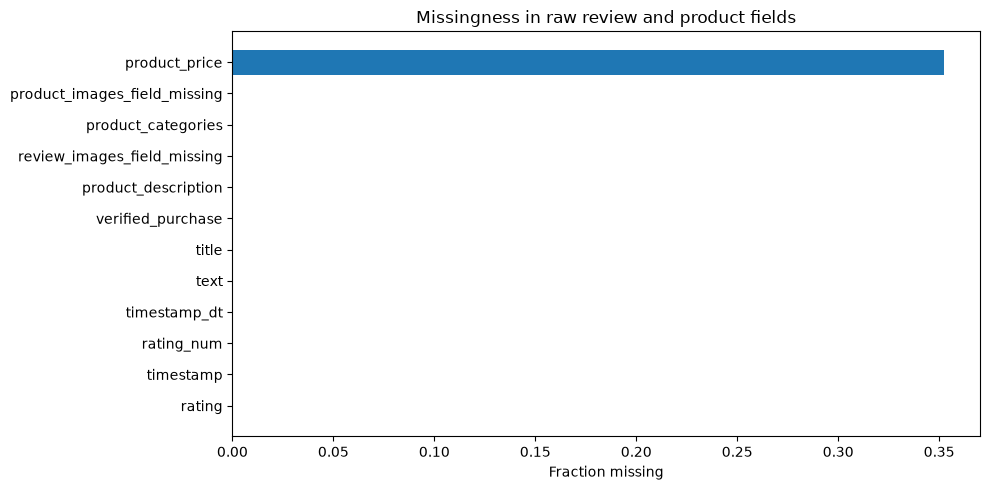

In [6]:
# Audit raw source fields before relying on cleaned empty-string representations.
raw_missingness_columns = [
    "rating", "rating_num",
    "timestamp", "timestamp_dt",
    "title", "text",
    "verified_purchase",
    "product_price", "product_description", "product_categories",
]
raw_missingness_columns = [
    c for c in raw_missingness_columns if c in analysis_train.columns
]

missingness_report = pd.DataFrame({
    "column": raw_missingness_columns,
    "missing_n": [int(analysis_train[c].isna().sum()) for c in raw_missingness_columns],
    "missing_rate": [float(analysis_train[c].isna().mean()) for c in raw_missingness_columns],
    "measurement": ["NaN/null in raw or parsed column"] * len(raw_missingness_columns),
})

# These flags distinguish an absent source field from an explicitly empty image list.
image_field_rows = []
for flag in ["review_images_field_missing", "product_images_field_missing"]:
    if flag in analysis_train.columns:
        image_field_rows.append({
            "column": flag,
            "missing_n": int(analysis_train[flag].sum()),
            "missing_rate": float(analysis_train[flag].mean()),
            "measurement": "Mean of explicit source-field-missing flag",
        })
if image_field_rows:
    missingness_report = pd.concat(
        [missingness_report, pd.DataFrame(image_field_rows)],
        ignore_index=True,
    )

missingness_report = missingness_report.sort_values(
    "missing_rate", ascending=False
)
display(missingness_report.style.format({"missing_rate": "{:.1%}"}))

plt.figure(figsize=(10, 5))
plot_missing = missingness_report.sort_values("missing_rate", ascending=True)
plt.barh(plot_missing["column"], plot_missing["missing_rate"])
plt.xlabel("Fraction missing")
plt.title("Missingness in raw review and product fields")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase2_missingness_overview.png", dpi=160, bbox_inches="tight")
plt.show()


In [7]:
# Complement null-rate checks with meaningful-empty checks (e.g. [] or blank text).
meaningful_missingness = missing_value_audit(analysis_train)
print('Both null and empty/unusable content rates:')
display(meaningful_missingness.sort_values('empty_or_unusable_percent',ascending=False))

# Price conversion diagnostic: null prices vs unparseable non-null prices.
raw_price = analysis_train.get('product_price',pd.Series(np.nan,index=analysis_train.index))
price_info = {
    'missing_raw_price': int(raw_price.isna().sum()),
    'unusable_raw_price': int((~raw_price.map(has_value)).sum()),
    'missing_or_unparseable_numeric_price': int(analysis_train['product_price_num'].isna().sum()),
    'non_null_raw_but_unparsed': int((raw_price.notna() & analysis_train['product_price_num'].isna()).sum()),
    'negative_parsed_price': int((analysis_train['product_price_num'] < 0).sum()),
}
price_audit = pd.DataFrame([price_info])
display(price_audit)

Both null and empty/unusable content rates:


,field,null_rows,null_percent,empty_or_unusable_rows,empty_or_unusable_percent,non_null_but_empty_rows
9,images,0,0.000000,54489,97.301786,54489
11,product_price_num (parsed),19747,35.262500,19747,35.262500,0
6,product_price,19745,35.258929,19745,35.258929,0
7,product_description,0,0.000000,13213,23.594643,13213
8,product_categories,0,0.000000,1798,3.210714,1798
10,product_images,0,0.000000,29,0.051786,29
4,text,0,0.000000,2,0.003571,2
0,helpful_vote,0,0.000000,0,0.000000,0
3,title,0,0.000000,0,0.000000,0
2,timestamp,0,0.000000,0,0.000000,0


,missing_raw_price,unusable_raw_price,missing_or_unparseable_numeric_price,non_null_raw_but_unparsed,negative_parsed_price
0,19745,19745,19747,2,0


### 2.2 Compare availability across the two product categories

Within the training partition, differences between categories can indicate that missingness is associated with an observed grouping variable. They do not establish that missingness is MCAR, MAR, or MNAR.


dataset_category,Musical_Instruments,Video_Games
field,,
Product description,73.6%,79.0%
Product images,99.9%,100.0%
Product metadata,100.0%,100.0%
Product price,63.2%,66.1%
Publication timestamp,100.0%,100.0%
Rating,100.0%,100.0%
Review body,100.0%,100.0%
Review images,3.1%,2.3%
Review text,100.0%,100.0%


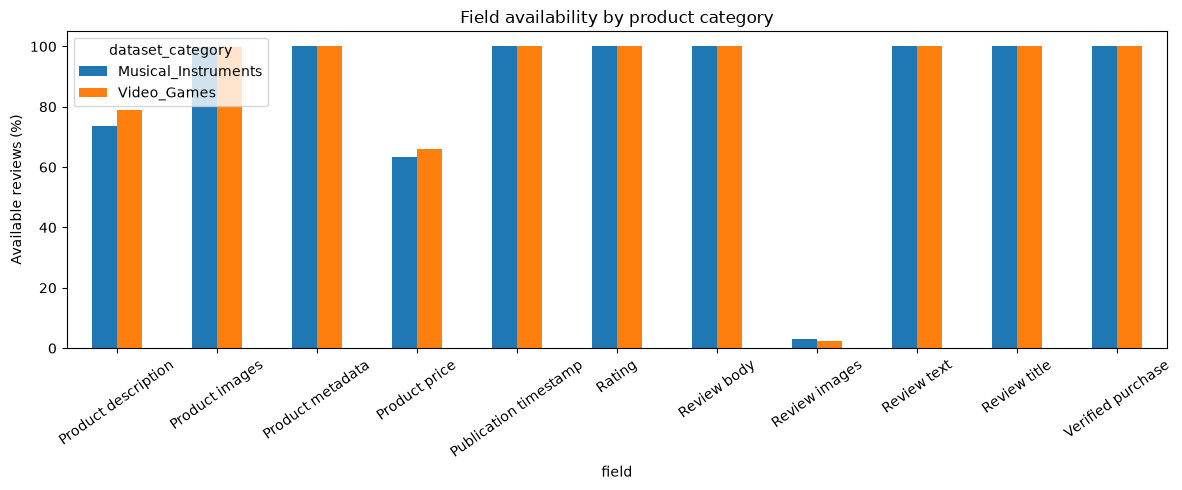

In [8]:
availability_definitions = {
    "Review text": analysis_train["text_present"],
    "Review title": analysis_train["text_title_present"],
    "Review body": analysis_train["text_body_present"],
    "Rating": analysis_train["rating_num"].notna(),
    "Product metadata": analysis_train["metadata_matched"].fillna(False),
    "Product price": analysis_train["product_price_num"].notna(),
    "Product description": analysis_train["product_description_present"].fillna(False),
    "Review images": analysis_train["review_image_present"],
    "Product images": analysis_train["product_image_present"],
    "Verified purchase": analysis_train["verified_purchase_clean"].notna(),
    "Publication timestamp": analysis_train["timestamp_dt"].notna(),
}

availability_rows = []
for category in CATEGORIES:
    subset = analysis_train["dataset_category"].eq(category)
    for field, available in availability_definitions.items():
        availability_rows.append({
            "dataset_category": category,
            "field": field,
            "available_n": int(available.loc[subset].sum()),
            "total_n": int(subset.sum()),
            "availability_rate": float(available.loc[subset].mean()) if subset.sum() else np.nan,
        })

availability_by_category = pd.DataFrame(availability_rows)
availability_pivot = availability_by_category.pivot(
    index="field", columns="dataset_category", values="availability_rate"
)
display(availability_pivot.style.format("{:.1%}"))

availability_pivot.mul(100).plot(
    kind="bar", figsize=(12, 5), rot=35
)
plt.ylabel("Available reviews (%)")
plt.title("Field availability by product category")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase2_availability_by_category.png", dpi=160, bbox_inches="tight")
plt.show()


### 2.3 Missing-value policy

The policy depends on the variable's meaning. Raw values are not globally imputed. Learned imputation is fitted **only on the training split** by `src/preprocessing.py`.

| Variable / situation | Implemented policy | Reason |
|---|---|---|
| Missing helpful-vote target | Retain as missing; exclude from target-only summaries and later supervised training | Missing is not zero. **Test targets are not inspected in Phase 2.** |
| Missing review text | Empty string for TF-IDF, plus `review_text_available` | Avoid inventing text. |
| Other numeric predictors | Train-fitted median and `SimpleImputer(add_indicator=True)` | Preserve missingness without using validation/test statistics. |
| Missing product price (**high missingness**) | Preserve `NaN`; train-fitted median for `product_price_num`/`log1p_product_price` and explicit `product_price_missing`; run no-price ablation | Price absence is not zero, and it may be time/category dependent. |
| Categorical predictors | `__MISSING__` then one-hot encoding | Absence can be informative. |
| Valid ID/time with no earlier sampled reviews | Historical count = 0 | A true observed zero among sampled earlier events. |
| Missing reviewer/product ID or timestamp | Missing prior count and imputation indicator | History is unknowable. |
| Missing image/description | Retain availability flags; avoid inventing image/description content | Distinguishes unavailable metadata from observed values. |
| Valid unusual votes or prices | Audit; do not automatically delete | Extreme values need investigation, not blind removal. |

**Price-specific caveat:** `metadata_completeness_score` contains a price-presence component, so the no-price sensitivity test must replace it with a **price-free** completeness score; dropping only the price column would leave an indirect price signal. The full approach is tested in Section 7.6.

**Metadata temporal-validity contract:** This notebook is a **retrospective fixed-snapshot** analysis, not a model that makes a decision at review-publication time. Current product price, product descriptions, listing images, aggregate product context and their missingness flags can postdate the review. Their provenance is not enough to assert point-in-time availability. Do not deploy this representation as an at-publication predictor without rebuilding the joined metadata as-of each review timestamp (or dropping snapshot-derived predictors and indirect availability/completeness proxies).

**Missingness mechanism hypotheses (not yet proven):** price and descriptions may be absent more often for older or delisted products; verified-purchase information may depend on platform policy and time. These suggest missingness may depend on observed variables. Category-level differences can be tested, but MCAR/MAR/MNAR cannot be determined conclusively from these tables alone. We preserve missingness indicators and use training-only imputation; we do **not** infer missing prices to be zero.

In [9]:
missingness_policy = pd.DataFrame([
    ["helpful_vote_num", "Target", "Never impute; held-out test values are not profiled in Phase 2."],
    ["cleaned_text", "Text", "Empty string for TF-IDF; explicit text-availability feature."],
    ["product_price_num / log1p_product_price", "Price", "Training median + missing indicator; run no-price sensitivity."],
    ["Other numeric predictors", "Numeric", "Training median + SimpleImputer missingness indicators."],
    ["Categorical predictors", "Categorical", "Explicit __MISSING__ category followed by one-hot encoding."],
    ["Prior activity counts", "Past-only", "Zero if a valid ID/time has no strictly earlier sampled events; otherwise missing."],
    ["Images / descriptions", "Metadata", "Preserve availability indicators; do not invent absent content."],
], columns=["field_group", "type", "handling"])
display(missingness_policy)

,field_group,type,handling
0,helpful_vote_num,Target,Never impute; held-out test values are not profiled in Phase 2.
1,cleaned_text,Text,Empty string for TF-IDF; explicit text-availability feature.
2,product_price_num / log1p_product_price,Price,Training median + missing indicator; run no-price sensitivity.
3,Other numeric predictors,Numeric,Training median + SimpleImputer missingness indicators.
4,Categorical predictors,Categorical,Explicit __MISSING__ category followed by one-hot encoding.
5,Prior activity counts,Past-only,Zero if a valid ID/time has no strictly earlier sampled events; otherwise missing.
6,Images / descriptions,Metadata,Preserve availability indicators; do not invent absent content.


# 3. مهندسی ویژگی — Feature engineering

This section creates additional features with explicit domain logic. The features are defined without using `helpful_vote_num`.

The activity variables are initially computed as **rolling past-only counts among the sampled reviews**: for each reviewer/product pair, reviews with the same timestamp do not count one another. They are proxies because the sample does not contain the complete marketplace history.

`review_age_days_proxy` is measured relative to the latest timestamp in the sampled data unless an explicit reference timestamp is supplied to the feature function. It is not a verified age at the dataset's extraction date because the exact snapshot date and individual helpful-vote timestamps are unavailable.


**Modeling policy:** after the chronological split (fixed in Section 1.2 and applied to features in Section 4.1), the reference model will replace held-out historical counts with **training-history-frozen** counts. We retain the rolling values for a controlled comparison in Section 7.7. Both regimes exclude `helpful_vote` and future timestamps.

In [10]:
features_df = engineer_review_features(analysis_df)

numeric_features, categorical_features = get_feature_columns()
feature_registry = get_feature_registry()

# Product metadata is a fixed joined snapshot; it is NOT guaranteed as-of the
# review timestamp. This audit documents which model features may rely on it.
SNAPSHOT_SENSITIVE_RAW_FIELDS = (
    'product_price', 'product_description', 'product_categories', 'product_images',
    'product_average_rating', 'product_rating_count', 'product_title',
)
SNAPSHOT_DERIVED_HINTS = (
    'product_price', 'product_description', 'product_category', 'product_image',
    'product_title', 'metadata_', 'product_rating', 'log1p_product_price',
)
SNAPSHOT_FEATURE_POLICY = pd.DataFrame([
    {'feature': feature,
     'snapshot_sensitive_by_name': any(feature.startswith(x) or x in feature
                                       for x in SNAPSHOT_DERIVED_HINTS),
     'as_of_review_timestamp_verified': False,
     'prediction_context': PREDICTION_CONTEXT}
    for feature in numeric_features + categorical_features
])
print('Temporal metadata contract:', PREDICTION_CONTEXT)
print('Conservative snapshot-sensitive feature-name audit (not exhaustive lineage):')
display(SNAPSHOT_FEATURE_POLICY.loc[SNAPSHOT_FEATURE_POLICY.snapshot_sensitive_by_name])
display(feature_registry)
print("Numeric predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))
print("All declared predictors:", len(numeric_features) + len(categorical_features))

# Leakage guards: target and raw identifiers must not enter the predictor list.
assert "helpful_vote_num" not in numeric_features + categorical_features
assert "helpful_vote" not in numeric_features + categorical_features
assert "user_id" not in numeric_features + categorical_features
assert "_join_key" not in numeric_features + categorical_features
assert "asin" not in numeric_features + categorical_features
assert "parent_asin" not in numeric_features + categorical_features

missing_declared_features = [
    c for c in numeric_features + categorical_features if c not in features_df.columns
]
assert not missing_declared_features, f"Missing engineered columns: {missing_declared_features}"

print("Target and raw identifier leakage checks passed.")


Temporal metadata contract: retrospective_fixed_snapshot
Conservative snapshot-sensitive feature-name audit (not exhaustive lineage):


,feature,snapshot_sensitive_by_name,as_of_review_timestamp_verified,prediction_context
1,product_price_num,True,False,retrospective_fixed_snapshot
10,product_images_count,True,False,retrospective_fixed_snapshot
22,log1p_product_price,True,False,retrospective_fixed_snapshot
27,metadata_completeness_score,True,False,retrospective_fixed_snapshot
33,product_image_available,True,False,retrospective_fixed_snapshot
34,product_description_available,True,False,retrospective_fixed_snapshot
35,product_metadata_available,True,False,retrospective_fixed_snapshot
36,product_price_missing,True,False,retrospective_fixed_snapshot


,feature_or_group,definition,why_it_may_help
0,text_char_count,Number of characters in cleaned title + body,Captures review length beyond word count.
1,text_word_count,Number of word-like tokens in cleaned title + body,A basic measure of review detail.
2,text_sentence_count,Number of sentence-like segments,Captures writing structure.
3,non_ascii_ratio,Fraction of cleaned characters with code point > 127,Captures character composition; not a language label.
4,exclamation_count,Number of exclamation marks,Captures emphatic punctuation.
5,question_count,Number of question marks,Captures interrogative style.
6,uppercase_ratio,Uppercase alphabetic characters / alphabetic characters,Captures emphasis in writing.
7,title_body_length_ratio,Cleaned title length / (cleaned body length + 1),Captures how much information is concentrated in the title.
8,review_age_days_proxy,Days before the latest timestamp observed in this sample,"A relative recency/exposure proxy, not verified time since publication at the dataset snapshot."
9,review_month_sin/cos,Cyclical encoding of publication month,Preserves the circular relationship between December and January.


Numeric predictors: 28
Categorical predictors: 9
All declared predictors: 37
Target and raw identifier leakage checks passed.


### 3.3 One reusable, deterministic data-preparation entry point

The helper below reconstructs the **raw rolling feature table** from an offline sample. **It does not by itself enforce the reference frozen-history policy.** The frozen policy is applied *after* the chronological split in Section 4.1 by `apply_frozen_training_history(...)`. For a truly reusable inference pipeline, preserve the historical training events/aggregates, the split cutoff, and fitted TF-IDF/scaler/SVD/model objects; a new batch alone cannot reconstruct either history correctly.


In [11]:
def prepare_phase2_feature_table(joined_sample: pd.DataFrame) -> pd.DataFrame:
    """Offline replay: sampled join → clean → duplicate audit → rolling target-free features.

    Prior counts are computed within this supplied historical sample only.
    After the chronological split, use apply_frozen_training_history for the reference
    held-out features. This function alone is NOT the complete frozen model.
    """
    cleaned = clean_review_dataframe(joined_sample)
    audited = audit_duplicate_signatures(cleaned)
    return engineer_review_features(audited)

# Lightweight schema check without recomputing 80k rows here.
assert set(numeric_features + categorical_features).issubset(features_df.columns)
print('Offline preparation entry point defined; existing audited features retained.')

Offline preparation entry point defined; existing audited features retained.


### 3.1 Inspect engineered features and their distributions


All displayed feature distributions and missingness rates in this subsection use **TRAIN rows only**. The complete engineered table exists for target-free row transforms, not exploratory fitting.

**Scope check:** `review_age_days_proxy` is retained only as an unused engineered descriptor. It uses the latest timestamp in the entire sampled dataset and is intentionally **excluded** from the model feature list to avoid introducing a future-reference timestamp into the training representation. `review_year` is available at review publication time, but may still act as a historical/platform-policy proxy. Product snapshot metadata may also postdate publication and is a scenario limitation.

**Enforced prediction context:** `PREDICTION_CONTEXT='retrospective_fixed_snapshot'`. This defines a valid retrospective task without silently treating current product metadata as historical. Historical-at-posting evaluation is **not** supported by these sources.

In [12]:
features_train_inspection = features_df.loc[EARLY_TRAIN_INDEX].copy()
feature_quality = pd.DataFrame({
    "feature": numeric_features + categorical_features,
    "dtype": [str(features_train_inspection[c].dtype) for c in numeric_features + categorical_features],
    "missing_rate": [float(features_train_inspection[c].isna().mean()) for c in numeric_features + categorical_features],
    "n_unique": [int(features_train_inspection[c].nunique(dropna=True)) for c in numeric_features + categorical_features],
})
display(feature_quality.sort_values("missing_rate", ascending=False))

display(
    features_train_inspection[
        [
            "dataset_category", "rating_num", "product_price_num",
            "text_word_count", "review_age_days_proxy",
            "reviewer_prior_review_count", "product_prior_review_count",
            "user_product_prior_interaction_count",
            "metadata_completeness_score",
        ]
    ].head(12)
)


,feature,dtype,missing_rate,n_unique
1,product_price_num,float64,0.352625,4247
22,log1p_product_price,float64,0.352625,4247
29,product_main_category,str,0.032107,4
0,rating_num,float64,0.000000,5
2,text_char_count,float64,0.000000,2678
4,text_sentence_count,float64,0.000000,110
3,text_word_count,float64,0.000000,890
5,non_ascii_ratio,float64,0.000000,1189
6,exclamation_count,float64,0.000000,37
9,review_images_count,int64,0.000000,14


,dataset_category,rating_num,product_price_num,text_word_count,review_age_days_proxy,reviewer_prior_review_count,product_prior_review_count,user_product_prior_interaction_count,metadata_completeness_score
0,Musical_Instruments,5.0,10.61,26.0,2525.828306,0.0,0.0,0.0,3.0
1,Musical_Instruments,5.0,NaN,11.0,2222.113771,0.0,0.0,0.0,3.0
3,Musical_Instruments,4.0,228.00,230.0,2776.521963,0.0,6.0,0.0,4.0
4,Musical_Instruments,1.0,NaN,38.0,3881.930401,0.0,0.0,0.0,3.0
5,Musical_Instruments,4.0,99.00,39.0,2854.870262,0.0,0.0,0.0,4.0
6,Musical_Instruments,5.0,27.55,6.0,2970.685227,0.0,3.0,0.0,4.0
7,Musical_Instruments,5.0,389.95,6.0,1370.855897,0.0,0.0,0.0,2.0
9,Musical_Instruments,5.0,5.99,14.0,2206.307426,0.0,7.0,0.0,3.0
10,Musical_Instruments,3.0,14.25,59.0,1776.022960,0.0,0.0,0.0,3.0
11,Musical_Instruments,2.0,NaN,32.0,3158.355771,0.0,0.0,0.0,3.0


### 3.2 Why these features are relevant

- **Text length and writing structure:** capture how much information a review contains and how it is expressed.
- **Rating and verified-purchase status:** describe the review's explicit evaluation and purchase context.
- **Product price and metadata completeness:** describe product context and metadata availability.
- **Review-age proxy and cyclical time variables:** describe publication timing. They do not measure the exact time available to collect helpful votes.
- **Prior reviewer/product activity:** describe earlier sampled activity without including raw identifiers.
- **Availability indicators:** preserve information about which data sources are present.

The feature dictionary is saved with the Phase 2 outputs. Features are defined before the chronological holdout is used to fit the learned preprocessing steps.


# 4. کاهش بعد یا ساخت بازنمایی — Representation construction and dimensionality reduction

The Amazon path calls for a text representation and structured review/product features. We use:

1. **TF-IDF** as the primary, classic text representation.
2. **Structured features** as a second information source, using numeric imputation/scaling and categorical one-hot encoding.
3. **Optional pretrained sentence embeddings** as a semantic text representation, if the optional package/model is available.
4. **TruncatedSVD** to reduce the sparse fused representation, followed by **PCA** for a two-dimensional visualization.

TF-IDF emphasizes terms and phrases that distinguish reviews in this corpus. A pretrained sentence embedding represents semantic similarity and can group paraphrases, but costs more compute and depends on a fixed pretrained model. Neither text representation is a helpful-vote label.


### 4.1 Reuse the already-frozen chronological train/validation/test partition

The date boundaries were fixed immediately after cleaning in Section 1.2, before any exploratory analyses. We now apply that unchanged split to the engineered table. The split is used to ensure that vocabulary, imputers, encoders, scaling parameters, dimensionality reduction and cluster centroids are learned from the training period only. Reviews with missing timestamps are assigned to training so they do not get placed in a future period without evidence.


Before final evaluation, **all three partitions** enter the target-blind identifier audit in the next cell, even while `RUN_FINAL_TEST_AUDIT=False`. No `helpful_vote`, text, numeric predictors, or test feature matrices are used in that audit.


**Split limitation:** equal timestamps remain in the same split. Missing timestamps are assigned to the training partition by the current protocol; we report how many there are rather than assuming it is harmless. This is a chronological split, *not* an unseen-reviewer or unseen-product split. The review-age proxy remains excluded regardless of how the split falls.

Potential cross-period resubmissions should be reviewed before supervised evaluation. Overlapping reviewer or product identifiers are expected in this chronological protocol and are reported as an **exposure/generalization caveat**, not incorrectly treated as duplicate leakage by themselves.


**Image-data boundary:** Image URLs and availability indicators are metadata, not visual features. Section 8.18 provides an optional pixel-based pretrained ResNet-18 experiment and a matched-row text + structured vs text + structured + image comparison. The image experiment is conditional on actual accessible pixels and valid pretrained weights.


In [13]:
# Reuse the train/validation/test membership fixed in Section 1.2 BEFORE EDA.
# The source feature engineering preserves the original sampled-row index/order.
assert features_df.index.equals(analysis_df.index), (
    'Feature engineering unexpectedly changed row order; split membership must not drift.')
assert features_df['sample_row_id'].equals(analysis_df['sample_row_id']), (
    'Feature engineering unexpectedly changed sampled-row identity.')
train_features = features_df.loc[EARLY_TRAIN_INDEX].copy()
validation_features = features_df.loc[EARLY_VALIDATION_INDEX].copy()
test_features = features_df.loc[EARLY_TEST_INDEX].copy()
assert set(train_features.index).isdisjoint(validation_features.index)
assert set(train_features.index).isdisjoint(test_features.index)
assert set(validation_features.index).isdisjoint(test_features.index)
display(split_info)
print('Rows with missing timestamps assigned to train:',
      int(train_features['timestamp_dt'].isna().sum()))
print('Same split as fixed before exploratory analysis: VERIFIED.')


,partition,rows,start_timestamp,end_timestamp
0,train,56000,1998-12-01 18:36:33.000+00:00,2020-07-28 16:52:39.087+00:00
1,validation,11998,2020-07-28 16:54:54.460+00:00,2021-10-22 14:18:43.808+00:00
2,test,12002,2021-10-22 15:27:52.256+00:00,2023-09-08 13:08:50.622+00:00


Rows with missing timestamps assigned to train: 0
Same split as fixed before exploratory analysis: VERIFIED.


In [14]:
# TARGET-BLIND identifier-only cross-split audit (ALWAYS includes TEST).
# The test outcome and all feature values remain sealed. The fingerprints/signatures
# were derived without helpful votes; they are used only as opaque identifiers here.
_ID_AUDIT_COLUMNS = [
    'sample_row_id', 'dataset_category', 'user_id', '_join_key',
    'review_fingerprint', 'review_signature_no_time',
]
assert all(col in features_df.columns for col in _ID_AUDIT_COLUMNS)
assert not any('helpful' in col.lower() or 'target' in col.lower()
               for col in _ID_AUDIT_COLUMNS)
partitioned = pd.concat([
    train_features[_ID_AUDIT_COLUMNS].assign(split='train'),
    validation_features[_ID_AUDIT_COLUMNS].assign(split='validation'),
    test_features[_ID_AUDIT_COLUMNS].assign(split='test'),
], ignore_index=True)
assert set(partitioned['split']) == {'train','validation','test'}
assert len(partitioned) == len(features_df)
assert 'helpful_vote_num' not in partitioned and 'helpful_vote' not in partitioned

exact_cross_split, exact_cross_rows = cross_split_duplicate_audit(
    partitioned, 'review_fingerprint')
resubmission_cross_split, resubmission_cross_rows = cross_split_duplicate_audit(
    partitioned, 'review_signature_no_time')
print('Identifier-only exact cross-split duplicate audit (TRAIN / VALIDATION / TEST):')
display(exact_cross_split)
print('Identifier-only possible resubmissions across TRAIN / VALIDATION / TEST:')
display(resubmission_cross_split)
if len(resubmission_cross_rows):
    display(resubmission_cross_rows[
        ['dataset_category','split','review_signature_no_time']
    ].head(15))
    print('WARNING: Review possible resubmissions before any final supervised test evaluation.')

# Report expected same-user/product exposure separately from exact/near-duplicate leakage.
def _id_overlap_stats(left, right, keys, label):
    if len(keys) == 1:
        a = set(left[keys[0]].dropna().astype(str)) - {''}
        b = set(right[keys[0]].dropna().astype(str)) - {''}
    else:
        a = set(map(tuple, left[list(keys)].dropna().astype(str).values.tolist()))
        b = set(map(tuple, right[list(keys)].dropna().astype(str).values.tolist()))
        a = {x for x in a if all(x)}
        b = {x for x in b if all(x)}
    return {'pair':label, 'identifier':'+'.join(keys),
            'left_distinct':len(a), 'right_distinct':len(b),
            'shared_distinct':len(a & b)}
identifier_overlap_audit = pd.DataFrame([
    _id_overlap_stats(partitioned.loc[partitioned.split.eq(a)],
                      partitioned.loc[partitioned.split.eq(c)], keys, a+' vs '+c)
    for a,c in [('train','validation'),('train','test'),('validation','test')]
    for keys in [('user_id',),('dataset_category','_join_key'),
                 ('dataset_category','user_id','_join_key')]
])
print('Same-entity overlap (expected for seen-user/seen-product chronological prediction):')
display(identifier_overlap_audit)

# Cross-split duplicate groups are identified without their target values.
# Block final TEST profiling until an explicit leakage review is complete.
_exact_n = int(exact_cross_split['cross_split_groups'].sum())
_resub_n = int(resubmission_cross_split['cross_split_groups'].sum())
IDENTIFIER_LEAKAGE_AUDIT = {
    'scope':'train/validation/test; identifiers and target-free signatures only',
    'target_columns_read':False,
    'test_identifiers_included':True,
    'cross_split_exact_duplicate_groups':_exact_n,
    'cross_split_possible_resubmission_groups':_resub_n,
    'status':'clear' if (_exact_n == 0 and _resub_n == 0) else 'manual_review_required',
}
print('Identifier leakage review:', IDENTIFIER_LEAKAGE_AUDIT)
if IDENTIFIER_LEAKAGE_AUDIT['status'] != 'clear':
    warnings.warn('Cross-split identical/near-identical review signatures require investigation '
                  'or a leakage-safe re-split before final supervised test evaluation.')
    if RUN_FINAL_TEST_AUDIT:
        raise RuntimeError('Final TEST audit blocked by unresolved cross-split review leakage.')

# Category balance on TRAIN / VALIDATION only; this is no longer a test-feature audit.
split_category_counts = pd.crosstab(
    partitioned.loc[partitioned.split.ne('test'),'split'],
    partitioned.loc[partitioned.split.ne('test'),'dataset_category'])
display(split_category_counts)

# TARGET-DEPENDENT checks happen only AFTER splitting, on TRAINING rows.
_train_targets = pd.to_numeric(train_features['helpful_vote_num'],errors='coerce')
_train_target_present = _train_targets.notna()
train_target_quality = pd.DataFrame([
    {'check':'Missing helpful-vote target (TRAIN)',
     'affected_rows':int((~_train_target_present).sum())},
    {'check':'Negative helpful-vote count (TRAIN)',
     'affected_rows':int((_train_target_present & _train_targets.lt(0)).sum())},
    {'check':'Noninteger helpful-vote count (TRAIN)',
     'affected_rows':int((_train_target_present & _train_targets.ne(_train_targets.round())).sum())},
])
print('TRAIN-ONLY helpful-vote target-quality checks:')
display(train_target_quality)
if not _train_target_present.any():
    warnings.warn('No training helpful votes available for future supervised modeling.')
conflicting_fingerprints = (train_features.loc[
    train_features['fingerprint_duplicate_flag']
].groupby('review_fingerprint')['helpful_vote_num']
 .nunique(dropna=True).gt(1).sum())
print('TRAIN-only fingerprints with conflicting target values:',int(conflicting_fingerprints))
# Remove features CONSTANT or all-missing on training only (a deterministic correction).
# Correlated, merely sparse, or possibly important features are not removed without evidence.
feature_filter_rows=[]
active_numeric=[]
active_categorical=[]
for name in numeric_features:
    values=pd.to_numeric(train_features[name],errors='coerce')
    n_unique=values.nunique(dropna=True)
    reason='keep' if n_unique>1 else 'all missing/constant in training'
    feature_filter_rows.append({'feature':name,'type':'numeric', 'train_distinct_nonmissing':int(n_unique), 'decision':reason})
    if n_unique>1:
        active_numeric.append(name)
for name in categorical_features:
    n_unique=train_features[name].fillna('__MISSING__').nunique()
    reason='keep' if n_unique>1 else 'constant in training'
    feature_filter_rows.append({'feature':name,'type':'categorical','train_distinct_nonmissing':int(n_unique),'decision':reason})
    if n_unique>1:
        active_categorical.append(name)
feature_filter_table=pd.DataFrame(feature_filter_rows)
print('Dropped constant/all-missing training features (not the whole rows):')
display(feature_filter_table.loc[feature_filter_table['decision']!='keep'])
assert active_numeric or active_categorical
assert 'review_age_days_proxy' not in active_numeric
assert 'helpful_vote_num' not in active_numeric+active_categorical

# Flag nearly redundant numeric features without silently dropping them.
numeric_corr = train_features[active_numeric].apply(pd.to_numeric,errors='coerce').corr().abs()
corr_pairs=[]
for i,a in enumerate(active_numeric):
    for b in active_numeric[i+1:]:
        r=numeric_corr.loc[a,b]
        if pd.notna(r) and r>=0.98:
            corr_pairs.append({'feature_a':a,'feature_b':b,'abs_pearson_r':float(r)})
correlated_feature_pairs=pd.DataFrame(corr_pairs,columns=['feature_a','feature_b','abs_pearson_r'])
print('Highly correlated numeric pairs (review before dropping):')
display(correlated_feature_pairs)

Identifier-only exact cross-split duplicate audit (TRAIN / VALIDATION / TEST):


,signature,cross_split_groups,cross_split_rows
0,review_fingerprint,0,0


Identifier-only possible resubmissions across TRAIN / VALIDATION / TEST:


,signature,cross_split_groups,cross_split_rows
0,review_signature_no_time,0,0


Same-entity overlap (expected for seen-user/seen-product chronological prediction):


,pair,identifier,left_distinct,right_distinct,shared_distinct
0,train vs validation,user_id,54741,11907,180
1,train vs validation,dataset_category+_join_key,26566,7726,2677
2,train vs validation,dataset_category+user_id+_join_key,55990,11998,0
3,train vs test,user_id,54741,11867,136
4,train vs test,dataset_category+_join_key,26566,8402,2005
5,train vs test,dataset_category+user_id+_join_key,55990,11998,0
6,validation vs test,user_id,11907,11867,89
7,validation vs test,dataset_category+_join_key,7726,8402,1850
8,validation vs test,dataset_category+user_id+_join_key,11998,11998,0


... (4 outputs left out)

TRAIN-only fingerprints with conflicting target values: 0
Dropped constant/all-missing training features (not the whole rows):


,feature,type,train_distinct_nonmissing,decision
31,review_text_available,categorical,1,constant in training
35,product_metadata_available,categorical,1,constant in training


Highly correlated numeric pairs (review before dropping):


,feature_a,feature_b,abs_pearson_r
0,text_char_count,text_word_count,0.998623
1,reviewer_prior_review_count,log1p_reviewer_prior_review_count,0.982636
2,user_product_prior_interaction_count,log1p_user_product_prior_interaction_count,1.000000


**Historical-feature availability policy (two regimes).** Source feature engineering first constructs **rolling, strictly earlier** reviewer/product/pair counts across the sampled timeline (never using helpful votes, same-timestamp reviews or future reviews). The **reference** model now uses **training-history-frozen** counts for validation and test: each held-out review sees only training-period activity, even when earlier validation/test reviews exist. Counts for training rows are unchanged because the split is chronological. Section **7.7** compares the frozen and rolling regimes using the **same trained TF-IDF/structured preprocessor, SVD, K-means model and k**, so any observed assignment changes come from available-history policy alone. Neither regime reveals outcomes to the model. The split keeps equal timestamps together and cross-split duplicate signatures are audited above.

**Important:** 'frozen' refers to *which review events may contribute to history*, not to holding a reviewer's count constant through time before training cutoff. Training review counts still use strictly earlier training reviews. In Phase 3, choose the regime that matches real prediction-time data availability.


In [15]:
# Validate time ordering of the modeling partitions; NaT rows, if any, are a separate caveat.
assert train_features['timestamp_dt'].dropna().max() < validation_features['timestamp_dt'].min()
assert validation_features['timestamp_dt'].max() < test_features['timestamp_dt'].min()

# Verify a few prior counts with independent strict-earlier computations (no targets).
_rng = np.random.default_rng(SEED)
_checked = np.sort(_rng.choice(len(train_features)+len(validation_features), min(25, len(train_features)+len(validation_features)), replace=False))
_audit_pool = pd.concat([train_features,validation_features])
prior_count_audit_rows = []
for _pos in _checked:
    _row = _audit_pool.iloc[_pos]
    _ts = _row['timestamp_dt']
    if pd.isna(_ts):
        continue
    for _field, _keys in [
        ('reviewer_prior_review_count', ['user_id']),
        ('product_prior_review_count', ['dataset_category', '_join_key']),
        ('user_product_prior_interaction_count', ['dataset_category', 'user_id', '_join_key']),
    ]:
        if any(pd.isna(_row.get(_k)) or str(_row.get(_k)).strip() == '' for _k in _keys):
            continue
        _mask = _audit_pool['timestamp_dt'].lt(_ts)
        for _key in _keys:
            _mask &= _audit_pool[_key].eq(_row[_key])
        _expected = int(_mask.sum())
        _observed = _audit_pool.iloc[_pos][_field]
        assert int(_observed) == _expected, (_field, _pos, _observed, _expected)
        prior_count_audit_rows.append((_pos, _field, _expected))
print('Strict-earlier history assertions passed:', len(prior_count_audit_rows), 'checks.')

Strict-earlier history assertions passed: 75 checks.


### 4.1a Build the **frozen training-history** reference (and retain rolling history)

We leave `src/features.py` unchanged: it produces the rolling, strictly earlier counts. After the chronological split we keep copies of that rolling table, then compute validation/test prior counts **only from timestamped training reviews**. Unseen reviewers/products get zero; missing identifiers or timestamps remain missing. We recompute all three derived `log1p` activity columns, so no indirect rolling history leaks into the frozen baseline. Because training timestamps strictly precede validation/test, every training event for a matching group is eligible. A runtime assertion enforces this assumption. Only model inputs change; text, metadata, outcome labels and row membership do not.

In [16]:
HISTORY_GROUPS = {
    'reviewer_prior_review_count': ['user_id'],
    'product_prior_review_count': ['dataset_category', '_join_key'],
    'user_product_prior_interaction_count': ['dataset_category', 'user_id', '_join_key'],
}
HISTORY_LOG_FEATURES = {
    'reviewer_prior_review_count': 'log1p_reviewer_prior_review_count',
    'product_prior_review_count': 'log1p_product_prior_review_count',
    'user_product_prior_interaction_count': 'log1p_user_product_prior_interaction_count',
}

def _frozen_group_count(train_history, heldout, keys, timestamp_column='timestamp_dt'):
    """Count training events per group for later held-out rows, preserving unknowns.

    Valid only when *every* timestamped training row precedes *every* held-out row;
    this is verified so the result is equivalent to strictly-earlier train-only counts.
    """
    train_time = pd.to_datetime(train_history[timestamp_column], utc=True, errors='coerce')
    held_time = pd.to_datetime(heldout[timestamp_column], utc=True, errors='coerce')
    if train_time.notna().any() and held_time.notna().any():
        if not train_time.max() < held_time.min():
            raise ValueError('Frozen count requires train timestamps strictly earlier than held-out timestamps.')
    train_valid = train_time.notna()
    held_valid = held_time.notna()
    for key in keys:
        train_valid &= train_history[key].map(has_value)
        held_valid &= heldout[key].map(has_value)
    out = pd.Series(np.nan, index=heldout.index, dtype='float64')
    if not held_valid.any():
        return out
    if train_valid.any():
        group_counts = (train_history.loc[train_valid, keys].astype(str)
                        .groupby(keys, sort=False, dropna=False).size())
        held_keys = pd.MultiIndex.from_frame(heldout.loc[held_valid, keys].astype(str))
        # Single-column groupby has a simple Index, not a MultiIndex.
        if len(keys) == 1:
            looked_up = group_counts.reindex(held_keys.get_level_values(0), fill_value=0)
        else:
            looked_up = group_counts.reindex(held_keys, fill_value=0)
        out.loc[held_valid] = looked_up.to_numpy(dtype=float)
    else:
        out.loc[held_valid] = 0.0
    return out


def apply_frozen_training_history(train_history, heldout):
    """Replace rolling historical predictors with strictly train-only counts.

    Both frames must be cleaned/engineered already; this never reads labels/votes.
    The full training history is fixed and heldout rows never update its counts.
    """
    result = heldout.copy()
    for count_feature, keys in HISTORY_GROUPS.items():
        result[count_feature] = _frozen_group_count(train_history, result, keys)
        result[HISTORY_LOG_FEATURES[count_feature]] = np.log1p(
            result[count_feature].clip(lower=0)
        )
    return result

# Original engineering uses all sampled earlier events (rolling regime).
rolling_validation_features = validation_features.copy(deep=True)
rolling_test_features = test_features.copy(deep=True) if RUN_FINAL_TEST_AUDIT else None

# REFERENCE: validation and test histories are frozen to the training partition.
validation_features = apply_frozen_training_history(train_features, rolling_validation_features)
test_features = (apply_frozen_training_history(train_features, rolling_test_features)
                 if RUN_FINAL_TEST_AUDIT else test_features)

# Never change original targets/identifiers; training rows are unchanged.
assert train_features.index.equals(features_df.loc[train_features.index].index)
for _held_original, _held_frozen in [
    (rolling_validation_features, validation_features),
    *([(rolling_test_features, test_features)] if RUN_FINAL_TEST_AUDIT else []),
]:
    assert _held_original.index.equals(_held_frozen.index)
    assert _held_original['sample_row_id'].equals(_held_frozen['sample_row_id'])
    assert _held_original['helpful_vote_num'].equals(_held_frozen['helpful_vote_num'])

print('Reference model policy: FROZEN train-only history for validation/test.')
print('Rolling (past-only) copies kept for Section 7.7; train history is identical in both regimes.')

Reference model policy: FROZEN train-only history for validation/test.
Rolling (past-only) copies kept for Section 7.7; train history is identical in both regimes.


### 4.1b Verify the frozen counts against independent train-only counts

The checks below sample held-out reviews and independently count matching **training** events with strictly earlier timestamps. They also confirm that rolling counts cannot be smaller than frozen counts (unless both are missing). This guards against subtle history misalignment or incomplete replacement of transformed count features.

In [17]:
_rng_history = np.random.default_rng(SEED + 303)
history_audit_rows = []
for _partition, _roll, _frozen in [
    ('validation', rolling_validation_features, validation_features),
    *([('test', rolling_test_features, test_features)] if RUN_FINAL_TEST_AUDIT else []),
]:
    for _feature, _keys in HISTORY_GROUPS.items():
        _r = pd.to_numeric(_roll[_feature], errors='coerce')
        _f = pd.to_numeric(_frozen[_feature], errors='coerce')
        assert (_r.isna() == _f.isna()).all(), (_partition, _feature, 'missingness differs')
        assert (_r.fillna(0) >= _f.fillna(0)).all(), (_partition, _feature, 'frozen > rolling')
        _expected_log = np.log1p(_f.clip(lower=0))
        assert np.allclose(_frozen[HISTORY_LOG_FEATURES[_feature]], _expected_log, equal_nan=True)
        _changed = _r.ne(_f) & ~(_r.isna() & _f.isna())
        history_audit_rows.append({
            'partition': _partition,
            'feature': _feature,
            'rows': len(_roll),
            'different_rows': int(_changed.sum()),
            'frozen_mean': float(_f.mean()),
            'rolling_mean': float(_r.mean()),
            'frozen_median': float(_f.median()),
            'rolling_median': float(_r.median()),
            'rolling_minus_frozen_mean': float((_r - _f).mean()),
            'fraction_changed': float(_changed.mean()),
            'fraction_missing': float(_f.isna().mean()),
        })

    _sample_ids = _rng_history.choice(len(_frozen), min(20, len(_frozen)), replace=False)
    for _i in _sample_ids:
        _row = _frozen.iloc[int(_i)]
        _ts = _row['timestamp_dt']
        for _feature, _keys in HISTORY_GROUPS.items():
            if pd.isna(_ts) or any(not has_value(_row[k]) for k in _keys):
                assert pd.isna(_row[_feature])
                continue
            _mask = train_features['timestamp_dt'].lt(_ts)
            for _key in _keys:
                _mask &= train_features[_key].eq(_row[_key])
            assert int(_mask.sum()) == int(_row[_feature]), (_partition, _feature, _i)

history_feature_comparison = pd.DataFrame(history_audit_rows)
display(history_feature_comparison.round(4))
print('Independent frozen count checks and derived log checks passed.')

,partition,feature,rows,different_rows,frozen_mean,rolling_mean,frozen_median,rolling_median,rolling_minus_frozen_mean,fraction_changed,fraction_missing
0,validation,reviewer_prior_review_count,11998,91,0.0178,0.0261,0.0,0.0,0.0083,0.0076,0.0
1,validation,product_prior_review_count,11998,4272,4.5018,5.9068,0.0,1.0,1.4051,0.3561,0.0
2,validation,user_product_prior_interaction_count,11998,0,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0


Independent frozen count checks and derived log checks passed.


### 4.2 Fit the reproducible preprocessing pipeline on training data only

The pipeline contains two branches:

- **Text branch:** cleaned review text → TF-IDF.
- **Structured branch:** numeric features → training-set median imputation + missingness indicators + scaling; categorical features → explicit missing category + one-hot encoding.

Each branch is row-normalized before the feature blocks are concatenated. The pipeline is fit only on `train_features`; validation and test rows are transformed with the fitted pipeline.


In [18]:
phase2_pipeline = build_phase2_preprocessing_pipeline(
    max_tfidf_features=MAX_TFIDF_FEATURES,
    min_df=TFIDF_MIN_DF,
    numeric_features=active_numeric,
    categorical_features=active_categorical,
)

X_fused_train_tfidf = phase2_pipeline.fit_transform(train_features)
X_fused_validation_tfidf = phase2_pipeline.transform(validation_features)
X_fused_test_tfidf = phase2_pipeline.transform(test_features) if RUN_FINAL_TEST_AUDIT else None

print("Train fused matrix:", X_fused_train_tfidf.shape, X_fused_train_tfidf.dtype)
print("Validation fused matrix:", X_fused_validation_tfidf.shape)
print('Test fused matrix:', X_fused_test_tfidf.shape if RUN_FINAL_TEST_AUDIT else 'DEFERRED')
print("Sparse representation:", sparse.issparse(X_fused_train_tfidf))

# Access the fitted text and structured branches for auditing and optional alternatives.
fitted_branches = dict(phase2_pipeline.transformer_list)
text_branch = fitted_branches["text"]
structured_branch = fitted_branches["structured"]
tfidf_vectorizer = text_branch.named_steps["tfidf"]

X_tfidf_train = tfidf_vectorizer.transform(
    train_features["cleaned_text"].fillna("").astype(str)
)
X_structured_train = structured_branch.transform(train_features)
X_structured_validation = structured_branch.transform(validation_features)
X_structured_test = structured_branch.transform(test_features) if RUN_FINAL_TEST_AUDIT else None

print("TF-IDF vocabulary size:", len(tfidf_vectorizer.get_feature_names_out()))
print("Structured representation:", X_structured_train.shape)
print("Active structured features:", len(active_numeric), "numeric and", len(active_categorical), "categorical")


Train fused matrix: (56000, 15047) float64
Validation fused matrix: (11998, 15047)
Test fused matrix: DEFERRED
Sparse representation: True
TF-IDF vocabulary size: 15000
Structured representation: (56000, 47)
Active structured features: 28 numeric and 7 categorical


In [19]:
# Verify the ACTUAL median fitted for product_price_num (never the held-out median).
column_transformer = structured_branch.named_steps['preprocess'].named_steps['columns']
num_pipe = column_transformer.named_transformers_.get('numeric')
if 'product_price_num' in active_numeric and num_pipe is not None:
    imputer = num_pipe.named_steps['imputer']
    i = active_numeric.index('product_price_num')
    fitted_price_median = float(imputer.statistics_[i])
    price_imputation_check = pd.DataFrame([{
        'feature':'product_price_num',
        'fitted_training_median':fitted_price_median,
        'raw_training_median':float(train_features['product_price_num'].median()),
        'train_missing_rows':int(train_features['product_price_num'].isna().sum()),
        'validation_missing_rows':int(validation_features['product_price_num'].isna().sum()),
        'test_missing_rows':int(test_features['product_price_num'].isna().sum()) if RUN_FINAL_TEST_AUDIT else np.nan,
        'explicit_price_missing_indicator_in_features': 'product_price_missing' in active_categorical,
    }])
    display(price_imputation_check)
    assert np.isclose(fitted_price_median,train_features['product_price_num'].median())
else:
    price_imputation_check = pd.DataFrame()
    print('No varying training price field; check the feature-filter report.')

,feature,fitted_training_median,raw_training_median,train_missing_rows,validation_missing_rows,test_missing_rows,explicit_price_missing_indicator_in_features
0,product_price_num,29.99,29.99,19747,2823,NaN,True


### 4.2a Product-price missingness varies over time



Price missingness across training and validation (test deferred):


,partition,rows,price_missing_n,price_missing_rate,median_observed_price
0,train,56000,19747,35.3%,29.990000
1,validation,11998,2823,23.5%,29.990000


Price missingness by category/year (groups with ≥50 rows):


,dataset_category,review_year,n_reviews,missing_rate
18,Musical_Instruments,2018.0,3506,0.319738
19,Musical_Instruments,2019.0,4763,0.304640
20,Musical_Instruments,2020.0,5171,0.254303
21,Musical_Instruments,2021.0,4431,0.215301
25,Video_Games,2001.0,87,0.218391
26,Video_Games,2002.0,126,0.119048
27,Video_Games,2003.0,133,0.172932
28,Video_Games,2004.0,139,0.208633
29,Video_Games,2005.0,148,0.297297
30,Video_Games,2006.0,130,0.284615


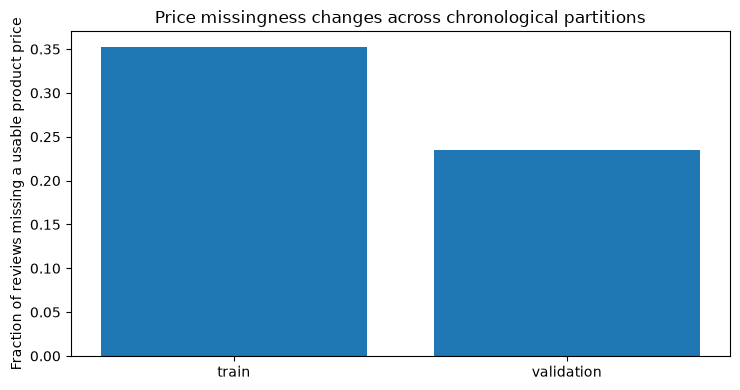

In [20]:
price_missing_by_split = pd.DataFrame([
    {
        'partition': name,
        'rows': len(frame),
        'price_missing_n': int(frame['product_price_num'].isna().sum()),
        'price_missing_rate': float(frame['product_price_num'].isna().mean()),
        'median_observed_price': float(frame['product_price_num'].median()),
    }
    for name, frame in [
        ('train', train_features), ('validation', validation_features)
    ]
])
price_missing_by_category_year = (
    pd.concat([train_features,validation_features]).assign(price_missing=lambda d: d['product_price_num'].isna())
    .groupby(['dataset_category', 'review_year'], dropna=False)['price_missing']
    .agg(n_reviews='size', missing_rate='mean')
    .reset_index()
)
print('Price missingness across training and validation (test deferred):')
display(price_missing_by_split.style.format({'price_missing_rate': '{:.1%}'}))
print('Price missingness by category/year (groups with ≥50 rows):')
display(price_missing_by_category_year.loc[
    price_missing_by_category_year['n_reviews'].ge(50)
].tail(25))

plt.figure(figsize=(7.5, 4))
plt.bar(price_missing_by_split['partition'], price_missing_by_split['price_missing_rate'])
plt.ylabel('Fraction of reviews missing a usable product price')
plt.title('Price missingness changes across chronological partitions')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'phase2_price_missingness_by_split.png', dpi=160, bbox_inches='tight')
plt.show()

### 4.2b Complete reusable reference transformation (with a private training-history sidecar)

The fitted TF-IDF/structured pipeline by itself cannot reconstruct frozen reviewer/product history. The reference workflow below combines: (1) deterministic cleaning and feature engineering of a **new joined batch**, (2) a fixed reference of **training-only event keys and timestamps**, and (3) the **training-fitted** text/structured preprocessing pipeline. The result is a reusable `transform_phase2_reference()` entry point. It never fits on incoming validation/test data or reads helpful votes. Incoming reviews must occur **strictly after** the known training period for frozen-history prediction; otherwise the transform rejects them.

The saved local bundle contains reviewer and product identifiers needed to count prior events. Treat it as **PRIVATE**: do not commit or publish this file. It is distinct from the public candidate-model artifacts. This helper preserves the three reference frozen-history groups; other historical features computed during initial engineering follow their documented sampled-history rules. An at-publication model would require additional availability checks and data provenance.

In [21]:
# A complete notebook-level reference workflow for new joined samples.
# The model bundle contains a PRIVATE train-only event-key history sidecar;
# NEVER include it in public reports or repositories.
PHASE2_TRAIN_HISTORY_KEYS = ['timestamp_dt', 'user_id', 'dataset_category', '_join_key']

def build_phase2_reference_bundle(train_frame, fitted_preprocessor, numeric_columns, categorical_columns):
    missing = [c for c in PHASE2_TRAIN_HISTORY_KEYS if c not in train_frame]
    if missing:
        raise ValueError('Missing required training-history fields: ' + str(missing))
    events = train_frame.loc[:, PHASE2_TRAIN_HISTORY_KEYS].copy(deep=True)
    assert not any('helpful' in c.lower() for c in events.columns)
    return {
        'version': 1,
        'prediction_context': PREDICTION_CONTEXT,
        'train_history_events_PRIVATE': events,
        'preprocessing_pipeline': fitted_preprocessor,
        'numeric_features': list(numeric_columns),
        'categorical_features': list(categorical_columns),
        'history_rule': 'training-history-frozen, strictly earlier than incoming',
        'input_contract': 'raw joined sample or already engineered feature frame',
        'private_identifiers_present': True,
    }

def transform_phase2_reference(bundle, input_frame, *, input_stage='joined_sample', return_features=False):
    """Apply cleaning/engineering + frozen TRAIN history + fitted preprocessing, no refitting."""
    if bundle.get('prediction_context') != 'retrospective_fixed_snapshot':
        raise ValueError('This workflow cannot make at-publication predictions from snapshot metadata.')
    if input_stage == 'joined_sample':
        rows = prepare_phase2_feature_table(input_frame)
    elif input_stage == 'engineered_features':
        rows = input_frame.copy(deep=True)
    else:
        raise ValueError('input_stage must be joined_sample or engineered_features')
    missing_keys = [c for c in PHASE2_TRAIN_HISTORY_KEYS if c not in rows]
    if missing_keys:
        raise ValueError('Incomplete input history key columns: ' + str(missing_keys))
    history = bundle['train_history_events_PRIVATE']
    # apply_frozen_training_history verifies strict train-before-heldout timestamps.
    rows = apply_frozen_training_history(history, rows)
    required = ['cleaned_text'] + bundle['numeric_features'] + bundle['categorical_features']
    missing_features = [c for c in required if c not in rows]
    if missing_features:
        raise ValueError('Missing model feature columns after engineering: ' + str(missing_features))
    X = bundle['preprocessing_pipeline'].transform(rows)
    return (X, rows) if return_features else X

PHASE2_REFERENCE_BUNDLE = build_phase2_reference_bundle(
    train_features, phase2_pipeline, active_numeric, active_categorical)
# Smoke-test on the exact same held-out rows, from the PRE-FROZEN feature copy.
_n_reference_smoke = min(12, len(rolling_validation_features))
_X_reference_smoke, _reference_smoke_rows = transform_phase2_reference(
    PHASE2_REFERENCE_BUNDLE,
    rolling_validation_features.iloc[:_n_reference_smoke],
    input_stage='engineered_features', return_features=True,
)
_expected_smoke = X_fused_validation_tfidf[:_n_reference_smoke]
assert _X_reference_smoke.shape == _expected_smoke.shape
assert np.allclose(_X_reference_smoke.toarray(), _expected_smoke.toarray(), atol=1e-7)
for _frozen_field in HISTORY_GROUPS:
    assert np.allclose(
        pd.to_numeric(_reference_smoke_rows[_frozen_field], errors='coerce').to_numpy(),
        pd.to_numeric(validation_features.iloc[:_n_reference_smoke][_frozen_field], errors='coerce').to_numpy(),
        equal_nan=True)
print('Complete reference workflow verified on validation (no refitting and no test access).')

Complete reference workflow verified on validation (no refitting and no test access).


### 4.3 Optional pretrained sentence embeddings

This cell is optional and disabled by default to keep the notebook reproducible without downloading model weights. If enabled, it extracts frozen embeddings from `sentence-transformers/all-MiniLM-L6-v2`; it does not train a large language model.

The main A/B/C and downstream reference pipeline **always uses TF-IDF**; enabling this option creates and saves separate frozen sentence vectors without replacing the primary representation. If the dependency or weights are unavailable, the notebook still runs its TF-IDF pipeline.


In [22]:
sentence_embedding_metadata = None
X_fused_train_sentence = None
X_fused_validation_sentence = None
X_fused_test_sentence = None

if USE_PRETRAINED_SENTENCE_EMBEDDINGS:
    try:
        sentence_train, sentence_embedding_metadata = extract_sentence_embeddings(
            train_features["cleaned_text"].fillna("").astype(str),
            model_name=SENTENCE_TRANSFORMER_MODEL,
        )
        sentence_validation, _ = extract_sentence_embeddings(
            validation_features["cleaned_text"].fillna("").astype(str),
            model_name=SENTENCE_TRANSFORMER_MODEL,
        )
        sentence_test = None
        if RUN_FINAL_TEST_AUDIT:
            sentence_test, _ = extract_sentence_embeddings(
                test_features['cleaned_text'].fillna('').astype(str),
                model_name=SENTENCE_TRANSFORMER_MODEL,
            )

        X_fused_train_sentence = combine_modalities(
            sentence_train, X_structured_train
        )
        X_fused_validation_sentence = combine_modalities(
            sentence_validation, X_structured_validation
        )
        X_fused_test_sentence = (combine_modalities(sentence_test, X_structured_test)
                                 if RUN_FINAL_TEST_AUDIT else None)
        print("Pretrained sentence embeddings extracted:", sentence_embedding_metadata)
    except Exception as exc:
        warnings.warn(
            f"Pretrained sentence embeddings were not created; TF-IDF remains active. "
            f"Reason: {type(exc).__name__}: {exc}"
        )

# Keep the required TF-IDF baseline active in the main A/B/C and downstream
# comparisons, regardless of whether the optional sentence encoder succeeds.
# Optional frozen vectors remain in X_fused_*_sentence and are saved separately
# by the next section; they never silently replace the baseline representation.
X_fused_train = X_fused_train_tfidf
X_fused_validation = X_fused_validation_tfidf
X_fused_test = X_fused_test_tfidf
ACTIVE_TEXT_REPRESENTATION = "tfidf"
OPTIONAL_SENTENCE_EMBEDDINGS_AVAILABLE = X_fused_train_sentence is not None
print("Active main-pipeline text representation:", ACTIVE_TEXT_REPRESENTATION)
print("Optional pretrained sentence vectors available:", OPTIONAL_SENTENCE_EMBEDDINGS_AVAILABLE)


Active main-pipeline text representation: tfidf
Optional pretrained sentence vectors available: False


### 4.3a Amazon requirement: classical TF-IDF vs pretrained text embeddings

**Both approaches represent the same review text, but serve different purposes.**

| Text representation | What it captures best | Limitations / use in this notebook |
|---|---|---|
| **TF-IDF** (required classical baseline) | Exact words, recurring phrases, transparent term weights | Weak at paraphrases/synonyms; fitted only on training reviews; actually used in reference A, body-only B/C and limited-text D. |
| **Pretrained sentence embeddings** (optional) | Semantic similarity when different words express similar meaning | Less transparent, extra weights/dependencies/computation; enabled only by `USE_PRETRAINED_SENTENCE_EMBEDDINGS=True`; it does not establish helpfulness or authenticity. |

The model is **not pretrained or fine-tuned here**: if enabled, it is frozen. Its output arrays and model metadata are saved for reproducibility. Model E deliberately uses **structured behavior only**, rather than claiming to include text embeddings.

In [23]:
# Audit the two text-representation choices. The default requires NO network or model download.
AMAZON_TEXT_REPRESENTATIONS = pd.DataFrame([
    {'representation':'TF-IDF (word 1–2 grams)', 'executed':True,
     'fit_or_source':'Vocabulary and IDF fitted on TRAIN only',
     'dimensions':int(X_tfidf_train.shape[1]),
     'purpose':'Auditable lexical baseline; discover phrase-based review groups',
     'limitation':'Rare synonyms and paraphrases need not be close'},
    {'representation':'Pretrained sentence embedding',
     'executed':bool(X_fused_train_sentence is not None),
     'fit_or_source':SENTENCE_TRANSFORMER_MODEL + ' (frozen, optional)',
     'dimensions':int(sentence_train.shape[1]) if X_fused_train_sentence is not None else np.nan,
     'purpose':'Capture semantic similarity beyond exact keyword overlap',
     'limitation':'Optional; no model is trained and no semantic result is claimed when disabled'},
])
display(AMAZON_TEXT_REPRESENTATIONS)
AMAZON_TEXT_REPRESENTATIONS.to_csv(OUTPUT_DIR/'phase2_amazon_text_representations.csv',index=False)

if X_fused_train_sentence is not None:
    # These are the actual frozen text vectors, NOT the fused text+metadata matrix.
    _saved_embeddings = [('train',sentence_train),('validation',sentence_validation)]
    if RUN_FINAL_TEST_AUDIT:
        _saved_embeddings.append(('test',sentence_test))
    for split, vectors in _saved_embeddings:
        np.save(OUTPUT_DIR/f'phase2_pretrained_sentence_embeddings_{split}.npy',
                np.asarray(vectors,dtype=np.float32))
    embedding_record = dict(sentence_embedding_metadata or {})
    embedding_record.update({'model_name':SENTENCE_TRANSFORMER_MODEL,
        'frozen':True,'training_or_finetuning_here':False,
        'review_text_column':'cleaned_text','row_order':'chronological train/validation/test features',
        'vectors_saved':True,'split_sizes':{'train':len(train_features),
            'validation':len(validation_features),
            'test':len(test_features) if RUN_FINAL_TEST_AUDIT else None},
        'test_audit_executed':RUN_FINAL_TEST_AUDIT})
    (OUTPUT_DIR/'phase2_pretrained_sentence_embeddings_metadata.json').write_text(
        json.dumps(embedding_record,indent=2,default=str),encoding='utf-8')
    print('Saved optional pretrained text vectors and metadata.')
else:
    print('Optional sentence embeddings were NOT extracted; TF-IDF is the executed text representation.')

,representation,executed,fit_or_source,dimensions,purpose,limitation
0,TF-IDF (word 1–2 grams),True,Vocabulary and IDF fitted on TRAIN only,15000.0,Auditable lexical baseline; discover phrase-based review groups,Rare synonyms and paraphrases need not be close
1,Pretrained sentence embedding,False,"sentence-transformers/all-MiniLM-L6-v2 (frozen, optional)",NaN,Capture semantic similarity beyond exact keyword overlap,Optional; no model is trained and no semantic result is claimed when disabled


Optional sentence embeddings were NOT extracted; TF-IDF is the executed text representation.


### 4.4 Reduce dimensionality with TruncatedSVD

The fused matrix is sparse and contains TF-IDF plus structured features. TruncatedSVD is appropriate for this sparse representation. It is fit on training rows only and then applied to validation/test rows.


**Interpretation:** low cumulative explained variance in sparse TF-IDF is not by itself proof of failure. It means the number of retained components needs sensitivity testing. We explicitly test alternative dimensions later in Section 7 before calling the clustering robust.

In [24]:
svd_reducer, X_reduced_train, X_reduced_validation, X_reduced_test = fit_svd_reduction(
    X_fused_train,
    X_validation=X_fused_validation,
    X_test=X_fused_test if RUN_FINAL_TEST_AUDIT else None,
    n_components=N_REDUCED_COMPONENTS,
    random_state=SEED,
)

print("Reduced train representation:", X_reduced_train.shape)
print("Explained variance ratio sum:", float(svd_reducer.explained_variance_ratio_.sum()))


Reduced train representation: (56000, 30)
Explained variance ratio sum: 0.11239686683211066


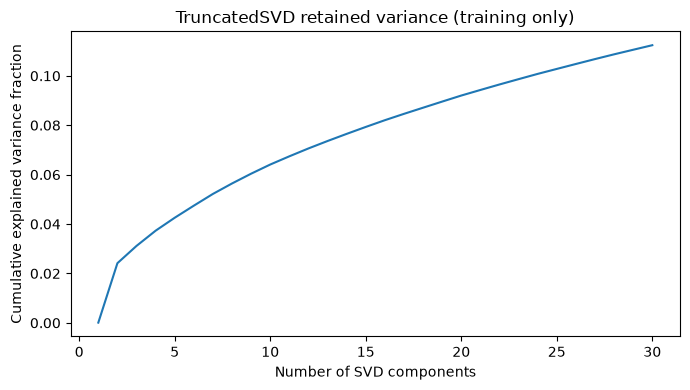

In [25]:
variance_by_component = pd.DataFrame({
    'components':np.arange(1,len(svd_reducer.explained_variance_ratio_)+1),
    'cumulative_explained_variance':np.cumsum(svd_reducer.explained_variance_ratio_),
})
plt.figure(figsize=(7,4))
plt.plot(variance_by_component['components'],variance_by_component['cumulative_explained_variance'])
plt.xlabel('Number of SVD components')
plt.ylabel('Cumulative explained variance fraction')
plt.title('TruncatedSVD retained variance (training only)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'phase2_svd_cumulative_variance.png',dpi=150)
plt.show()

### 4.5 PCA visualization

PCA is applied to the lower-dimensional SVD representation. It is used here for visualization, not to choose clusters by visual appearance alone.


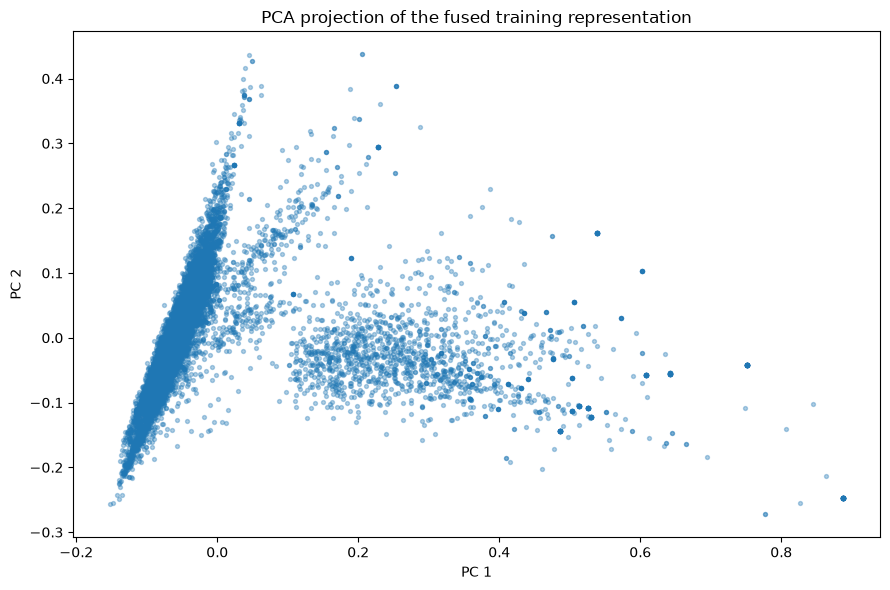

PCA explained variance ratio: [0.21415738 0.06252427]


In [26]:
pca_projection, X_pca_train, X_pca_validation, X_pca_test = fit_pca_projection(
    X_reduced_train,
    X_validation=X_reduced_validation,
    X_test=X_reduced_test if RUN_FINAL_TEST_AUDIT else None,
    random_state=SEED,
)

plot_n = min(12_000, len(X_pca_train))
plot_indices = np.random.default_rng(SEED).choice(
    len(X_pca_train), size=plot_n, replace=False
)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_pca_train[plot_indices, 0],
    X_pca_train[plot_indices, 1],
    s=8, alpha=0.35
)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("PCA projection of the fused training representation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase2_pca_fused_representation.png", dpi=160, bbox_inches="tight")
plt.show()

print("PCA explained variance ratio:", pca_projection.explained_variance_ratio_)


### 4.6 Optional UMAP visualization

UMAP is optional. PCA above already satisfies the dimensionality-reduction/visualization requirement. UMAP can be enabled if `umap-learn` is installed and additional nonlinear visualization is useful.


In [27]:
umap_projection = None
X_umap_train = None

if USE_UMAP:
    try:
        # Use a reproducible subset for a more manageable exploratory visualization.
        umap_n = min(15_000, len(X_reduced_train))
        umap_indices = np.random.default_rng(SEED).choice(
            len(X_reduced_train), size=umap_n, replace=False
        )
        umap_projection, X_umap_train, _, _ = fit_umap_projection(
            X_reduced_train[umap_indices],
            random_state=SEED,
        )
        plt.figure(figsize=(9, 6))
        plt.scatter(X_umap_train[:, 0], X_umap_train[:, 1], s=8, alpha=0.35)
        plt.title("UMAP projection of a training subset")
        plt.xlabel("UMAP 1")
        plt.ylabel("UMAP 2")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "phase2_umap_fused_representation.png", dpi=160, bbox_inches="tight")
        plt.show()
    except Exception as exc:
        warnings.warn(f"UMAP was skipped: {type(exc).__name__}: {exc}")
else:
    print("UMAP disabled. PCA and TruncatedSVD are used for dimensionality reduction.")


UMAP disabled. PCA and TruncatedSVD are used for dimensionality reduction.


# 5. کشف الگو یا خوشه‌بندی — Unsupervised pattern discovery

The unit of analysis is one review. K-means is used as the primary unsupervised method on the reduced fused representation. The helpful-vote target is not included in this representation.


### 5.1 Inspect the representation used for clustering


In [28]:
print("Clustering input shape:", X_reduced_train.shape)
print("Training rows:", len(train_features))
print("Number of reduced dimensions:", X_reduced_train.shape[1])

assert X_reduced_train.shape[0] == len(train_features)
assert "helpful_vote_num" not in numeric_features + categorical_features
print("The target is excluded from the clustering input.")


Clustering input shape: (56000, 30)
Training rows: 56000
Number of reduced dimensions: 30
The target is excluded from the clustering input.


### 5.2 Evaluate candidate K-means solutions

We inspect inertia, silhouette, and the smallest/largest cluster shares. The candidate search uses a reproducible subset when the training sample is large.


**Parameter interpretation:** the combined-rank score for choosing `k` is a transparent heuristic, not evidence that the dataset has a true intrinsic number of groups. Neither candidate selection nor stability scoring may consult `helpful_vote`.

In [29]:
selection_n = min(CLUSTER_SEARCH_MAX_ROWS, len(X_reduced_train))
selection_indices = np.sort(
    np.random.default_rng(SEED).choice(
        len(X_reduced_train), size=selection_n, replace=False
    )
)
X_selection = X_reduced_train[selection_indices]

candidate_table = evaluate_kmeans_candidates(
    X_selection,
    k_values=CLUSTER_K_VALUES,
    random_state=SEED,
    n_init=10,
    max_fit_rows=CLUSTER_SEARCH_MAX_ROWS,
    silhouette_sample_size=SILHOUETTE_SAMPLE_SIZE,
)
display(candidate_table)


,k,inertia,silhouette,smallest_cluster_n,smallest_cluster_fraction,largest_cluster_fraction,fit_rows
0,2,1389.328874,0.417351,1912,0.127467,0.872533,15000
1,3,1314.169193,0.410615,311,0.020733,0.854600,15000
2,4,1267.452068,0.340175,311,0.020733,0.841533,15000
3,5,1216.278234,0.066819,269,0.017933,0.482800,15000
4,6,1163.298169,0.080332,182,0.012133,0.454867,15000
5,7,1130.473474,0.077365,124,0.008267,0.428200,15000
6,8,1095.099091,0.065611,125,0.008333,0.456600,15000


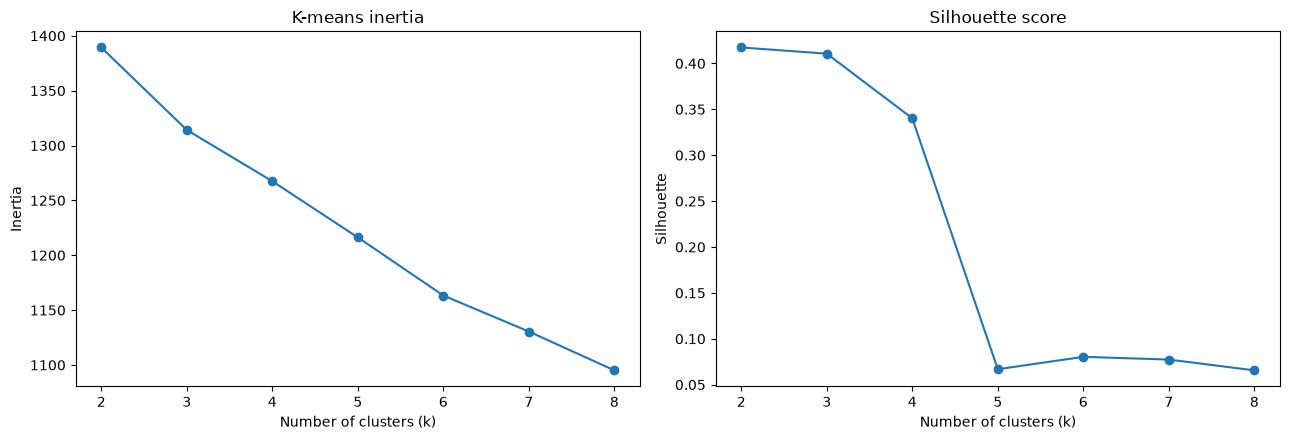

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(candidate_table["k"], candidate_table["inertia"], marker="o")
axes[0].set(
    title="K-means inertia",
    xlabel="Number of clusters (k)",
    ylabel="Inertia",
)

axes[1].plot(candidate_table["k"], candidate_table["silhouette"], marker="o")
axes[1].set(
    title="Silhouette score",
    xlabel="Number of clusters (k)",
    ylabel="Silhouette",
)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase2_kmeans_candidate_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()


# 6. انتخاب پارامتر بدون‌ناظر — Unsupervised parameter selection

The number of clusters is selected without looking at helpful-vote outcomes. We combine:

- silhouette score (separation/cohesion),
- seed stability (whether repeated fits recover similar partitions),
- smallest-cluster fraction (to flag solutions dominated by tiny clusters).

This is a diagnostic aid, not a universal mathematical optimum. We inspect the table and cluster sizes before treating the selected value as final.


In [31]:
seed_stability_rows = []
for k in candidate_table["k"].astype(int):
    result = evaluate_seed_stability(
        X_selection,
        k=k,
        seeds=(42, 52, 62),
        n_init=10,
    )
    seed_stability_rows.append({
        "k": result["k"],
        "seed_stability_ari": result["mean_pairwise_ari"],
        "minimum_seed_ari": result["min_pairwise_ari"],
    })

seed_stability_table = pd.DataFrame(seed_stability_rows)
candidate_table = candidate_table.merge(seed_stability_table, on="k", how="left")

# Percentile ranks make the three criteria comparable without using the target.
candidate_table["silhouette_rank_score"] = candidate_table["silhouette"].rank(
    pct=True, ascending=True
)
candidate_table["stability_rank_score"] = candidate_table["seed_stability_ari"].rank(
    pct=True, ascending=True
)
candidate_table["cluster_balance_rank_score"] = candidate_table["smallest_cluster_fraction"].rank(
    pct=True, ascending=True
)
candidate_table["selection_score"] = (
    0.50 * candidate_table["silhouette_rank_score"]
    + 0.35 * candidate_table["stability_rank_score"]
    + 0.15 * candidate_table["cluster_balance_rank_score"]
)
candidate_table = candidate_table.sort_values("k").reset_index(drop=True)
display(candidate_table)


,k,inertia,silhouette,smallest_cluster_n,smallest_cluster_fraction,largest_cluster_fraction,fit_rows,seed_stability_ari,minimum_seed_ari,silhouette_rank_score,stability_rank_score,cluster_balance_rank_score,selection_score
0,2,1389.328874,0.417351,1912,0.127467,0.872533,15000,0.997685,0.996528,1.000000,1.000000,1.000000,1.000000
1,3,1314.169193,0.410615,311,0.020733,0.854600,15000,0.529030,0.293831,0.857143,0.142857,0.785714,0.596429
2,4,1267.452068,0.340175,311,0.020733,0.841533,15000,0.541704,0.321831,0.714286,0.285714,0.785714,0.575000
3,5,1216.278234,0.066819,269,0.017933,0.482800,15000,0.698827,0.583948,0.285714,0.714286,0.571429,0.478571
4,6,1163.298169,0.080332,182,0.012133,0.454867,15000,0.901248,0.869192,0.571429,0.857143,0.428571,0.650000
5,7,1130.473474,0.077365,124,0.008267,0.428200,15000,0.636059,0.616926,0.428571,0.428571,0.142857,0.385714
6,8,1095.099091,0.065611,125,0.008333,0.456600,15000,0.645263,0.546850,0.142857,0.571429,0.285714,0.314286


### 6.1 Choose the working value of k

The default is the candidate with the highest combined diagnostic rank. If qualitative inspection suggests another defensible value, set `SELECTED_K_OVERRIDE` to that integer and rerun this cell and the later clustering cells. Do not select `k` based on which value produces the most attractive helpful-vote difference.


In [32]:
if SELECTED_K_OVERRIDE is None:
    selected_k = int(
        candidate_table.sort_values("selection_score", ascending=False).iloc[0]["k"]
    )
    selection_reason = (
        "Highest combined rank across silhouette, seed stability, and smallest-cluster share."
    )
else:
    selected_k = int(SELECTED_K_OVERRIDE)
    if selected_k not in candidate_table["k"].tolist():
        raise ValueError("SELECTED_K_OVERRIDE must be one of the evaluated k values.")
    selection_reason = "Manually overridden after inspecting unsupervised diagnostics."

print("Selected working k:", selected_k)
print("Selection rationale:", selection_reason)


Selected working k: 2
Selection rationale: Highest combined rank across silhouette, seed stability, and smallest-cluster share.


# 7. پایداری الگوها — Pattern stability

We test whether the discovered structure is sensitive to:
1. random initialization seeds,
2. the fraction of training rows used to fit K-means,
3. a change in global scaling of the reduced components.

Adjusted Rand Index (ARI) is used to compare partitions. ARI near 1 indicates very similar partitions; values near 0 indicate agreement comparable to chance.


### 7.1 Fit the final K-means model on all training representations


In [33]:
final_kmeans = KMeans(
    n_clusters=selected_k,
    random_state=SEED,
    n_init=20,
)
train_cluster_labels = final_kmeans.fit_predict(X_reduced_train)

validation_cluster_labels = final_kmeans.predict(X_reduced_validation)
test_cluster_labels = final_kmeans.predict(X_reduced_test) if RUN_FINAL_TEST_AUDIT else None

print("Training cluster sizes:")
display(
    pd.Series(train_cluster_labels, name="cluster")
    .value_counts()
    .sort_index()
    .rename("n_reviews")
    .to_frame()
)


Training cluster sizes:


,n_reviews
cluster,
0,49065
1,6935


### 7.2 Seed stability


In [34]:
selected_seed_stability = evaluate_seed_stability(
    X_selection,
    k=selected_k,
    seeds=(42, 52, 62, 72, 82),
    n_init=10,
)
display(pd.DataFrame([{
    "k": selected_seed_stability["k"],
    "mean_pairwise_ari": selected_seed_stability["mean_pairwise_ari"],
    "minimum_pairwise_ari": selected_seed_stability["min_pairwise_ari"],
    "pairwise_ari_values": selected_seed_stability["pairwise_ari_values"],
}]))


,k,mean_pairwise_ari,minimum_pairwise_ari,pairwise_ari_values
0,2,0.998148,0.996528,"[1.0, 0.996528, 1.0, 0.997686, 0.996528, 1.0, 0.997686, 0.996528, 0.998841, 0.997686]"


### 7.3 Subsample stability


,training_fraction,seed,training_rows,reference_rows,ari_vs_full_training_solution
0,0.6,42,33600,5000,0.998864
1,0.6,52,33600,5000,0.993177
2,0.6,62,33600,5000,0.997726
3,0.8,42,44800,5000,1.000000
4,0.8,52,44800,5000,0.997730
5,0.8,62,44800,5000,1.000000


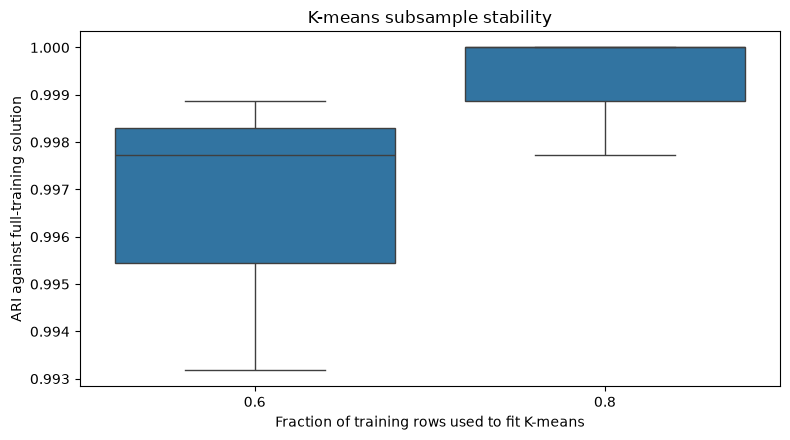

In [35]:
subsample_stability = evaluate_subsample_stability(
    X_reduced_train,
    k=selected_k,
    baseline_model=final_kmeans,
    fractions=(0.60, 0.80),
    seeds=(42, 52, 62),
    reference_size=5_000,
    n_init=10,
)
display(subsample_stability)

plt.figure(figsize=(8, 4.5))
sns.boxplot(
    data=subsample_stability,
    x="training_fraction",
    y="ari_vs_full_training_solution",
)
plt.xlabel("Fraction of training rows used to fit K-means")
plt.ylabel("ARI against full-training solution")
plt.title("K-means subsample stability")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase2_subsample_stability.png", dpi=160, bbox_inches="tight")
plt.show()


### 7.4 Sensitivity to global scaling


**Interpretation:** This perturbation standardizes the **already reduced SVD axes**. It tests sensitivity to the geometry supplied to K-means; it is *not* the same as changing the raw numerical-feature scaler. High seed/subsample stability does not cancel out poor scaling stability. Section 7.6 separately checks row-L2 normalization (common after latent semantic analysis), alternative text/structured weights, and other preprocessing ablations. The original reference fit is retained so every experiment is auditable; no improvement is assumed without observing rerun results.

In [36]:
scaling_sensitivity = evaluate_scaling_sensitivity(
    X_reduced_train,
    k=selected_k,
    baseline_model=final_kmeans,
    random_state=SEED,
    n_init=10,
)
display(pd.DataFrame([scaling_sensitivity]))

stability_summary = pd.DataFrame([
    {
        "test": "Different random seeds",
        "metric": "Mean pairwise ARI",
        "value": selected_seed_stability["mean_pairwise_ari"],
        "interpretation": "Similarity of partitions across K-means initializations.",
    },
    {
        "test": "Subsample stability",
        "metric": "Mean ARI vs full-training solution",
        "value": float(subsample_stability["ari_vs_full_training_solution"].mean()),
        "interpretation": "Similarity after fitting on 60%/80% subsamples.",
    },
    {
        "test": "Global scaling sensitivity",
        "metric": "ARI vs baseline",
        "value": scaling_sensitivity["ari_vs_baseline"],
        "interpretation": "Similarity after standardizing the reduced components.",
    },
])
display(stability_summary)


,comparison,ari_vs_baseline,scaled_inertia
0,standard scaling of reduced components vs baseline representation,0.061161,1.610410e+06


,test,metric,value,interpretation
0,Different random seeds,Mean pairwise ARI,0.998148,Similarity of partitions across K-means initializations.
1,Subsample stability,Mean ARI vs full-training solution,0.997916,Similarity after fitting on 60%/80% subsamples.
2,Global scaling sensitivity,ARI vs baseline,0.061161,Similarity after standardizing the reduced components.


### 7.5 Additional diagnostics: SVD dimensions and text-versus-structured representations

These experiments use the *same fixed sampled training rows* so their comparisons are meaningful. No validation/test targets are inspected, and the cluster count remains the selected working value. The tests are intentionally small enough for a normal VS Code environment, but still take extra compute. If the notebook runs too slowly, set `DIAGNOSTIC_SAMPLE_SIZE=2000` or `RUN_EXTENDED_DIAGNOSTICS=False` in Section 0.

In [37]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

svd_dimension_diagnostics=pd.DataFrame()
modality_diagnostics=pd.DataFrame()

if RUN_EXTENDED_DIAGNOSTICS:
    n_diag=min(DIAGNOSTIC_SAMPLE_SIZE,len(train_features))
    diag_indices=np.sort(np.random.default_rng(SEED).choice(len(train_features),n_diag,replace=False))
    X_diag_full=X_fused_train[diag_indices]
    ref_labels=None
    dimension_labels={}
    rows=[]
    for dim in DIAGNOSTIC_SVD_COMPONENTS:
        n_comp=min(int(dim), X_diag_full.shape[0]-2, X_diag_full.shape[1]-2)
        if n_comp < 2:
            continue
        reducer=TruncatedSVD(n_components=n_comp,random_state=SEED,n_iter=5)
        Xd=reducer.fit_transform(X_diag_full)
        model=KMeans(n_clusters=selected_k,random_state=SEED,n_init=10)
        labels=model.fit_predict(Xd)
        dimension_labels[n_comp]=labels
        sil=silhouette_score(Xd,labels,sample_size=min(DIAGNOSTIC_SILHOUETTE_SAMPLE,n_diag),random_state=SEED)
        rows.append({'svd_dimensions':n_comp,'retained_variance':float(reducer.explained_variance_ratio_.sum()),
                     'silhouette':float(sil),'smallest_cluster_share':float(np.bincount(labels).min()/len(labels))})
        if n_comp==30:
            ref_labels=labels
    svd_dimension_diagnostics=pd.DataFrame(rows)
    if dimension_labels:
        reference_dimension=30 if 30 in dimension_labels else sorted(dimension_labels)[0]
        svd_dimension_diagnostics['ari_vs_reference_dimension']=svd_dimension_diagnostics[
            'svd_dimensions'].map(lambda d:float(adjusted_rand_score(
                dimension_labels[reference_dimension],dimension_labels[d])))
        print('Reference SVD dimension for ARI:', reference_dimension)
    display(svd_dimension_diagnostics)

    # On the SAME rows, fit one reduced representation per modality.
    # Text branch is TF-IDF, structured branch is already train-fitted and normalized.
    modes={
        'text_only':X_tfidf_train[diag_indices],
        'structured_only':X_structured_train[diag_indices],
        'fused':X_diag_full,
    }
    compare_rows=[]
    selected_labels={}
    for name,Xm in modes.items():
        Xm=normalize(Xm,axis=1,copy=True)
        dim=min(30,Xm.shape[0]-2,Xm.shape[1]-2)
        if dim<2:
            continue
        reducer=TruncatedSVD(n_components=dim,random_state=SEED,n_iter=5)
        Xd=reducer.fit_transform(Xm)
        labels=KMeans(n_clusters=selected_k,n_init=10,random_state=SEED).fit_predict(Xd)
        selected_labels[name]=labels
        compare_rows.append({'representation':name,
                             'svd_dimensions':dim,
                             'silhouette':float(silhouette_score(Xd,labels,sample_size=min(DIAGNOSTIC_SILHOUETTE_SAMPLE,len(labels)),random_state=SEED)),
                             'smallest_cluster_share':float(np.bincount(labels).min()/len(labels)),
                             'ari_vs_fused':np.nan})
    if 'fused' in selected_labels:
        for r in compare_rows:
            r['ari_vs_fused']=float(adjusted_rand_score(selected_labels[r['representation']],selected_labels['fused']))
    modality_diagnostics=pd.DataFrame(compare_rows)
    display(modality_diagnostics)
    print('These are TRAIN-SUBSET diagnostics; do not replace the full-sample results automatically.')
else:
    print('Extended representation sensitivity tests disabled by config.')

Reference SVD dimension for ARI: 30


,svd_dimensions,retained_variance,silhouette,smallest_cluster_share,ari_vs_reference_dimension
0,15,0.084707,0.452242,0.135,1.0
1,30,0.122241,0.366919,0.135,1.0
2,60,0.173558,0.296653,0.135,1.0


,representation,svd_dimensions,silhouette,smallest_cluster_share,ari_vs_fused
0,text_only,30,0.364689,0.13500,1.000000
1,structured_only,30,0.141217,0.34825,-0.005135
2,fused,30,0.366391,0.13500,1.000000


These are TRAIN-SUBSET diagnostics; do not replace the full-sample results automatically.


### 7.6 Controlled train-only sensitivity: formulaic titles, price, modality weights and SVD geometry

**Why:** The original run suggested a historically concentrated `Five Stars` cluster, a large change under SVD-axis standardization, and identical text-only/fused labels on a diagnostic sample. These are legitimate findings, but they do not prove robust, generalizable groups.

**Experimental control:** All alternatives use the **same fixed training rows, fixed `k`, fixed TF-IDF vocabulary/structured transform** (except the necessary price-free structured transform), and identical random seeds. TF-IDF and imputation are fitted only on these training rows. A fixed **validation predictor-only** subset assesses temporal cluster-share drift; **test rows and helpful-vote targets are not used to rank or select alternatives**. These experiments diagnose sensitivity; they do not automatically replace the reference fit.

- `without_five_stars_phrase`: removes that phrase **from the TF-IDF input only**; other engineered predictors remain fixed.
- `body_only_text`: uses only review bodies for the TF-IDF branch, keeping structured predictors fixed.
- `without_price_signals`: removes both price predictors and price-missing flag, and replaces price-dependent metadata completeness with a price-free score.
- Different modality weights, row normalization after SVD, and SVD-axis standardization test geometry assumptions independently.

These are not fake-review labels or causal interventions. If any variant is substantially better, rerun **the complete train-only k-selection and stability checks** for that variant before treating it as a replacement reference model.

In [38]:
# Diagnostic ablations; use fixed training rows throughout. Does not alter the reference model.
robustness_variant_table = pd.DataFrame()
robustness_comparison_notes = pd.DataFrame()

if RUN_EXTENDED_DIAGNOSTICS and ACTIVE_TEXT_REPRESENTATION == 'tfidf':
    _diag_train = train_features.iloc[diag_indices].copy()
    _v_count = min(DIAGNOSTIC_VALIDATION_SIZE, len(validation_features))
    _v_indices = np.sort(np.random.default_rng(SEED + 101).choice(
        len(validation_features), size=_v_count, replace=False
    ))
    _diag_val = validation_features.iloc[_v_indices].copy()

    # Fit one shared diagnostic feature encoder on TRAIN rows; other variants
    # reuse this vocabulary and its training medians/one-hot categories.
    _diag_pipe = build_phase2_preprocessing_pipeline(
        max_tfidf_features=MAX_TFIDF_FEATURES,
        min_df=TFIDF_MIN_DF,
        numeric_features=active_numeric,
        categorical_features=active_categorical,
    )
    _diag_pipe.fit(_diag_train)
    _branches = dict(_diag_pipe.transformer_list)
    _text_encoder = _branches['text']
    _structured_encoder = _branches['structured']
    _text_train = sparse.csr_matrix(_text_encoder.transform(_diag_train))
    _text_val = sparse.csr_matrix(_text_encoder.transform(_diag_val))
    _structured_train = sparse.csr_matrix(_structured_encoder.transform(_diag_train))
    _structured_val = sparse.csr_matrix(_structured_encoder.transform(_diag_val))

    # The phrase/body alternatives change only what the already-fitted TF-IDF branch sees.
    def _text_variant(frame, how):
        variant = frame.copy()
        if how == 'without_five_stars_phrase':
            variant['cleaned_text'] = (
                variant['cleaned_text'].fillna('').astype(str)
                .str.replace(r'\bfive\s+stars\b', ' ', case=False, regex=True)
                .str.replace(r'\s+', ' ', regex=True).str.strip()
            )
        elif how == 'body_only_text':
            variant['cleaned_text'] = variant['cleaned_body'].fillna('').astype(str)
        return sparse.csr_matrix(_text_encoder.transform(variant))

    def _price_free_frame(frame):
        new_frame = frame.copy()
        # The original completeness score counts the presence of price.
        new_frame['metadata_completeness_no_price'] = (
            new_frame['product_description_available'].eq('yes').astype(float)
            + new_frame['product_image_available'].eq('yes').astype(float)
            + new_frame['product_main_category'].notna().astype(float)
        )
        return new_frame

    _price_free_numeric = [f for f in active_numeric if f not in {
        'product_price_num', 'log1p_product_price', 'metadata_completeness_score'
    }]
    if 'metadata_completeness_score' in active_numeric:
        _price_free_numeric.append('metadata_completeness_no_price')
    _price_free_categorical = [f for f in active_categorical if f != 'product_price_missing']
    _price_encoder = build_structured_preprocessor(
        numeric_features=_price_free_numeric,
        categorical_features=_price_free_categorical,
    )
    _no_price_train = _price_free_frame(_diag_train)
    _no_price_val = _price_free_frame(_diag_val)
    _price_encoder.fit(_no_price_train)
    _structured_no_price_train = sparse.csr_matrix(_price_encoder.transform(_no_price_train))
    _structured_no_price_val = sparse.csr_matrix(_price_encoder.transform(_no_price_val))

    # Input cases: (name, train-text, val-text, train-structured, val-structured,
    #               text weight, structured weight, scaling AFTER SVD).
    _cases = [
        ('baseline_equal_weights', _text_train, _text_val, _structured_train, _structured_val, 1., 1., 'raw'),
        ('text_weight_2', _text_train, _text_val, _structured_train, _structured_val, 2., 1., 'raw'),
        ('structured_weight_2', _text_train, _text_val, _structured_train, _structured_val, 1., 2., 'raw'),
        ('structured_weight_4', _text_train, _text_val, _structured_train, _structured_val, 1., 4., 'raw'),
        ('without_five_stars_phrase',
         _text_variant(_diag_train, 'without_five_stars_phrase'),
         _text_variant(_diag_val, 'without_five_stars_phrase'),
         _structured_train, _structured_val, 1., 1., 'raw'),
        ('body_only_text', _text_variant(_diag_train, 'body_only_text'),
         _text_variant(_diag_val, 'body_only_text'), _structured_train, _structured_val, 1., 1., 'raw'),
        ('without_price_signals', _text_train, _text_val,
         _structured_no_price_train, _structured_no_price_val, 1., 1., 'raw'),
        ('svd_row_l2_normalized', _text_train, _text_val,
         _structured_train, _structured_val, 1., 1., 'row_l2'),
        ('svd_axes_standardized', _text_train, _text_val,
         _structured_train, _structured_val, 1., 1., 'zscore'),
    ]

    _diagnostic_rows = []
    _diagnostic_labels = {}
    _diagnostic_train_label_share = {}
    for _name, _xt, _xv, _xs, _xsv, _tw, _sw, _geometry in _cases:
        _Xtr = sparse.hstack((_xt.multiply(_tw), _xs.multiply(_sw)), format='csr')
        _Xv = sparse.hstack((_xv.multiply(_tw), _xsv.multiply(_sw)), format='csr')
        _n_comp = min(N_REDUCED_COMPONENTS, _Xtr.shape[0]-1, _Xtr.shape[1]-1)
        if _n_comp < 2:
            continue
        _reducer = TruncatedSVD(n_components=_n_comp, random_state=SEED, n_iter=5)
        _Ztr = _reducer.fit_transform(_Xtr)
        _Zv = _reducer.transform(_Xv)
        if _geometry == 'row_l2':
            _Ztr = normalize(_Ztr, axis=1)
            _Zv = normalize(_Zv, axis=1)
        elif _geometry == 'zscore':
            _axis_scaler = StandardScaler().fit(_Ztr)
            _Ztr = _axis_scaler.transform(_Ztr)
            _Zv = _axis_scaler.transform(_Zv)

        _clusterer = KMeans(n_clusters=selected_k, n_init=10, random_state=SEED)
        _lbl_train = _clusterer.fit_predict(_Ztr)
        _lbl_val = _clusterer.predict(_Zv)
        _diagnostic_labels[_name] = _lbl_train
        _t_share = np.bincount(_lbl_train, minlength=selected_k) / len(_lbl_train)
        _v_share = np.bincount(_lbl_val, minlength=selected_k) / len(_lbl_val)
        _diagnostic_train_label_share[_name] = _t_share
        _phrase = _diag_train['cleaned_title'].fillna('').str.contains(
            r'\bfive\s+stars\b', case=False, regex=True
        ).to_numpy()
        _phrase_rates = [float(_phrase[_lbl_train == c].mean())
                         for c in range(selected_k) if np.any(_lbl_train == c)]
        _diagnostic_rows.append({
            'variant': _name,
            'train_rows': len(_diag_train),
            'validation_rows_predictor_only': len(_diag_val),
            'n_dimensions': _n_comp,
            'silhouette_train': float(silhouette_score(
                _Ztr, _lbl_train,
                sample_size=min(DIAGNOSTIC_SILHOUETTE_SAMPLE, len(_lbl_train)),
                random_state=SEED,
            )),
            'min_train_cluster_share': float(_t_share.min()),
            'min_validation_cluster_share': float(_v_share.min()),
            'train_validation_cluster_share_TV': float(0.5 * np.abs(_t_share - _v_share).sum()),
            'highest_cluster_five_stars_title_rate': max(_phrase_rates) if _phrase_rates else np.nan,
            'ari_vs_diagnostic_baseline': np.nan,
        })
    if 'baseline_equal_weights' in _diagnostic_labels:
        _reference_labels = _diagnostic_labels['baseline_equal_weights']
        for _row in _diagnostic_rows:
            _row['ari_vs_diagnostic_baseline'] = float(adjusted_rand_score(
                _reference_labels, _diagnostic_labels[_row['variant']]
            ))
    robustness_variant_table = pd.DataFrame(_diagnostic_rows)
    display(robustness_variant_table.round(4))

    robustness_comparison_notes = pd.DataFrame([
        {'comparison': 'Phrase-only ablation', 'interpretation': 'How much the TF-IDF phrase Five Stars affects the partition.'},
        {'comparison': 'Body-only TF-IDF', 'interpretation': 'Does the clustering rely on templated titles rather than review bodies?'},
        {'comparison': 'No price signals', 'interpretation': 'Does high price missingness (including its completeness proxy) drive the partition?'},
        {'comparison': 'Alternative weights', 'interpretation': 'Does the structured modality meaningfully influence clusters?'},
        {'comparison': 'SVD normalizations', 'interpretation': 'Sensitivity to document length and SVD component units.'},
        {'comparison': 'Validation share TV distance', 'interpretation': '0 means identical cluster proportions; large values mean temporal prevalence shift, not necessarily worse clustering.'},
    ])
    display(robustness_comparison_notes)
    print('IMPORTANT: These are diagnostics, not a new selected model. Do not choose a variant using test data or helpful votes.')
else:
    print('Extra robustness ablations skipped: enable RUN_EXTENDED_DIAGNOSTICS with TF-IDF as the active representation.')

,variant,train_rows,validation_rows_predictor_only,n_dimensions,silhouette_train,min_train_cluster_share,min_validation_cluster_share,train_validation_cluster_share_TV,highest_cluster_five_stars_title_rate,ari_vs_diagnostic_baseline
0,baseline_equal_weights,4000,1500,30,0.3692,0.1342,0.0000,0.1342,0.9721,1.0000
1,text_weight_2,4000,1500,30,0.3692,0.1342,0.0000,0.1342,0.9721,1.0000
2,structured_weight_2,4000,1500,30,0.3691,0.1342,0.0000,0.1342,0.9721,1.0000
3,structured_weight_4,4000,1500,30,0.3689,0.1342,0.0000,0.1342,0.9721,1.0000
4,without_five_stars_phrase,4000,1500,30,0.1177,0.4672,0.4573,0.0099,0.2729,0.0884
5,body_only_text,4000,1500,30,0.5290,0.0198,0.0160,0.0038,0.4304,0.0775
6,without_price_signals,4000,1500,30,0.3692,0.1342,0.0000,0.1342,0.9721,1.0000
7,svd_row_l2_normalized,4000,1500,30,0.3388,0.1435,0.0007,0.1428,0.9373,0.9496
8,svd_axes_standardized,4000,1500,30,0.0484,0.4678,0.3527,0.1151,0.2646,0.0644


,comparison,interpretation
0,Phrase-only ablation,How much the TF-IDF phrase Five Stars affects the partition.
1,Body-only TF-IDF,Does the clustering rely on templated titles rather than review bodies?
2,No price signals,Does high price missingness (including its completeness proxy) drive the partition?
3,Alternative weights,Does the structured modality meaningfully influence clusters?
4,SVD normalizations,Sensitivity to document length and SVD component units.
5,Validation share TV distance,"0 means identical cluster proportions; large values mean temporal prevalence shift, not necessarily worse clustering."


IMPORTANT: These are diagnostics, not a new selected model. Do not choose a variant using test data or helpful votes.


### 7.7 Historical-availability sensitivity: frozen (reference) vs rolling past-only

**Controlled evaluation, no refitting:** Fit TF-IDF, numeric imputation/scaling, SVD, k and K-means **once on the same training reviews**. Training features are identical under both regimes. Compare validation/test cluster assignments after changing **only** the 3 historical counts and their 3 `log1p` transforms. Results are purely target-free: ARI measures agreement between policies, changed-row share shows how often the assignment changes, and the cluster-share TV distance compares overall cluster proportions. A high ARI does not prove either deployment regime is correct; the correct choice depends on what earlier reviews are truly observable at prediction time.

The reference remains *training-history-frozen*; rolling is an alternative scenario and **never used to choose k, TF-IDF vocabulary, or the reference model**.

Same frozen-trained model; alternative rolling histories only:


,partition,n_reviews,ari_frozen_vs_rolling,n_changed_assignments,fraction_changed_assignments,cluster_share_TV,min_cluster_share_frozen,min_cluster_share_rolling
0,validation,11998,1.0,0,0.0,0.0,0.00017,0.00017


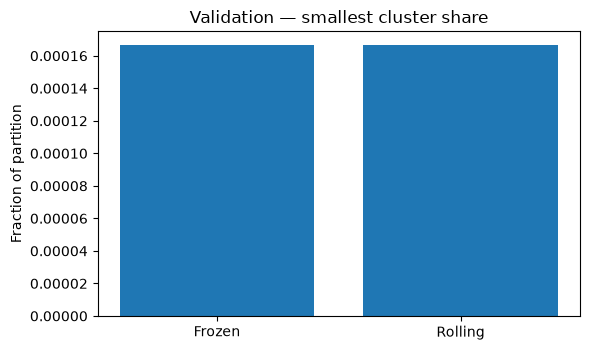

Note: this comparison isolates validation/test feature availability; it does not retrain or select the model from the held-out periods.


In [39]:
def _predict_with_fitted_reference_model(frame):
    """Use exactly the SAME train-fitted representation and clusterer as reference."""
    if ACTIVE_TEXT_REPRESENTATION == 'tfidf':
        matrix = phase2_pipeline.transform(frame)
    else:
        # Optional mode: reuse already computed text embeddings (identical text).
        if frame is rolling_validation_features:
            text_vectors = sentence_validation
        elif frame is rolling_test_features:
            text_vectors = sentence_test
        else:
            raise ValueError('Unexpected rolling frame in optional sentence-embedding mode.')
        structured_vectors = structured_branch.transform(frame)
        matrix = combine_modalities(text_vectors, structured_vectors)
    return final_kmeans.predict(svd_reducer.transform(matrix))

history_cluster_rows = []
history_label_rows = []
for _partition, _frozen_labels, _rolling_frame in [
    ('validation', np.asarray(validation_cluster_labels), rolling_validation_features),
    *([('test', np.asarray(test_cluster_labels), rolling_test_features)] if RUN_FINAL_TEST_AUDIT else []),
]:
    _rolling_labels = np.asarray(_predict_with_fitted_reference_model(_rolling_frame))
    _f_share = np.bincount(_frozen_labels, minlength=selected_k) / len(_frozen_labels)
    _r_share = np.bincount(_rolling_labels, minlength=selected_k) / len(_rolling_labels)
    _different = _frozen_labels != _rolling_labels
    history_cluster_rows.append({
        'partition': _partition,
        'n_reviews': len(_frozen_labels),
        'ari_frozen_vs_rolling': float(adjusted_rand_score(_frozen_labels, _rolling_labels)),
        'n_changed_assignments': int(_different.sum()),
        'fraction_changed_assignments': float(_different.mean()),
        'cluster_share_TV': float(0.5 * np.abs(_f_share - _r_share).sum()),
        'min_cluster_share_frozen': float(_f_share.min()),
        'min_cluster_share_rolling': float(_r_share.min()),
    })
    # IDs, dates and assignments only — never helpful votes.
    _labels = _rolling_frame[['sample_row_id', 'dataset_category', 'timestamp_dt']].copy()
    _labels['partition'] = _partition
    _labels['cluster_frozen'] = _frozen_labels
    _labels['cluster_rolling'] = _rolling_labels
    _labels['assignments_differ'] = _different
    history_label_rows.append(_labels)

history_cluster_comparison = pd.DataFrame(history_cluster_rows)
history_policy_assignments = pd.concat(history_label_rows, ignore_index=True)
assert not any('helpful_vote' in col for col in history_policy_assignments.columns)
print('Same frozen-trained model; alternative rolling histories only:')
display(history_cluster_comparison.round(5))

_history_partitions = ['validation'] + (['test'] if RUN_FINAL_TEST_AUDIT else [])
fig, axes = plt.subplots(1, len(_history_partitions), figsize=(6*len(_history_partitions), 3.6))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, _history_partitions):
    row = history_cluster_comparison.set_index('partition').loc[name]
    ax.bar(['Frozen', 'Rolling'], [row['min_cluster_share_frozen'], row['min_cluster_share_rolling']])
    ax.set_title(f'{name.capitalize()} — smallest cluster share')
    ax.set_ylabel('Fraction of partition')
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'phase2_history_policy_small_cluster_share.png', dpi=150)
plt.show()

print('Note: this comparison isolates validation/test feature availability; it does not retrain or select the model from the held-out periods.')

# 8. تفسیر الگو — Cluster interpretation

We interpret clusters using the features that formed them: text terms, rating, review length, product context, time, metadata availability and past-only sampled activity. We then compare the recorded helpful-vote distributions **after** clustering. These comparisons are descriptive associations, not causal effects.

The same fitted centroids are used to assign validation and test reviews. This allows us to check whether the training-period patterns can be applied to later reviews.


**Interpretation policy:** all reference cluster profiles below use **frozen** historical predictors for validation/test. The rolling comparison in 7.7 is not used to choose clusters.

### 8.1 Build cluster profiles


In [40]:
interpretation_numeric_columns = [
    'rating_num', 'product_price_num', 'text_word_count', 'text_char_count',
    'text_sentence_count', 'review_age_days_proxy', 'reviewer_prior_review_count',
    'product_prior_review_count', 'user_product_prior_interaction_count',
    'metadata_completeness_score',
]

# The train/validation targets may be described only AFTER unsupervised choices.
train_cluster_profile = summarize_clusters(
    train_features, train_cluster_labels,
    numeric_columns=interpretation_numeric_columns,
    target_column='helpful_vote_num',
)
validation_cluster_profile = summarize_clusters(
    validation_features, validation_cluster_labels,
    numeric_columns=interpretation_numeric_columns,
    target_column='helpful_vote_num',
)

# Do not inspect the TEST helpful_vote column anywhere in Phase 2 profiles.
test_cluster_profile = (summarize_clusters(
    test_features.drop(columns=['helpful_vote', 'helpful_vote_num'], errors='ignore'),
    test_cluster_labels,
    numeric_columns=interpretation_numeric_columns,
    target_column='__HELD_OUT_FOR_PHASE3__',
) if RUN_FINAL_TEST_AUDIT else pd.DataFrame())
assert not any('helpful_vote' in c for c in test_cluster_profile.columns)

print('Training cluster feature + post-hoc outcome profiles:')
display(train_cluster_profile)
print('Validation cluster feature + post-hoc outcome profiles:')
display(validation_cluster_profile)
if RUN_FINAL_TEST_AUDIT:
    print('Test cluster feature profiles only (target withheld):')
    display(test_cluster_profile)
else:
    print('Test cluster profiling deferred until final frozen-model audit.')

Training cluster feature + post-hoc outcome profiles:


,cluster,n_reviews,cluster_share,median_rating_num,median_product_price_num,median_text_word_count,median_text_char_count,median_text_sentence_count,median_review_age_days_proxy,median_reviewer_prior_review_count,median_product_prior_review_count,median_user_product_prior_interaction_count,median_metadata_completeness_score,target_valid_n,helpful_vote_mean_posthoc,helpful_vote_median_posthoc,helpful_vote_p90_posthoc,helpful_vote_nonzero_rate_posthoc,mean_log1p_helpful_vote_posthoc
0,0,49065,0.876161,5.0,29.990,33.0,175.0,3.0,2410.367010,0.0,1.0,0.0,3.0,49065,1.583389,0.0,3.0,0.316865,0.398837
1,1,6935,0.123839,5.0,28.975,6.0,33.0,1.0,2643.496685,0.0,1.0,0.0,4.0,6935,0.171305,0.0,1.0,0.104398,0.089525


Validation cluster feature + post-hoc outcome profiles:


,cluster,n_reviews,cluster_share,median_rating_num,median_product_price_num,median_text_word_count,median_text_char_count,median_text_sentence_count,median_review_age_days_proxy,median_reviewer_prior_review_count,median_product_prior_review_count,median_user_product_prior_interaction_count,median_metadata_completeness_score,target_valid_n,helpful_vote_mean_posthoc,helpful_vote_median_posthoc,helpful_vote_p90_posthoc,helpful_vote_nonzero_rate_posthoc,mean_log1p_helpful_vote_posthoc
0,0,11996,0.999833,5.0,29.99,27.0,141.0,3.0,921.737107,0.0,0.0,0.0,3.0,11996,0.66864,0.0,1.0,0.195065,0.215786
1,1,2,0.000167,5.0,11.99,4.5,25.0,1.0,1004.915498,0.0,0.5,0.0,3.0,2,0.00000,0.0,0.0,0.000000,0.000000


Test cluster profiling deferred until final frozen-model audit.


### 8.1a Temporal stability and possible distribution shift

A training cluster that almost disappears in later partitions is a meaningful result, not proof of robust patterns. The next cell measures cluster shares, review lengths, period/category composition, and the frequency of formulaic titles such as “Five Stars.” These are **hypothesis checks**, not predetermined explanations.

,partition,cluster,count,share
0,train,0,49065,0.876161
1,train,1,6935,0.123839
2,validation,0,11996,0.999833
3,validation,1,2,0.000167


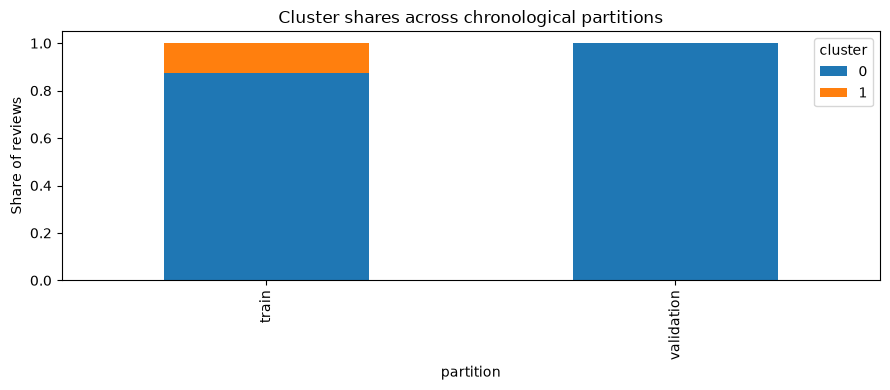

,partition,cluster,n,five_stars_title_rate,median_review_words,median_review_year
0,train,0,49065,0.011943,33.0,2017.0
1,train,1,6935,0.980678,6.0,2016.0
2,validation,0,11996,0.000167,27.0,2021.0
3,validation,1,2,0.000000,4.5,2020.5


Phrase frequency independent of cluster:


,partition,n_reviews,five_stars_title_rate,median_text_word_count,median_year
0,train,56000,0.131911,28.0,2016.0
1,validation,11998,0.000167,27.0,2021.0


,review_year,n,rate
4,2002.0,127,0.000000
5,2003.0,134,0.000000
6,2004.0,145,0.000000
7,2005.0,161,0.000000
8,2006.0,147,0.000000
9,2007.0,282,0.000000
10,2008.0,384,0.000000
11,2009.0,514,0.001946
12,2010.0,787,0.001271
13,2011.0,1270,0.001575


In [41]:
cluster_share_by_split=cluster_size_and_drift([
    ('train',train_features,train_cluster_labels),
    ('validation',validation_features,validation_cluster_labels),
    *([('test',test_features,test_cluster_labels)] if RUN_FINAL_TEST_AUDIT else []),
])
display(cluster_share_by_split)
share_pivot=cluster_share_by_split.pivot(index='partition',columns='cluster',values='share').fillna(0)
share_pivot=share_pivot.reindex(['train','validation']+(['test'] if RUN_FINAL_TEST_AUDIT else []))
share_pivot.plot(kind='bar',stacked=True,figsize=(9,4))
plt.title('Cluster shares across chronological partitions')
plt.ylabel('Share of reviews')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'phase2_cluster_temporal_share.png',dpi=150)
plt.show()

phrase_rows=[]
for name,frame,labels in [('train',train_features,train_cluster_labels),
                          ('validation',validation_features,validation_cluster_labels),
                          *([('test',test_features,test_cluster_labels)] if RUN_FINAL_TEST_AUDIT else [])]:
    mask=frame['cleaned_title'].fillna('').str.contains(r'\bfive\s+stars\b',case=False,regex=True)
    for c in sorted(np.unique(labels)):
        selected=np.asarray(labels)==c
        group=frame.iloc[np.flatnonzero(selected)]
        phrase_rows.append({'partition':name,'cluster':int(c),'n':int(selected.sum()),
                            'five_stars_title_rate':float(mask.iloc[np.flatnonzero(selected)].mean()),
                            'median_review_words':float(group['text_word_count'].median()),
                            'median_review_year':float(group['review_year'].median())})
phrase_and_length_drift=pd.DataFrame(phrase_rows)
display(phrase_and_length_drift)

# Compare temporal pattern of the phrase, irrespective of cluster assignments.
title_phrase_by_period=[]
for name,frame in [('train',train_features),('validation',validation_features)]+([('test',test_features)] if RUN_FINAL_TEST_AUDIT else []):
    phrase=frame['cleaned_title'].fillna('').str.contains(r'\bfive\s+stars\b',case=False,regex=True)
    title_phrase_by_period.append({'partition':name, 'n_reviews':len(frame),
                                   'five_stars_title_rate':float(phrase.mean()),
                                   'median_text_word_count':float(frame['text_word_count'].median()),
                                   'median_year':float(frame['review_year'].median())})
title_phrase_by_period=pd.DataFrame(title_phrase_by_period)
print('Phrase frequency independent of cluster:')
display(title_phrase_by_period)

# Check frequency of formulaic title by review year to test a possible historical effect.
yearly_formulaic_title=(
    pd.concat([train_features,validation_features]).assign(five_stars_title=lambda d: d['cleaned_title'].fillna('').str.contains(
        r'\bfive\s+stars\b',case=False,regex=True))
    .groupby('review_year')['five_stars_title']
    .agg(n='size',rate='mean').reset_index()
)
display(yearly_formulaic_title.tail(20))

# Do not declare a temporal pattern robust if a training cluster is absent later.
small_cluster_share_validation=cluster_share_by_split.loc[
    cluster_share_by_split.partition.eq('validation'),'share'].min()
small_cluster_share_test = (cluster_share_by_split.loc[
    cluster_share_by_split.partition.eq('test'),'share'].min()
    if RUN_FINAL_TEST_AUDIT else np.nan)
if small_cluster_share_validation < 0.01 or (RUN_FINAL_TEST_AUDIT and small_cluster_share_test < 0.01):
    print('WARNING: At least one cluster represents <1% of later reviews. Investigate temporal shift.')

### 8.2 Compare category composition


dataset_category,cluster,Musical_Instruments,Video_Games
0,0,0.483135,0.516865
1,1,0.462293,0.537707


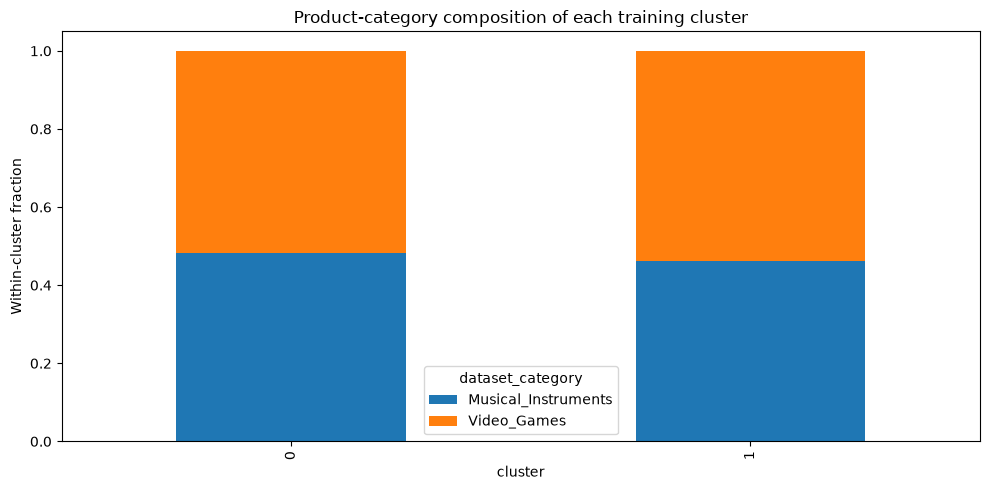

In [42]:
train_category_mix = cluster_category_mix(
    train_features, train_cluster_labels, category_column="dataset_category"
)
display(train_category_mix)

category_mix_plot = train_category_mix.set_index("cluster")
category_mix_plot.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.ylabel("Within-cluster fraction")
plt.title("Product-category composition of each training cluster")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase2_cluster_category_mix.png", dpi=160, bbox_inches="tight")
plt.show()


### 8.3 Inspect representative text terms

Top terms are computed from the training TF-IDF matrix and training cluster assignments. They help describe the lexical content of each cluster; they are not proof that a cluster represents a particular topic.


In [43]:
top_cluster_terms = top_terms_by_cluster(
    X_tfidf_train,
    train_cluster_labels,
    tfidf_vectorizer,
    top_n=12,
)
display(top_cluster_terms)


# Contrast terms against all other clusters to reduce emphasis on generic words.
distinctive_cluster_terms=distinctive_terms_by_cluster(
    X_tfidf_train, train_cluster_labels, tfidf_vectorizer, top_n=12
)
print('Distinctive terms (difference of within- vs outside-cluster mean TF-IDF):')
display(distinctive_cluster_terms)


,cluster,rank,term,mean_tfidf
0,0,1,the,0.042314
1,0,2,it,0.036838
2,0,3,and,0.033703
3,0,4,to,0.031021
4,0,5,for,0.027849
5,0,6,great,0.027493
6,0,7,is,0.025583
7,0,8,this,0.025460
8,0,9,of,0.021853
9,0,10,my,0.021837


Distinctive terms (difference of within- vs outside-cluster mean TF-IDF):


,cluster,rank,term,mean_tfidf_in,mean_tfidf_out,difference
0,0,1,the,0.042314,0.010342,0.031972
1,0,2,to,0.031021,0.006044,0.024977
2,0,3,and,0.033703,0.011914,0.021789
3,0,4,is,0.025583,0.005100,0.020484
4,0,5,of,0.021853,0.003246,0.018606
5,0,6,it,0.036838,0.018864,0.017974
6,0,7,this,0.025460,0.008066,0.017394
7,0,8,for,0.027849,0.010823,0.017026
8,0,9,not,0.017647,0.000962,0.016686
9,0,10,but,0.018193,0.001579,0.016614


**Representative reviews:** the next cell shows only short, redacted excerpts of training reviews nearest each K-means centroid. These examples illustrate what the model groups; they are not representative of the entire population and must not be interpreted as causal explanations. Never copy reviewer IDs into reports.

In [44]:
# Representative examples: nearest training documents in reduced feature space.
representative_rows=[]
for c in sorted(np.unique(train_cluster_labels)):
    indices=np.flatnonzero(train_cluster_labels==c)
    d2=((X_reduced_train[indices]-final_kmeans.cluster_centers_[c])**2).sum(axis=1)
    for i in indices[np.argsort(d2)[:3]]:
        row=train_features.iloc[i]
        excerpt=str(row['cleaned_text'])[:180]
        excerpt=__import__('re').sub(r'[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}','[EMAIL]',excerpt)
        excerpt=__import__('re').sub(r'https?://\S+','[URL]',excerpt)
        representative_rows.append({'cluster':int(c),'words':int(row['text_word_count']),
                                    'rating':row['rating_num'],'text_excerpt':excerpt})
representative_review_examples=pd.DataFrame(representative_rows)
display(representative_review_examples)

,cluster,words,rating,text_excerpt
0,0,51,4.0,however the Player AI is more like 15 year olds who like to wreck each other Loading takes a while. I try to be a cl...
1,0,23,1.0,"virus maybe I just downloaded the free trial & went to play, my security software gave me a warning that there is a ..."
2,0,22,1.0,Movement delay There is a 2 second delay every now and then which isn't something a gameing mouse should be doing.
3,1,4,5.0,Five Stars Thumbs up
4,1,4,5.0,Five Stars thumbs up
5,1,8,5.0,Five Stars 100% satisfaction and thanx a lot


### 8.4 Relate discovered clusters to recorded helpful votes (training/validation only)

These are **post-hoc descriptions**, not target-driven cluster training or `k` selection. Review age, selection effects and exposure periods may confound any difference. **Do not inspect or export test helpful-vote outcomes in Phase 2.**

**Interpretation safeguard:** `helpful_vote` never enters feature construction, fitting, `k`-selection or sensitivity experiments. Only training/validation target values are used for descriptive post-hoc reporting; the test target remains held out for Phase 3. Correlations between cluster membership and helpful votes are not evidence of manipulation or causality.

,cluster,n_reviews,target_valid_n,helpful_vote_mean_posthoc,helpful_vote_median_posthoc,helpful_vote_p90_posthoc,helpful_vote_nonzero_rate_posthoc,mean_log1p_helpful_vote_posthoc
0,0,49065,49065,1.583389,0.0,3.0,0.316865,0.398837
1,1,6935,6935,0.171305,0.0,1.0,0.104398,0.089525


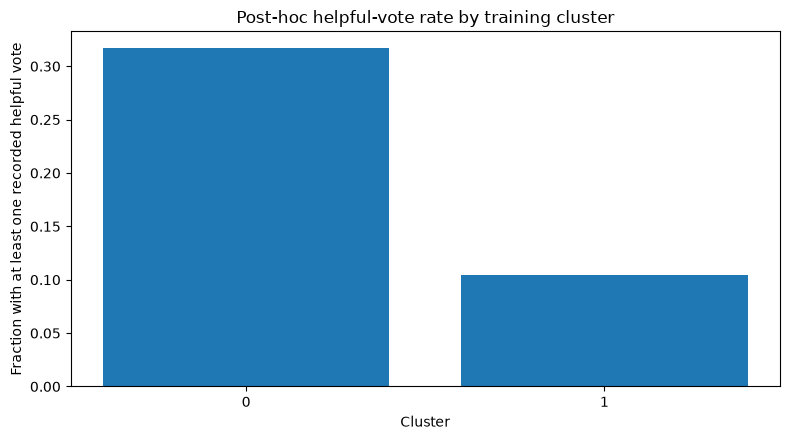

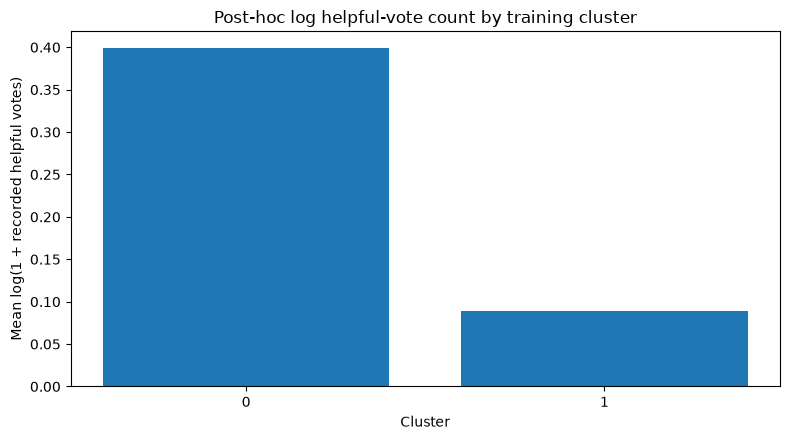

In [45]:
target_profile_columns = [
    "cluster",
    "n_reviews",
    "target_valid_n",
    "helpful_vote_mean_posthoc",
    "helpful_vote_median_posthoc",
    "helpful_vote_p90_posthoc",
    "helpful_vote_nonzero_rate_posthoc",
    "mean_log1p_helpful_vote_posthoc",
]
target_profile_columns = [
    c for c in target_profile_columns if c in train_cluster_profile.columns
]
display(train_cluster_profile[target_profile_columns])

if "helpful_vote_nonzero_rate_posthoc" in train_cluster_profile.columns:
    plt.figure(figsize=(8, 4.5))
    plt.bar(
        train_cluster_profile["cluster"].astype(str),
        train_cluster_profile["helpful_vote_nonzero_rate_posthoc"],
    )
    plt.xlabel("Cluster")
    plt.ylabel("Fraction with at least one recorded helpful vote")
    plt.title("Post-hoc helpful-vote rate by training cluster")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "phase2_helpful_vote_rate_by_cluster.png", dpi=160, bbox_inches="tight")
    plt.show()

if "mean_log1p_helpful_vote_posthoc" in train_cluster_profile.columns:
    plt.figure(figsize=(8, 4.5))
    plt.bar(
        train_cluster_profile["cluster"].astype(str),
        train_cluster_profile["mean_log1p_helpful_vote_posthoc"],
    )
    plt.xlabel("Cluster")
    plt.ylabel("Mean log(1 + recorded helpful votes)")
    plt.title("Post-hoc log helpful-vote count by training cluster")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "phase2_log_helpful_vote_by_cluster.png", dpi=160, bbox_inches="tight")
    plt.show()


### 8.4a Compare helpful votes **within the same publication period and product category**

**Question:** Are text length, rating, purchase verification, review images, prior activity, price availability, formulaic titles, and cluster membership associated with recorded helpful votes **among reviews posted at roughly the same time**?

**Design:** Within *each* chronological partition (train and validation separately), match reviews by **UTC publication calendar month × dataset category** (`Musical_Instruments` or `Video_Games`). For each feature, compare its two groups **only in matched strata with ≥10 reviews in each group**. Repeat using **calendar week × dataset category** (≥5 per group) as a stricter time-matching sensitivity check. Report the **difference in the share with ≥1 recorded helpful vote** and the difference in **mean `log1p(helpful_vote_num)`**; aggregate strata with harmonic-balance weights `2*n_A*n_B/(n_A+n_B)` so large, balanced strata contribute more. The word-length threshold is fixed at the **training median** before inspecting outcomes.

**Safeguards:** This is **post-hoc descriptive analysis** performed after choosing and fitting the unsupervised representation and clusters. It does **not** change the fitted model, select `k`, construct a fraud label, or use the **test helpful-vote target**. A match in publication month/week reduces age differences but does **not** guarantee equal exposure, visibility, or product popularity, so associations are **not causal**. If a contrast lacks enough matched strata, it is reported as *insufficient data*, not zero effect.


In [46]:
# Post-hoc, same-publication-period comparisons (NEVER read test_features targets here).
# These functions are standalone notebook analyses; no modifications to src/ modules.

LENGTH_THRESHOLD_TRAIN = float(pd.to_numeric(
    train_features['text_word_count'], errors='coerce'
).median())
MIN_EACH_MONTH = 10
MIN_EACH_WEEK = 5


def _binary_comparison_specs(frame, cluster_labels, word_cutoff):
    """Return feature contrasts as (A_mask, B_mask, A_description, B_description)."""
    words = pd.to_numeric(frame['text_word_count'], errors='coerce')
    ratings = pd.to_numeric(frame['rating_num'], errors='coerce')
    reviewer_hist = pd.to_numeric(frame['reviewer_prior_review_count'], errors='coerce')
    product_hist = pd.to_numeric(frame['product_prior_review_count'], errors='coerce')
    verified = frame['verified_purchase_status'].astype(str)
    image = frame['review_image_available'].astype(str)
    price_missing = frame['product_price_missing'].astype(str)
    formulaic = frame['cleaned_title'].fillna('').str.contains(
        r'\bfive\s+stars\b', case=False, regex=True
    )
    specs = {
        'longer_review': (words > word_cutoff, words <= word_cutoff,
                          f'words > train median ({word_cutoff:g})', 'words <= train median'),
        'five_star_rating': (ratings == 5, ratings.between(1, 4),
                             '5-star rating', '1-to-4-star rating'),
        'verified_purchase': (verified == 'verified', verified == 'not_verified',
                              'verified', 'not verified'),
        'review_has_image': (image == 'yes', image == 'no',
                             'image included', 'no review image'),
        'reviewer_prior_activity': (reviewer_hist > 0, reviewer_hist == 0,
                                    'prior sampled reviews > 0', 'no prior sampled review'),
        'product_prior_activity': (product_hist > 0, product_hist == 0,
                                   'prior sampled product reviews > 0', 'none in history'),
        'product_price_available': (price_missing == 'no', price_missing == 'yes',
                                    'price available', 'price missing'),
        'formulaic_five_stars_title': (formulaic, ~formulaic,
                                       'title contains Five Stars', 'other titles'),
    }
    # Only compare cluster 1 vs 0 for a two-cluster reference solution.
    if int(selected_k) == 2:
        assigned = pd.Series(np.asarray(cluster_labels), index=frame.index)
        specs['cluster_1_vs_0'] = (
            assigned == 1, assigned == 0, 'reference cluster 1', 'reference cluster 0'
        )
    return specs


def compare_within_time_strata(frame, labels, partition, period='month', min_each=10):
    """Compare group A versus B within month/week x category; no test labels supplied."""
    if partition not in {'train', 'validation'}:
        raise ValueError('This post-hoc Phase 2 examination must not include test outcomes.')
    timestamps = pd.to_datetime(frame['timestamp_dt'], errors='coerce', utc=True)
    votes = pd.to_numeric(frame['helpful_vote_num'], errors='coerce')
    valid = timestamps.notna() & votes.notna() & votes.ge(0) & (votes % 1 == 0)
    if period == 'month':
        time_bin = timestamps.dt.strftime('%Y-%m')
    elif period == 'week':
        time_bin = timestamps.dt.strftime('%G-W%V')
    else:
        raise ValueError('Period must be month or week.')
    base = pd.DataFrame({
        'time_bin': time_bin,
        'dataset_category': frame['dataset_category'].astype(str),
        'helpful_nonzero': votes.gt(0).astype(float),
        'log1p_votes': np.log1p(votes.clip(lower=0)),
    }, index=frame.index)
    summaries, detail_parts = [], []
    for feature, (group_a, group_b, description_a, description_b) in _binary_comparison_specs(
        frame, labels, LENGTH_THRESHOLD_TRAIN
    ).items():
        # Disjoint A/B groups; unknown feature values excluded, never guessed.
        a = group_a.reindex(frame.index).fillna(False).astype(bool)
        b = group_b.reindex(frame.index).fillna(False).astype(bool)
        assert not (a & b).any(), f'Nonexclusive comparison: {feature}'
        eligible = valid & (a | b)
        subset = base.loc[eligible].copy()
        subset['group'] = np.where(a.loc[eligible], 'A', 'B')
        agg = subset.groupby(['time_bin', 'dataset_category', 'group'], dropna=False).agg(
            n=('helpful_nonzero', 'size'),
            helpful_nonzero_rate=('helpful_nonzero', 'mean'),
            mean_log1p_votes=('log1p_votes', 'mean'),
        ).reset_index()
        a_table = agg.loc[agg.group.eq('A')].drop(columns='group').rename(columns={
            'n': 'n_A', 'helpful_nonzero_rate': 'rate_A', 'mean_log1p_votes': 'log_A'
        })
        b_table = agg.loc[agg.group.eq('B')].drop(columns='group').rename(columns={
            'n': 'n_B', 'helpful_nonzero_rate': 'rate_B', 'mean_log1p_votes': 'log_B'
        })
        matched = a_table.merge(
            b_table, on=['time_bin', 'dataset_category'], how='inner', validate='one_to_one'
        )
        matched = matched.loc[
            (matched['n_A'] >= min_each) & (matched['n_B'] >= min_each)
        ].copy()
        matched['weight'] = (
            2 * matched['n_A'] * matched['n_B'] / (matched['n_A'] + matched['n_B'])
        )
        matched['delta_helpful_nonzero'] = matched['rate_A'] - matched['rate_B']
        matched['delta_mean_log1p_votes'] = matched['log_A'] - matched['log_B']
        matched.insert(0, 'comparison', feature)
        matched.insert(0, 'period', period)
        matched.insert(0, 'partition', partition)
        if not matched.empty:
            detail_parts.append(matched)
            total_w = matched['weight'].sum()
            weighted_rate_diff = float(
                np.dot(matched['weight'], matched['delta_helpful_nonzero']) / total_w
            )
            weighted_log_diff = float(
                np.dot(matched['weight'], matched['delta_mean_log1p_votes']) / total_w
            )
        else:
            weighted_rate_diff = np.nan
            weighted_log_diff = np.nan
        summaries.append({
            'partition': partition,
            'period': period,
            'comparison': feature,
            'group_A': description_a,
            'group_B': description_b,
            'min_each_per_stratum': min_each,
            'matched_strata': len(matched),
            'matched_group_A_rows': int(matched['n_A'].sum()),
            'matched_group_B_rows': int(matched['n_B'].sum()),
            'weighted_difference_helpful_nonzero_A_minus_B': weighted_rate_diff,
            'weighted_difference_mean_log1p_votes_A_minus_B': weighted_log_diff,
            'status': 'estimable' if len(matched) else 'insufficient within-period overlap',
        })
    return pd.DataFrame(summaries), pd.concat(detail_parts, ignore_index=True) if detail_parts else pd.DataFrame()


month_summaries, week_summaries, matched_details = [], [], []
for _partition, _frame, _labels in [
    ('train', train_features, train_cluster_labels),
    ('validation', validation_features, validation_cluster_labels),
]:
    _month_summary, _month_details = compare_within_time_strata(
        _frame, _labels, _partition, 'month', MIN_EACH_MONTH
    )
    _week_summary, _week_details = compare_within_time_strata(
        _frame, _labels, _partition, 'week', MIN_EACH_WEEK
    )
    month_summaries.append(_month_summary)
    week_summaries.append(_week_summary)
    matched_details.extend([_month_details, _week_details])

helpfulness_within_month = pd.concat(month_summaries, ignore_index=True)
helpfulness_within_week = pd.concat(week_summaries, ignore_index=True)
helpfulness_stratum_details = pd.concat(
    [t for t in matched_details if not t.empty], ignore_index=True
) if any(not t.empty for t in matched_details) else pd.DataFrame()

assert not helpfulness_within_month['partition'].eq('test').any()
assert not helpfulness_within_week['partition'].eq('test').any()
assert not helpfulness_stratum_details.get('partition', pd.Series(dtype=str)).eq('test').any()
print('TRAIN median text-word threshold:', LENGTH_THRESHOLD_TRAIN)
print('Month-matched results (difference A minus B; positive means more helpful votes for A):')
display(helpfulness_within_month.round(4))
print('Week-matched sensitivity results (stricter time control):')
display(helpfulness_within_week.round(4))


TRAIN median text-word threshold: 28.0
Month-matched results (difference A minus B; positive means more helpful votes for A):


,partition,period,comparison,group_A,group_B,min_each_per_stratum,matched_strata,matched_group_A_rows,matched_group_B_rows,weighted_difference_helpful_nonzero_A_minus_B,weighted_difference_mean_log1p_votes_A_minus_B,status
0,train,month,longer_review,words > train median (28),words <= train median,10,189,23286,27774,0.2527,0.3728,estimable
1,train,month,five_star_rating,5-star rating,1-to-4-star rating,10,270,35404,19237,-0.1157,-0.1561,estimable
2,train,month,verified_purchase,verified,not verified,10,230,47207,5319,-0.1274,-0.2244,estimable
3,train,month,review_has_image,image included,no review image,10,64,1127,20638,0.3169,0.6042,estimable
4,train,month,reviewer_prior_activity,prior sampled reviews > 0,no prior sampled review,10,35,442,12247,0.0346,0.0779,estimable
5,train,month,product_prior_activity,prior sampled product reviews > 0,none in history,10,240,28995,24637,-0.1399,-0.1970,estimable
6,train,month,product_price_available,price available,price missing,10,251,34811,19224,-0.0051,0.0016,estimable
7,train,month,formulaic_five_stars_title,title contains Five Stars,other titles,10,101,7334,20814,-0.1966,-0.2663,estimable
8,train,month,cluster_1_vs_0,reference cluster 1,reference cluster 0,10,100,6870,21038,-0.1991,-0.2673,estimable
9,validation,month,longer_review,words > train median (28),words <= train median,10,32,5720,6278,0.1822,0.2380,estimable


Week-matched sensitivity results (stricter time control):


,partition,period,comparison,group_A,group_B,min_each_per_stratum,matched_strata,matched_group_A_rows,matched_group_B_rows,weighted_difference_helpful_nonzero_A_minus_B,weighted_difference_mean_log1p_votes_A_minus_B,status
0,train,week,longer_review,words > train median (28),words <= train median,5,789,22679,27686,0.2528,0.3723,estimable
1,train,week,five_star_rating,5-star rating,1-to-4-star rating,5,927,34410,18273,-0.1163,-0.1532,estimable
2,train,week,verified_purchase,verified,not verified,5,507,27162,3813,-0.1323,-0.2335,estimable
3,train,week,review_has_image,image included,no review image,5,110,701,9173,0.3074,0.5466,estimable
4,train,week,reviewer_prior_activity,prior sampled reviews > 0,no prior sampled review,5,29,163,2670,0.0221,0.0322,estimable
5,train,week,product_prior_activity,prior sampled product reviews > 0,none in history,5,890,28548,23643,-0.1397,-0.1954,estimable
6,train,week,product_price_available,price available,price missing,5,895,33674,18543,-0.0055,0.0037,estimable
7,train,week,formulaic_five_stars_title,title contains Five Stars,other titles,5,427,7300,20250,-0.1967,-0.2659,estimable
8,train,week,cluster_1_vs_0,reference cluster 1,reference cluster 0,5,426,6844,20649,-0.2000,-0.2673,estimable
9,validation,week,longer_review,words > train median (28),words <= train median,5,130,5720,6278,0.1827,0.2386,estimable


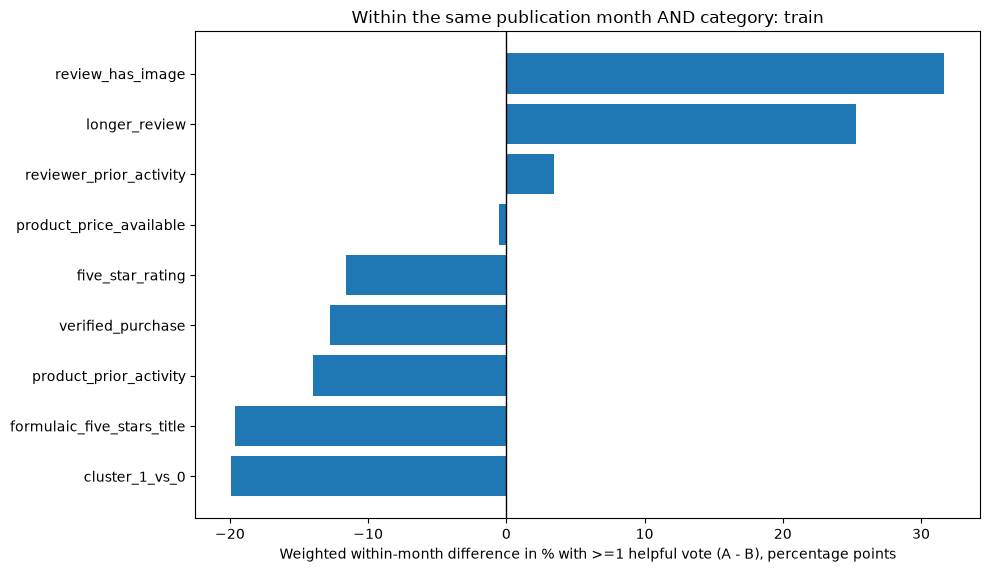

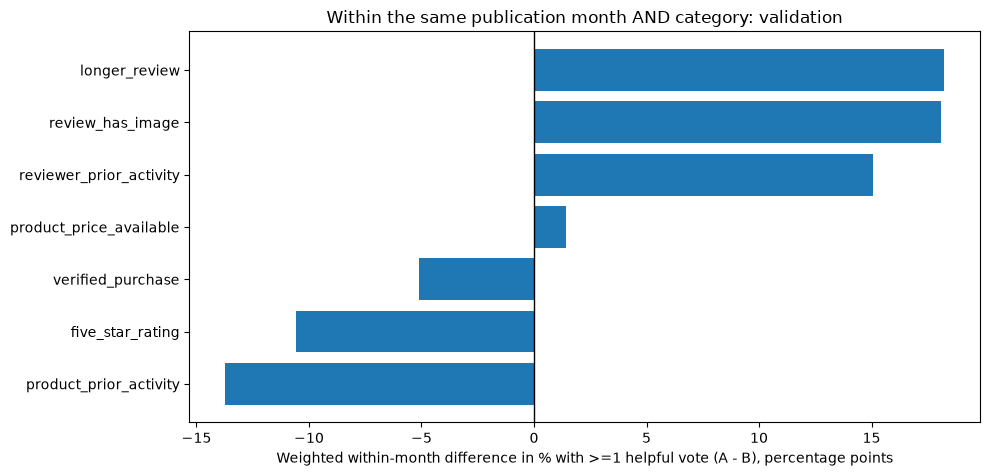

Agreement in association direction under month vs week matching:


,partition,comparison,matched_strata_month,weighted_difference_helpful_nonzero_A_minus_B_month,matched_strata_week,weighted_difference_helpful_nonzero_A_minus_B_week,same_direction_when_estimable
0,train,longer_review,189,0.2527,789,0.2528,1.0
1,train,five_star_rating,270,-0.1157,927,-0.1163,1.0
2,train,verified_purchase,230,-0.1274,507,-0.1323,1.0
3,train,review_has_image,64,0.3169,110,0.3074,1.0
4,train,reviewer_prior_activity,35,0.0346,29,0.0221,1.0
5,train,product_prior_activity,240,-0.1399,890,-0.1397,1.0
6,train,product_price_available,251,-0.0051,895,-0.0055,1.0
7,train,formulaic_five_stars_title,101,-0.1966,427,-0.1967,1.0
8,train,cluster_1_vs_0,100,-0.1991,426,-0.2000,1.0
9,validation,longer_review,32,0.1822,130,0.1827,1.0


Saved within-time comparisons. Test helpful votes were not read.


In [47]:
# These plots show time-matched A-vs-B differences; they are NOT evidence of causality.
for _part in ('train', 'validation'):
    _subset = helpfulness_within_month.loc[
        helpfulness_within_month['partition'].eq(_part)
        & helpfulness_within_month['status'].eq('estimable')
    ].copy()
    if _subset.empty:
        print(f'No estimable time-matched comparisons in {_part}.')
        continue
    _subset = _subset.sort_values('weighted_difference_helpful_nonzero_A_minus_B')
    fig, ax = plt.subplots(figsize=(10, max(4, 0.48 * len(_subset) + 1.5)))
    ax.barh(
        _subset['comparison'],
        _subset['weighted_difference_helpful_nonzero_A_minus_B'] * 100,
    )
    ax.axvline(0, linewidth=1, color='black')
    ax.set_xlabel('Weighted within-month difference in % with >=1 helpful vote (A - B), percentage points')
    ax.set_title(f'Within the same publication month AND category: {_part}')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'phase2_within_month_helpfulness_{_part}.png', dpi=160, bbox_inches='tight')
    plt.show()

# Determine whether the sign of a monthly contrast agrees with the stricter weekly result.
_summary_compare_cols = ['partition', 'comparison', 'matched_strata',
                         'weighted_difference_helpful_nonzero_A_minus_B']
helpfulness_month_week_comparison = helpfulness_within_month[_summary_compare_cols].merge(
    helpfulness_within_week[_summary_compare_cols],
    on=['partition', 'comparison'],
    suffixes=('_month', '_week'),
    validate='one_to_one'
)
helpfulness_month_week_comparison['same_direction_when_estimable'] = np.where(
    helpfulness_month_week_comparison[
        'weighted_difference_helpful_nonzero_A_minus_B_month'
    ].notna() & helpfulness_month_week_comparison[
        'weighted_difference_helpful_nonzero_A_minus_B_week'
    ].notna(),
    np.sign(helpfulness_month_week_comparison[
        'weighted_difference_helpful_nonzero_A_minus_B_month'
    ]) == np.sign(helpfulness_month_week_comparison[
        'weighted_difference_helpful_nonzero_A_minus_B_week'
    ]),
    np.nan,
)
print('Agreement in association direction under month vs week matching:')
display(helpfulness_month_week_comparison.round(4))

# Save immediately, and also register in the central artifacts table later.
for _filename, _table in [
    ('phase2_within_month_helpfulness_comparisons.csv', helpfulness_within_month),
    ('phase2_within_week_helpfulness_comparisons.csv', helpfulness_within_week),
    ('phase2_within_time_stratum_details.csv', helpfulness_stratum_details),
    ('phase2_within_month_vs_week_directions.csv', helpfulness_month_week_comparison),
]:
    _table.to_csv(OUTPUT_DIR / _filename, index=False)
print('Saved within-time comparisons. Test helpful votes were not read.')


### 8.5 Visualize clusters in the PCA space


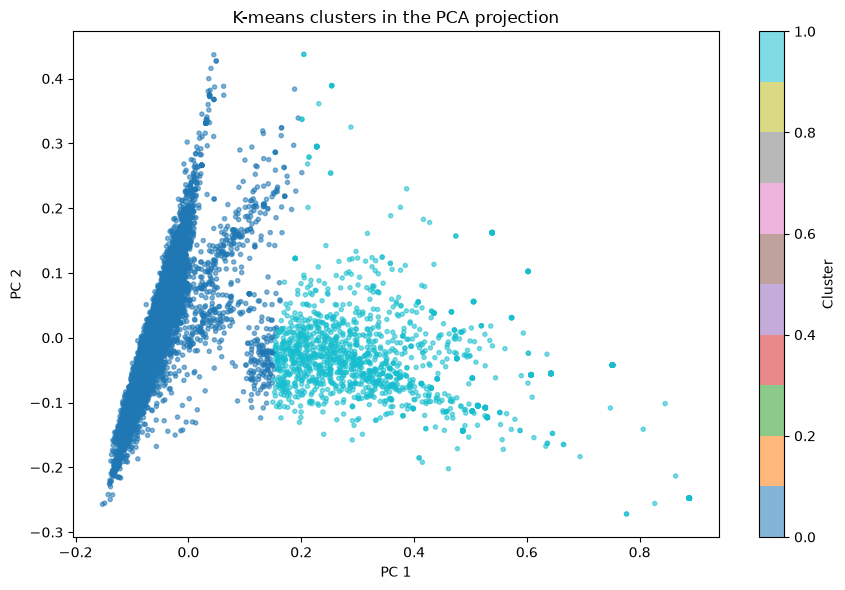

In [48]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca_train[plot_indices, 0],
    X_pca_train[plot_indices, 1],
    c=train_cluster_labels[plot_indices],
    cmap="tab10",
    s=9,
    alpha=0.55,
)
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("K-means clusters in the PCA projection")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "phase2_pca_clusters.png", dpi=160, bbox_inches="tight")
plt.show()


### 8.6 Interpretation and limitations

For each training cluster report its share, category mixture, median text length/rating, prior activity, distinctive terms and representative text. Then check the share in validation and test **without consulting test helpful votes**. Use the table below for **conditional, data-derived comments**, not unverified semantic cluster labels.

**Critical discussion of the original results (to verify upon rerun):** The earlier reference clustering had a small cluster rich in formulaic `Five Stars` titles that virtually disappeared later; SVD-axis standardization changed labels sharply; and text-only clustering closely matched fused clustering. These observations indicate possible **historical conventions, scale sensitivity and limited contribution from structured features**, not successful fake-review detection. The controlled experiments in Section 7.6 explicitly test the sensitivity of these observations. **No improved stability or cross-period persistence is claimed until the revised experiments have been executed.**

A cluster that disappears later is a real data-distribution result, not something to conceal by changing `k` until it looks balanced. For any proposed replacement model, repeat complete unsupervised selection/stability checks using training data, then perform one final evaluation on held-out features, without peeking at test targets.

In [49]:
interpretation_checklist = pd.DataFrame([
    ["Cluster size and share", "Report n and share for each cluster."],
    ["Category composition", "Check whether clusters are category-specific or shared."],
    ["Review content", "Use top TF-IDF terms and text-length summaries."],
    ["Review/product context", "Inspect rating, price, time, metadata and prior-activity summaries."],
    ["Helpful-vote association", "Compare nonzero rate and log-count summaries post-hoc only."],
    ["Held-out persistence", "Compare cluster profiles in validation and test periods."],
    ["Stability", "Use seed, subsample and scaling sensitivity results."],
    ["Limitations", "Mention snapshot/exposure-time bias and sampled-history proxies."],
], columns=["interpretation_dimension", "what_to_report"])
display(interpretation_checklist)


,interpretation_dimension,what_to_report
0,Cluster size and share,Report n and share for each cluster.
1,Category composition,Check whether clusters are category-specific or shared.
2,Review content,Use top TF-IDF terms and text-length summaries.
3,Review/product context,"Inspect rating, price, time, metadata and prior-activity summaries."
4,Helpful-vote association,Compare nonzero rate and log-count summaries post-hoc only.
5,Held-out persistence,Compare cluster profiles in validation and test periods.
6,Stability,"Use seed, subsample and scaling sensitivity results."
7,Limitations,Mention snapshot/exposure-time bias and sampled-history proxies.


### 8.7 Automatic, evidence-based interpretation of the *reference* clusters

This report uses observed training feature medians, the frequency of formulaic titles, category mix and validation prevalence. It deliberately refrains from naming a group "fake," "reliable," or "low-quality" from cluster membership alone.

In [50]:
# Write per-cluster narrative based on actually computed statistics, not assumed prior outputs.
_train_phrase = phrase_and_length_drift.loc[
    phrase_and_length_drift['partition'].eq('train')
].set_index('cluster')
_val_share = cluster_share_by_split.loc[
    cluster_share_by_split['partition'].eq('validation')
].set_index('cluster')['share']
_train_share = cluster_share_by_split.loc[
    cluster_share_by_split['partition'].eq('train')
].set_index('cluster')['share']
_top_distinctive = (
    distinctive_cluster_terms.sort_values(['cluster', 'rank'])
    .groupby('cluster')['term'].apply(lambda x: ', '.join(map(str, x.head(5))))
)
_interpretation_rows = []
for _cluster in sorted(np.unique(train_cluster_labels)):
    _profile = train_cluster_profile.set_index('cluster').loc[_cluster]
    _phrase_rate = float(_train_phrase.loc[_cluster, 'five_stars_title_rate'])
    _train_prevalence = float(_train_share.loc[_cluster])
    _later_prevalence = float(_val_share.get(_cluster, 0.0))
    _interpretation_rows.append({
        'cluster': int(_cluster),
        'train_n': int(_profile['n_reviews']),
        'train_share': _train_prevalence,
        'validation_share': _later_prevalence,
        'median_rating': float(_profile['median_rating_num']),
        'median_words': float(_profile['median_text_word_count']),
        'five_stars_title_rate_train': _phrase_rate,
        'distinctive_terms': _top_distinctive.get(_cluster, ''),
        'interpretation_flag': (
            'Historically/temporally concentrated; investigate title convention and drift.'
            if _later_prevalence < .01 and _train_prevalence >= .01 else
            'Formulaic Five Stars titles concentrated here; inspect title ablation.'
            if _phrase_rate >= .5 else
            'Describe with structured profiles and examples; no authenticity label.'
        ),
    })
reference_cluster_interpretation = pd.DataFrame(_interpretation_rows)
display(reference_cluster_interpretation)

if len(robustness_variant_table):
    _baseline = robustness_variant_table.set_index('variant').loc['baseline_equal_weights']
    print('Reference diagnostic silhouette:', round(_baseline['silhouette_train'], 4))
    print('Reference train/validation cluster-share TV distance:',
          round(_baseline['train_validation_cluster_share_TV'], 4))
    print('Sensitivity variants should be discussed explicitly; none automatically replaces the baseline.')

,cluster,train_n,train_share,validation_share,median_rating,median_words,five_stars_title_rate_train,distinctive_terms,interpretation_flag
0,0,49065,0.876161,0.999833,5.0,33.0,0.011943,"the, to, and, is, of",Describe with structured profiles and examples; no authenticity label.
1,1,6935,0.123839,0.000167,5.0,6.0,0.980678,"five stars, five, stars, stars great, stars good",Historically/temporally concentrated; investigate title convention and drift.


Reference diagnostic silhouette: 0.3692
Reference train/validation cluster-share TV distance: 0.1342
Sensitivity variants should be discussed explicitly; none automatically replaces the baseline.


### 8.8 Full A/B/C retraining comparison to investigate temporal instability

The **same-month and same-category helpful-vote comparisons above answer a different question** (post-hoc associations, with publication time partly controlled). They do **not** repair temporal cluster drift.

Here we compare **three complete, independently specified clustering models**:

| Model | Text representation | Fit cohort | History regime |
|---|---|---|---|
| **A** (unchanged reference) | cleaned title + body | All training years | Frozen training-history for validation/test |
| **B** | **Review body only**, including body-only derived text statistics | All training years | Same frozen history |
| **C** | **Review body only**, including body-only derived text statistics | Only training rows from **2019-01-01 onward** | Same frozen history; historical counts may include older *past* training events |

For B/C, we exclude the title-derived `title_body_length_ratio` and **recompute every structured text statistic that originally included the title**, so this is truly a *body-only model*, not merely a body-only TF-IDF vocabulary. Price, rating, category, and past-only activity features remain eligible structured predictors. No helpful-vote outcomes enter modeling, K selection, or the model comparison.

**Protocol:** Fit TF-IDF, imputation, one-hot encoding, SVD, candidate k selection, and K-means **independently within each model's fit cohort**. Use train-only silhouette/seed stability/balance to choose k. Then compare chronological validation assignments, common 2019+ training-cohort assignments, seed/subsample/scaling sensitivity, and cluster meaning. **Do not use the test set to choose a candidate**; if a model passes predeclared safeguards, perform a single target-free test check after selection.

**Crucial caveat:** Similar train/validation cluster proportions are *not* proof of temporal stability. A two-cluster split of empty versus nonempty review bodies or otherwise uninformative groups should not be declared a fix. Below we audit body-availability and cluster descriptors explicitly.


In [51]:
# Controlled A/B/C settings. Edit here rather than changing the held-out partitions.
ABC_RECENT_START = pd.Timestamp('2019-01-01', tz='UTC')
ABC_K_VALUES = tuple(int(k) for k in CLUSTER_K_VALUES)
ABC_SELECTION_ROWS = min(15_000, CLUSTER_SEARCH_MAX_ROWS)
ABC_SILHOUETTE_ROWS = min(2_000, SILHOUETTE_SAMPLE_SIZE)
ABC_SEED_VALUES = (SEED, SEED + 10, SEED + 20)
ABC_MIN_TRAIN_SHARE = 0.01
ABC_MIN_RECENT_SHARE = 0.01
ABC_MIN_VALIDATION_SHARE = 0.01
ABC_MAX_RECENT_TO_VALIDATION_TV = 0.10
ABC_MIN_SEED_ARI = 0.75
ABC_MIN_TRAIN_SILHOUETTE = 0.05
ABC_MIN_BODY_AVAILABLE_IN_CLUSTER = 0.60

# A/B/C deliberately use the TF-IDF representation even when optional frozen
# sentence embeddings have been extracted in Section 4.3.
assert ACTIVE_TEXT_REPRESENTATION == 'tfidf', 'A/B/C requires the fitted TF-IDF baseline.'

_abc_recent_mask = pd.to_datetime(train_features['timestamp_dt'], utc=True).ge(ABC_RECENT_START).to_numpy()
_abc_recent_indices = np.flatnonzero(_abc_recent_mask)
if len(_abc_recent_indices) < max(100, 2 * max(ABC_K_VALUES)):
    raise ValueError('Not enough 2019+ TRAIN rows for Model C. Adjust the cohort and document why.')

# Remove the one title-derived feature from body-only structured predictors.
ABC_BODY_NUMERIC_FEATURES = [f for f in active_numeric if f != 'title_body_length_ratio']
ABC_BODY_CATEGORICAL_FEATURES = list(active_categorical)

def make_body_only_feature_frame(frame):
    """Rebuild ALL title-dependent text inputs from body alone; do not refit history.

    Non-text predictors, immutable review identities, and target are preserved.
    Title is kept only for later qualitative auditing, never used by the encoder.
    """
    out = frame.copy()
    body = out['cleaned_body'].fillna('').astype(str)
    out['cleaned_text'] = body
    out['text_char_count'] = body.str.len().astype(float)
    out['text_word_count'] = body.str.findall(r'\b\w+\b').str.len().astype(float)
    out['text_sentence_count'] = body.map(
        lambda t: float(len([s for s in re.split(r'[.!?]+', t) if s.strip()])) if t else 0.0
    )
    out['non_ascii_ratio'] = body.map(
        lambda t: sum(ord(c) > 127 for c in t) / len(t) if t else 0.0
    )
    out['exclamation_count'] = body.str.count('!').astype(float)
    out['question_count'] = body.str.count(r'\?').astype(float)
    out['uppercase_ratio'] = body.map(
        lambda t: sum(c.isupper() for c in t) / sum(c.isalpha() for c in t)
        if any(c.isalpha() for c in t) else 0.0
    )
    out['log1p_text_word_count'] = np.log1p(out['text_word_count'].clip(lower=0))
    out['review_text_available'] = np.where(body.str.len() > 0, 'yes', 'no')
    return out

abc_body_train = make_body_only_feature_frame(train_features)
abc_body_validation = make_body_only_feature_frame(validation_features)
abc_recent_train = abc_body_train.iloc[_abc_recent_indices].copy()

assert 'title_body_length_ratio' not in ABC_BODY_NUMERIC_FEATURES
assert (abc_body_train['cleaned_text'] == train_features['cleaned_body'].fillna('').astype(str)).all()
assert abc_body_train['sample_row_id'].equals(train_features['sample_row_id'])
assert abc_body_validation['sample_row_id'].equals(validation_features['sample_row_id'])
print('Model C: 2019+ training rows:', len(abc_recent_train))
print('Body-empty rate in training (full / recent):',
      round(float(abc_body_train['cleaned_text'].eq('').mean()), 4),
      round(float(abc_recent_train['cleaned_text'].eq('').mean()), 4))
print('Title-dependent columns recomputed for B/C; title/body length ratio excluded.')


Model C: 2019+ training rows: 14256
Body-empty rate in training (full / recent): 0.0 0.0
Title-dependent columns recomputed for B/C; title/body length ratio excluded.


In [52]:
# Full independent fit + K search for models B/C. A reuses the full reference already fitted above.
# Train-only model selection; nothing below reads a helpful-vote target or test-set features.

def _abc_share(labels, k):
    counts = np.bincount(np.asarray(labels, dtype=int), minlength=int(k))
    return counts / max(1, counts.sum())

def _abc_tv(a, b):
    return float(0.5 * np.abs(np.asarray(a) - np.asarray(b)).sum())

def _abc_choose_k(X_train_reduced, name):
    rng = np.random.default_rng(SEED + 199)
    n_rows = min(ABC_SELECTION_ROWS, len(X_train_reduced))
    indices = np.sort(rng.choice(len(X_train_reduced), n_rows, replace=False))
    X_select = X_train_reduced[indices]
    possible_k = [k for k in ABC_K_VALUES if 2 <= k < len(X_select)]
    if not possible_k:
        raise ValueError(f'Insufficient training rows to select k for {name}.')
    candidates = evaluate_kmeans_candidates(
        X_select, k_values=possible_k, random_state=SEED,
        n_init=10, max_fit_rows=len(X_select),
        silhouette_sample_size=min(ABC_SILHOUETTE_ROWS, len(X_select)),
    )
    stabilities = []
    for k in possible_k:
        result = evaluate_seed_stability(X_select, k=k,
                                         seeds=ABC_SEED_VALUES, n_init=6)
        stabilities.append({'k': int(k), 'seed_stability_ari': result['mean_pairwise_ari'],
                            'minimum_seed_ari': result['min_pairwise_ari']})
    candidates = candidates.merge(pd.DataFrame(stabilities), on='k')
    for col, input_col in [('silhouette_rank_score','silhouette'),
                           ('stability_rank_score','seed_stability_ari'),
                           ('cluster_balance_rank_score','smallest_cluster_fraction')]:
        candidates[col] = candidates[input_col].rank(pct=True)
    candidates['selection_score'] = (
        0.50 * candidates['silhouette_rank_score']
        + 0.35 * candidates['stability_rank_score']
        + 0.15 * candidates['cluster_balance_rank_score']
    )
    chosen = int(candidates.sort_values(
        ['selection_score', 'seed_stability_ari', 'k'],
        ascending=[False, False, True]
    ).iloc[0]['k'])
    candidates['model'] = name
    return chosen, candidates, X_select

abc_models = {
    'A': {'name':'A - title+body, full training history',
          'fit_rows':len(train_features), 'k':int(selected_k),
          'pipeline':phase2_pipeline, 'svd':svd_reducer,
          'kmeans':final_kmeans,
          'X_train':X_reduced_train,
          'train_labels':np.asarray(train_cluster_labels),
          'val_labels':np.asarray(validation_cluster_labels),
          'train_frame':train_features, 'val_frame':validation_features,
          'numeric':list(active_numeric), 'categorical':list(active_categorical),
          'text_mode':'title+body'}
}
abc_candidate_tables = [candidate_table.assign(model='A')]

for _abc_name, _abc_frame in [('B', abc_body_train), ('C', abc_recent_train)]:
    _abc_pipeline = build_phase2_preprocessing_pipeline(
        max_tfidf_features=MAX_TFIDF_FEATURES, min_df=TFIDF_MIN_DF,
        numeric_features=ABC_BODY_NUMERIC_FEATURES,
        categorical_features=ABC_BODY_CATEGORICAL_FEATURES,
    )
    _abc_train_matrix = _abc_pipeline.fit_transform(_abc_frame)
    _abc_val_matrix = _abc_pipeline.transform(abc_body_validation)
    _abc_svd, _abc_train_red, _abc_val_red, _ = fit_svd_reduction(
        _abc_train_matrix, X_validation=_abc_val_matrix,
        n_components=N_REDUCED_COMPONENTS, random_state=SEED)
    _abc_k, _abc_candidates, _abc_select = _abc_choose_k(_abc_train_red, _abc_name)
    _abc_model = KMeans(n_clusters=_abc_k, random_state=SEED, n_init=20)
    _abc_train_labels = _abc_model.fit_predict(_abc_train_red)
    _abc_val_labels = _abc_model.predict(_abc_val_red)
    abc_models[_abc_name] = {
        'name':f'{_abc_name} - body only, ' + ('all training years' if _abc_name=='B' else '2019+ training'),
        'fit_rows':len(_abc_frame), 'k':_abc_k,
        'pipeline':_abc_pipeline, 'svd':_abc_svd,
        'kmeans':_abc_model, 'X_train':_abc_train_red,
        'train_labels':_abc_train_labels, 'val_labels':_abc_val_labels,
        'train_frame':_abc_frame, 'val_frame':abc_body_validation,
        'numeric':list(ABC_BODY_NUMERIC_FEATURES),
        'categorical':list(ABC_BODY_CATEGORICAL_FEATURES),
        'text_mode':'body only',
        'k_candidates':_abc_candidates,
        'X_select':_abc_select,
    }
    abc_candidate_tables.append(_abc_candidates)
    print(f'Model {_abc_name} fitted on {len(_abc_frame):,} train rows; selected k={_abc_k}; '
          f'{_abc_svd.explained_variance_ratio_.sum():.2%} SVD variance retained.')

abc_k_candidates = pd.concat(abc_candidate_tables, ignore_index=True, sort=False)
display(abc_k_candidates[['model','k','silhouette','smallest_cluster_fraction',
                          'seed_stability_ari','selection_score']].round(4))
assert not any('helpful_vote' in x for model in abc_models.values()
               for x in model['numeric'] + model['categorical'])


Model B fitted on 56,000 train rows; selected k=7; 10.96% SVD variance retained.
Model C fitted on 14,256 train rows; selected k=2; 11.10% SVD variance retained.


,model,k,silhouette,smallest_cluster_fraction,seed_stability_ari,selection_score
0,A,2,0.4174,0.1275,0.9977,1.0000
1,A,3,0.4106,0.0207,0.5290,0.5964
2,A,4,0.3402,0.0207,0.5417,0.5750
3,A,5,0.0668,0.0179,0.6988,0.4786
4,A,6,0.0803,0.0121,0.9012,0.6500
5,A,7,0.0774,0.0083,0.6361,0.3857
6,A,8,0.0656,0.0083,0.6453,0.3143
7,B,2,0.5722,0.0223,0.0067,0.7000
8,B,3,0.5309,0.0182,0.3240,0.6571
9,B,4,0.0812,0.0066,0.9485,0.6393


Complete model comparison (TRAIN/VALIDATION only):


,model,text_representation,train_period,train_rows,selected_k,train_silhouette_selection_sample,seed_stability_ari_selection_sample,subsample_ari_mean,svd_scaling_ari_selection_sample,min_fit_train_cluster_share,min_common_recent_train_cluster_share,min_validation_cluster_share,fit_train_vs_validation_TV,common_recent_train_vs_validation_TV,min_fit_cluster_body_available_rate,body_missing_cluster_risk,passes_internal_checks,passes_temporal_checks,passes_preliminary_checks
0,A,title+body,all training years,56000,2,0.4174,0.9977,0.9986,0.0599,0.1238,0.0007,0.0002,0.1237,0.0005,0.9999,False,True,False,False
1,B,body only,all training years,56000,7,0.0923,0.7933,0.8215,0.3978,0.0101,0.0110,0.0058,0.0552,0.0418,0.9999,False,True,False,False
2,C,body only,2019+ training only,14256,2,0.4955,0.7549,0.9105,-0.0010,0.0317,0.0317,0.0199,0.0118,0.0118,1.0000,False,True,True,True


Per-cluster meaning and body-availability audits (train, recent train, validation):


,model,partition,cluster,n,share,body_available_rate,median_body_words,median_original_full_review_words,median_rating,five_stars_title_rate,median_product_prior_count
0,A,model_fit_train,0,49065,0.8762,1.0000,28.0,33.0,5.0,0.0119,1.0
1,A,model_fit_train,1,6935,0.1238,0.9999,4.0,6.0,5.0,0.9807,1.0
2,A,common_2019plus_train,0,14246,0.9993,1.0000,18.0,22.0,5.0,0.0000,1.0
3,A,common_2019plus_train,1,10,0.0007,1.0000,4.5,7.5,5.0,0.5000,1.0
4,A,validation,0,11996,0.9998,0.9995,23.0,27.0,5.0,0.0002,0.0
5,A,validation,1,2,0.0002,1.0000,2.0,4.5,5.0,0.0000,0.5
6,B,model_fit_train,0,27195,0.4856,0.9999,11.0,15.0,5.0,0.1995,1.0
7,B,model_fit_train,1,587,0.0105,1.0000,4.0,6.0,5.0,0.3833,1.0
8,B,model_fit_train,2,925,0.0165,1.0000,2.0,4.0,5.0,0.4422,1.0
9,B,model_fit_train,3,23385,0.4176,1.0000,66.0,71.0,5.0,0.0071,0.0


Distinctive terms within each MODEL TRAIN cohort (more diagnostic than generic top words):


,model,cluster,rank,term,difference
0,A,0,1,the,0.0320
1,A,0,2,to,0.0250
2,A,0,3,and,0.0218
3,A,0,4,is,0.0205
4,A,0,5,of,0.0186
...,...,...,...,...,...
83,C,1,4,great product,0.1369
84,C,1,5,product,0.0871
85,C,1,6,great game,0.0459
86,C,1,7,game,0.0195


Training cluster category composition:


dataset_category,model,cluster,Musical_Instruments,Video_Games
0,A,0,0.4831,0.5169
1,A,1,0.4623,0.5377
2,B,0,0.5385,0.4615
3,B,1,0.4940,0.5060
4,B,2,0.4465,0.5535
5,B,3,0.4274,0.5726
6,B,4,0.4089,0.5911
7,B,5,0.3912,0.6088
8,B,6,0.3788,0.6212
9,C,0,0.5406,0.4594


Between-model assignment agreement on the SAME validation rows:


,model_1,model_2,validation_ari
0,A,B,-0.0001
1,A,C,-0.0003
2,B,C,0.0370


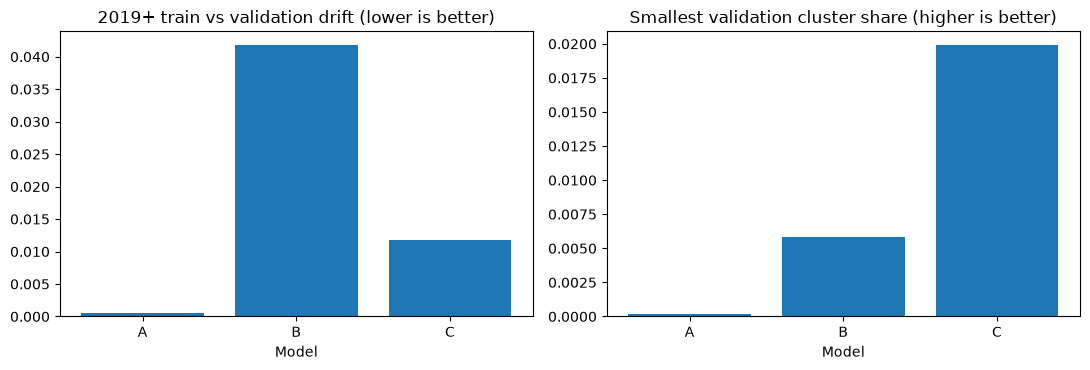

In [53]:
# Compare all three fitted models on a COMMON 2019+ train cohort and common validation window.
# Also audit cluster meaning; a split by empty review bodies is NOT a satisfactory solution.

def _abc_profile(frame, labels, name, partition, k):
    body = frame['cleaned_body'].fillna('').astype(str)
    title = frame['cleaned_title'].fillna('').astype(str)
    work = pd.DataFrame({
        'cluster':np.asarray(labels, dtype=int),
        'body_available':body.ne('').astype(float).to_numpy(),
        'body_words':body.str.findall(r'\b\w+\b').str.len().to_numpy(),
        'original_full_review_words':(title + ' ' + body).str.findall(r'\b\w+\b').str.len().to_numpy(),
        'rating':pd.to_numeric(frame['rating_num'], errors='coerce').to_numpy(),
        'five_stars_title':title.str.contains(r'\bfive\s+stars\b', case=False, regex=True).astype(float).to_numpy(),
        'product_prior':pd.to_numeric(frame['product_prior_review_count'], errors='coerce').to_numpy(),
    })
    g = work.groupby('cluster')
    sizes = g.size().reindex(range(k), fill_value=0)
    out = pd.DataFrame({'model':name, 'partition':partition,
                        'cluster':np.arange(k), 'n':sizes.to_numpy(),
                        'share':sizes.to_numpy()/len(work)})
    for feature, newname, op in [
        ('body_available','body_available_rate','mean'),
        ('body_words','median_body_words','median'),
        ('original_full_review_words','median_original_full_review_words','median'),
        ('rating','median_rating','median'),
        ('five_stars_title','five_stars_title_rate','mean'),
        ('product_prior','median_product_prior_count','median')
    ]:
        out[newname] = getattr(g[feature], op)().reindex(range(k)).to_numpy()
    return out

abc_profiles = []
abc_summary_rows = []
abc_pair_labels = {}

for _name, _m in abc_models.items():
    _k = _m['k']
    _lab_fit = _m['train_labels']
    _lab_val = _m['val_labels']
    _fit_profile = _abc_profile(_m['train_frame'], _lab_fit, _name, 'model_fit_train', _k)
    _validation_profile = _abc_profile(validation_features, _lab_val, _name, 'validation', _k)
    if _name == 'A':
        _lab_recent = _lab_fit[_abc_recent_indices]
    elif _name == 'B':
        _lab_recent = _lab_fit[_abc_recent_indices]
    else:
        _lab_recent = _lab_fit
    _recent_profile = _abc_profile(train_features.iloc[_abc_recent_indices],
                                   _lab_recent, _name, 'common_2019plus_train', _k)
    abc_profiles.extend([_fit_profile, _recent_profile, _validation_profile])
    _fit_shares = _abc_share(_lab_fit, _k)
    _recent_shares = _abc_share(_lab_recent, _k)
    _validation_shares = _abc_share(_lab_val, _k)
    _candidates = abc_k_candidates.loc[abc_k_candidates['model'].eq(_name)].set_index('k')
    _s = _candidates.loc[_k]
    # Repeat scaling sensitivity on the SAME-size train-only search sample for all three models.
    if _name == 'A':
        _sel_x = X_selection
    else:
        _sel_x = _m['X_select']
    _sel_labels = KMeans(n_clusters=_k, random_state=SEED, n_init=10).fit_predict(_sel_x)
    _sel_scaled = StandardScaler().fit_transform(np.asarray(_sel_x))
    _scaled_labels = KMeans(n_clusters=_k, random_state=SEED, n_init=10).fit_predict(_sel_scaled)
    _scaling_ari = float(adjusted_rand_score(_sel_labels, _scaled_labels))
    _substable = evaluate_subsample_stability(
        _m['X_train'], k=_k, baseline_model=_m['kmeans'],
        fractions=(0.70,0.85), seeds=(SEED,SEED+11), reference_size=2_000,
        n_init=8,
    )
    _body_min = float(_fit_profile['body_available_rate'].min())
    _warning = bool(_m['text_mode']=='body only' and _body_min < ABC_MIN_BODY_AVAILABLE_IN_CLUSTER)
    abc_pair_labels[_name] = _lab_val
    abc_summary_rows.append({
        'model':_name, 'text_representation':_m['text_mode'],
        'train_period':'2019+ training only' if _name=='C' else 'all training years',
        'train_rows':len(_lab_fit), 'selected_k':_k,
        'train_silhouette_selection_sample':float(_s['silhouette']),
        'seed_stability_ari_selection_sample':float(_s['seed_stability_ari']),
        'subsample_ari_mean':float(_substable['ari_vs_full_training_solution'].mean()),
        'svd_scaling_ari_selection_sample':_scaling_ari,
        'min_fit_train_cluster_share':float(_fit_shares.min()),
        'min_common_recent_train_cluster_share':float(_recent_shares.min()),
        'min_validation_cluster_share':float(_validation_shares.min()),
        'fit_train_vs_validation_TV':_abc_tv(_fit_shares,_validation_shares),
        'common_recent_train_vs_validation_TV':_abc_tv(_recent_shares,_validation_shares),
        'min_fit_cluster_body_available_rate':_body_min,
        'body_missing_cluster_risk':_warning,
    })

abc_cluster_profiles = pd.concat(abc_profiles, ignore_index=True)
abc_model_comparison = pd.DataFrame(abc_summary_rows)

# Interpret *what* clusters contain, not only how evenly they split over time.
# Vocabulary and TF-IDF averages are learned within each model's own TRAIN cohort.
_abc_distinctive_terms = []
_abc_category_mixtures = []
for _name, _model in abc_models.items():
    _tfidf_pipeline = dict(_model['pipeline'].transformer_list)['text']
    _vectorizer = _tfidf_pipeline.named_steps['tfidf']
    _text_matrix = _vectorizer.transform(
        _model['train_frame']['cleaned_text'].fillna('').astype(str)
    )
    _term_table = distinctive_terms_by_cluster(
        _text_matrix, _model['train_labels'], _vectorizer, top_n=8
    )
    _term_table.insert(0, 'model', _name)
    _abc_distinctive_terms.append(_term_table)
    _category_table = cluster_category_mix(
        _model['train_frame'], _model['train_labels'], category_column='dataset_category'
    )
    _category_table.insert(0, 'model', _name)
    _abc_category_mixtures.append(_category_table)
abc_distinctive_terms = pd.concat(_abc_distinctive_terms, ignore_index=True)
abc_category_mix = pd.concat(_abc_category_mixtures, ignore_index=True)


# Predeclared diagnostic thresholds. No outcome labels or TEST assignments influence these.
abc_model_comparison['passes_internal_checks'] = (
    abc_model_comparison['min_fit_train_cluster_share'].ge(ABC_MIN_TRAIN_SHARE)
    & abc_model_comparison['seed_stability_ari_selection_sample'].ge(ABC_MIN_SEED_ARI)
    & abc_model_comparison['train_silhouette_selection_sample'].ge(ABC_MIN_TRAIN_SILHOUETTE)
    & ~abc_model_comparison['body_missing_cluster_risk']
)
abc_model_comparison['passes_temporal_checks'] = (
    abc_model_comparison['min_common_recent_train_cluster_share'].ge(ABC_MIN_RECENT_SHARE)
    & abc_model_comparison['min_validation_cluster_share'].ge(ABC_MIN_VALIDATION_SHARE)
    & abc_model_comparison['common_recent_train_vs_validation_TV'].le(ABC_MAX_RECENT_TO_VALIDATION_TV)
)
abc_model_comparison['passes_preliminary_checks'] = (
    abc_model_comparison['passes_internal_checks']
    & abc_model_comparison['passes_temporal_checks']
)

print('Complete model comparison (TRAIN/VALIDATION only):')
display(abc_model_comparison.round(4))
print('Per-cluster meaning and body-availability audits (train, recent train, validation):')
display(abc_cluster_profiles.round(4))

abc_validation_ari = pd.DataFrame([
    {'model_1':a, 'model_2':b,
     'validation_ari':float(adjusted_rand_score(abc_pair_labels[a],abc_pair_labels[b]))}
    for a,b in [('A','B'),('A','C'),('B','C')]
])
print('Distinctive terms within each MODEL TRAIN cohort (more diagnostic than generic top words):')
display(abc_distinctive_terms[['model','cluster','rank','term','difference']].round(4))
print('Training cluster category composition:')
display(abc_category_mix.round(4))
print('Between-model assignment agreement on the SAME validation rows:')
display(abc_validation_ari.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for _ax, _metric, _title in [
    (axes[0], 'common_recent_train_vs_validation_TV', '2019+ train vs validation drift (lower is better)'),
    (axes[1], 'min_validation_cluster_share', 'Smallest validation cluster share (higher is better)'),
]:
    _ax.bar(abc_model_comparison['model'], abc_model_comparison[_metric])
    _ax.set_title(_title)
    _ax.set_xlabel('Model')
    _ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'phase2_ABC_temporal_comparison.png', dpi=150)
plt.show()


### 8.8a Model decision and one-time chronological test audit

The choice below uses **only training diagnostics and validation-feature comparisons**. A candidate must (i) have usable train clusters, (ii) show reasonably stable seeds and train silhouette, (iii) represent at least 1% of both the *common 2019+ training cohort* and validation in each cluster, (iv) have no worse than 0.10 total-variation distance between those cohort distributions, and (v) avoid a body-only split driven by mostly empty bodies. Thresholds are practical **diagnostic safeguards**, not formal proof or course requirements.

If multiple pass, prefer the lowest 2019+-train/validation drift; silhouette is a tiebreaker. **If none pass, leave the reference model unchanged and report the unresolved problem** rather than presenting an unstable candidate as a fix. *Scaling sensitivity remains an independently reported limitation regardless of the decision.*

Only the selected candidate receives a **single target-free test-period audit** (cluster assignments and feature-based proportions). No helpful votes from the test period are read, and test results must not be used to retune/reselect the model.


In [54]:
_abc_qualified = abc_model_comparison.loc[
    abc_model_comparison['passes_preliminary_checks']
].sort_values(
    ['common_recent_train_vs_validation_TV','train_silhouette_selection_sample','model'],
    ascending=[True,False,True]
)
ABC_PREFERRED_MODEL = str(_abc_qualified.iloc[0]['model']) if len(_abc_qualified) else None
ABC_DECISION_STATUS = ('best A/B/C candidate under INTERNAL + TEMPORAL checks ONLY; '
                       'SVD-axis scaling robustness is not part of those checks'
                       if ABC_PREFERRED_MODEL else
                       'no A/B/C candidate passes the preliminary internal/temporal safeguards')
# Report the stress test independently; do not silently promote a sensitive model.
ABC_PREFERRED_SCALING_ARI = (float(abc_model_comparison.set_index('model').loc[
    ABC_PREFERRED_MODEL, 'svd_scaling_ari_selection_sample'])
    if ABC_PREFERRED_MODEL is not None else np.nan)
ABC_PREFERRED_SCALING_SENSITIVE = bool(
    np.isfinite(ABC_PREFERRED_SCALING_ARI) and ABC_PREFERRED_SCALING_ARI < .65)
if ABC_PREFERRED_SCALING_SENSITIVE:
    ABC_DECISION_STATUS += '; CAUTION: alternative SVD-axis scaling changes clusters substantially'

# The older notebook performed a one-time target-free TEST audit of C.
# Do not repeat TEST checks while introducing/tuning further candidates D and E.
abc_selected_test_profile = pd.DataFrame()
abc_selected_assignments = pd.DataFrame(
    columns=['sample_row_id','dataset_category','timestamp_dt','model','cluster']
)
print('Preferred candidate:', ABC_PREFERRED_MODEL if ABC_PREFERRED_MODEL else 'none')
print('Decision:', ABC_DECISION_STATUS)
print('Reference model A is retained as the baseline whether or not a candidate passes.')
if len(abc_selected_test_profile):
    print('Single one-time TEST check of the preferred candidate (TARGET-FREE):')
    display(abc_selected_test_profile.round(4))
    if abc_selected_test_profile['share'].min() < 0.01:
        print('CAUTION: a cluster is below 1% in TEST. This is an observed limit; do NOT retune using TEST.')
else:
    print('TEST audit deferred: no further TEST use while comparing alternative representations.')

print('Preferred A/B/C SVD-axis scaling ARI:', ABC_PREFERRED_SCALING_ARI)


Preferred candidate: C
Decision: best A/B/C candidate under INTERNAL + TEMPORAL checks ONLY; SVD-axis scaling robustness is not part of those checks; CAUTION: alternative SVD-axis scaling changes clusters substantially
Reference model A is retained as the baseline whether or not a candidate passes.
TEST audit deferred: no further TEST use while comparing alternative representations.
Preferred A/B/C SVD-axis scaling ARI: -0.0010350023945099494


### 8.9 Behavior-aware clustering: addressing scaling instability **and** research relevance

The A/B/C comparisons showed that the original K-means mostly separated historic formulaic titles, while recent body-only Model C separated generic short reviews. The latter had poor agreement when **all SVD axes were independently standardized**, a strong change of distance geometry.

This new controlled experiment uses the **same 2019+ training cohort as C**, and the unchanged validation split. It compares:

- **D — behavior + limited text semantics:** rating disagreement with *past* product ratings, reviewer/product history, repeated body text within a product, review details, verification and image presence, plus a smaller body-text topic block.
- **E — behavior only:** exactly the same behavioral representation, but without TF-IDF. This tests whether text is necessary to reveal the behavior groups.

**Design safeguards:** no `helpful_vote` inputs; no customer/product identifier as a feature; no raw publication year or review-age proxy; no use of test rows or targets to choose the new models; same-timestamp events are excluded from historical statistics. Product rating history and repeated-body history are **sample-limited proxies**. Validation history is frozen to the full training partition.

**Scaling fix:** numerical predictors are transformed by training-fitted quantile ranks; numeric, categorical and text components are separately normalized and deliberately weighted. TF-IDF is reduced **on its own**, rather than jointly reducing and then blindly standardizing a heterogeneous fused SVD. Numeric-unit invariance and ±20% feature-block weighting are tested explicitly. None of these choices guarantees stable, meaningful patterns; the measured results decide.

In [55]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

BR_K_VALUES = tuple(k for k in (2,3,4,5,6) if k in ABC_K_VALUES)
BR_TEXT_COMPONENTS = 16
BR_MIN_VAL_SHARE = 0.01
BR_MAX_TEMPORAL_TV = 0.10
BR_MIN_SEED_ARI = 0.70
BR_MIN_WEIGHT_ARI = 0.65
BR_MIN_SILHOUETTE = 0.03
BR_MAX_LENGTH_ONLY_ARI = 0.80
BR_MIN_INDEPENDENT_BEHAVIOR_AXES = 2
BR_MODELS = {'D': {'num':1.0, 'cat':0.60, 'text':0.35},
             'E': {'num':1.0, 'cat':0.60, 'text':0.00}}

# Rating context is taken only from training timestamps STRICTLY earlier than the query.
# For validation, reference_events consists of TRAIN rows only (frozen history).
def _br_prior_product_ratings(reference_events, query):
    keys = ['dataset_category','_join_key']
    h = reference_events[keys + ['timestamp_dt','rating_num']].copy()
    h['timestamp_dt'] = pd.to_datetime(h['timestamp_dt'], utc=True, errors='coerce')
    h['rating_num'] = pd.to_numeric(h['rating_num'], errors='coerce')
    h = h.loc[h['timestamp_dt'].notna() & h[keys].notna().all(axis=1) & h['rating_num'].between(1,5)]
    summary = h.groupby(keys+['timestamp_dt'],sort=False).agg(
        rating_sum=('rating_num','sum'), rating_count=('rating_num','size')).reset_index()
    summary = summary.sort_values(keys+['timestamp_dt']).copy()
    summary['sum_through_ts'] = summary.groupby(keys,sort=False)['rating_sum'].cumsum()
    summary['n_through_ts'] = summary.groupby(keys,sort=False)['rating_count'].cumsum()
    summary = summary[keys+['timestamp_dt','sum_through_ts','n_through_ts']].sort_values('timestamp_dt')
    q = query[keys+['timestamp_dt']].copy()
    q['timestamp_dt'] = pd.to_datetime(q['timestamp_dt'], utc=True, errors='coerce')
    q['_position'] = np.arange(len(q))
    q = q.loc[q['timestamp_dt'].notna() & q[keys].notna().all(axis=1)].sort_values('timestamp_dt')
    n = np.zeros(len(query), dtype=float)
    means = np.full(len(query), np.nan)
    if len(q) and len(summary):
        match = pd.merge_asof(q, summary, on='timestamp_dt',by=keys,
            direction='backward',allow_exact_matches=False)
        pos = match['_position'].to_numpy(dtype=int)
        n[pos] = match['n_through_ts'].fillna(0).to_numpy(dtype=float)
        valid = match['n_through_ts'].ge(3)
        means[pos[valid.to_numpy()]] = (
            match.loc[valid,'sum_through_ts'] / match.loc[valid,'n_through_ts']
        ).to_numpy(dtype=float)
    return n, means

# Exact normalized same-body text previously observed on the SAME product, using training records.
def _br_prior_exact_body_reuse(reference_events, query):
    keys = ['dataset_category','_join_key','_body_norm']
    def prepared(frame):
        f = frame[['dataset_category','_join_key','timestamp_dt','cleaned_body']].copy()
        f['_body_norm'] = (f['cleaned_body'].fillna('').astype(str).str.casefold()
                           .str.replace(r'\s+', ' ',regex=True).str.strip())
        f['timestamp_dt'] = pd.to_datetime(f['timestamp_dt'],utc=True,errors='coerce')
        return f.drop(columns='cleaned_body')
    h = prepared(reference_events)
    h = h.loc[h['timestamp_dt'].notna() & h[['dataset_category','_join_key']].notna().all(axis=1)
              & h['_body_norm'].ne('')]
    summary = h.groupby(keys+['timestamp_dt'],sort=False).size().rename('num_at_ts').reset_index()
    summary = summary.sort_values(keys+['timestamp_dt'])
    summary['count_through_ts'] = summary.groupby(keys,sort=False)['num_at_ts'].cumsum()
    summary = summary[keys+['timestamp_dt','count_through_ts']].sort_values('timestamp_dt')
    q = prepared(query)
    q['_position'] = np.arange(len(q))
    q = q.loc[q['timestamp_dt'].notna() & q[['dataset_category','_join_key']].notna().all(axis=1)
              & q['_body_norm'].ne('')].sort_values('timestamp_dt')
    counts = np.zeros(len(query),dtype=float)
    if len(q) and len(summary):
        match = pd.merge_asof(q, summary,on='timestamp_dt',by=keys,
                             direction='backward',allow_exact_matches=False)
        counts[match['_position'].to_numpy(dtype=int)] = match['count_through_ts'].fillna(0).to_numpy(dtype=float)
    return counts

def make_behavior_frame(frame, reference_train):
    """Review-level feature values. Fit statistics still occur later on TRAIN only."""
    out = make_body_only_feature_frame(frame)
    n, prior_mean = _br_prior_product_ratings(reference_train, out)
    out['prior_product_ratings_n'] = n
    out['rating_gap_from_prior_product'] = np.abs(pd.to_numeric(out['rating_num'],errors='coerce') - prior_mean)
    out['rating_context_status'] = np.where(n>=3,'>=3 sampled prior ratings','insufficient history')
    out['prior_product_exact_body_count'] = _br_prior_exact_body_reuse(reference_train, out)
    out['log1p_prior_product_exact_body_count'] = np.log1p(out['prior_product_exact_body_count'])
    # Preserve only one (log-transformed) body-length feature; avoid multiplying its weight.
    out['log1p_body_word_count'] = np.log1p(out['text_word_count'].clip(lower=0))
    out['exclamation_count'] = out['exclamation_count'].clip(upper=5)
    out['question_count'] = out['question_count'].clip(upper=5)
    return out

br_train = make_behavior_frame(abc_recent_train, train_features)
br_val = make_behavior_frame(abc_body_validation, train_features)
BR_NUMERIC = [
    'rating_num','rating_gap_from_prior_product',
    'log1p_body_word_count', 'log1p_reviewer_prior_review_count',
    'log1p_product_prior_review_count','log1p_user_product_prior_interaction_count',
    'log1p_prior_product_exact_body_count','uppercase_ratio','non_ascii_ratio',
    'exclamation_count','question_count',
]
BR_CATEGORICAL = ['dataset_category','verified_purchase_status','review_image_available',
                  'rating_context_status']
assert not (set(BR_NUMERIC+BR_CATEGORICAL) & {'helpful_vote','helpful_vote_num','review_year',
          'review_age_days_proxy','user_id','parent_asin','asin','_join_key','title'})
assert len(br_train)==len(abc_recent_train) and len(br_val)==len(validation_features)
assert (br_train['prior_product_exact_body_count']>=0).all()
print('Behavior-aware cohort:',len(br_train),'training and',len(br_val),'validation rows')
print('Available rating-context fraction (train/validation):',
      round(float(br_train['rating_gap_from_prior_product'].notna().mean()),3),
      round(float(br_val['rating_gap_from_prior_product'].notna().mean()),3))
print('Rows with previously repeated product-body text (train/validation):',
      int(br_train['prior_product_exact_body_count'].gt(0).sum()),
      int(br_val['prior_product_exact_body_count'].gt(0).sum()))

Behavior-aware cohort: 14256 training and 11998 validation rows
Available rating-context fraction (train/validation): 0.332 0.274
Rows with previously repeated product-body text (train/validation): 21 8


### 8.9a Train-only block preprocessing, independent model fitting and K selection

**Why block-level weighting?** K-means is sensitive to distances. Instead of trusting arbitrary SVD-axis standard deviations, numerical ranks, categorical encodings, and 16 semantic body-text components each get an independent unit-length representation. Model D uses text only as a modest additional signal; E removes it. Numeric QuantileTransformer preserves ranks and is invariant to positive changes of measurement units when refit consistently. This does **not** make assignments invariant to arbitrary feature-weight or representation changes; those are tested next.

In [56]:
def _br_choose_k(X,name,k_values=None):
    """TRAIN-only K choice on this candidate's own representation (independent of A/B/C)."""
    rng=np.random.default_rng(SEED+719)
    n=min(ABC_SELECTION_ROWS,X.shape[0])
    select_index=np.sort(rng.choice(X.shape[0],size=n,replace=False))
    xs=X[select_index]
    possible=[k for k in (BR_K_VALUES if k_values is None else k_values) if 2<=k<xs.shape[0]]
    if not possible: raise ValueError('Not enough training rows for behavior-first K search.')
    cand=evaluate_kmeans_candidates(xs,k_values=possible,random_state=SEED,n_init=10,
              max_fit_rows=xs.shape[0],silhouette_sample_size=min(ABC_SILHOUETTE_ROWS,n))
    rows=[]
    for k in possible:
        d=evaluate_seed_stability(xs,k=k,seeds=ABC_SEED_VALUES,n_init=8)
        rows.append({'k':k,'seed_stability_ari':d['mean_pairwise_ari']})
    cand=cand.merge(pd.DataFrame(rows),on='k')
    for col, metric in [('silhouette_rank','silhouette'),
                        ('stability_rank','seed_stability_ari'),
                        ('balance_rank','smallest_cluster_fraction')]:
        cand[col]=cand[metric].rank(pct=True)
    cand['selection_score']=(0.5*cand.silhouette_rank+0.35*cand.stability_rank+0.15*cand.balance_rank)
    chosen=int(cand.sort_values(['selection_score','seed_stability_ari','k'],
                                ascending=[False,False,True]).iloc[0].k)
    cand['model']=name
    return chosen,cand,xs


def _br_encoder():
    try: return OneHotEncoder(handle_unknown='ignore',sparse_output=True)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=True)

def _br_fit_blocks(frame):
    numeric = Pipeline([
        ('imputer',SimpleImputer(strategy='median')),
        ('rank',QuantileTransformer(n_quantiles=min(256,len(frame)),
             output_distribution='uniform',random_state=SEED)),
    ])
    category = Pipeline([
        ('imputer',SimpleImputer(strategy='constant',fill_value='__MISSING__')),
        ('onehot',_br_encoder()),
    ])
    X_num = normalize(sparse.csr_matrix(numeric.fit_transform(frame[BR_NUMERIC])))
    X_cat = normalize(sparse.csr_matrix(category.fit_transform(frame[BR_CATEGORICAL])))
    return numeric, category, X_num, X_cat

def _br_transform_blocks(frame, numeric, category):
    num = normalize(sparse.csr_matrix(numeric.transform(frame[BR_NUMERIC])))
    cat = normalize(sparse.csr_matrix(category.transform(frame[BR_CATEGORICAL])))
    return num, cat

def _br_combine(blocks, weights):
    n,c,t = blocks
    parts = [n.multiply(weights['num']),c.multiply(weights['cat'])]
    if weights['text'] > 0: parts.append(t.multiply(weights['text']))
    return normalize(sparse.hstack(parts,format='csr'),copy=False)

br_numeric_transformer,br_categorical_transformer,br_num_train,br_cat_train = _br_fit_blocks(br_train)
br_num_val,br_cat_val = _br_transform_blocks(br_val,br_numeric_transformer,br_categorical_transformer)

br_tfidf = TfidfVectorizer(lowercase=True,strip_accents='unicode',ngram_range=(1,2),
        min_df=TFIDF_MIN_DF,max_df=0.98,max_features=MAX_TFIDF_FEATURES,sublinear_tf=True)
br_tfidf_train = br_tfidf.fit_transform(br_train['cleaned_body'].fillna('').astype(str))
br_tfidf_val = br_tfidf.transform(br_val['cleaned_body'].fillna('').astype(str))
br_text_svd = TruncatedSVD(n_components=min(BR_TEXT_COMPONENTS,br_tfidf_train.shape[1]-1,
                                br_tfidf_train.shape[0]-1),random_state=SEED)
br_text_train = normalize(sparse.csr_matrix(br_text_svd.fit_transform(br_tfidf_train)))
br_text_val = normalize(sparse.csr_matrix(br_text_svd.transform(br_tfidf_val)))
br_blocks_train = (br_num_train,br_cat_train,br_text_train)
br_blocks_val = (br_num_val,br_cat_val,br_text_val)

br_models = {}
br_k_search = []
for name,weights in BR_MODELS.items():
    X_fit = _br_combine(br_blocks_train,weights)
    X_val = _br_combine(br_blocks_val,weights)
    chosen,candidates,X_select = _br_choose_k(X_fit,name)
    fit_model = KMeans(n_clusters=chosen,random_state=SEED,n_init=20)
    train_labels = fit_model.fit_predict(X_fit)
    val_labels = fit_model.predict(X_val)
    br_models[name] = {'weights':weights.copy(),'k':chosen,'model':fit_model,
        'X_train':X_fit,'X_val':X_val,'train_labels':train_labels,'val_labels':val_labels,
        'X_select':X_select,'candidates':candidates}
    br_k_search.append(candidates)
    print(f'Model {name}: selected k={chosen}; rows={len(train_labels):,}; '
          f'validation={len(val_labels):,}; text_weight={weights["text"]}')
br_k_search = pd.concat(br_k_search,ignore_index=True)
display(br_k_search[['model','k','silhouette','seed_stability_ari',
                     'smallest_cluster_fraction','selection_score']].round(4))

Model D: selected k=2; rows=14,256; validation=11,998; text_weight=0.35
Model E: selected k=3; rows=14,256; validation=11,998; text_weight=0.0


,model,k,silhouette,seed_stability_ari,smallest_cluster_fraction,selection_score
0,D,2,0.1842,0.9998,0.3001,0.860
1,D,3,0.1780,1.0000,0.2617,0.835
2,D,4,0.1718,1.0000,0.1275,0.605
3,D,5,0.1747,0.7856,0.1091,0.400
4,D,6,0.1565,0.9994,0.1265,0.300
5,E,2,0.1963,0.9994,0.3903,0.460
6,E,3,0.2158,1.0000,0.2614,0.770
7,E,4,0.2152,0.9997,0.1279,0.555
8,E,5,0.2307,0.9992,0.1279,0.615
9,E,6,0.2368,0.7797,0.0878,0.600


### 8.9b Stability: train-only initializations, **numeric-unit invariance**, weight perturbations, and validation drift

- **Numeric units:** multiply two numeric input features by positive constants, refit the *numeric rank preprocessing*, then independently refit K-means. The resulting assignments should remain nearly unchanged.
- **Block weights:** increase/decrease the categorical contribution by 20%; for D, also increase/decrease text contribution by 20%. These are meaningful changes to distance geometry, so low ARI indicates **remaining sensitivity**.
- **Temporal drift:** compare the same fitted model's train and validation cluster proportions. A small share difference alone is not proof of stable cluster *meaning*.
- A/B/C's SVD-axis standardization remains a historical stress test; D/E no longer run a single mixed-modality SVD whose axes could be arbitrarily reweighted.

In [57]:
def _br_cluster_profile(frame, labels, name, partition):
    df = pd.DataFrame(index=np.arange(len(frame)))
    df['cluster'] = np.asarray(labels,dtype=int)
    words = pd.to_numeric(frame['text_word_count'],errors='coerce').to_numpy()
    gap = pd.to_numeric(frame['rating_gap_from_prior_product'],errors='coerce').to_numpy()
    df['body_words'] = words
    df['rating'] = pd.to_numeric(frame['rating_num'],errors='coerce').to_numpy()
    df['rating_gap'] = gap
    df['rating_gap_ge2'] = np.where(np.isfinite(gap),(gap>=2).astype(float),np.nan)
    df['rating_history_known'] = np.isfinite(gap).astype(float)
    df['prior_product_count'] = pd.to_numeric(frame['product_prior_review_count'],errors='coerce').to_numpy()
    df['prior_reviewer_count'] = pd.to_numeric(frame['reviewer_prior_review_count'],errors='coerce').to_numpy()
    df['prior_reviewer_any'] = (df['prior_reviewer_count']>0).astype(float)
    df['prior_product_any'] = (df['prior_product_count']>0).astype(float)
    df['prior_reuse_any'] = (pd.to_numeric(frame['prior_product_exact_body_count'],errors='coerce').to_numpy()>0).astype(float)
    df['prior_user_product_any'] = (pd.to_numeric(frame['user_product_prior_interaction_count'],errors='coerce').to_numpy()>0).astype(float)
    df['verified'] = frame['verified_purchase_status'].eq('verified').to_numpy(dtype=float)
    df['review_image'] = frame['review_image_available'].eq('yes').to_numpy(dtype=float)
    df['very_short_body'] = (words<=5).astype(float)
    g=df.groupby('cluster')
    prof=g.agg(n=('cluster','size'),median_words=('body_words','median'),
        median_rating=('rating','median'),median_prior_product=('prior_product_count','median'),
        median_prior_reviewer=('prior_reviewer_count','median'),
        rating_context_coverage=('rating_history_known','mean'),
        high_rating_disagreement_rate=('rating_gap_ge2','mean'),
        prior_body_reuse_rate=('prior_reuse_any','mean'),
        repeated_user_product_rate=('prior_user_product_any','mean'),
        prior_reviewer_rate=('prior_reviewer_any','mean'),
        prior_product_rate=('prior_product_any','mean'),
        verified_rate=('verified','mean'),review_image_rate=('review_image','mean'),
        very_short_body_rate=('very_short_body','mean')).reset_index()
    prof.insert(0,'partition',partition);prof.insert(0,'model',name)
    prof['share'] = prof['n']/max(1,len(df))
    return prof,df

br_profiles=[];br_robustness_rows=[];br_weight_tests=[]
for name,model in br_models.items():
    weights=model['weights'];k=model['k']
    ptrain,raw_train = _br_cluster_profile(br_train,model['train_labels'],name,'2019+ train')
    pval,_ = _br_cluster_profile(br_val,model['val_labels'],name,'validation')
    br_profiles.extend([ptrain,pval])
    # Train-fitted quantile ranks should ignore positive re-expression of units.
    perturb=br_train.copy()
    perturb['log1p_body_word_count'] *= 10
    perturb['log1p_product_prior_review_count'] *= 0.1
    num_alt = Pipeline([
        ('imputer',SimpleImputer(strategy='median')),
        ('rank',QuantileTransformer(n_quantiles=min(256,len(perturb)),
              output_distribution='uniform',random_state=SEED))
    ])
    num_scaled = normalize(sparse.csr_matrix(num_alt.fit_transform(perturb[BR_NUMERIC])))
    unit_X = _br_combine((num_scaled,br_cat_train,br_text_train),weights)
    unit_labels=KMeans(n_clusters=k,random_state=SEED,n_init=20).fit_predict(unit_X)
    unit_ari=float(adjusted_rand_score(model['train_labels'],unit_labels))
    br_weight_tests.append({'model':name,'perturbation':'numeric_unit_rescaling','ari':unit_ari})
    for wkey in (['cat','text'] if weights['text'] else ['cat']):
        for multiplier in (0.8,1.2):
            w=weights.copy();w[wkey]*=multiplier
            new_X=_br_combine(br_blocks_train,w)
            changed_labels=KMeans(n_clusters=k,random_state=SEED,n_init=20).fit_predict(new_X)
            br_weight_tests.append({'model':name,'perturbation':f'{wkey}_weight_x{multiplier}',
                 'ari':float(adjusted_rand_score(model['train_labels'],changed_labels))})
    select=model['candidates'].set_index('k').loc[k]
    train_shares=_abc_share(model['train_labels'],k)
    val_shares=_abc_share(model['val_labels'],k)
    # A basic warning if partitions are merely the very-short-text split.
    short_flag=(br_train['text_word_count'].le(5)).to_numpy(dtype=int)
    length_ari=float(adjusted_rand_score(short_flag,model['train_labels']))
    br_robustness_rows.append({'model':name,'k':k,'train_rows':len(br_train),
        'silhouette':float(select['silhouette']),
        'seed_ari':float(select['seed_stability_ari']),
        'train_min_cluster_share':float(train_shares.min()),
        'validation_min_cluster_share':float(val_shares.min()),
        'train_validation_TV':_abc_tv(train_shares,val_shares),
        'length_only_ari':length_ari,
        'unit_rescaling_ari':unit_ari})

br_cluster_profiles=pd.concat(br_profiles,ignore_index=True)
br_weight_sensitivity=pd.DataFrame(br_weight_tests)
br_model_comparison=pd.DataFrame(br_robustness_rows)
br_min_weight_ari=(br_weight_sensitivity[br_weight_sensitivity.perturbation.ne('numeric_unit_rescaling')]
                   .groupby('model')['ari'].min())
br_model_comparison['minimum_weight_perturbation_ari']=(br_model_comparison['model'].map(br_min_weight_ari))

# Behavioral domains are grouped conceptually; they are NOT statistically independent.
# Rating disagreement is defined only within sufficient prior-rating history and is
# evaluated there, then grouped with product-history context rather than double-counted.
BR_BEHAVIOR_DOMAIN_MAP = {
    'rating_disagreement': ('product_rating_context', 'rating_gap_ge2'),
    'product_history': ('product_rating_context', 'prior_product_any'),
    'repeated_body': ('repeated_content', 'prior_reuse_any'),
    'repeated_user_product': ('reviewer_product_interaction', 'prior_user_product_any'),
    'reviewer_history': ('reviewer_history', 'prior_reviewer_any'),
    'verified_purchase': ('verification', 'verified'),
    'customer_image': ('customer_image', 'review_image'),
}
br_distinctive = []
for name in br_models:
    _, detail = _br_cluster_profile(br_train, br_models[name]['train_labels'], name, '2019+ train')
    for cluster in sorted(detail.cluster.unique()):
        inside_all = detail.loc[detail.cluster.eq(cluster)]
        outside_all = detail.loc[detail.cluster.ne(cluster)]
        for feature, (domain, source) in BR_BEHAVIOR_DOMAIN_MAP.items():
            inside, outside = inside_all, outside_all
            if feature == 'rating_disagreement':
                # Condition on rating context, without treating its absence as disagreement=0.
                inside = inside.loc[inside.rating_history_known.eq(1)]
                outside = outside.loc[outside.rating_history_known.eq(1)]
            x = inside[source].dropna()
            y = outside[source].dropna()
            valid = len(x) >= 30 and len(y) >= 30
            delta = float(x.mean()-y.mean()) if valid else np.nan
            br_distinctive.append({'model':name,'cluster':int(cluster),
                'feature':feature,'domain':domain,
                'inside_eligible_n':len(x),'outside_eligible_n':len(y),
                'rate_inside':float(x.mean()) if len(x) else np.nan,
                'rate_outside':float(y.mean()) if len(y) else np.nan,
                'percentage_point_difference':100*delta if valid else np.nan,
                'substantive_difference':bool(valid and abs(delta)>=0.08)})
br_behavioral_distinctiveness = pd.DataFrame(br_distinctive)
# Count each DOMAIN at most once per cluster, not correlated raw features twice.
_domain_counts=(br_behavioral_distinctiveness.loc[br_behavioral_distinctiveness.substantive_difference]
    .groupby(['model','cluster'])['domain'].nunique()
    .groupby('model').max())
br_model_comparison['max_distinct_behavior_domains']=(
    br_model_comparison.model.map(_domain_counts).fillna(0).astype(int))
br_model_comparison['max_independent_behavior_domains'] = br_model_comparison['max_distinct_behavior_domains']
# Backwards-compatible column alias only; distinct does NOT mean statistically independent.

br_model_comparison['passes_scaling_checks']=(
    br_model_comparison.unit_rescaling_ari.ge(0.95) &
    br_model_comparison.minimum_weight_perturbation_ari.ge(BR_MIN_WEIGHT_ARI))
br_model_comparison['passes_cluster_checks']=(
    br_model_comparison.silhouette.ge(BR_MIN_SILHOUETTE) &
    br_model_comparison.seed_ari.ge(BR_MIN_SEED_ARI) &
    br_model_comparison.train_min_cluster_share.ge(0.01) &
    br_model_comparison.validation_min_cluster_share.ge(BR_MIN_VAL_SHARE) &
    br_model_comparison.train_validation_TV.le(BR_MAX_TEMPORAL_TV) &
    br_model_comparison.length_only_ari.lt(BR_MAX_LENGTH_ONLY_ARI))
br_model_comparison['passes_behavioral_relevance_check']=(
    br_model_comparison.max_distinct_behavior_domains.ge(BR_MIN_INDEPENDENT_BEHAVIOR_AXES))
br_model_comparison['passes_all_diagnostic_checks']=(
    br_model_comparison.passes_scaling_checks & br_model_comparison.passes_cluster_checks &
    br_model_comparison.passes_behavioral_relevance_check)
print('Behavior-first model comparison (no helpful votes or TEST rows used):')
display(br_model_comparison.round(4))
print('Perturbation ARI:')
display(br_weight_sensitivity.round(4))
print('Cluster interpretation on train and validation:')
display(br_cluster_profiles.round(4))
print('Top behavioral rate differences versus the OTHER clusters (TRAIN only):')
display(br_behavioral_distinctiveness.sort_values(
    ['model','cluster','substantive_difference','percentage_point_difference'],
    ascending=[True,True,False,False]).groupby(['model','cluster']).head(4).round(3))

Behavior-first model comparison (no helpful votes or TEST rows used):


,model,k,train_rows,silhouette,seed_ari,train_min_cluster_share,validation_min_cluster_share,train_validation_TV,length_only_ari,unit_rescaling_ari,minimum_weight_perturbation_ari,max_distinct_behavior_domains,max_independent_behavior_domains,passes_scaling_checks,passes_cluster_checks,passes_behavioral_relevance_check,passes_all_diagnostic_checks
0,D,2,14256,0.1842,0.9998,0.3001,0.3500,0.0499,-0.0519,1.0,-0.0031,1,1,False,True,False,False
1,E,3,14256,0.2158,1.0000,0.2614,0.2025,0.0590,0.0026,1.0,0.8477,1,1,True,True,False,False


Perturbation ARI:


,model,perturbation,ari
0,D,numeric_unit_rescaling,1.0000
1,D,cat_weight_x0.8,0.9940
2,D,cat_weight_x1.2,-0.0031
3,D,text_weight_x0.8,0.0434
4,D,text_weight_x1.2,0.9871
5,E,numeric_unit_rescaling,1.0000
6,E,cat_weight_x0.8,0.9880
7,E,cat_weight_x1.2,0.8477


Cluster interpretation on train and validation:


,model,partition,cluster,n,median_words,median_rating,median_prior_product,median_prior_reviewer,rating_context_coverage,high_rating_disagreement_rate,prior_body_reuse_rate,repeated_user_product_rate,prior_reviewer_rate,prior_product_rate,verified_rate,review_image_rate,very_short_body_rate,share
0,D,2019+ train,0,4278,32.0,3.0,1.0,0.0,0.3144,0.4736,0.0000,0.0,0.0245,0.5479,0.9093,0.0624,0.0771,0.3001
1,D,2019+ train,1,9978,14.0,5.0,1.0,0.0,0.3398,0.0327,0.0021,0.0,0.0232,0.5683,0.9603,0.0472,0.2564,0.6999
2,D,validation,0,4199,32.0,2.0,0.0,0.0,0.2693,0.4721,0.0000,0.0,0.0119,0.4565,0.9231,0.0826,0.0674,0.3500
3,D,validation,1,7799,18.0,5.0,0.0,0.0,0.2767,0.0259,0.0010,0.0,0.0172,0.4739,0.9491,0.0917,0.1925,0.6500
4,E,2019+ train,0,6594,15.0,5.0,0.0,0.0,0.0000,NaN,0.0000,0.0,0.0259,0.3444,0.9581,0.0561,0.2378,0.4625
5,E,2019+ train,1,3727,13.0,5.0,8.0,0.0,0.9997,0.0309,0.0056,0.0,0.0180,1.0000,0.9614,0.0319,0.2796,0.2614
6,E,2019+ train,2,3935,32.0,2.0,1.0,0.0,0.2567,0.6267,0.0000,0.0,0.0249,0.5123,0.9075,0.0633,0.0706,0.2760
7,E,validation,0,5656,19.0,5.0,0.0,0.0,0.0000,NaN,0.0000,0.0,0.0194,0.2714,0.9438,0.0976,0.1867,0.4714
8,E,validation,1,2429,17.0,5.0,9.0,0.0,0.9996,0.0239,0.0033,0.0,0.0111,1.0000,0.9621,0.0762,0.2001,0.2025
9,E,validation,2,3913,32.0,2.0,0.0,0.0,0.2200,0.6179,0.0000,0.0,0.0120,0.4214,0.9208,0.0831,0.0618,0.3261


Top behavioral rate differences versus the OTHER clusters (TRAIN only):


,model,cluster,feature,domain,inside_eligible_n,outside_eligible_n,rate_inside,rate_outside,percentage_point_difference,substantive_difference
0,D,0,rating_disagreement,product_rating_context,1345,3391,0.474,0.033,44.087,True
6,D,0,customer_image,customer_image,4278,9978,0.062,0.047,1.521,False
4,D,0,reviewer_history,reviewer_history,4278,9978,0.025,0.023,0.139,False
3,D,0,repeated_user_product,reviewer_product_interaction,4278,9978,0.000,0.000,0.000,False
7,D,1,rating_disagreement,product_rating_context,3391,1345,0.033,0.474,-44.087,True
12,D,1,verified_purchase,verification,9978,4278,0.960,0.909,5.101,False
8,D,1,product_history,product_rating_context,9978,4278,0.568,0.548,2.033,False
9,D,1,repeated_body,repeated_content,9978,4278,0.002,0.000,0.210,False
15,E,0,product_history,product_rating_context,6594,7662,0.344,0.750,-40.514,True
19,E,0,verified_purchase,verification,6594,7662,0.958,0.934,2.444,False


### 8.9c Does behavior-first clustering relate to recorded helpfulness **within the same month/category**?

Helpfulness is **never an input** to D/E or to the unsupervised model checks above. This analysis happens **after** fitting and selection. For each cluster, compare its observed positive-helpful-vote rate against all other clusters within the same publication month and category; require both sides to have enough reviews. Separate training and validation results are shown. A positive gap is association only; it may reflect position, product popularity, customer interest, or time-dependent exposure. These observations are **not used to choose** D versus E.

Time-matched helpfulness associations (descriptive ONLY; not model-selection inputs):


,model,partition,cluster,matched_month_category_strata,matched_cluster_rows,matched_other_rows,positive_helpful_vote_rate_difference,log1p_helpful_votes_difference,status
0,D,train,0,38,4278,9978,0.1234,0.1506,estimable
1,D,train,1,38,9978,4278,-0.1234,-0.1506,estimable
2,D,validation,0,32,4199,7799,0.1102,0.1177,estimable
3,D,validation,1,32,7799,4199,-0.1102,-0.1177,estimable
4,E,train,0,38,6594,7662,0.0221,0.0384,estimable
5,E,train,1,38,3727,10529,-0.1736,-0.2266,estimable
6,E,train,2,38,3935,10321,0.1397,0.1705,estimable
7,E,validation,0,32,5656,6342,-0.0021,0.0070,estimable
8,E,validation,1,32,2429,9569,-0.1659,-0.1936,estimable
9,E,validation,2,32,3913,8085,0.1243,0.1344,estimable


Behavior-aware preferred candidate: NONE
no candidate passed all checks; scaling/meaningfulness is NOT established
A/B/C remain historical baselines. TEST outcomes and test features not used in D/E development.


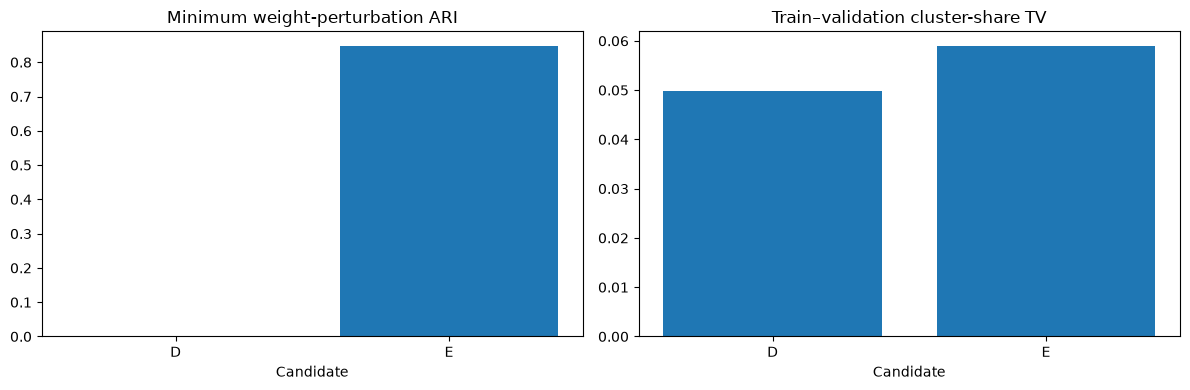

In [58]:
def _br_time_matched_cluster_helpfulness(frame, labels, partition, k, min_each):
    if partition not in ('train','validation'):
        raise ValueError('No TEST helpful-vote inspection in Phase 2.')
    dates=pd.to_datetime(frame['timestamp_dt'],utc=True,errors='coerce')
    votes=pd.to_numeric(frame['helpful_vote_num'],errors='coerce')
    base=pd.DataFrame({'month':dates.dt.strftime('%Y-%m').to_numpy(),
       'category':frame['dataset_category'].astype(str).to_numpy(),
       'cluster':np.asarray(labels,dtype=int), 'positive_vote':votes.gt(0).astype(float).to_numpy(),
       'log_votes':np.log1p(votes.clip(lower=0)).to_numpy(),
       'valid':(dates.notna() & votes.notna() & votes.ge(0)).to_numpy()})
    base=base.loc[base.valid]
    rows=[]
    for c in range(k):
        part=base.copy();part['group']=np.where(part.cluster.eq(c),'cluster','others')
        g=part.groupby(['month','category','group']).agg(n=('positive_vote','size'),
             rate=('positive_vote','mean'),log_mean=('log_votes','mean')).reset_index()
        a=g[g.group.eq('cluster')].drop(columns='group').rename(columns={
            'n':'n1','rate':'r1','log_mean':'l1'})
        b=g[g.group.eq('others')].drop(columns='group').rename(columns={
            'n':'n0','rate':'r0','log_mean':'l0'})
        m=a.merge(b,on=['month','category'],how='inner')
        m=m.loc[(m.n1>=min_each)&(m.n0>=min_each)].copy()
        if len(m):
            w=2*m.n1*m.n0/(m.n1+m.n0)
            rate_delta=float(np.average(m.r1-m.r0,weights=w))
            log_delta=float(np.average(m.l1-m.l0,weights=w))
        else: rate_delta=log_delta=np.nan
        rows.append({'partition':partition,'cluster':c,'matched_month_category_strata':len(m),
            'matched_cluster_rows':int(m.n1.sum()),'matched_other_rows':int(m.n0.sum()),
            'positive_helpful_vote_rate_difference':rate_delta,
            'log1p_helpful_votes_difference':log_delta,
            'status':'estimable' if len(m) else 'insufficient overlap'})
    return pd.DataFrame(rows)

br_helpfulness=[]
for name,model in br_models.items():
    for partition,frame,labels,min_each in [('train',br_train,model['train_labels'],5),
                                              ('validation',br_val,model['val_labels'],3)]:
        comparison=_br_time_matched_cluster_helpfulness(frame,labels,partition,model['k'],min_each)
        comparison.insert(0,'model',name)
        br_helpfulness.append(comparison)
br_helpfulness=pd.concat(br_helpfulness,ignore_index=True)

# Save BOTH candidate partitions target-free, so the A-baseline export is not mistaken
# for a behavior-aware result. Validation is for development only.
br_assignment_parts=[]
for name,m in br_models.items():
    for part,frame,labels in [('train_2019plus',br_train,m['train_labels']),
                               ('validation',br_val,m['val_labels'])]:
        a=frame[['sample_row_id','dataset_category','timestamp_dt']].copy()
        a['model']=name; a['partition']=part; a['cluster']=np.asarray(labels,dtype=int)
        br_assignment_parts.append(a)
br_assignments=pd.concat(br_assignment_parts,ignore_index=True)
assert not any('helpful_vote' in c for c in br_assignments.columns)
br_assignments.to_csv(OUTPUT_DIR/'phase2_DE_candidate_cluster_assignments_TARGET_FREE.csv',index=False)
assert br_helpfulness.partition.ne('test').all()
print('Time-matched helpfulness associations (descriptive ONLY; not model-selection inputs):')
display(br_helpfulness.round(4))

# Model decision: only training/validation feature-based checks, not outcome associations.
qualified=br_model_comparison.loc[br_model_comparison.passes_all_diagnostic_checks].copy()
if len(qualified):
    qualified=qualified.sort_values(['minimum_weight_perturbation_ari',
         'train_validation_TV','silhouette'],ascending=[False,True,False])
    BR_PREFERRED_MODEL=str(qualified.iloc[0].model)
    BR_DECISION_STATUS='candidate passed predeclared scaling, temporal, and multi-axis checks'
else:
    BR_PREFERRED_MODEL=None
    BR_DECISION_STATUS='no candidate passed all checks; scaling/meaningfulness is NOT established'
print('Behavior-aware preferred candidate:',BR_PREFERRED_MODEL or 'NONE')
print(BR_DECISION_STATUS)
print('A/B/C remain historical baselines. TEST outcomes and test features not used in D/E development.')

# Save standalone candidate representations, target-free diagnostics, and a clear result report.
for filename,table in {
 'phase2_DE_k_search.csv':br_k_search,
 'phase2_DE_model_comparison.csv':br_model_comparison,
 'phase2_DE_scaling_sensitivity.csv':br_weight_sensitivity,
 'phase2_DE_behavioral_profiles.csv':br_cluster_profiles,
 'phase2_DE_behavioral_distinctiveness.csv':br_behavioral_distinctiveness,
 'phase2_DE_time_matched_helpfulness.csv':br_helpfulness,
}.items():
    table.to_csv(OUTPUT_DIR/filename,index=False)

br_serializable={}
for name,m in br_models.items():
    br_serializable[name]={'k':m['k'],'weights':m['weights'],
        'numeric_transformer':br_numeric_transformer,
        'categorical_transformer':br_categorical_transformer,
        'text_vectorizer':br_tfidf,'text_svd':br_text_svd,
        'kmeans':m['model'], 'numeric_features':BR_NUMERIC,'categorical_features':BR_CATEGORICAL,
        'train_start':'2019-01-01','history_policy':'strict-earlier for train, frozen training for validation',
        'preprocessing':'numeric rank + L2 / one-hot + L2 / body TF-IDF SVD + L2; weighted blocks + L2'}
# Feature registry for the new (optional) model family, distinct from A/B/C.
br_feature_dictionary=pd.DataFrame([
    ('rating_num','Observed rating, not an authenticity label'),
    ('rating_gap_from_prior_product','Absolute deviation from >=3 strictly earlier sampled product ratings'),
    ('log1p_body_word_count','Log body length without title cues'),
    ('log1p_reviewer_prior_review_count','Sampled prior reviewer activity, frozen for validation'),
    ('log1p_product_prior_review_count','Sampled prior product activity, frozen for validation'),
    ('log1p_user_product_prior_interaction_count','Sampled repeated user/product prior interactions'),
    ('log1p_prior_product_exact_body_count','Prior exact normalized body seen on same product, sampled only'),
    ('uppercase_ratio','Body uppercase-letter fraction'),
    ('non_ascii_ratio','Body non-ASCII fraction, not a language label'),
    ('exclamation_count','Capped body exclamation count'),
    ('question_count','Capped body question count'),
    ('dataset_category','Broad product-dataset category'),
    ('verified_purchase_status','Verified/not verified/missing'),
    ('review_image_available','Review image field is nonempty; not validation of the actual URL'),
    ('rating_context_status','Past-product rating context available with >=3 ratings vs insufficient'),
],columns=['feature','definition'])
br_feature_dictionary.to_csv(OUTPUT_DIR/'phase2_DE_feature_dictionary.csv',index=False)
joblib.dump({'models':br_serializable,'preferred':BR_PREFERRED_MODEL,
  'decision_status':BR_DECISION_STATUS,
  'historical_features_require_training_events':True,
  'no_authenticity_labels':True},OUTPUT_DIR/'phase2_DE_behavior_aware_models.joblib',compress=3)

fig,axs=plt.subplots(1,2,figsize=(12,4))
for i,metric in enumerate(['minimum_weight_perturbation_ari','train_validation_TV']):
    axs[i].bar(br_model_comparison.model,br_model_comparison[metric])
    axs[i].set_title('Minimum weight-perturbation ARI' if i==0 else 'Train–validation cluster-share TV')
    axs[i].set_xlabel('Candidate');axs[i].set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'phase2_DE_robustness_and_drift.png',dpi=160)
plt.show()

### 8.10 Follow-up check 1 — Is Model E mostly a rating + product-history split?

**Research question.** Model E's interpretation suggests that rating and *availability of prior product-rating context* may explain much of its clustering. Test whether its remaining behavioral features add real partition information.

- **Simple control S:** only observed star rating (`rating_num`) and whether at least three strictly earlier sampled product ratings are available (`rating_context_status`). No review text, reviewer IDs, helpful votes, or other behavior predictors. Both inputs are one-hot encoded using **2019+ TRAIN only**.
- Fit **S with the same `k` as Model E** on exactly the same training reviews, and predict the unchanged validation reviews. This makes the partition comparison fair. We do **not** reuse Model E's scaler or clusters to fit S.
- Compare E vs S with **Adjusted Rand Index (ARI)** and normalized mutual information (NMI) on both partitions. Also examine how deterministically the two raw input variables partition the E clusters (`conditional_majority_purity`) and the S cluster sizes.

**Interpretation:** If S closely reproduces E, E may be mostly a simple rating/history-coverage segmentation rather than a rich behavioral discovery. Low agreement is evidence that additional inputs change assignments, but **not automatically evidence that the additional patterns are meaningful**. No helpful-vote outcomes are used in this check.


In [59]:
from sklearn.metrics import normalized_mutual_info_score

EH_ARI_HIGH_SIMILARITY = 0.80  # Interpretive threshold, not a statistical significance test.
EH_SIMPLE_FEATURES = ['rating_num', 'rating_context_status']


def _eh_simple_input(frame):
    """Exactly two categorical predictors; preserve missing ratings explicitly."""
    rating = pd.to_numeric(frame['rating_num'], errors='coerce')
    rating_label = rating.map(lambda x: f'{x:g}' if pd.notna(x) else '__MISSING__')
    history_label = frame['rating_context_status'].fillna('__MISSING__').astype(str)
    return pd.DataFrame({
        'rating_value': rating_label.to_numpy(),
        'has_3_prior_product_ratings': history_label.to_numpy(),
    }, index=frame.index)


def _eh_conditional_purity(frame, labels):
    group_frame = _eh_simple_input(frame).copy()
    group_frame['E_cluster'] = np.asarray(labels, dtype=int)
    table = pd.crosstab(
        [group_frame['rating_value'], group_frame['has_3_prior_product_ratings']],
        group_frame['E_cluster'],
    )
    # Fraction of E labels captured by the most common label in each simple-feature stratum.
    purity = table.max(axis=1).sum() / max(1, table.to_numpy().sum())
    long_table = table.reset_index().melt(
        id_vars=['rating_value', 'has_3_prior_product_ratings'],
        var_name='E_cluster', value_name='n_reviews',
    )
    long_table['stratum_total'] = long_table.groupby(
        ['rating_value', 'has_3_prior_product_ratings'], dropna=False
    )['n_reviews'].transform('sum')
    long_table['fraction_of_stratum'] = (
        long_table['n_reviews'] / long_table['stratum_total'].clip(lower=1)
    )
    return float(purity), long_table

assert 'E' in br_models, 'Model E must be fitted in Section 8.9 first.'
E_REFERENCE = br_models['E']
EH_K = int(E_REFERENCE['k'])
assert len(br_train) == len(E_REFERENCE['train_labels'])
assert len(br_val) == len(E_REFERENCE['val_labels'])
assert not any('helpful_vote' in col for col in EH_SIMPLE_FEATURES)

EH_simple_train = _eh_simple_input(br_train)
EH_simple_validation = _eh_simple_input(br_val)
EH_simple_encoder = _br_encoder()  # Fitted on training cohort only.
EH_Xsimple_train = normalize(EH_simple_encoder.fit_transform(EH_simple_train), copy=False)
EH_Xsimple_val = normalize(EH_simple_encoder.transform(EH_simple_validation), copy=False)
EH_simple_kmeans = KMeans(n_clusters=EH_K, random_state=SEED, n_init=20)
EH_simple_labels_train = EH_simple_kmeans.fit_predict(EH_Xsimple_train)
EH_simple_labels_val = EH_simple_kmeans.predict(EH_Xsimple_val)

EH_simple_rows = []
EH_simple_strata = []
EH_simple_profile_rows = []
for partition, frame, ref_labels, simple_labels in [
    ('2019+ train', br_train, E_REFERENCE['train_labels'], EH_simple_labels_train),
    ('validation', br_val, E_REFERENCE['val_labels'], EH_simple_labels_val),
]:
    purity, strata = _eh_conditional_purity(frame, ref_labels)
    strata.insert(0, 'partition', partition)
    EH_simple_strata.append(strata)
    ari = float(adjusted_rand_score(ref_labels, simple_labels))
    e_shares = _abc_share(ref_labels, EH_K)
    simple_shares = _abc_share(simple_labels, EH_K)
    EH_simple_rows.append({
        'partition': partition,
        'n_reviews': len(frame),
        'E_k': EH_K,
        'same_k_simple_model_ARI_vs_E': ari,
        'same_k_simple_model_NMI_vs_E': float(normalized_mutual_info_score(ref_labels, simple_labels)),
        'E_given_rating_history_conditional_majority_purity': purity,
        'simple_min_cluster_share': float(simple_shares.min()),
        'E_min_cluster_share': float(e_shares.min()),
        'high_similarity_ARI_ge_0p80': bool(ari >= EH_ARI_HIGH_SIMILARITY),
    })
    profile, _ = _br_cluster_profile(frame, simple_labels, 'S_rating_history', partition)
    EH_simple_profile_rows.append(profile)

EH_simple_comparison = pd.DataFrame(EH_simple_rows)
EH_simple_strata = pd.concat(EH_simple_strata, ignore_index=True)
EH_simple_profiles = pd.concat(EH_simple_profile_rows, ignore_index=True)
EH_simple_validation_TV = _abc_tv(
    _abc_share(EH_simple_labels_train, EH_K),
    _abc_share(EH_simple_labels_val, EH_K),
)
print('Simple rating/history baseline compared with E (same k, same training and validation rows):')
display(EH_simple_comparison.round(4))
print('Simple baseline train–validation cluster-share TV:', round(float(EH_simple_validation_TV), 4))
print('Simple model behavioral profiles:')
display(EH_simple_profiles.round(4))
print('Two-feature strata versus E clusters (sample rows):')
display(EH_simple_strata.sort_values(['partition', 'rating_value', 'has_3_prior_product_ratings', 'E_cluster']).head(24))

for filename, table in {
    'phase2_E_simple_rating_history_comparison.csv': EH_simple_comparison,
    'phase2_E_simple_rating_history_strata.csv': EH_simple_strata,
    'phase2_E_simple_rating_history_profiles.csv': EH_simple_profiles,
}.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)

if EH_simple_comparison['high_similarity_ARI_ge_0p80'].all():
    print('CAUTION: rating + prior-rating availability nearly reproduces E; verify extra features add meaningful distinctions.')
else:
    print('The simple two-feature model does not reproduce all E assignments. This does not by itself prove E is meaningful.')


Simple rating/history baseline compared with E (same k, same training and validation rows):


,partition,n_reviews,E_k,same_k_simple_model_ARI_vs_E,same_k_simple_model_NMI_vs_E,E_given_rating_history_conditional_majority_purity,simple_min_cluster_share,E_min_cluster_share,high_similarity_ARI_ge_0p80
0,2019+ train,14256,3,0.8447,0.8228,0.9808,0.2094,0.2614,True
1,validation,11998,3,0.8452,0.8208,0.9828,0.2587,0.2025,True


Simple baseline train–validation cluster-share TV: 0.0581
Simple model behavioral profiles:


,model,partition,cluster,n,median_words,median_rating,median_prior_product,median_prior_reviewer,rating_context_coverage,high_rating_disagreement_rate,prior_body_reuse_rate,repeated_user_product_rate,prior_reviewer_rate,prior_product_rate,verified_rate,review_image_rate,very_short_body_rate,share
0,S_rating_history,2019+ train,0,2985,30.0,3.0,0.0,0.0,0.0,NaN,0.0000,0.0,0.0255,0.3374,0.9095,0.0660,0.0928,0.2094
1,S_rating_history,2019+ train,1,4736,17.0,5.0,8.0,0.0,1.0,0.1579,0.0044,0.0,0.0190,1.0000,0.9497,0.0361,0.2321,0.3322
2,S_rating_history,2019+ train,2,6535,16.0,5.0,0.0,0.0,0.0,NaN,0.0000,0.0,0.0260,0.3475,0.9578,0.0566,0.2314,0.4584
3,S_rating_history,validation,0,3104,31.0,3.0,0.0,0.0,0.0,NaN,0.0000,0.0,0.0126,0.2542,0.9191,0.0841,0.0764,0.2587
4,S_rating_history,validation,1,3289,21.0,5.0,9.0,0.0,1.0,0.1794,0.0024,0.0,0.0106,1.0000,0.9538,0.0757,0.1621,0.2741
5,S_rating_history,validation,2,5605,19.0,5.0,0.0,0.0,0.0,NaN,0.0000,0.0,0.0196,0.2739,0.9434,0.0985,0.1809,0.4672


Two-feature strata versus E clusters (sample rows):


,partition,rating_value,has_3_prior_product_ratings,E_cluster,n_reviews,stratum_total,fraction_of_stratum
0,2019+ train,1,>=3 sampled prior ratings,0,0,497,0.000000
10,2019+ train,1,>=3 sampled prior ratings,1,0,497,0.000000
20,2019+ train,1,>=3 sampled prior ratings,2,497,497,1.000000
1,2019+ train,1,insufficient history,0,0,948,0.000000
11,2019+ train,1,insufficient history,1,0,948,0.000000
21,2019+ train,1,insufficient history,2,948,948,1.000000
2,2019+ train,2,>=3 sampled prior ratings,0,0,216,0.000000
12,2019+ train,2,>=3 sampled prior ratings,1,15,216,0.069444
22,2019+ train,2,>=3 sampled prior ratings,2,201,216,0.930556
3,2019+ train,2,insufficient history,0,0,400,0.000000


CAUTION: rating + prior-rating availability nearly reproduces E; verify extra features add meaningful distinctions.


### 8.11 Follow-up check 2 — Does Model E survive **alternative numerical scaling**?

Section 8.9 verified **numeric-unit invariance** and ±20% categorical-block weights. These are useful, but *neither* checks whether another legitimate numerical scaler gives a similar clustering.

Here we re-fit **the same `k` as Model E**, with the same feature columns, category encoder, weights, and train/validation rows. Only the **numeric scaling stage** changes:

1. **Original:** train-fitted median imputation + quantile-uniform transform (Model E).
2. **Robust:** train-fitted median imputation + `RobustScaler` (10th–90th percentile IQR), then clip transformed values to [-5, 5].
3. **Standard:** train-fitted median imputation + `StandardScaler`, then clip to [-5, 5].

All numeric variants receive the **same per-block L2 normalization** and weighted concatenation as E. This is a **stress test of representation geometry**, not an expectation that genuinely different distance metrics must give identical clusters. Compare ARI against E for both training/validation; also inspect silhouette, validation drift, small-cluster shares, and cluster profiles. The original fitted E is not changed.

**Decision rule:** Low ARI under an alternative is a robustness limitation to document, not automatic proof that E is wrong. Check whether the alternative reveals a coherent behavioral partition before considering adoption. Neither helpful-vote outcomes nor test rows enter this experiment.


Model E numeric scaler comparisons (same k and train/validation rows):


,numeric_scaler,fixed_k,train_ARI_vs_original_E,validation_ARI_vs_original_E,train_silhouette_same_rows,train_validation_cluster_share_TV,minimum_training_cluster_share,minimum_validation_cluster_share,ARI_below_caution_threshold
0,quantile_uniform_original,3,1.000,1.0000,0.2169,0.0590,0.2614,0.2025,False
1,robust_10_90_clipped,3,0.284,0.2540,0.2042,0.0814,0.2302,0.1979,True
2,zscore_clipped,3,0.395,0.3323,0.2241,0.0791,0.3061,0.2628,True


Behavioral profiles under each numeric scaler:


,model,partition,cluster,n,median_words,median_rating,median_prior_product,median_prior_reviewer,rating_context_coverage,high_rating_disagreement_rate,prior_body_reuse_rate,repeated_user_product_rate,prior_reviewer_rate,prior_product_rate,verified_rate,review_image_rate,very_short_body_rate,share
0,E_quantile_uniform_original,2019+ train,0,6594,15.0,5.0,0.0,0.0,0.0000,NaN,0.0000,0.0,0.0259,0.3444,0.9581,0.0561,0.2378,0.4625
1,E_quantile_uniform_original,2019+ train,1,3727,13.0,5.0,8.0,0.0,0.9997,0.0309,0.0056,0.0,0.0180,1.0000,0.9614,0.0319,0.2796,0.2614
2,E_quantile_uniform_original,2019+ train,2,3935,32.0,2.0,1.0,0.0,0.2567,0.6267,0.0000,0.0,0.0249,0.5123,0.9075,0.0633,0.0706,0.2760
3,E_quantile_uniform_original,validation,0,5656,19.0,5.0,0.0,0.0,0.0000,NaN,0.0000,0.0,0.0194,0.2714,0.9438,0.0976,0.1867,0.4714
4,E_quantile_uniform_original,validation,1,2429,17.0,5.0,9.0,0.0,0.9996,0.0239,0.0033,0.0,0.0111,1.0000,0.9621,0.0762,0.2001,0.2025
5,E_quantile_uniform_original,validation,2,3913,32.0,2.0,0.0,0.0,0.2200,0.6179,0.0000,0.0,0.0120,0.4214,0.9208,0.0831,0.0618,0.3261
6,E_robust_10_90_clipped,2019+ train,0,6311,33.0,5.0,0.0,0.0,0.0024,0.0000,0.0000,0.0,0.0285,0.3022,0.9255,0.0784,0.0328,0.4427
7,E_robust_10_90_clipped,2019+ train,1,4663,18.0,5.0,8.0,0.0,0.9213,0.1713,0.0028,0.0,0.0191,1.0000,0.9481,0.0369,0.1683,0.3271
8,E_robust_10_90_clipped,2019+ train,2,3282,5.0,5.0,0.0,0.0,0.1295,0.0282,0.0024,0.0,0.0204,0.4400,0.9781,0.0216,0.5777,0.2302
9,E_robust_10_90_clipped,validation,0,6288,35.0,5.0,0.0,0.0,0.0025,0.0000,0.0000,0.0,0.0189,0.2304,0.9218,0.1104,0.0264,0.5241


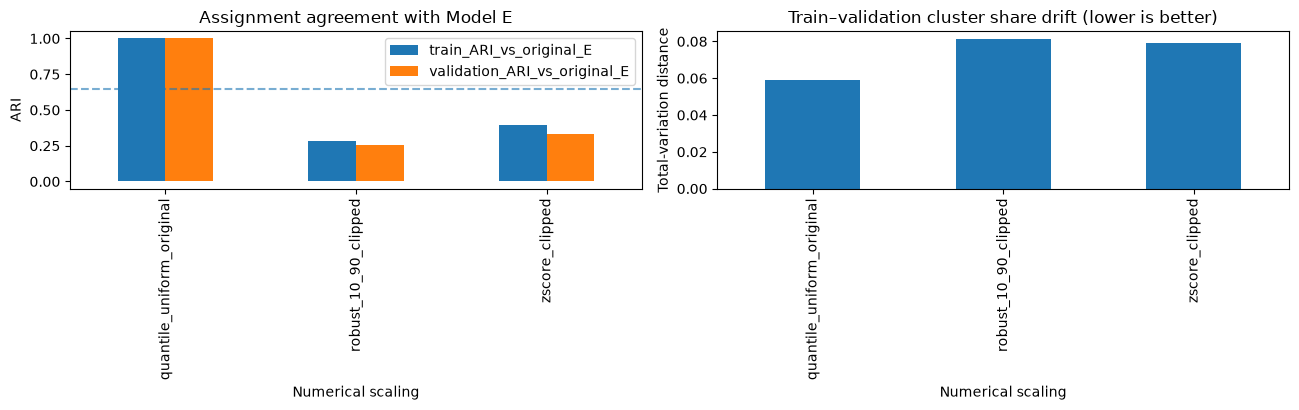

CAUTION: E is sensitive to at least one alternate numeric scaler. Inspect behavior profiles and do not claim broad scaling robustness.
CORRECTED E scaler qualification (uses ALL tested scalers):


,model,minimum_alternative_numeric_scaler_ari,passes_scaling_checks,max_distinct_behavior_domains,passes_all_diagnostic_checks
1,E,0.25396,False,1,False


In [60]:
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.metrics import silhouette_score

EH_SCALER_ARI_CAUTION = 0.65  # Diagnostic threshold, NOT automatic model selection.
EH_SILHOUETTE_SAMPLE_ROWS = min(2500, len(br_train))
EH_silhouette_indices = np.sort(np.random.default_rng(SEED + 2021).choice(
    len(br_train), size=EH_SILHOUETTE_SAMPLE_ROWS, replace=False
))


def _eh_alternative_numeric_scaling(train_frame, val_frame, method):
    """Train-fitted numeric scaler only; preserve BR_NUMERIC and row-wise L2 rule."""
    imputer = SimpleImputer(strategy='median')
    train_imputed = imputer.fit_transform(train_frame[BR_NUMERIC])
    val_imputed = imputer.transform(val_frame[BR_NUMERIC])
    if method == 'robust_10_90_clipped':
        scaler = RobustScaler(with_centering=True, with_scaling=True,
                              quantile_range=(10, 90))
    elif method == 'zscore_clipped':
        scaler = StandardScaler(with_mean=True, with_std=True)
    else:
        raise ValueError(f'Unknown scaler {method}')
    ztrain = scaler.fit_transform(train_imputed)
    zval = scaler.transform(val_imputed)
    # Uniform fixed clipping avoids extreme right tails overwhelming the other blocks.
    # Scaling fit statistics come only from TRAIN. Clipping is a predeclared rule.
    ztrain = np.clip(np.nan_to_num(ztrain, nan=0.0, posinf=5.0, neginf=-5.0), -5.0, 5.0)
    zval = np.clip(np.nan_to_num(zval, nan=0.0, posinf=5.0, neginf=-5.0), -5.0, 5.0)
    return (normalize(sparse.csr_matrix(ztrain), copy=False),
            normalize(sparse.csr_matrix(zval), copy=False),
            imputer, scaler)


def _eh_silhouette_fixed_sample(X, labels):
    subset_X = X[EH_silhouette_indices]
    subset_y = np.asarray(labels)[EH_silhouette_indices]
    uniques = np.unique(subset_y)
    if len(uniques) <= 1 or len(uniques) >= len(subset_y):
        return np.nan
    return float(silhouette_score(subset_X, subset_y))

EH_scaler_tests = []
EH_scaler_profiles = []
EH_scaler_models = {}

# Original Model E, re-scored on exactly the same training rows as the alternatives.
for name in ['quantile_uniform_original', 'robust_10_90_clipped', 'zscore_clipped']:
    if name == 'quantile_uniform_original':
        X_train = E_REFERENCE['X_train']
        X_val = E_REFERENCE['X_val']
        label_train = E_REFERENCE['train_labels']
        label_val = E_REFERENCE['val_labels']
        km = E_REFERENCE['model']
        imputer = None
        scaler = br_numeric_transformer
    else:
        num_train, num_val, imputer, scaler = _eh_alternative_numeric_scaling(br_train, br_val, name)
        X_train = _br_combine((num_train, br_cat_train, br_text_train), E_REFERENCE['weights'])
        X_val = _br_combine((num_val, br_cat_val, br_text_val), E_REFERENCE['weights'])
        km = KMeans(n_clusters=EH_K, random_state=SEED, n_init=20)
        label_train = km.fit_predict(X_train)
        label_val = km.predict(X_val)

    shares_train = _abc_share(label_train, EH_K)
    shares_val = _abc_share(label_val, EH_K)
    train_ari = float(adjusted_rand_score(E_REFERENCE['train_labels'], label_train))
    val_ari = float(adjusted_rand_score(E_REFERENCE['val_labels'], label_val))
    EH_scaler_tests.append({
        'numeric_scaler': name,
        'fixed_k': EH_K,
        'train_ARI_vs_original_E': train_ari,
        'validation_ARI_vs_original_E': val_ari,
        'train_silhouette_same_rows': _eh_silhouette_fixed_sample(X_train, label_train),
        'train_validation_cluster_share_TV': float(_abc_tv(shares_train, shares_val)),
        'minimum_training_cluster_share': float(shares_train.min()),
        'minimum_validation_cluster_share': float(shares_val.min()),
        'ARI_below_caution_threshold': bool(min(train_ari, val_ari) < EH_SCALER_ARI_CAUTION),
    })
    EH_scaler_models[name] = {'kmeans':km,'imputer':imputer,'numeric_scaler':scaler,
                               'train_labels':label_train,'validation_labels':label_val}
    for partition, frame, labels in [('2019+ train',br_train,label_train),
                                     ('validation',br_val,label_val)]:
        profile, _ = _br_cluster_profile(frame, labels, f'E_{name}', partition)
        EH_scaler_profiles.append(profile)

EH_scaler_comparison = pd.DataFrame(EH_scaler_tests)
EH_scaler_profiles = pd.concat(EH_scaler_profiles, ignore_index=True)
assert not any('helpful_vote' in col for col in EH_scaler_comparison.columns)
print('Model E numeric scaler comparisons (same k and train/validation rows):')
display(EH_scaler_comparison.round(4))
print('Behavioral profiles under each numeric scaler:')
display(EH_scaler_profiles.round(4))

for filename, table in {
    'phase2_E_numeric_scaling_sensitivity.csv': EH_scaler_comparison,
    'phase2_E_numeric_scaling_cluster_profiles.csv': EH_scaler_profiles,
}.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
scaler_plot = EH_scaler_comparison.set_index('numeric_scaler')
scaler_plot[['train_ARI_vs_original_E', 'validation_ARI_vs_original_E']].plot(kind='bar', ax=axes[0])
axes[0].axhline(EH_SCALER_ARI_CAUTION, ls='--', alpha=0.6)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_title('Assignment agreement with Model E')
axes[0].set_xlabel('Numerical scaling')
axes[0].set_ylabel('ARI')
scaler_plot['train_validation_cluster_share_TV'].plot(kind='bar', ax=axes[1])
axes[1].set_title('Train–validation cluster share drift (lower is better)')
axes[1].set_xlabel('Numerical scaling')
axes[1].set_ylabel('Total-variation distance')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'phase2_E_numeric_scalers_robustness.png', dpi=160)
plt.show()

if EH_scaler_comparison['ARI_below_caution_threshold'].any():
    print('CAUTION: E is sensitive to at least one alternate numeric scaler. Inspect behavior profiles and do not claim broad scaling robustness.')
else:
    print('The tested numeric scalers give similar assignments to E. This does not prove robustness to every representation.')

# Correct final qualification: do not treat expected unit invariance under rank scaling
# as proof of robustness to other legitimate numerical scalers.
EH_ALT_SCALER_MIN_ARI = float(EH_scaler_comparison.loc[
    EH_scaler_comparison.numeric_scaler.ne('quantile_uniform_original'),
    ['train_ARI_vs_original_E','validation_ARI_vs_original_E']
].min().min())
E_MASK = br_model_comparison.model.eq('E')
br_model_comparison.loc[E_MASK,'minimum_alternative_numeric_scaler_ari'] = EH_ALT_SCALER_MIN_ARI
br_model_comparison.loc[E_MASK,'passes_alternative_scaler_check'] = (
    EH_ALT_SCALER_MIN_ARI >= EH_SCALER_ARI_CAUTION)
br_model_comparison.loc[E_MASK,'passes_scaling_checks'] &= (
    EH_ALT_SCALER_MIN_ARI >= EH_SCALER_ARI_CAUTION)
br_model_comparison['passes_all_diagnostic_checks']=(
    br_model_comparison.passes_scaling_checks & br_model_comparison.passes_cluster_checks &
    br_model_comparison.passes_behavioral_relevance_check)
# Supersede the earlier E decision/report, which preceded the alternative-scaler experiment.
if not bool(br_model_comparison.loc[E_MASK,'passes_all_diagnostic_checks'].iloc[0]):
    BR_PREFERRED_MODEL = None if BR_PREFERRED_MODEL == 'E' else BR_PREFERRED_MODEL
    BR_DECISION_STATUS = ('E does NOT qualify under the alternative-numeric-scaler check; '
                          'D/E results remain exploratory baselines.')
br_model_comparison.to_csv(OUTPUT_DIR/'phase2_DE_model_comparison_corrected.csv',index=False)
# Also replace the earlier provisional E outputs so none of the persisted candidate
# files accidentally call E "preferred" after it fails the broader scaler audit.
br_model_comparison.to_csv(OUTPUT_DIR/'phase2_DE_model_comparison.csv',index=False)
_de_file=OUTPUT_DIR/'phase2_DE_behavior_aware_models.joblib'
if _de_file.exists():
    _de_saved=joblib.load(_de_file)
    _de_saved['preferred']=BR_PREFERRED_MODEL
    _de_saved['decision_status']=BR_DECISION_STATUS
    _de_saved['alt_numeric_scaler_check_included']=True
    joblib.dump(_de_saved,_de_file,compress=3)

print('CORRECTED E scaler qualification (uses ALL tested scalers):')
display(br_model_comparison.loc[E_MASK,[
    'model','minimum_alternative_numeric_scaler_ari','passes_scaling_checks',
    'max_distinct_behavior_domains','passes_all_diagnostic_checks']])


### 8.12 Amazon Reviews ’23 requirements — feature coverage and cluster relationships

This section makes the four **Amazon-specific** requirements separately auditable:

1. A fitted **TF-IDF** text representation exists. The optional semantic embedding and its intended use are documented in Section 4.3a.
2. Product category/price, review length/age, rating, and interaction features have been prepared. **Review age (`review_age_days_proxy`) is diagnostic only** because it references the full sample; its related year/cyclical time predictors are available to reference A, while behavior-first E deliberately avoids time as a clustering shortcut. Product price is present in A but absent from E by design.
3. Image **counts and availability** are structured features, not visual embeddings. 
4. The unit of clustering is **one review**. The next cells examine whether E's clusters correspond to **product categories, star ratings, and reviewer/product behavior**. These are descriptive, target-free interpretations; helpful-vote associations are evaluated separately, *after fitting*, in Section 8.9c.

The checks below use the **same fixed 2019+ training cohort and validation set** as E; there is no refit, new hyperparameter search, or use of test/helpful-vote outcomes.

In [61]:
# Demonstrate precisely which Amazon-specific variables are available and used.
_amazon_feature_map = [
 ('review text','cleaned_body','TF-IDF: A title+body; D body-only; E has NO text',
    'Primary text; lexical representation fitted on train'),
 ('product category','dataset_category','A and E','Broad category, one-hot encoded'),
 ('product taxonomy','product_main_category','Descriptive for E; optional structured in A',
    'Coarse joined metadata category; may be missing'),
 ('price','product_price_num','Reference A only; NOT E','Median imputed + missingness flag in A'),
 ('review length','text_word_count','A; log body-only length in E','Review detail / text volume'),
 ('review age','review_age_days_proxy','Descriptive ONLY, not model input',
    'Days before latest sampled review; NOT true helpful-vote exposure'),
 ('review publication year','review_year','Reference A; excluded from E',
    'Cohort/calendar effect, not causal review age'),
 ('rating','rating_num','A and E','Observed star rating'),
 ('reviewer activity','reviewer_prior_review_count','A; log transform in E',
    'Prior sampled reviewer reviews (strict-earlier/frozen)'),
 ('product activity','product_prior_review_count','A; log transform in E',
    'Prior sampled product reviews (strict-earlier/frozen)'),
 ('repeated user/product','user_product_prior_interaction_count','A; log transform in E',
    'Prior sampled reviewer–product interactions'),
 ('rating disagreement','rating_gap_from_prior_product','E only when prior context exists',
    'Absolute rating difference versus prior sampled product average'),
 ('reviewer/customer images','review_image_available','A and E (presence/count only)',
    'NOT an image-pixel embedding'),
]
_amazon_check_frames = {'train':br_train,'validation':br_val}
_amazon_cols=[]
for _label,_col,_usage,_reason in _amazon_feature_map:
    _row={'requirement_feature':_label,'column':_col,'usage':_usage,'rationale':_reason}
    for _part,_frame in _amazon_check_frames.items():
        _row[_part+'_column_exists']=_col in _frame.columns
        _row[_part+'_nonmissing_rate']=(float(_frame[_col].notna().mean())
                                         if _col in _frame.columns else np.nan)
    _amazon_cols.append(_row)
AMAZON_FEATURE_COVERAGE=pd.DataFrame(_amazon_cols)
assert AMAZON_FEATURE_COVERAGE['train_column_exists'].all(), 'Expected source/engineered features missing'
assert 'helpful_vote_num' not in BR_NUMERIC+BR_CATEGORICAL
# The optional image experiment is verified separately in Section 8.18.
AMAZON_FEATURE_COVERAGE.to_csv(OUTPUT_DIR/'phase2_amazon_structured_feature_coverage.csv',index=False)
display(AMAZON_FEATURE_COVERAGE)
print('Amazon feature coverage verified. Time proxy is descriptive, not an E input.')

,requirement_feature,column,usage,rationale,train_column_exists,train_nonmissing_rate,validation_column_exists,validation_nonmissing_rate
0,review text,cleaned_body,TF-IDF: A title+body; D body-only; E has NO text,Primary text; lexical representation fitted on train,True,1.000000,True,1.000000
1,product category,dataset_category,A and E,"Broad category, one-hot encoded",True,1.000000,True,1.000000
2,product taxonomy,product_main_category,Descriptive for E; optional structured in A,Coarse joined metadata category; may be missing,True,0.970539,True,0.968411
3,price,product_price_num,Reference A only; NOT E,Median imputed + missingness flag in A,True,0.706089,True,0.764711
4,review length,text_word_count,A; log body-only length in E,Review detail / text volume,True,1.000000,True,1.000000
5,review age,review_age_days_proxy,"Descriptive ONLY, not model input",Days before latest sampled review; NOT true helpful-vote exposure,True,1.000000,True,1.000000
6,review publication year,review_year,Reference A; excluded from E,"Cohort/calendar effect, not causal review age",True,1.000000,True,1.000000
7,rating,rating_num,A and E,Observed star rating,True,1.000000,True,1.000000
8,reviewer activity,reviewer_prior_review_count,A; log transform in E,Prior sampled reviewer reviews (strict-earlier/frozen),True,1.000000,True,1.000000
9,product activity,product_prior_review_count,A; log transform in E,Prior sampled product reviews (strict-earlier/frozen),True,1.000000,True,1.000000


Amazon feature coverage verified. Time proxy is descriptive, not an E input.


### 8.12a Relationship of behavior-first **E** review clusters to product categories, rating, and reviewer behavior

- **Category composition:** For each cluster, calculate the percentage belonging to each dataset category and product taxonomy group. Compare with that category's percentage in the corresponding **whole partition** (`lift` > 1 means overrepresented).
- **Ratings:** Compare the distribution of low (1–2), neutral (3), and high (4–5) stars.
- **Activity:** Compare whether there is any earlier sampled reviewer or product review and whether there is a history of three or more earlier product ratings.
- **Verification/images:** Examine structured flags without treating them as visual image features.

These checks examine **patterns found by K-means**, not class labels. The product-category comparisons cannot prove genuine or manipulated reviews. Product-taxonomy results are conditional on metadata coverage and are therefore descriptive.

Model E -- dataset_category (percentage within each training cluster)


value,Musical_Instruments,Video_Games
cluster,,
0,60.7,39.3
1,45.8,54.2
2,49.8,50.2


Model E -- rating_group (percentage within each training cluster)


value,1-2 stars,3 stars,4-5 stars
cluster,,,
0,0.0,0.0,100.0
1,0.4,1.6,98.0
2,52.0,19.7,28.3


Model E -- product_history (percentage within each training cluster)


value,0 previous,1-2 previous,3+ previous
cluster,,,
0,65.6,34.4,0.0
1,0.0,0.0,100.0
2,48.8,25.6,25.7


Model E -- reviewer_history (percentage within each training cluster)


value,0 previous,1-2 previous,3+ previous
cluster,,,
0,97.4,2.5,0.1
1,98.2,1.8,0.0
2,97.5,2.4,0.1


Product-taxonomy composition; top rows, excluding small cells:


,partition,model,feature,cluster,value,n_cluster_level,n_cluster_total,within_cluster_share,whole_partition_share,share_difference_pp,overrepresentation_lift
9,2019+ train,E,product_main_category,0,__MISSING__,255,6594,0.039,0.029,0.921,1.313
7,2019+ train,E,product_main_category,0,Musical Instruments,3829,6594,0.581,0.519,6.160,1.119
8,2019+ train,E,product_main_category,0,Video Games,2500,6594,0.379,0.450,-7.134,0.842
12,2019+ train,E,product_main_category,1,Video Games,2000,3727,0.537,0.450,8.615,1.191
11,2019+ train,E,product_main_category,1,Musical Instruments,1688,3727,0.453,0.519,-6.617,0.873
13,2019+ train,E,product_main_category,1,__MISSING__,39,3727,0.010,0.029,-1.900,0.355
17,2019+ train,E,product_main_category,2,__MISSING__,126,3935,0.032,0.029,0.256,1.087
16,2019+ train,E,product_main_category,2,Video Games,1922,3935,0.488,0.450,3.796,1.084
15,2019+ train,E,product_main_category,2,Musical Instruments,1883,3935,0.479,0.519,-4.055,0.922
72,validation,E,product_main_category,0,__MISSING__,219,5656,0.039,0.032,0.713,1.226


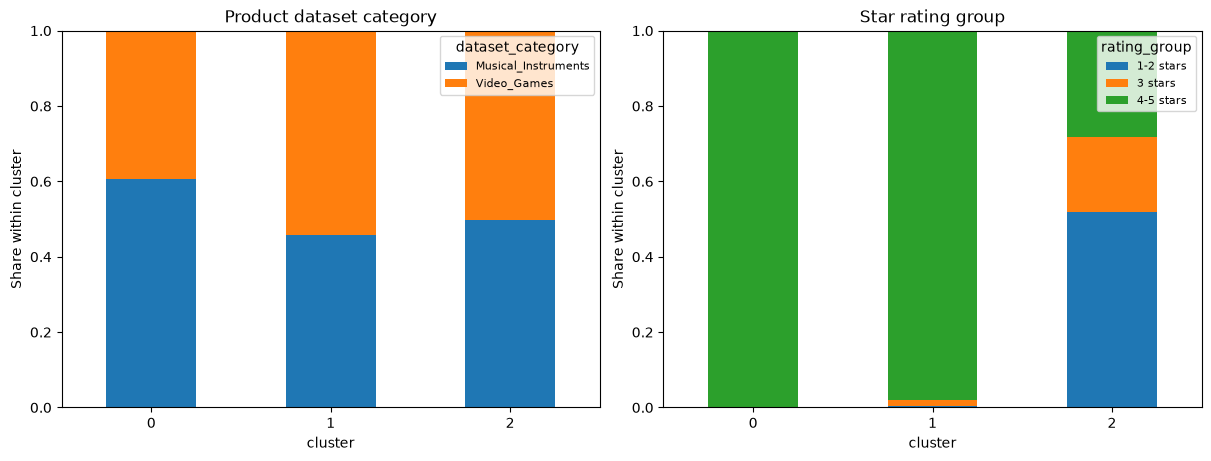

In [62]:
# Produce direct tables rather than relying on one cluster profile alone.
# All values are transformed BEFORE comparison in the same way for train/validation.
_AMAZON_TAXONOMY_TOP_N = 8
_amazon_taxonomy_train=(br_train['product_main_category'].fillna('__MISSING__')
     .astype(str).replace('', '__MISSING__'))
_amazon_top_taxonomies=set(_amazon_taxonomy_train.value_counts().head(_AMAZON_TAXONOMY_TOP_N).index)

def _amazon_cluster_associations(frame, labels, partition):
    labels=np.asarray(labels,dtype=int)
    assert len(frame)==len(labels)
    detail=pd.DataFrame({'cluster':labels})
    detail['dataset_category']=frame['dataset_category'].fillna('__MISSING__').astype(str).to_numpy()
    taxonomy=frame['product_main_category'].fillna('__MISSING__').astype(str).replace('', '__MISSING__')
    detail['product_main_category']=taxonomy.where(taxonomy.isin(_amazon_top_taxonomies),'OTHER').to_numpy()
    rating=pd.to_numeric(frame['rating_num'],errors='coerce')
    detail['rating_group']=(pd.cut(rating,bins=[0,2,3,5],labels=['1-2 stars','3 stars','4-5 stars'])
                            .astype('object').fillna('__MISSING__').to_numpy())
    def history_bins(col):
        s=pd.to_numeric(frame[col],errors='coerce')
        return np.select([s.isna(),s.eq(0),s.between(1,2),s.ge(3)],
                         ['missing','0 previous','1-2 previous','3+ previous'],default='missing')
    detail['reviewer_history']=history_bins('reviewer_prior_review_count')
    detail['product_history']=history_bins('product_prior_review_count')
    detail['rating_context']=frame['rating_context_status'].fillna('__MISSING__').astype(str).to_numpy()
    detail['verified_purchase']=frame['verified_purchase_status'].fillna('missing').astype(str).to_numpy()
    detail['customer_image']=frame['review_image_available'].fillna('missing').astype(str).to_numpy()
    outputs=[]
    for feature in detail.columns.drop('cluster'):
        table=pd.crosstab(detail['cluster'],detail[feature]).sort_index()
        if table.empty: continue
        n_cluster=table.sum(axis=1)
        n_cohort=table.sum(axis=0)
        for k in table.index:
            for level,n in table.loc[k].items():
                frac=float(n/n_cluster[k]) if n_cluster[k] else np.nan
                base=float(n_cohort[level]/len(detail)) if len(detail) else np.nan
                outputs.append({'partition':partition,'model':'E','feature':feature,
                    'cluster':int(k),'value':str(level),'n_cluster_level':int(n),
                    'n_cluster_total':int(n_cluster[k]),'within_cluster_share':frac,
                    'whole_partition_share':base,
                    'share_difference_pp':100*(frac-base),
                    'overrepresentation_lift':frac/base if base else np.nan})
    return pd.DataFrame(outputs),detail

_amazon_associations=[]
for _p,_f,_labs in [('2019+ train',br_train,br_models['E']['train_labels']),
                      ('validation',br_val,br_models['E']['val_labels'])]:
    _tab,_detail=_amazon_cluster_associations(_f,_labs,_p)
    _amazon_associations.append(_tab)
AMAZON_E_ASSOCIATIONS=pd.concat(_amazon_associations,ignore_index=True)
AMAZON_E_ASSOCIATIONS.to_csv(OUTPUT_DIR/'phase2_amazon_E_cluster_category_rating_behavior.csv',index=False)

# Readable cross-tabs: within-cluster proportions, plus strongest well-supported lifts.
for _feature in ['dataset_category','rating_group','product_history','reviewer_history']:
    _sub=AMAZON_E_ASSOCIATIONS.query('partition=="2019+ train" and feature==@_feature')
    print('Model E --',_feature,'(percentage within each training cluster)')
    display((_sub.pivot(index='cluster',columns='value',values='within_cluster_share')*100).round(1))
print('Product-taxonomy composition; top rows, excluding small cells:')
_amazon_product_lifts=AMAZON_E_ASSOCIATIONS.loc[
    AMAZON_E_ASSOCIATIONS.feature.eq('product_main_category') &
    AMAZON_E_ASSOCIATIONS.n_cluster_level.ge(20) &
    AMAZON_E_ASSOCIATIONS.value.ne('OTHER')].copy()
display(_amazon_product_lifts.sort_values(
    ['partition','cluster','overrepresentation_lift'],ascending=[True,True,False]
    ).groupby(['partition','cluster']).head(4).round(3))

_fig,_axes=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for _ax,_feature,_title in zip(_axes,['dataset_category','rating_group'],
                               ['Product dataset category','Star rating group']):
    _sub=AMAZON_E_ASSOCIATIONS.query('partition=="2019+ train" and feature==@_feature')
    _pivot=_sub.pivot(index='cluster',columns='value',values='within_cluster_share').fillna(0)
    _pivot.plot(kind='bar',stacked=True,ax=_ax)
    _ax.set_title(_title);_ax.set_ylabel('Share within cluster')
    _ax.set_ylim(0,1);_ax.legend(title=_feature,fontsize=8)
    _ax.tick_params(axis='x',rotation=0)
plt.savefig(OUTPUT_DIR/'phase2_amazon_E_category_rating_composition.png',dpi=160,bbox_inches='tight')
plt.show()

### 8.12b What is distinctive about E's review clusters, beyond rating/category?

The next tables examine post-hoc body-text vocabulary (even though E **does not cluster on text**), and join the already computed behavioral profiles with the **same-month, same-category helpful-vote analysis**. This helps relate discovered groups to the project's helpfulness question without using helpful votes to *create*, select, or change the clusters.



In [63]:
# Post-hoc lexical descriptors are based on TF-IDF fitted on 2019+ TRAIN, not an E model input.
AMAZON_E_DISTINCTIVE_TERMS=distinctive_terms_by_cluster(
    br_tfidf_train, br_models['E']['train_labels'], br_tfidf, top_n=10)
AMAZON_E_DISTINCTIVE_TERMS.to_csv(OUTPUT_DIR/'phase2_amazon_E_distinctive_body_terms.csv',index=False)
display(AMAZON_E_DISTINCTIVE_TERMS.groupby('cluster').head(6).round(4))

# Cluster profiles computed in Section 8.9 (train + validation); helpfulness is post-hoc.
AMAZON_E_RESEARCH_SUMMARY=br_cluster_profiles.query('model == "E"').copy()
AMAZON_E_RESEARCH_SUMMARY['help_partition']=AMAZON_E_RESEARCH_SUMMARY['partition'].replace({'2019+ train':'train'})
_amazon_e_help=br_helpfulness.query('model == "E"')[[
    'partition','cluster','matched_month_category_strata',
    'positive_helpful_vote_rate_difference','status']].rename(columns={'partition':'help_partition'})
AMAZON_E_RESEARCH_SUMMARY=AMAZON_E_RESEARCH_SUMMARY.merge(
    _amazon_e_help,on=['help_partition','cluster'],how='left',validate='many_to_one'
).drop(columns='help_partition')
AMAZON_E_RESEARCH_SUMMARY.to_csv(OUTPUT_DIR/'phase2_amazon_E_research_interpretation.csv',index=False)
display(AMAZON_E_RESEARCH_SUMMARY.round(3))
print('CAUTION: E group differences are descriptive; most of E is reproducible from rating + history availability;')
print('alternative scaling methods produced different assignments in Section 8.11.')

,cluster,rank,term,mean_tfidf_in,mean_tfidf_out,difference
0,0,1,great,0.0378,0.0250,0.0128
1,0,2,love,0.0168,0.0103,0.0065
2,0,3,perfect,0.0132,0.0069,0.0063
3,0,4,good,0.0264,0.0213,0.0051
4,0,5,my,0.0235,0.0192,0.0043
5,0,6,works,0.0182,0.0140,0.0042
10,1,1,great,0.0412,0.0273,0.0139
11,1,2,good,0.0297,0.0215,0.0082
12,1,3,love,0.0180,0.0116,0.0064
13,1,4,works,0.0201,0.0144,0.0057


,model,partition,cluster,n,median_words,median_rating,median_prior_product,median_prior_reviewer,rating_context_coverage,high_rating_disagreement_rate,prior_body_reuse_rate,repeated_user_product_rate,prior_reviewer_rate,prior_product_rate,verified_rate,review_image_rate,very_short_body_rate,share,matched_month_category_strata,positive_helpful_vote_rate_difference,status
0,E,2019+ train,0,6594,15.0,5.0,0.0,0.0,0.000,NaN,0.000,0.0,0.026,0.344,0.958,0.056,0.238,0.463,38,0.022,estimable
1,E,2019+ train,1,3727,13.0,5.0,8.0,0.0,1.000,0.031,0.006,0.0,0.018,1.000,0.961,0.032,0.280,0.261,38,-0.174,estimable
2,E,2019+ train,2,3935,32.0,2.0,1.0,0.0,0.257,0.627,0.000,0.0,0.025,0.512,0.907,0.063,0.071,0.276,38,0.140,estimable
3,E,validation,0,5656,19.0,5.0,0.0,0.0,0.000,NaN,0.000,0.0,0.019,0.271,0.944,0.098,0.187,0.471,32,-0.002,estimable
4,E,validation,1,2429,17.0,5.0,9.0,0.0,1.000,0.024,0.003,0.0,0.011,1.000,0.962,0.076,0.200,0.202,32,-0.166,estimable
5,E,validation,2,3913,32.0,2.0,0.0,0.0,0.220,0.618,0.000,0.0,0.012,0.421,0.921,0.083,0.062,0.326,32,0.124,estimable


CAUTION: E group differences are descriptive; most of E is reproducible from rating + history availability;
alternative scaling methods produced different assignments in Section 8.11.


### 8.13 Historical Model F — negative control (archived, **not refitted**)

The uploaded run fitted a fused body-text + behavior Model F. **The saved result was negative**: agreement with a simpler rating/history control was ARI = 1.0, and dropping its text block did not change its partition (ARI = 1.0). It therefore did not demonstrate incremental text/behavioral discovery. F is removed from active selection, refitting, artifact export and main conclusions. These figures describe **the previous notebook**, not a newly executed experiment; retain the original notebook as the historical audit if needed.

A small matched-stratum comparison utility from that section is retained below because E1/E2 require it. It uses helpful votes only when explicitly requested for post-hoc interpretation, never for fitting or choosing k.


In [64]:
# Reusable matched-stratum audit; independent of the archived Model F.
MATCHED_CONDITIONAL_FEATURES={
    'very_short_body':'text_word_count',
    'customer_image':'review_image_available',
    'verified_purchase':'verified_purchase_status',
    'prior_reviewer_activity':'reviewer_prior_review_count',
    'previous_exact_body_reuse':'prior_product_exact_body_count',
    'large_rating_disagreement_given_context':'rating_gap_from_prior_product',
}

def _matched_cluster_table(frame,labels,partition,include_helpfulness=False):
    if partition not in ('2019+ train','validation'):
        raise ValueError('Phase 2 does not use test-target outcomes.')
    n=len(frame)
    t=pd.DataFrame(index=np.arange(n))
    t['cluster']=np.asarray(labels,dtype=int)
    t['month']=pd.to_datetime(frame['timestamp_dt'],errors='coerce',utc=True).dt.strftime('%Y-%m').to_numpy()
    t['category']=frame['dataset_category'].fillna('missing').astype(str).to_numpy()
    rat=pd.to_numeric(frame['rating_num'],errors='coerce')
    t['rating_group']=pd.cut(rat,bins=[0,2,3,5],labels=['1-2','3','4-5']).astype(object).fillna('missing').to_numpy()
    t['rating_history']=frame['rating_context_status'].fillna('missing').astype(str).to_numpy()
    t['very_short_body']=pd.to_numeric(frame['text_word_count'],errors='coerce').le(5).astype(float).to_numpy()
    t['customer_image']=frame['review_image_available'].eq('yes').astype(float).to_numpy()
    t['verified_purchase']=frame['verified_purchase_status'].eq('verified').astype(float).to_numpy()
    t['prior_reviewer_activity']=pd.to_numeric(frame['reviewer_prior_review_count'],errors='coerce').gt(0).astype(float).to_numpy()
    t['previous_exact_body_reuse']=pd.to_numeric(frame['prior_product_exact_body_count'],errors='coerce').gt(0).astype(float).to_numpy()
    gap=pd.to_numeric(frame['rating_gap_from_prior_product'],errors='coerce')
    t['large_rating_disagreement_given_context']=np.where(gap.notna(),gap.ge(2).astype(float),np.nan)
    if include_helpfulness:
        votes=pd.to_numeric(frame['helpful_vote_num'],errors='coerce')
        t['at_least_one_helpful_vote']=np.where(votes.ge(0)&votes.notna(),votes.gt(0).astype(float),np.nan)
    strata=['month','category','rating_group','rating_history']
    features=list(MATCHED_CONDITIONAL_FEATURES)
    if include_helpfulness: features.append('at_least_one_helpful_vote')
    min_each=5 if partition=='2019+ train' else 3
    rows=[]
    for cluster in sorted(t.cluster.unique()):
        groups=np.where(t.cluster.eq(cluster),'in_cluster','others')
        work=t.copy();work['comparison']=groups
        for feature in features:
            g=work.groupby(strata+['comparison'],dropna=False,observed=True)[feature].agg(['mean','count']).reset_index()
            a=g[g.comparison.eq('in_cluster')].drop(columns='comparison').rename(columns={'mean':'a','count':'na'})
            b=g[g.comparison.eq('others')].drop(columns='comparison').rename(columns={'mean':'b','count':'nb'})
            paired=a.merge(b,on=strata)
            paired=paired.loc[(paired.na>=min_each)&(paired.nb>=min_each)].copy()
            if len(paired):
                weight=2*paired.na*paired.nb/(paired.na+paired.nb)
                delta=float(np.average(paired.a-paired.b,weights=weight))
                in_n=int(paired.na.sum());out_n=int(paired.nb.sum())
            else:
                delta=np.nan;in_n=out_n=0
            rows.append({'partition':partition,'cluster':int(cluster),'feature':feature,
                'matched_strata':int(len(paired)),
                'matched_inside_n':in_n,'matched_outside_n':out_n,
                'difference_percentage_points':100*delta if np.isfinite(delta) else np.nan,
                'status':'estimable' if len(paired) else 'insufficient overlap',
                'posthoc_target':bool(feature=='at_least_one_helpful_vote')})
    return pd.DataFrame(rows)



### 8.17 Controlled test of the user's idea: split Model E into **two-feature** and **remaining-behavior** models

**Research question.** Does Model E's rating/history partition conceal other review behavior, or can we find different groups using the remaining signals? Both models use the **same 2019+ training cohort and chronological validation period**, and both choose `k` on training data only. Model E is retained as a reference.

* **E1 (two-feature control):** review rating and the availability of at least 3 strictly earlier *sampled* product ratings.
* **E2 (strict remaining-behavior control):** review-body length/style, punctuation, text character composition, verified purchase, review-image availability, prior sampled reviewer activity, prior same-user/product interaction, exact repeated review body, and dataset category. **No rating, rating gap, product review counts, or rating-history-availability indicator** is used. We intentionally also exclude the indirect proxies `rating_gap_from_prior_product` and `log1p_product_prior_review_count`; this prevents an apparent “rest-only” result from merely recreating E1.

E2 is **not** a text-semantic model: its text measurements are structured features, not TF-IDF. TF-IDF has already been fitted and investigated in earlier sections. Nothing here proves review manipulation. Helpfulness is used only **after** the models are fitted and compared, never to choose `k` or select a replacement.

**Interpretation checks:** different clusters within the same rating/history strata, stability to numeric preprocessing, train-validation drift, behavioral profiles, and time/category/rating/history-matched helpful-vote associations. Low overlap, unstable scaling, or simple category/length separation must be reported explicitly.

In [65]:
# E1/E2 follow-up: train-only fitting, same 2019+ train / validation cohorts as E.
from sklearn.metrics import normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import QuantileTransformer, StandardScaler, RobustScaler

E_SPLIT_NUMERIC = [
    'log1p_body_word_count', 'log1p_reviewer_prior_review_count',
    'log1p_user_product_prior_interaction_count',
    'log1p_prior_product_exact_body_count', 'uppercase_ratio', 'non_ascii_ratio',
    'exclamation_count', 'question_count',
]
E_SPLIT_CATEGORICAL = ['dataset_category', 'verified_purchase_status', 'review_image_available']
E_SPLIT_FORBIDDEN = {
    'rating_num', 'rating_gap_from_prior_product', 'log1p_product_prior_review_count',
    'rating_context_status', 'prior_product_ratings_n', 'review_age_days_proxy',
    'helpful_vote', 'helpful_vote_num', 'user_id', '_join_key', 'parent_asin',
}
assert not E_SPLIT_FORBIDDEN.intersection(E_SPLIT_NUMERIC + E_SPLIT_CATEGORICAL)
# Filter training-constant raw numeric predictors; preserve the declared candidates for auditing.
E_SPLIT_NUMERIC_DECLARED = list(E_SPLIT_NUMERIC)
E2_FEATURE_FILTER = pd.DataFrame([
    {'feature':f, 'distinct_train_values':int(pd.to_numeric(br_train[f],errors='coerce').nunique(dropna=True)),
     'nonzero_train_rate':float(pd.to_numeric(br_train[f],errors='coerce').fillna(0).ne(0).mean())}
    for f in E_SPLIT_NUMERIC_DECLARED
])
E2_FEATURE_FILTER['kept'] = E2_FEATURE_FILTER['distinct_train_values'].gt(1)
E2_FEATURE_FILTER['rare_under_1pct'] = E2_FEATURE_FILTER['nonzero_train_rate'].lt(.01)
E_SPLIT_NUMERIC = E2_FEATURE_FILTER.loc[E2_FEATURE_FILTER.kept,'feature'].tolist()
assert E_SPLIT_NUMERIC, 'All E2 numeric predictors became constant in training.'
E2_FEATURE_FILTER.to_csv(OUTPUT_DIR/'phase2_E2_training_feature_filter.csv', index=False)
print('E2 removed training-constant predictors; rare predictors are flagged, not automatically equated with noise:')
display(E2_FEATURE_FILTER)
assert set(E_SPLIT_NUMERIC + E_SPLIT_CATEGORICAL).issubset(br_train.columns)
assert set(E_SPLIT_NUMERIC + E_SPLIT_CATEGORICAL).issubset(br_val.columns)

# E1: the already-defined two-feature representation, with its own independent k search.
E1_X_train, E1_X_val = EH_Xsimple_train, EH_Xsimple_val

def _e2_blocks(train, validation, scaling='quantile'):
    imputer = SimpleImputer(strategy='median', add_indicator=True)
    X_train_num = imputer.fit_transform(train[E_SPLIT_NUMERIC])
    X_val_num = imputer.transform(validation[E_SPLIT_NUMERIC])
    if scaling == 'quantile':
        scaler = QuantileTransformer(n_quantiles=min(256,len(train)), output_distribution='uniform', random_state=SEED)
    elif scaling == 'standard':
        scaler = StandardScaler()
    elif scaling == 'robust':
        scaler = RobustScaler(quantile_range=(10,90))
    else:
        raise ValueError('Unknown numerical scaler: ' + scaling)
    X_train_num = np.nan_to_num(scaler.fit_transform(X_train_num), nan=0, posinf=0, neginf=0)
    X_val_num = np.nan_to_num(scaler.transform(X_val_num), nan=0, posinf=0, neginf=0)
    if scaling != 'quantile':
        X_train_num = np.clip(X_train_num, -5, 5)
        X_val_num = np.clip(X_val_num, -5, 5)
    encoder = _br_encoder()
    X_train_cat = encoder.fit_transform(train[E_SPLIT_CATEGORICAL].fillna('__MISSING__').astype(str))
    X_val_cat = encoder.transform(validation[E_SPLIT_CATEGORICAL].fillna('__MISSING__').astype(str))
    # Normalize blocks separately; do not conflate a count's units with its weight.
    ntr = normalize(sparse.csr_matrix(X_train_num))
    nva = normalize(sparse.csr_matrix(X_val_num))
    ctr = normalize(sparse.csr_matrix(X_train_cat))
    cva = normalize(sparse.csr_matrix(X_val_cat))
    def fuse(num, cat):
        return normalize(sparse.hstack([num,cat.multiply(0.6)],format='csr'))
    return fuse(ntr,ctr),fuse(nva,cva),imputer,scaler,encoder

E2_X_train,E2_X_val,E2_imputer,E2_scaler,E2_encoder = _e2_blocks(br_train,br_val)
E_SPLIT_MODELS = {}
E_SPLIT_CANDIDATES = []
E_SPLIT_PROFILES = []
E_SPLIT_SUMMARIES = []

for name,Xt,Xv in [('E1_rating_history',E1_X_train,E1_X_val),
                   ('E2_remaining_behavior',E2_X_train,E2_X_val)]:
    k, candidates, _ = _br_choose_k(Xt,name)
    km = KMeans(n_clusters=k,random_state=SEED,n_init=20)
    labels_train=km.fit_predict(Xt)
    labels_val=km.predict(Xv)
    seed_stats=evaluate_seed_stability(Xt,k=k,seeds=ABC_SEED_VALUES,n_init=10)
    # Make sure held-out labels cannot influence k, preprocessing, or cluster fitting.
    E_SPLIT_MODELS[name]={'k':k,'model':km,'X_train':Xt,'X_val':Xv,
                          'train_labels':labels_train,'validation_labels':labels_val}
    E_SPLIT_CANDIDATES.append(candidates)
    shares_t=_abc_share(labels_train,k);shares_v=_abc_share(labels_val,k)
    def _sil(X,y):
        if len(set(y)) < 2: return np.nan
        return float(silhouette_score(X,y,sample_size=min(1500,X.shape[0]),random_state=SEED))
    E_SPLIT_SUMMARIES.append({
        'model':name,'k_train_selected':k,'train_rows':len(br_train),
        'validation_rows':len(br_val),'train_silhouette':_sil(Xt,labels_train),
        'seed_ARI':float(seed_stats['mean_pairwise_ari']),
        'train_validation_TV':_abc_tv(shares_t,shares_v),
        'min_train_cluster_share':float(shares_t.min()),
        'min_validation_cluster_share':float(shares_v.min()),
        'ARI_vs_original_E_train':float(adjusted_rand_score(E_REFERENCE['train_labels'],labels_train)),
        'ARI_vs_original_E_validation':float(adjusted_rand_score(E_REFERENCE['val_labels'],labels_val)),
        'NMI_vs_original_E_train':float(normalized_mutual_info_score(E_REFERENCE['train_labels'],labels_train)),
        'E_given_rating_history_purity_train':float(_eh_conditional_purity(br_train,labels_train)[0]),
        'E_given_rating_history_purity_validation':float(_eh_conditional_purity(br_val,labels_val)[0]),
    })
    for part, frame, labels in [('2019+ train',br_train,labels_train),('validation',br_val,labels_val)]:
        p,_ = _br_cluster_profile(frame,labels,name,part)
        E_SPLIT_PROFILES.append(p)

E_SPLIT_SUMMARY=pd.DataFrame(E_SPLIT_SUMMARIES)
E_SPLIT_CANDIDATES=pd.concat(E_SPLIT_CANDIDATES,ignore_index=True)
E_SPLIT_PROFILES=pd.concat(E_SPLIT_PROFILES,ignore_index=True)
print('Independent E1 vs E2 models; E remains the original reference:')
display(E_SPLIT_SUMMARY.round(4))
print('Distinctive properties (including rating/history as POST-HOC descriptions for E2):')
display(E_SPLIT_PROFILES.round(3))
print('Train-only k selection:')
display(E_SPLIT_CANDIDATES[['model','k','silhouette','seed_stability_ari','smallest_cluster_fraction','selection_score']].round(3))
assert not any('helpful_vote' in c for c in E_SPLIT_SUMMARY.columns)


E2 removed training-constant predictors; rare predictors are flagged, not automatically equated with noise:


,feature,distinct_train_values,nonzero_train_rate,kept,rare_under_1pct
0,log1p_body_word_count,396,0.997966,True,False
1,log1p_reviewer_prior_review_count,5,0.023569,True,False
2,log1p_user_product_prior_interaction_count,1,0.000000,False,True
3,log1p_prior_product_exact_body_count,3,0.001473,True,True
4,uppercase_ratio,2652,0.959806,True,False
5,non_ascii_ratio,799,0.124369,True,False
6,exclamation_count,6,0.190586,True,False
7,question_count,6,0.018799,True,False


Independent E1 vs E2 models; E remains the original reference:


,model,k_train_selected,train_rows,validation_rows,train_silhouette,seed_ARI,train_validation_TV,min_train_cluster_share,min_validation_cluster_share,ARI_vs_original_E_train,ARI_vs_original_E_validation,NMI_vs_original_E_train,E_given_rating_history_purity_train,E_given_rating_history_purity_validation
0,E1_rating_history,6,14256,11998,0.8740,1.0,0.0581,0.0424,0.0477,0.7626,0.6983,0.7094,1.0000,1.0000
1,E2_remaining_behavior,4,14256,11998,0.3964,1.0,0.0582,0.1250,0.1573,0.0184,0.0159,0.0248,0.4154,0.4114


Distinctive properties (including rating/history as POST-HOC descriptions for E2):


,model,partition,cluster,n,median_words,median_rating,median_prior_product,median_prior_reviewer,rating_context_coverage,high_rating_disagreement_rate,prior_body_reuse_rate,repeated_user_product_rate,prior_reviewer_rate,prior_product_rate,verified_rate,review_image_rate,very_short_body_rate,share
0,E1_rating_history,2019+ train,0,1394,31.0,2.0,8.0,0.0,1.000,0.456,0.000,0.0,0.021,1.000,0.920,0.048,0.103,0.098
1,E1_rating_history,2019+ train,1,6935,16.0,5.0,0.0,0.0,0.000,NaN,0.000,0.0,0.026,0.347,0.954,0.059,0.221,0.486
2,E1_rating_history,2019+ train,2,3342,12.0,5.0,8.0,0.0,1.000,0.034,0.006,0.0,0.018,1.000,0.962,0.031,0.286,0.234
3,E1_rating_history,2019+ train,3,1033,29.0,4.0,0.0,0.0,0.000,NaN,0.000,0.0,0.033,0.324,0.929,0.063,0.115,0.072
4,E1_rating_history,2019+ train,4,604,35.5,3.0,0.0,0.0,0.000,NaN,0.000,0.0,0.023,0.336,0.917,0.056,0.084,0.042
5,E1_rating_history,2019+ train,5,948,27.0,1.0,0.0,0.0,0.000,NaN,0.000,0.0,0.020,0.353,0.892,0.065,0.093,0.066
6,E1_rating_history,validation,0,1165,32.0,2.0,9.0,0.0,1.000,0.458,0.000,0.0,0.009,1.000,0.941,0.072,0.087,0.097
7,E1_rating_history,validation,1,6062,20.0,5.0,0.0,0.0,0.000,NaN,0.000,0.0,0.019,0.272,0.941,0.098,0.170,0.505
8,E1_rating_history,validation,2,2124,16.0,5.0,8.0,0.0,1.000,0.026,0.004,0.0,0.011,1.000,0.961,0.078,0.203,0.177
9,E1_rating_history,validation,3,1010,32.0,4.0,0.0,0.0,0.000,NaN,0.000,0.0,0.018,0.251,0.923,0.085,0.102,0.084


Train-only k selection:


,model,k,silhouette,seed_stability_ari,smallest_cluster_fraction,selection_score
0,E1_rating_history,2,0.605,1.000,0.332,0.565
1,E1_rating_history,3,0.708,0.803,0.209,0.390
2,E1_rating_history,4,0.762,0.880,0.072,0.515
3,E1_rating_history,5,0.843,0.897,0.072,0.685
4,E1_rating_history,6,0.875,1.000,0.042,0.845
5,E2_remaining_behavior,2,0.280,0.996,0.414,0.460
6,E2_remaining_behavior,3,0.353,0.999,0.191,0.600
7,E2_remaining_behavior,4,0.402,1.000,0.125,0.940
8,E2_remaining_behavior,5,0.385,0.724,0.124,0.415
9,E2_remaining_behavior,6,0.387,0.816,0.124,0.585


In [66]:
# E1/E2: ensure “more complex” is not inferred from simply increasing the feature count.
# These comparisons DO NOT choose k or select the model based on helpful votes.
E_SPLIT_SCALING=[]
for kind in ('standard','robust'):
    alt_train,alt_val,*_ = _e2_blocks(br_train,br_val,scaling=kind)
    k=E_SPLIT_MODELS['E2_remaining_behavior']['k']
    alt_model=KMeans(n_clusters=k,random_state=SEED,n_init=20)
    alt_train_labels=alt_model.fit_predict(alt_train)
    alt_val_labels=alt_model.predict(alt_val)
    ref=E_SPLIT_MODELS['E2_remaining_behavior']
    E_SPLIT_SCALING.append({
        'numeric_scaling':kind,
        'train_ARI_vs_E2_quantile':float(adjusted_rand_score(ref['train_labels'],alt_train_labels)),
        'validation_ARI_vs_E2_quantile':float(adjusted_rand_score(ref['validation_labels'],alt_val_labels)),
        'train_validation_TV':_abc_tv(_abc_share(alt_train_labels,k),_abc_share(alt_val_labels,k)),
    })
E_SPLIT_SCALING=pd.DataFrame(E_SPLIT_SCALING)

# Distinctive non-target behavior in groups matched by month/category/rating/history.
E_SPLIT_CONDITIONAL = pd.concat([
    _matched_cluster_table(frame, E_SPLIT_MODELS[model][key], partition, include_helpfulness=True).assign(model=model)
    for model in E_SPLIT_MODELS
    for frame,key,partition in [(br_train,'train_labels','2019+ train'),
                                 (br_val,'validation_labels','validation')]
],ignore_index=True)
E_SPLIT_CONDITIONAL['target_posthoc_only'] = E_SPLIT_CONDITIONAL['posthoc_target']

# As an additional description (not a clustering input), find terms characteristic of E2.
E2_TERMS=distinctive_terms_by_cluster(br_tfidf_train,
    E_SPLIT_MODELS['E2_remaining_behavior']['train_labels'],br_tfidf,top_n=10)
E2_CATEGORY_MIX=cluster_category_mix(br_train,E_SPLIT_MODELS['E2_remaining_behavior']['train_labels'])

# Check if the remaining-behavior model adds structure beyond the rating/history baseline.
E2_purity_t=float(_eh_conditional_purity(br_train,E_SPLIT_MODELS['E2_remaining_behavior']['train_labels'])[0])
E2_purity_v=float(_eh_conditional_purity(br_val,E_SPLIT_MODELS['E2_remaining_behavior']['validation_labels'])[0])
E2_min_ari=min(E_SPLIT_SCALING[['train_ARI_vs_E2_quantile','validation_ARI_vs_E2_quantile']].min())
E2_stability_ok = bool(E2_min_ari >= 0.65)
# A single nonempty matched stratum does NOT establish meaningful evidence.
# Require a repeated, direction-consistent, material non-target difference in BOTH periods.
non_target = E_SPLIT_CONDITIONAL.query('model=="E2_remaining_behavior" and not posthoc_target')
_e2_tr = non_target.loc[non_target.partition.eq('2019+ train')]
_e2_va = non_target.loc[non_target.partition.eq('validation')]
E2_CONDITIONAL_CONSISTENCY = _e2_tr.merge(_e2_va,on=['cluster','feature'],suffixes=('_train','_validation'))
E2_CONDITIONAL_CONSISTENCY['supported_consistent_difference'] = (
    E2_CONDITIONAL_CONSISTENCY.matched_strata_train.ge(5)
    & E2_CONDITIONAL_CONSISTENCY.matched_strata_validation.ge(3)
    & E2_CONDITIONAL_CONSISTENCY.matched_inside_n_train.ge(30)
    & E2_CONDITIONAL_CONSISTENCY.matched_inside_n_validation.ge(15)
    & E2_CONDITIONAL_CONSISTENCY.difference_percentage_points_train.abs().ge(5)
    & E2_CONDITIONAL_CONSISTENCY.difference_percentage_points_validation.abs().ge(5)
    & ((E2_CONDITIONAL_CONSISTENCY.difference_percentage_points_train *
        E2_CONDITIONAL_CONSISTENCY.difference_percentage_points_validation) > 0)
)
E2_conditional_overlap = bool(E2_CONDITIONAL_CONSISTENCY.supported_consistent_difference.any())
E2_CONDITIONAL_CONSISTENCY.to_csv(OUTPUT_DIR/'phase2_E2_conditional_consistency.csv',index=False)
E2_simplification_warning = bool(min(E2_purity_t,E2_purity_v) >= 0.90)
E_SPLIT_JUDGMENT=pd.DataFrame([{
    'E2_numeric_scaler_min_ARI':E2_min_ari,
    'E2_alternative_scaling_acceptable':E2_stability_ok,
    'E2_rating_history_conditional_purity_train':E2_purity_t,
    'E2_rating_history_conditional_purity_validation':E2_purity_v,
    'E2_supported_crossperiod_non_target_effect':E2_conditional_overlap,
    'E2_mostly_explained_by_rating_history_warning':E2_simplification_warning,
    'ready_to_claim_robust_new_discovery':bool(E2_stability_ok and E2_conditional_overlap and not E2_simplification_warning),
}])
print('Scaling checks:');display(E_SPLIT_SCALING.round(4))
print('Within month+category+rating+history (helpfulness POST HOC; not causal):')
display(E_SPLIT_CONDITIONAL[['model','partition','cluster','feature','matched_strata',
                              'difference_percentage_points','status']].round(2))
print('E2 descriptive terms (TF-IDF used for post-hoc description only):')
display(E2_TERMS.groupby('cluster').head(5).round(3))
print('E2 qualification (the model can explicitly fail):');display(E_SPLIT_JUDGMENT.T)

for filename,table in {
    'phase2_E_split_models.csv':E_SPLIT_SUMMARY,
    'phase2_E_split_k_selection.csv':E_SPLIT_CANDIDATES,
    'phase2_E_split_profiles.csv':E_SPLIT_PROFILES,
    'phase2_E_split_scaling_checks.csv':E_SPLIT_SCALING,
    'phase2_E_split_matched_behavior_and_helpfulness.csv':E_SPLIT_CONDITIONAL,
    'phase2_E2_distinctive_terms_POSTHOC.csv':E2_TERMS,
    'phase2_E2_category_mix.csv':E2_CATEGORY_MIX,
    'phase2_E2_qualification.csv':E_SPLIT_JUDGMENT,
}.items():
    table.to_csv(OUTPUT_DIR/filename,index=False)
joblib.dump({
    'E1_rating_history':{'model':E_SPLIT_MODELS['E1_rating_history']['model'],
                         'encoder':EH_simple_encoder,'k':E_SPLIT_MODELS['E1_rating_history']['k']},
    'E2_remaining_behavior':{'model':E_SPLIT_MODELS['E2_remaining_behavior']['model'],
                             'imputer':E2_imputer,'scaler':E2_scaler,'encoder':E2_encoder,
                             'numeric_features':E_SPLIT_NUMERIC,'categorical_features':E_SPLIT_CATEGORICAL,
                             'k':E_SPLIT_MODELS['E2_remaining_behavior']['k']},
    'history_policy':'frozen validation history from train only',
    'helpful_votes_used_for_fitting':False,
    'train_start':'2019-01-01',
},OUTPUT_DIR/'phase2_E_split_models.joblib',compress=3)


Scaling checks:


,numeric_scaling,train_ARI_vs_E2_quantile,validation_ARI_vs_E2_quantile,train_validation_TV
0,standard,0.3917,0.3793,0.0507
1,robust,0.6054,0.5916,0.0561


Within month+category+rating+history (helpfulness POST HOC; not causal):


,model,partition,cluster,feature,matched_strata,difference_percentage_points,status
0,E1_rating_history,2019+ train,0,very_short_body,38,-12.47,estimable
1,E1_rating_history,2019+ train,0,customer_image,38,1.82,estimable
2,E1_rating_history,2019+ train,0,verified_purchase,38,-1.84,estimable
3,E1_rating_history,2019+ train,0,prior_reviewer_activity,38,0.66,estimable
4,E1_rating_history,2019+ train,0,previous_exact_body_reuse,38,-0.55,estimable
...,...,...,...,...,...,...,...
135,E2_remaining_behavior,validation,3,verified_purchase,130,3.53,estimable
136,E2_remaining_behavior,validation,3,prior_reviewer_activity,130,-0.36,estimable
137,E2_remaining_behavior,validation,3,previous_exact_body_reuse,130,0.14,estimable
138,E2_remaining_behavior,validation,3,large_rating_disagreement_given_context,52,0.32,estimable


E2 descriptive terms (TF-IDF used for post-hoc description only):


,cluster,rank,term,mean_tfidf_in,mean_tfidf_out,difference
0,0,1,it,0.049,0.033,0.017
1,0,2,don,0.014,0.004,0.010
2,0,3,didn,0.012,0.003,0.010
3,0,4,doesn,0.012,0.003,0.009
4,0,5,the,0.045,0.036,0.008
10,1,1,love,0.021,0.012,0.010
11,1,2,my,0.029,0.020,0.009
12,1,3,great,0.038,0.030,0.009
13,1,4,this,0.027,0.020,0.007
14,1,5,and,0.036,0.029,0.007


E2 qualification (the model can explicitly fail):


,0
E2_numeric_scaler_min_ARI,0.379334
E2_alternative_scaling_acceptable,False
E2_rating_history_conditional_purity_train,0.415404
E2_rating_history_conditional_purity_validation,0.411402
E2_supported_crossperiod_non_target_effect,True
E2_mostly_explained_by_rating_history_warning,False
ready_to_claim_robust_new_discovery,False


['D:\\Uni\\Term 7\\Data Analysis\\Project\\Data-Analysis-Project\\outputs\\phase2_revised_runs\\20261120T213445744036Z\\phase2_E_split_models.joblib']

### 8.17a Alternative **unsupervised clustering algorithms** — controlled scaling robustness

**Question:** Is E2's low agreement across `QuantileTransformer`, `StandardScaler`, and `RobustScaler` primarily a K-means/Euclidean-distance issue, or does it also occur with other clustering methods?

This controlled experiment uses a **fixed 1,600-row (maximum) training-only diagnostic sample**, the **same E2 features**, and the **same `k` already selected on training data**. For each scaler, the imputer/scaler/one-hot encoder is fitted on **training data only**. We then fit four clustering algorithms independently on identical diagnostic rows:

- **K-means:** minimizes squared Euclidean distance; diagnostic reference.
- **Agglomerative Ward:** hierarchical clustering with a different grouping procedure, but still Euclidean geometry.
- **Agglomerative average linkage + cosine distance:** explicitly tests a non-Euclidean similarity notion.
- **Diagonal-covariance Gaussian mixture:** probabilistic soft-cluster model, evaluated using its hard assignments.

**Read the results carefully:** ARI compares each method's *own* quantile-scaled labels with its standard/robust-scaled labels. High ARI means its partition survived those scaling changes; it does **not** prove the clusters are behaviorally meaningful. Agglomerative clustering has no built-in held-out `predict`, so this experiment tests **within-training scaling robustness only**, not temporal generalization. The full E2/Model E validation analyses remain separate. `helpful_vote` is **never used** to form or select clusters.

Computational limit: hierarchical clustering is quadratic in sample size; keep the diagnostic sample modest. The purpose is a method comparison, **not** an automatic replacement of Model E2.

Same E2 training sample; k fixed; methods independently fitted for every numerical scaler:


,algorithm,numeric_scaler,k_fixed_from_E2_training,diagnostic_train_rows,n_nonempty_clusters,min_cluster_share_including_empty,largest_cluster_share,silhouette_on_own_geometry,silhouette_metric,ARI_vs_full_fitted_E2_labels_same_rows
0,kmeans_euclidean,quantile,4,1600,4,0.1206,0.3981,0.4267,euclidean,0.9477
1,kmeans_euclidean,standard,4,1600,4,0.1612,0.3231,0.3653,euclidean,0.4440
2,kmeans_euclidean,robust,4,1600,4,0.1600,0.3125,0.4060,euclidean,0.6253
3,ward_euclidean,quantile,4,1600,4,0.1162,0.4125,0.3828,euclidean,0.7119
4,ward_euclidean,standard,4,1600,4,0.1425,0.3338,0.3251,euclidean,0.4978
5,ward_euclidean,robust,4,1600,4,0.1425,0.4438,0.3548,euclidean,0.5559
6,average_cosine,quantile,4,1600,4,0.0006,0.8625,0.3939,cosine,0.1942
7,average_cosine,standard,4,1600,4,0.0200,0.4562,0.5853,cosine,0.5083
8,average_cosine,robust,4,1600,4,0.0156,0.3756,0.4657,cosine,0.6829
9,gaussian_mixture_diag,quantile,4,1600,4,0.0875,0.6312,0.2756,euclidean,0.4619


Direct scaling robustness comparisons (higher ARI = closer to the same method under quantile scaling):


,algorithm,reference_scaler,alternative_scaler,ARI_within_method_vs_quantile,train_rows_compared,k_fixed
0,kmeans_euclidean,quantile,standard,0.4585,1600,4
1,kmeans_euclidean,quantile,robust,0.6140,1600,4
2,ward_euclidean,quantile,standard,0.3993,1600,4
3,ward_euclidean,quantile,robust,0.4614,1600,4
4,average_cosine,quantile,standard,0.0380,1600,4
5,average_cosine,quantile,robust,0.1253,1600,4
6,gaussian_mixture_diag,quantile,standard,0.2422,1600,4
7,gaussian_mixture_diag,quantile,robust,0.9802,1600,4


,algorithm,min_alternative_scaler_ARI,mean_alternative_scaler_ARI,passes_exploratory_ARI_065
0,average_cosine,0.0380,0.0816,False
1,gaussian_mixture_diag,0.2422,0.6112,False
2,kmeans_euclidean,0.4585,0.5362,False
3,ward_euclidean,0.3993,0.4303,False


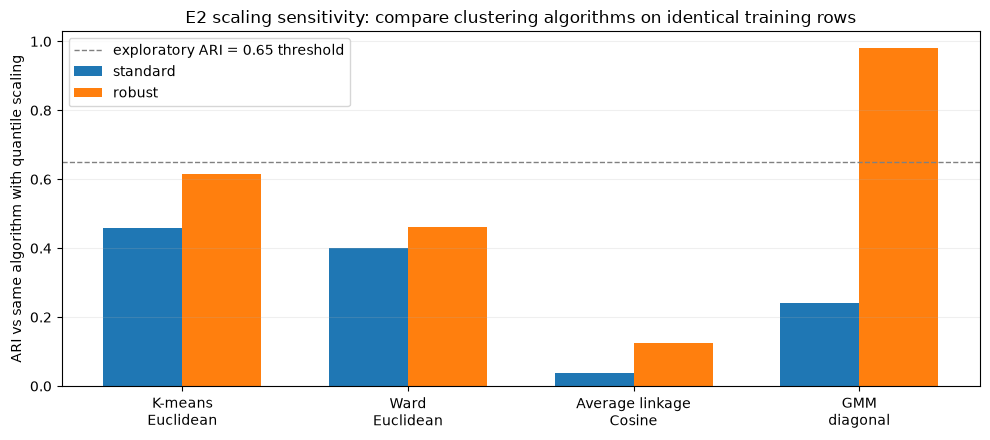

CAUTION: Algorithm differences may change silhouettes and cluster meaning. A robust method is not automatically better for helpfulness or unusual-review research.


In [67]:
# Controlled E2 method × scaler stress test: same rows, same feature definitions, same k.
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import normalize
from scipy import sparse

E2_METHODS_SAMPLE_SIZE = 1600  # Agglomerative methods require roughly O(n²) memory/time.
E2_METHODS_SILHOUETTE_ROWS = 700
E2_METHODS_SCALERS = ('quantile', 'standard', 'robust')
E2_METHODS = ('kmeans_euclidean', 'ward_euclidean', 'average_cosine', 'gaussian_mixture_diag')
E2_METHODS_MIN_SCALING_ARI = 0.65  # Reporting guideline, NOT an assignment requirement.

_e2_n = min(int(E2_METHODS_SAMPLE_SIZE), len(br_train))
_e2_k = int(E_SPLIT_MODELS['E2_remaining_behavior']['k'])
if _e2_n <= _e2_k + 1:
    raise ValueError(f'Need more diagnostic training rows than k={_e2_k}.')
_e2_indices = np.sort(np.random.default_rng(SEED + 231).choice(len(br_train), size=_e2_n, replace=False))
_original_e2_sample_labels = np.asarray(E_SPLIT_MODELS['E2_remaining_behavior']['train_labels'])[_e2_indices]

# These fitted transformations are trained on the FULL E2 training cohort, never on validation/test.
# Quantile representation exactly reuses E2's previously fitted X_train.
_e2_method_matrices = {'quantile': E2_X_train[_e2_indices]}
for _scaler_name in ('standard', 'robust'):
    _Xt, _Xv, *_ = _e2_blocks(br_train, br_val, scaling=_scaler_name)
    _e2_method_matrices[_scaler_name] = _Xt[_e2_indices]


def _e2_method_labels(method, X, k):
    """Fit a genuinely different clustering estimator to the SAME train rows."""
    if method == 'kmeans_euclidean':
        return KMeans(n_clusters=k, random_state=SEED, n_init=20).fit_predict(X)
    # sklearn's hierarchical clustering currently expects a dense array.
    A = X.toarray() if sparse.issparse(X) else np.asarray(X)
    if method == 'ward_euclidean':
        return AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(A)
    if method == 'average_cosine':
        # Some older sklearn versions used 'affinity' instead of 'metric'.
        try:
            estimator = AgglomerativeClustering(n_clusters=k, linkage='average', metric='cosine')
        except TypeError:
            estimator = AgglomerativeClustering(n_clusters=k, linkage='average', affinity='cosine')
        return estimator.fit_predict(A)
    if method == 'gaussian_mixture_diag':
        estimator = GaussianMixture(n_components=k, covariance_type='diag', n_init=3,
                                    reg_covar=1e-4, max_iter=200, random_state=SEED)
        return estimator.fit_predict(A)
    raise ValueError(f'Unknown clustering algorithm: {method}')

_e2_method_labels_by_name = {}
_e2_method_rows = []
for _method in E2_METHODS:
    for _scaler_name in E2_METHODS_SCALERS:
        _X = _e2_method_matrices[_scaler_name]
        _labels = np.asarray(_e2_method_labels(_method, _X, _e2_k), dtype=int)
        _e2_method_labels_by_name[(_method, _scaler_name)] = _labels
        _counts = np.bincount(_labels, minlength=_e2_k)
        _sil_metric = 'cosine' if _method == 'average_cosine' else 'euclidean'
        if len(np.unique(_labels)) > 1 and max(_counts) < len(_labels):
            _sil = float(silhouette_score(_X, _labels, metric=_sil_metric,
                                          sample_size=min(E2_METHODS_SILHOUETTE_ROWS,len(_labels)),
                                          random_state=SEED))
        else:
            _sil = np.nan
        _e2_method_rows.append({
            'algorithm': _method, 'numeric_scaler': _scaler_name,
            'k_fixed_from_E2_training': _e2_k, 'diagnostic_train_rows': _e2_n,
            'n_nonempty_clusters': int((_counts > 0).sum()),
            'min_cluster_share_including_empty': float(_counts.min() / len(_labels)),
            'largest_cluster_share': float(_counts.max() / len(_labels)),
            'silhouette_on_own_geometry': _sil,
            'silhouette_metric': _sil_metric,
            'ARI_vs_full_fitted_E2_labels_same_rows': float(adjusted_rand_score(
                _original_e2_sample_labels, _labels)),
        })

E2_METHOD_SCALER_DETAILS = pd.DataFrame(_e2_method_rows)
_e2_method_ari_rows = []
for _method in E2_METHODS:
    _baseline = _e2_method_labels_by_name[(_method, 'quantile')]
    for _scaler_name in ('standard', 'robust'):
        _ari = adjusted_rand_score(_baseline, _e2_method_labels_by_name[(_method, _scaler_name)])
        _e2_method_ari_rows.append({
            'algorithm': _method, 'reference_scaler': 'quantile',
            'alternative_scaler': _scaler_name,
            'ARI_within_method_vs_quantile': float(_ari),
            'train_rows_compared': _e2_n, 'k_fixed': _e2_k,
        })
E2_METHOD_SCALER_ARI = pd.DataFrame(_e2_method_ari_rows)
E2_METHOD_SCALING_SUMMARY = (
    E2_METHOD_SCALER_ARI.groupby('algorithm',as_index=False)
    .agg(min_alternative_scaler_ARI=('ARI_within_method_vs_quantile','min'),
         mean_alternative_scaler_ARI=('ARI_within_method_vs_quantile','mean'))
)
E2_METHOD_SCALING_SUMMARY['passes_exploratory_ARI_065'] = (
    E2_METHOD_SCALING_SUMMARY['min_alternative_scaler_ARI'] >= E2_METHODS_MIN_SCALING_ARI
)

print('Same E2 training sample; k fixed; methods independently fitted for every numerical scaler:')
display(E2_METHOD_SCALER_DETAILS.round(4))
print('Direct scaling robustness comparisons (higher ARI = closer to the same method under quantile scaling):')
display(E2_METHOD_SCALER_ARI.round(4))
display(E2_METHOD_SCALING_SUMMARY.round(4))

fig, ax = plt.subplots(figsize=(10,4.5))
_method_order = list(E2_METHODS)
_x = np.arange(len(_method_order))
for _j, _scaler_name in enumerate(('standard', 'robust')):
    _vals = [E2_METHOD_SCALER_ARI.loc[
        E2_METHOD_SCALER_ARI.algorithm.eq(_meth) &
        E2_METHOD_SCALER_ARI.alternative_scaler.eq(_scaler_name),
        'ARI_within_method_vs_quantile'].iloc[0] for _meth in _method_order]
    ax.bar(_x + (_j - 0.5)*0.35, _vals, width=0.35, label=_scaler_name)
ax.axhline(E2_METHODS_MIN_SCALING_ARI, color='gray', ls='--', lw=1,
           label='exploratory ARI = 0.65 threshold')
ax.set_xticks(_x)
ax.set_xticklabels(['K-means\nEuclidean','Ward\nEuclidean','Average linkage\nCosine','GMM\ndiagonal'])
ax.set_ylabel('ARI vs same algorithm with quantile scaling')
ax.set_title('E2 scaling sensitivity: compare clustering algorithms on identical training rows')
ax.legend(loc='best')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'phase2_E2_methods_scaling_robustness.png',dpi=160)
plt.show()

E2_METHOD_SCALER_DETAILS.to_csv(OUTPUT_DIR/'phase2_E2_methods_scaler_details.csv',index=False)
E2_METHOD_SCALER_ARI.to_csv(OUTPUT_DIR/'phase2_E2_methods_scaling_ARI.csv',index=False)
E2_METHOD_SCALING_SUMMARY.to_csv(OUTPUT_DIR/'phase2_E2_methods_scaling_summary.csv',index=False)

print('CAUTION: Algorithm differences may change silhouettes and cluster meaning. ' 
      'A robust method is not automatically better for helpfulness or unusual-review research.')

### 8.17b E2 feature-dominance audit — what actually drives the clusters?

**Research question.** E2 deliberately excludes raw ratings and explicit product-rating-history features. But its remaining inputs may still be dominated by review length, category/verification indicators, or sparse reviewer/repetition signals. This section tests **which feature groups distinguish and influence E2's actual clusters**, without using helpful votes for clustering or for selecting features.

**Three complementary diagnostics** (same 2019+ training cohort, fixed E2 `k`, frozen preprocessing, and original validation partition):

1. **Between-cluster sum of squares (BSS) decomposition:** In the *actual transformed K-means feature space*, determine the fraction of between-cluster separation attributable to each feature group. This is a descriptive geometric contribution, **not** causal importance.
2. **Validation permutation:** Jointly shuffle a group of input features across validation reviews, transform them with the **existing training-fitted encoder**, and calculate the fraction of original E2 assignments that change and their ARI. It probes dependence of a **fixed fitted model** on that group, not an out-of-sample intervention.
3. **Leave-one-group-out retraining:** Fit a fresh train-only preprocessing pipeline and K-means at the **same fixed k**, after removing each group in turn; compare its train/validation assignments with original E2. A low ARI indicates reliance on that group or an alternative clustering geometry, not necessarily a better or worse scientific discovery.

Also report **nonzero prevalence of rare behavior signals** and cluster-wise distributions. A feature appearing in only a handful of sampled reviews cannot support a broad claim about coordinated manipulation. Numeric scaling is kept **quantile** for the controlled ablations; the separate alternative-scaler tests above remain the scaling-robustness evidence.


In [68]:
# Target-free E2 feature dominance, part 1: definition, prevalence, and exact geometry.
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import QuantileTransformer
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from scipy import sparse

E2_DOM_GROUPS = {
    'review_length': [x for x in ['log1p_body_word_count'] if x in E_SPLIT_NUMERIC],
    'writing_style': [x for x in ['uppercase_ratio','non_ascii_ratio','exclamation_count','question_count'] if x in E_SPLIT_NUMERIC],
    'reviewer_activity': [x for x in ['log1p_reviewer_prior_review_count'] if x in E_SPLIT_NUMERIC],
    'repeated_interaction_or_body': [
        x for x in ['log1p_user_product_prior_interaction_count','log1p_prior_product_exact_body_count']
        if x in E_SPLIT_NUMERIC],
    'product_category': ['dataset_category'],
    'verified_purchase': ['verified_purchase_status'],
    'customer_image_presence': ['review_image_available'],
}
_e2_all_inputs = set(E_SPLIT_NUMERIC + E_SPLIT_CATEGORICAL)
assert set(sum(E2_DOM_GROUPS.values(), [])) == _e2_all_inputs, 'Every E2 predictor must belong to exactly one group.'
assert len(sum(E2_DOM_GROUPS.values(), [])) == len(_e2_all_inputs), 'Overlapping feature groups are not allowed.'
assert not any('helpful_vote' in c for c in _e2_all_inputs)
_e2_model = E_SPLIT_MODELS['E2_remaining_behavior']['model']
_e2_ref_train = np.asarray(E_SPLIT_MODELS['E2_remaining_behavior']['train_labels'])
_e2_ref_val = np.asarray(E_SPLIT_MODELS['E2_remaining_behavior']['validation_labels'])
_e2_k = int(E_SPLIT_MODELS['E2_remaining_behavior']['k'])
assert len(_e2_ref_train) == len(br_train) and len(_e2_ref_val) == len(br_val)

# IMPORTANT: reproduce the EXISTING E2 encoding rather than fitting a new representation.
def _e2_dominance_existing_transform(frame):
    numeric = E2_scaler.transform(E2_imputer.transform(frame[E_SPLIT_NUMERIC]))
    numeric = np.nan_to_num(numeric, nan=0., posinf=0., neginf=0.)
    n = normalize(sparse.csr_matrix(numeric))
    c = normalize(sparse.csr_matrix(E2_encoder.transform(
        frame[E_SPLIT_CATEGORICAL].fillna('__MISSING__').astype(str))))
    return normalize(sparse.hstack([n, c.multiply(0.6)], format='csr'))

_e2_check_train = _e2_dominance_existing_transform(br_train)
_e2_check_val = _e2_dominance_existing_transform(br_val)
assert _e2_check_train.shape == E2_X_train.shape and _e2_check_val.shape == E2_X_val.shape
assert np.allclose(_e2_check_train.toarray(), E2_X_train.toarray(), atol=1e-7), 'E2 train encoding mismatch.'
assert np.allclose(_e2_check_val.toarray(), E2_X_val.toarray(), atol=1e-7), 'E2 validation encoding mismatch.'
assert np.array_equal(_e2_model.predict(_e2_check_val), _e2_ref_val), 'E2 validation labels mismatch.'

# Map every transformed numeric (including missing indicators) / one-hot coordinate
# back to its original E2 predictor, then to its research-relevant feature group.
_e2_imputer_output_names = list(E2_imputer.get_feature_names_out(E_SPLIT_NUMERIC))
_e2_onehot_output_names = list(E2_encoder.get_feature_names_out(E_SPLIT_CATEGORICAL))
assert len(_e2_imputer_output_names) + len(_e2_onehot_output_names) == E2_X_train.shape[1]
_e2_group_by_feature = {feat: grp for grp, feats in E2_DOM_GROUPS.items() for feat in feats}
_e2_coordinate_groups = []
for generated in _e2_imputer_output_names:
    # SimpleImputer(add_indicator=True) uses missingindicator_<source feature>.
    original = generated[len('missingindicator_'):] if generated.startswith('missingindicator_') else generated
    assert original in E_SPLIT_NUMERIC, (generated,original)
    _e2_coordinate_groups.append(_e2_group_by_feature[original])
for generated in _e2_onehot_output_names:
    candidates = [feat for feat in E_SPLIT_CATEGORICAL if generated.startswith(feat+'_')]
    assert len(candidates)==1, ('Unexpected one-hot column',generated,candidates)
    _e2_coordinate_groups.append(_e2_group_by_feature[candidates[0]])

# Exact groupwise decomposition of between/within-cluster squared Euclidean variance
# for the ORIGINAL, fixed E2 labels in the ORIGINAL normalized model space.
_e2_centers = np.asarray(_e2_model.cluster_centers_)
_e2_global_mean = np.asarray(E2_X_train.mean(axis=0)).ravel()
_e2_sizes = np.bincount(_e2_ref_train, minlength=_e2_k)
_e2_x_array = E2_X_train.toarray()
_e2_bss_by_coord = ((_e2_centers-_e2_global_mean)**2 * _e2_sizes[:,None]).sum(axis=0)
_e2_wss_by_coord = ((_e2_x_array-_e2_centers[_e2_ref_train])**2).sum(axis=0)
_e2_total_bss = float(_e2_bss_by_coord.sum())
_e2_total_wss = float(_e2_wss_by_coord.sum())
E2_DOMINANCE_GEOMETRY = pd.DataFrame([{
    'feature_group': group,
    'transformed_coordinates': int(sum(g == group for g in _e2_coordinate_groups)),
    'between_cluster_SS': float(_e2_bss_by_coord[[g == group for g in _e2_coordinate_groups]].sum()),
    'within_cluster_SS': float(_e2_wss_by_coord[[g == group for g in _e2_coordinate_groups]].sum()),
} for group in E2_DOM_GROUPS])
E2_DOMINANCE_GEOMETRY['share_of_total_BSS'] = (
    E2_DOMINANCE_GEOMETRY['between_cluster_SS'] / _e2_total_bss if _e2_total_bss else np.nan)
E2_DOMINANCE_GEOMETRY['group_eta_squared'] = (
    E2_DOMINANCE_GEOMETRY['between_cluster_SS'] /
    (E2_DOMINANCE_GEOMETRY['between_cluster_SS'] + E2_DOMINANCE_GEOMETRY['within_cluster_SS']).replace(0,np.nan))
assert np.isclose(E2_DOMINANCE_GEOMETRY.between_cluster_SS.sum(),_e2_total_bss)
assert np.isclose(E2_DOMINANCE_GEOMETRY.within_cluster_SS.sum(),_e2_total_wss)

_e2_prevalence_rows = []
for name in E_SPLIT_NUMERIC:
    values = pd.to_numeric(br_train[name],errors='coerce')
    rate = float(values.fillna(0).ne(0).mean())
    _e2_prevalence_rows.append({'feature':name,'kind':'numeric',
        'nonzero_or_positive_category_share':rate,
        'missing_share':float(values.isna().mean()),
        'distinct_nonmissing_values':int(values.nunique(dropna=True)),
        'rare_nonzero_under_1pct': bool(rate<0.01)})
for name in E_SPLIT_CATEGORICAL:
    values = br_train[name].fillna('__MISSING__').astype(str)
    counts = values.value_counts(dropna=False)
    rare_share = float(counts.loc[counts < max(10, int(len(values)*0.005))].sum()/len(values)) if len(values) else np.nan
    _e2_prevalence_rows.append({'feature':name,'kind':'categorical',
        'nonzero_or_positive_category_share':np.nan,
        'missing_share':float(br_train[name].isna().mean()),
        'distinct_nonmissing_values':int(values.nunique()),
        'rare_nonzero_under_1pct':False,
        'rare_category_rows_share':rare_share})
E2_DOMINANCE_FEATURE_COVERAGE = pd.DataFrame(_e2_prevalence_rows)
print('Geometric contribution of each E2 feature group (sum BSS share = 100%):')
display(E2_DOMINANCE_GEOMETRY.sort_values('share_of_total_BSS',ascending=False).round(4))
print('Training availability and rarity of E2 raw inputs:')
display(E2_DOMINANCE_FEATURE_COVERAGE.round(4))


Geometric contribution of each E2 feature group (sum BSS share = 100%):


,feature_group,transformed_coordinates,between_cluster_SS,within_cluster_SS,share_of_total_BSS,group_eta_squared
1,writing_style,4,1988.7085,526.6366,0.7484,0.7906
0,review_length,1,665.1960,317.7964,0.2503,0.6767
6,customer_image_presence,2,1.4412,122.5750,0.0005,0.0116
5,verified_purchase,2,1.0810,130.1895,0.0004,0.0082
4,product_category,2,0.6322,625.6300,0.0002,0.0010
2,reviewer_activity,1,0.2557,130.1710,0.0001,0.0020
3,repeated_interaction_or_body,1,0.0185,8.6497,0.0000,0.0021


Training availability and rarity of E2 raw inputs:


,feature,kind,nonzero_or_positive_category_share,missing_share,distinct_nonmissing_values,rare_nonzero_under_1pct,rare_category_rows_share
0,log1p_body_word_count,numeric,0.9980,0.0,396,False,NaN
1,log1p_reviewer_prior_review_count,numeric,0.0236,0.0,5,False,NaN
2,log1p_prior_product_exact_body_count,numeric,0.0015,0.0,3,True,NaN
3,uppercase_ratio,numeric,0.9598,0.0,2652,False,NaN
4,non_ascii_ratio,numeric,0.1244,0.0,799,False,NaN
5,exclamation_count,numeric,0.1906,0.0,6,False,NaN
6,question_count,numeric,0.0188,0.0,6,False,NaN
7,dataset_category,categorical,NaN,0.0,2,False,0.0
8,verified_purchase_status,categorical,NaN,0.0,2,False,0.0
9,review_image_available,categorical,NaN,0.0,2,False,0.0


In [69]:
# Target-free E2 feature dominance, part 2: fixed-model validation permutation
# and independently refitted leave-one-group-out K-means (same E2 k and train rows).
E2_DOMINANCE_PERMUTATION = []
_dom_rng = np.random.default_rng(SEED + 2026)
for group, cols in E2_DOM_GROUPS.items():
    shuffled = br_val.copy()
    permutation = _dom_rng.permutation(len(shuffled))
    for col in cols:  # joint permutation preserves within-group relationships
        shuffled[col] = br_val[col].to_numpy()[permutation]
    perturbed_labels = _e2_model.predict(_e2_dominance_existing_transform(shuffled))
    E2_DOMINANCE_PERMUTATION.append({
        'feature_group':group,
        'validation_rows':len(shuffled),
        'changed_validation_assignment_fraction':float(np.mean(perturbed_labels!=_e2_ref_val)),
        'validation_ARI_vs_original_E2':float(adjusted_rand_score(_e2_ref_val,perturbed_labels)),
        'interpretation':'Frozen original E2 model; one group jointly permuted; no model refit',
    })
E2_DOMINANCE_PERMUTATION = pd.DataFrame(E2_DOMINANCE_PERMUTATION)

def _e2_dominance_fit_reduced_features(train, validation, numeric_cols, category_cols):
    # Same E2 train-only numeric imputation, quantile scaling, and per-block L2 normalization.
    imputer = SimpleImputer(strategy='median',add_indicator=True)
    num_train = imputer.fit_transform(train[numeric_cols])
    num_val = imputer.transform(validation[numeric_cols])
    scaler = QuantileTransformer(n_quantiles=min(256,len(train)),
        output_distribution='uniform',random_state=SEED)
    num_train = np.nan_to_num(scaler.fit_transform(num_train),nan=0.,posinf=0.,neginf=0.)
    num_val = np.nan_to_num(scaler.transform(num_val),nan=0.,posinf=0.,neginf=0.)
    encoder = _br_encoder()
    cat_train = encoder.fit_transform(train[category_cols].fillna('__MISSING__').astype(str))
    cat_val = encoder.transform(validation[category_cols].fillna('__MISSING__').astype(str))
    def fuse(n,c):
        return normalize(sparse.hstack([
            normalize(sparse.csr_matrix(n)),
            normalize(sparse.csr_matrix(c)).multiply(0.6)
        ],format='csr'))
    return fuse(num_train,cat_train), fuse(num_val,cat_val)

# First establish the paired refit baseline: same training data, k, and parameters.
_base_retrain_Xt,_base_retrain_Xv = _e2_dominance_fit_reduced_features(
    br_train,br_val,E_SPLIT_NUMERIC,E_SPLIT_CATEGORICAL)
assert np.allclose(_base_retrain_Xt.toarray(),E2_X_train.toarray(),atol=1e-7)
assert np.allclose(_base_retrain_Xv.toarray(),E2_X_val.toarray(),atol=1e-7)
_dom_baseline = KMeans(n_clusters=_e2_k,random_state=SEED,n_init=20).fit(_base_retrain_Xt)
_dom_base_t = _dom_baseline.predict(_base_retrain_Xt)
_dom_base_v = _dom_baseline.predict(_base_retrain_Xv)
assert adjusted_rand_score(_e2_ref_train,_dom_base_t)>0.9999
assert adjusted_rand_score(_e2_ref_val,_dom_base_v)>0.9999

E2_DOMINANCE_ABLATION = []
for group, deleted_cols in E2_DOM_GROUPS.items():
    num_cols = [x for x in E_SPLIT_NUMERIC if x not in deleted_cols]
    cat_cols = [x for x in E_SPLIT_CATEGORICAL if x not in deleted_cols]
    assert num_cols and cat_cols, 'Single-group ablation must leave both numeric and categorical blocks.'
    reduced_train,reduced_val = _e2_dominance_fit_reduced_features(br_train,br_val,num_cols,cat_cols)
    model = KMeans(n_clusters=_e2_k,random_state=SEED,n_init=20)
    lt = model.fit_predict(reduced_train)
    lv = model.predict(reduced_val)
    counts_t = np.bincount(lt,minlength=_e2_k)
    counts_v = np.bincount(lv,minlength=_e2_k)
    # Same held-out population, not target-controlled; silhouette is train-only.
    sil = (float(silhouette_score(reduced_train,lt,
        sample_size=min(1200,len(lt)),random_state=SEED)) if len(set(lt))>1 else np.nan)
    E2_DOMINANCE_ABLATION.append({
        'removed_feature_group':group,
        'remaining_raw_predictors':len(num_cols)+len(cat_cols),
        'k_fixed_to_E2':_e2_k,
        'ARI_train_vs_original_E2':float(adjusted_rand_score(_e2_ref_train,lt)),
        'ARI_validation_vs_original_E2':float(adjusted_rand_score(_e2_ref_val,lv)),
        'train_silhouette_reduced_space':sil,
        'train_validation_cluster_share_TV':float(_abc_tv(counts_t/counts_t.sum(),counts_v/counts_v.sum())),
        'smallest_train_cluster_share':float(counts_t.min()/counts_t.sum()),
        'smallest_validation_cluster_share':float(counts_v.min()/counts_v.sum()),
    })
E2_DOMINANCE_ABLATION=pd.DataFrame(E2_DOMINANCE_ABLATION)

# A target-free description of what each group looks like in each EXISTING E2 cluster.
E2_DOMINANCE_CLUSTER_PROFILE_ROWS=[]
for partition, frame, labs in [('2019+ train',br_train,_e2_ref_train),
                               ('validation',br_val,_e2_ref_val)]:
    local=frame.copy()
    local['_e2_cluster']=labs
    for cluster, part in local.groupby('_e2_cluster'):
        row={'partition':partition,'cluster':int(cluster),'n_reviews':len(part),
             'share':len(part)/len(local)}
        for feature in E_SPLIT_NUMERIC:
            vals=pd.to_numeric(part[feature],errors='coerce')
            row['median_'+feature]=float(vals.median()) if vals.notna().any() else np.nan
            row['nonzero_rate_'+feature]=float(vals.fillna(0).ne(0).mean())
        for feature in E_SPLIT_CATEGORICAL:
            vals=part[feature].fillna('__MISSING__').astype(str)
            row['mode_'+feature]=str(vals.mode().iloc[0]) if len(vals) else ''
            row['mode_share_'+feature]=float(vals.value_counts(normalize=True).iloc[0]) if len(vals) else np.nan
        row['customer_photo_rate']=float(part['review_image_available'].eq('yes').mean())
        row['verified_purchase_rate']=float(part['verified_purchase_status'].eq('verified').mean())
        E2_DOMINANCE_CLUSTER_PROFILE_ROWS.append(row)
E2_DOMINANCE_CLUSTER_PROFILES=pd.DataFrame(E2_DOMINANCE_CLUSTER_PROFILE_ROWS)

E2_DOMINANCE_SUMMARY = (E2_DOMINANCE_GEOMETRY[
    ['feature_group','transformed_coordinates','share_of_total_BSS','group_eta_squared']]
    .merge(E2_DOMINANCE_PERMUTATION.drop(columns='interpretation'),on='feature_group',how='left')
    .merge(E2_DOMINANCE_ABLATION, left_on='feature_group',right_on='removed_feature_group',how='left')
    .drop(columns=['removed_feature_group']))
E2_DOMINANCE_SUMMARY['validation_ARI_drop_after_ablation'] = (
    1-E2_DOMINANCE_SUMMARY['ARI_validation_vs_original_E2'])
E2_DOMINANCE_SUMMARY['validation_ARI_drop_after_permutation'] = (
    1-E2_DOMINANCE_SUMMARY['validation_ARI_vs_original_E2'])
print('E2 feature-group dominance: different columns measure DIFFERENT concepts, not one combined score.')
display(E2_DOMINANCE_SUMMARY.sort_values('share_of_total_BSS',ascending=False).round(4))
print('Target-free original E2 cluster profiles (train and validation):')
display(E2_DOMINANCE_CLUSTER_PROFILES[[
    'partition','cluster','n_reviews','share','median_log1p_body_word_count',
    'nonzero_rate_log1p_reviewer_prior_review_count',
    'nonzero_rate_log1p_prior_product_exact_body_count',
    'customer_photo_rate','verified_purchase_rate','mode_dataset_category',
]].round(3))


E2 feature-group dominance: different columns measure DIFFERENT concepts, not one combined score.


,feature_group,transformed_coordinates,share_of_total_BSS,group_eta_squared,validation_rows,changed_validation_assignment_fraction,validation_ARI_vs_original_E2,remaining_raw_predictors,k_fixed_to_E2,ARI_train_vs_original_E2,ARI_validation_vs_original_E2,train_silhouette_reduced_space,train_validation_cluster_share_TV,smallest_train_cluster_share,smallest_validation_cluster_share,validation_ARI_drop_after_ablation,validation_ARI_drop_after_permutation
1,writing_style,4,0.7484,0.7906,11998,0.6231,0.0417,6,4,-0.0002,-0.0022,0.8429,0.0293,0.0260,0.0165,1.0022,0.9583
0,review_length,1,0.2503,0.6767,11998,0.1849,0.5553,9,4,0.3541,0.3878,0.6383,0.0336,0.1605,0.1574,0.6122,0.4447
6,customer_image_presence,2,0.0005,0.0116,11998,0.0003,0.9989,9,4,0.9926,0.9929,0.3796,0.0581,0.1250,0.1573,0.0071,0.0011
5,verified_purchase,2,0.0004,0.0082,11998,0.0008,0.9975,9,4,0.9945,0.9967,0.3824,0.0585,0.1250,0.1573,0.0033,0.0025
4,product_category,2,0.0002,0.0010,11998,0.0013,0.9956,9,4,0.9962,0.9937,0.4837,0.0577,0.1250,0.1573,0.0063,0.0044
2,reviewer_activity,1,0.0001,0.0020,11998,0.0003,0.9992,9,4,0.9986,0.9992,0.4062,0.0583,0.1249,0.1573,0.0008,0.0008
3,repeated_interaction_or_body,1,0.0000,0.0021,11998,0.0000,1.0000,9,4,0.9994,0.9995,0.3978,0.0583,0.1249,0.1573,0.0005,0.0000


Target-free original E2 cluster profiles (train and validation):


,partition,cluster,n_reviews,share,median_log1p_body_word_count,nonzero_rate_log1p_reviewer_prior_review_count,nonzero_rate_log1p_prior_product_exact_body_count,customer_photo_rate,verified_purchase_rate,mode_dataset_category
0,2019+ train,0,1782,0.125,3.555,0.015,0.001,0.094,0.938,Musical_Instruments
1,2019+ train,1,2287,0.160,3.091,0.022,0.000,0.065,0.939,Musical_Instruments
2,2019+ train,2,5540,0.389,3.555,0.030,0.000,0.059,0.926,Musical_Instruments
3,2019+ train,3,4647,0.326,1.946,0.020,0.004,0.020,0.974,Musical_Instruments
4,validation,0,1934,0.161,3.611,0.014,0.001,0.147,0.938,Musical_Instruments
5,validation,1,1887,0.157,3.258,0.013,0.001,0.117,0.932,Musical_Instruments
6,validation,2,4927,0.411,3.584,0.018,0.000,0.084,0.925,Musical_Instruments
7,validation,3,3250,0.271,2.079,0.013,0.002,0.044,0.968,Musical_Instruments


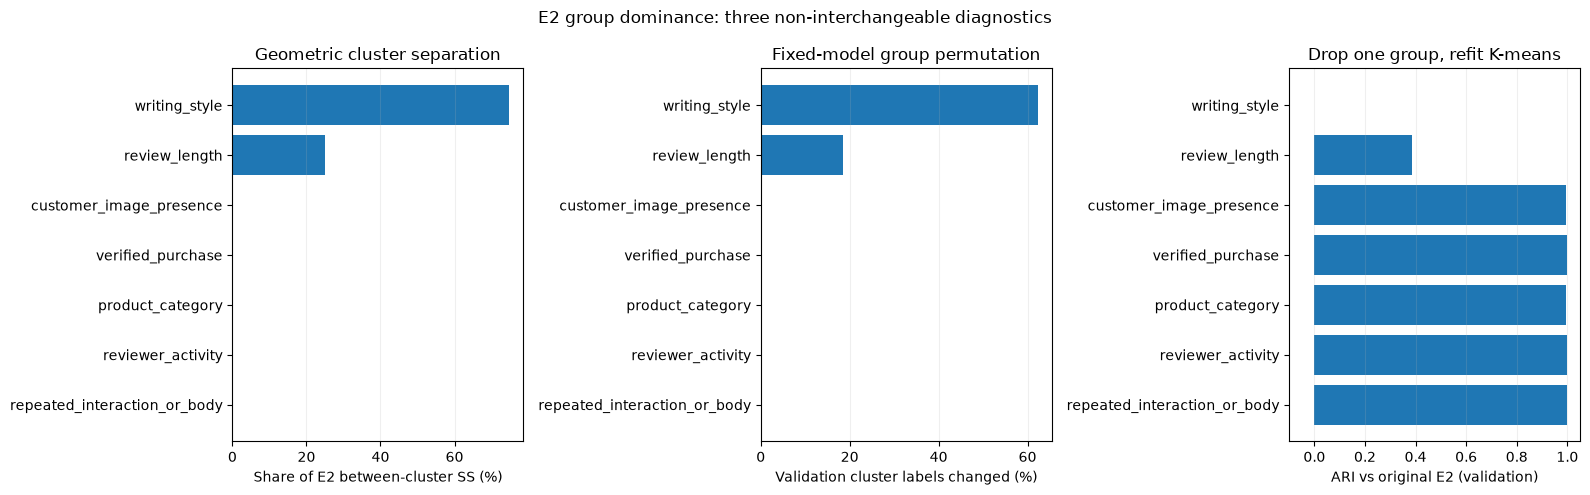

Saved E2 dominance figures, CSVs and report. Review the metrics rather than declaring one group inherently causal.


In [70]:
# E2 feature dominance outputs and visual diagnostics; optional exploratory report update.
E2_DOM_FILES = {
    'phase2_E2_dominance_geometry.csv':E2_DOMINANCE_GEOMETRY,
    'phase2_E2_dominance_feature_coverage.csv':E2_DOMINANCE_FEATURE_COVERAGE,
    'phase2_E2_dominance_permutation.csv':E2_DOMINANCE_PERMUTATION,
    'phase2_E2_dominance_group_ablation.csv':E2_DOMINANCE_ABLATION,
    'phase2_E2_dominance_cluster_profiles.csv':E2_DOMINANCE_CLUSTER_PROFILES,
    'phase2_E2_dominance_summary.csv':E2_DOMINANCE_SUMMARY,
}
for filename, table in E2_DOM_FILES.items():
    table.to_csv(OUTPUT_DIR/filename,index=False)

fig, axes = plt.subplots(1,3,figsize=(16,5))
plot=E2_DOMINANCE_SUMMARY.sort_values('share_of_total_BSS',ascending=True)
axes[0].barh(plot.feature_group,plot.share_of_total_BSS*100)
axes[0].set_xlabel('Share of E2 between-cluster SS (%)')
axes[0].set_title('Geometric cluster separation')
axes[1].barh(plot.feature_group,plot.changed_validation_assignment_fraction*100)
axes[1].set_xlabel('Validation cluster labels changed (%)')
axes[1].set_title('Fixed-model group permutation')
axes[2].barh(plot.feature_group,plot.ARI_validation_vs_original_E2)
axes[2].set_xlabel('ARI vs original E2 (validation)')
axes[2].set_xlim(-0.1,1.05)
axes[2].set_title('Drop one group, refit K-means')
for ax in axes: ax.grid(axis='x',alpha=0.2)
fig.suptitle('E2 group dominance: three non-interchangeable diagnostics')
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'phase2_E2_feature_dominance.png',dpi=160,bbox_inches='tight')
plt.show()

ranked=E2_DOMINANCE_SUMMARY.sort_values('share_of_total_BSS',ascending=False)
most_geom = ranked.iloc[0]
most_permute = E2_DOMINANCE_SUMMARY.sort_values('changed_validation_assignment_fraction',ascending=False).iloc[0]
most_ablated = E2_DOMINANCE_SUMMARY.sort_values('ARI_validation_vs_original_E2').iloc[0]
rare_features=E2_DOMINANCE_FEATURE_COVERAGE.query('kind=="numeric" and rare_nonzero_under_1pct==True')
notes=[
    '## E2 feature-dominance follow-up (target-free)',
    'All three diagnostics concern a fixed feature engineering recipe and the same E2 cohort.',
    'The largest BSS share is '+str(most_geom.feature_group)+f' ({float(most_geom.share_of_total_BSS):.1%}).',
    'Most validation label changes under permutation: '+str(most_permute.feature_group)+
      f' ({float(most_permute.changed_validation_assignment_fraction):.1%}).',
    'Most different refitted assignments when removed: '+str(most_ablated.feature_group)+
      f' (validation ARI {float(most_ablated.ARI_validation_vs_original_E2):.3f}).',
    'Rare numeric signals (<1% nonzero in sampled training reviews): '+
        (', '.join(rare_features.feature.astype(str)) if len(rare_features) else 'none'),
    'Disagreement across diagnostics is possible: BSS contribution, shuffled-input sensitivity '
    'and full refitting answer different questions.',
    'E2 excludes raw rating and product history, but a dominant result need not imply unusual or manipulated behavior.',
    'No helpful-vote targets are used to define the groups or compute the diagnostics.',
]
(OUTPUT_DIR/'phase2_E2_feature_dominance_report.md').write_text('\n\n'.join(notes)+'\n',encoding='utf-8')
print('Saved E2 dominance figures, CSVs and report. Review the metrics rather than declaring one group inherently causal.')


### 8.17c E2B — balanced representation, expanded k-search, and robustness audit

The original E2 remains unchanged. E2B uses train-fitted group scaling, with a K search expanded beyond the earlier k=6 boundary. The new checks include alternate scalers, ±20% perturbations to individual feature-family weights, temporal cluster-share drift, and target-free cluster profiles. Matched differences for **features used to construct clusters** are descriptive, not independent corroboration; the report separately evaluates withheld exact-body-reuse and rating-disagreement indicators. Passing these heuristic tests qualifies the model for further descriptive exploration only, never for fraud detection or causal inference.


In [71]:
# E2B: an independently fitted, domain-balanced alternative; not a silent replacement of E2.
from sklearn.preprocessing import QuantileTransformer, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import normalize
from scipy import sparse

E2B_FEATURE_GROUPS = {
    'review_length': ['log1p_body_word_count'],
    'writing_style': ['uppercase_ratio', 'non_ascii_ratio', 'exclamation_count', 'question_count'],
    'reviewer_activity': ['log1p_reviewer_prior_review_count'],
    'repeated_body': ['log1p_prior_product_exact_body_count', 'log1p_user_product_prior_interaction_count'],
    'product_category': ['dataset_category'],
    'verified_purchase': ['verified_purchase_status'],
    'customer_image_presence': ['review_image_available'],
}
# A priori weights, not selected by validation/test/helpful_vote. Investigate effects rather than force a pass.
E2B_GROUP_WEIGHTS = {
    'review_length': 0.5, 'writing_style': 0.5, 'reviewer_activity': 1.0,
    'repeated_body': 0.75, 'product_category': 0.45,
    'verified_purchase': 0.65, 'customer_image_presence': 0.65,
}
E2B_CLIP = 3.0
E2B_MIN_NONZERO_RATE = 0.01  # Very rare flags stay in diagnostics, not the distance geometry.
E2B_K_SEARCH_VALUES = tuple(range(2, 9))  # Check beyond the old upper boundary k=6.
E2B_MIN_WEIGHT_PERTURBATION_ARI = .65
E2B_MIN_ALTERNATIVE_SCALER_ARI = .65
E2B_MIN_CLUSTER_SHARE = .01
E2B_MAX_TEMPORAL_TV = .10
E2B_MAX_LENGTH_STYLE_BSS_SHARE = .65

class E2BGroupPreprocessor:
    """Persistable, training-fitted balanced representation. Only active, varying train columns."""
    def __init__(self, scaling='quantile_normal'):
        self.scaling = scaling
    def fit(self, train):
        self.groups = []
        self.dropped = []
        for group, candidates in E2B_FEATURE_GROUPS.items():
            numeric = [f for f in candidates if f in E_SPLIT_NUMERIC_DECLARED]
            cats = [f for f in candidates if f in E_SPLIT_CATEGORICAL]
            active_num = [f for f in numeric
                if pd.to_numeric(train[f],errors='coerce').nunique(dropna=True)>1
                and pd.to_numeric(train[f],errors='coerce').fillna(0).ne(0).mean()>=E2B_MIN_NONZERO_RATE]
            active_cat = [f for f in cats if train[f].fillna('__MISSING__').astype(str).nunique()>1]
            self.dropped.extend((group, f, 'training-constant or <1% nonzero; retain as anomaly audit') for f in numeric if f not in active_num)
            self.dropped.extend((group, f, 'constant in TRAIN') for f in cats if f not in active_cat)
            if not active_num and not active_cat:
                continue
            entry={'group':group, 'numeric':active_num, 'categorical':active_cat,
                   'weight':E2B_GROUP_WEIGHTS[group]}
            if active_num:
                imputer=SimpleImputer(strategy='median', add_indicator=True)
                x=imputer.fit_transform(train[active_num].apply(pd.to_numeric,errors='coerce'))
                if self.scaling=='quantile_normal':
                    scaler=QuantileTransformer(n_quantiles=min(256,len(train)),
                        output_distribution='normal', random_state=SEED)
                elif self.scaling=='standard':
                    scaler=StandardScaler()
                elif self.scaling=='robust':
                    scaler=RobustScaler(quantile_range=(10,90))
                else:
                    raise ValueError('Unrecognized E2B numerical scaler '+str(self.scaling))
                scaler.fit(x)
                entry.update(imputer=imputer,scaler=scaler)
            if active_cat:
                encoder=_br_encoder()
                encoder.fit(train[active_cat].fillna('__MISSING__').astype(str))
                entry['encoder']=encoder
            # Use TRAIN-only group RMS rather than row-wise group L2: retains
            # magnitude information in a one-feature family.
            _train_squared_norm=np.zeros(len(train),dtype=float)
            if active_num:
                _zn=np.nan_to_num(np.clip(scaler.transform(x),-E2B_CLIP,E2B_CLIP),
                                   nan=0.,posinf=0.,neginf=0.)
                _train_squared_norm+=np.square(_zn).sum(axis=1)
            if active_cat:
                _zc=encoder.transform(train[active_cat].fillna('__MISSING__').astype(str))
                _train_squared_norm+=np.asarray(sparse.csr_matrix(_zc).multiply(_zc).sum(axis=1)).ravel()
            entry['train_rms']=max(float(np.sqrt(_train_squared_norm.mean())),1e-8)
            self.groups.append(entry)
        if not self.groups:
            raise ValueError('No varying E2B feature groups in training')
        return self
    def transform_with_groups(self, data):
        pieces=[];coordinate_groups=[]
        for item in self.groups:
            blocks=[]
            if item['numeric']:
                raw=data[item['numeric']].apply(pd.to_numeric,errors='coerce')
                num=item['scaler'].transform(item['imputer'].transform(raw))
                num=np.nan_to_num(np.clip(num,-E2B_CLIP,E2B_CLIP),nan=0.,posinf=0.,neginf=0.)
                blocks.append(sparse.csr_matrix(num))
            if item['categorical']:
                cat=item['encoder'].transform(data[item['categorical']].fillna('__MISSING__').astype(str))
                blocks.append(sparse.csr_matrix(cat))
            whole=sparse.hstack(blocks,format='csr') if len(blocks)>1 else blocks[0]
            whole=whole.multiply(item['weight']/item['train_rms']).tocsr()
            pieces.append(whole)
            coordinate_groups.extend([item['group']]*whole.shape[1])
        unnormalized=sparse.hstack(pieces,format='csr')
        return normalize(unnormalized, copy=False),coordinate_groups
    def transform(self, data):
        return self.transform_with_groups(data)[0]

E2B_REPRESENTATIONS={}
E2B_SCALER_ROWS=[]
for _mode in ('quantile_normal','standard','robust'):
    _pre=E2BGroupPreprocessor(scaling=_mode).fit(br_train)
    _xt,_coord=_pre.transform_with_groups(br_train)
    _xv=_pre.transform(br_val)
    E2B_REPRESENTATIONS[_mode]={'preprocessor':_pre,'train':_xt,'validation':_xv,
                                'coordinate_groups':_coord}
assert E2B_REPRESENTATIONS['quantile_normal']['train'].shape[0]==len(br_train)
assert E2B_REPRESENTATIONS['quantile_normal']['validation'].shape[0]==len(br_val)
E2B_DROPPED_FEATURES=pd.DataFrame(E2B_REPRESENTATIONS['quantile_normal']['preprocessor'].dropped,
    columns=['family','feature','reason'])

_e2b_ref=E2B_REPRESENTATIONS['quantile_normal']
E2B_K,E2B_K_CANDIDATES,_=_br_choose_k(_e2b_ref['train'],'E2B_balanced',k_values=E2B_K_SEARCH_VALUES)
E2B_KMEANS=KMeans(n_clusters=E2B_K,random_state=SEED,n_init=20)
E2B_TRAIN_LABELS=E2B_KMEANS.fit_predict(_e2b_ref['train'])
E2B_VALIDATION_LABELS=E2B_KMEANS.predict(_e2b_ref['validation'])
E2B_SEED=evaluate_seed_stability(_e2b_ref['train'],k=E2B_K,
    seeds=ABC_SEED_VALUES,n_init=10)
E2B_BASE_TRAIN_SHARES=_abc_share(E2B_TRAIN_LABELS,E2B_K)
E2B_BASE_VAL_SHARES=_abc_share(E2B_VALIDATION_LABELS,E2B_K)

for _mode,_candidate in E2B_REPRESENTATIONS.items():
    if _mode=='quantile_normal':
        _lab_t,_lab_v=E2B_TRAIN_LABELS,E2B_VALIDATION_LABELS
    else:
        _km=KMeans(n_clusters=E2B_K,random_state=SEED,n_init=20)
        _lab_t=_km.fit_predict(_candidate['train'])
        _lab_v=_km.predict(_candidate['validation'])
    _shares_t=_abc_share(_lab_t,E2B_K)
    _shares_v=_abc_share(_lab_v,E2B_K)
    E2B_SCALER_ROWS.append({'scaling':_mode,'k_fixed':E2B_K,
        'train_ARI_vs_quantile_normal':float(adjusted_rand_score(E2B_TRAIN_LABELS,_lab_t)),
        'validation_ARI_vs_quantile_normal':float(adjusted_rand_score(E2B_VALIDATION_LABELS,_lab_v)),
        'train_validation_TV':_abc_tv(_shares_t,_shares_v),
        'smallest_train_cluster_share':float(_shares_t.min()),
        'smallest_validation_cluster_share':float(_shares_v.min())})
E2B_SENSITIVITY=pd.DataFrame(E2B_SCALER_ROWS)
E2B_MIN_ARI=float(E2B_SENSITIVITY.loc[
    E2B_SENSITIVITY.scaling.ne('quantile_normal'),
    ['train_ARI_vs_quantile_normal','validation_ARI_vs_quantile_normal']].min().min())

# Exact feature-family decomposition of KMeans between-cluster sum of squares.
_xt=_e2b_ref['train'].toarray()
_global=_xt.mean(axis=0)
_size=np.bincount(E2B_TRAIN_LABELS,minlength=E2B_K)
_ss=((E2B_KMEANS.cluster_centers_-_global)**2*_size[:,None]).sum(axis=0)
_sum_ss=float(_ss.sum())
E2B_FAMILY_BSS=pd.DataFrame([{'feature_family':grp,
    'transformed_coordinates':sum(x==grp for x in _e2b_ref['coordinate_groups']),
    'between_cluster_ss_share':float(_ss[[x==grp for x in _e2b_ref['coordinate_groups']]].sum()/_sum_ss)
        if _sum_ss>0 else np.nan} for grp in E2B_FEATURE_GROUPS])
E2B_STYLE_LENGTH_SHARE=float(E2B_FAMILY_BSS.loc[
    E2B_FAMILY_BSS.feature_family.isin(['writing_style','review_length']),
    'between_cluster_ss_share'].sum())

# Test the chosen partition against plausible 20% family-weight changes.
# Only the adjusted KMeans and feature geometry are refitted; all imputers/scalers
# remain TRAIN-fitted. These are sensitivity diagnostics, not hyperparameter tuning.
E2B_WEIGHT_SENSITIVITY_ROWS=[]
_e2b_base_pre=_e2b_ref['preprocessor']
for _family in ('review_length','writing_style','reviewer_activity','product_category',
                'verified_purchase','customer_image_presence'):
    _item=next((entry for entry in _e2b_base_pre.groups if entry['group']==_family),None)
    if _item is None: continue
    _original=float(_item['weight'])
    for _multiplier in (0.8,1.2):
        try:
            _item['weight']=_original*_multiplier
            _wx_train=_e2b_base_pre.transform(br_train)
            _wx_val=_e2b_base_pre.transform(br_val)
        finally:
            _item['weight']=_original
        _wkm=KMeans(n_clusters=E2B_K,random_state=SEED,n_init=20)
        _wlabels_train=_wkm.fit_predict(_wx_train)
        _wlabels_val=_wkm.predict(_wx_val)
        E2B_WEIGHT_SENSITIVITY_ROWS.append({
            'family':_family,'weight_multiplier':_multiplier,
            'train_ARI_vs_reference':float(adjusted_rand_score(E2B_TRAIN_LABELS,_wlabels_train)),
            'validation_ARI_vs_reference':float(adjusted_rand_score(E2B_VALIDATION_LABELS,_wlabels_val)),
            'train_validation_TV':_abc_tv(_abc_share(_wlabels_train,E2B_K),
                                          _abc_share(_wlabels_val,E2B_K))})
E2B_WEIGHT_SENSITIVITY=pd.DataFrame(E2B_WEIGHT_SENSITIVITY_ROWS)
E2B_MIN_WEIGHT_ARI=float(E2B_WEIGHT_SENSITIVITY[
    ['train_ARI_vs_reference','validation_ARI_vs_reference']].min().min())

# Descriptive, target-free profiles are necessary before interpreting a six-group split.
def _e2b_cluster_profiles(frame,labels,partition):
    f=frame.reset_index(drop=True).copy()
    f['_cluster']=np.asarray(labels,dtype=int)
    f['_reviewer_active']=pd.to_numeric(f['reviewer_prior_review_count'],errors='coerce').gt(0)
    f['_image']=f['review_image_available'].eq('yes')
    f['_verified']=f['verified_purchase_status'].eq('verified')
    f['_reused_body']=pd.to_numeric(f['prior_product_exact_body_count'],errors='coerce').gt(0)
    f['_games']=f['dataset_category'].eq('Video_Games')
    result=f.groupby('_cluster',observed=True).agg(
        reviews=('_cluster','size'), median_body_words=('text_word_count','median'),
        reviewer_history_rate=('_reviewer_active','mean'),
        customer_image_rate=('_image','mean'),
        verified_purchase_rate=('_verified','mean'),
        previous_exact_body_reuse_rate=('_reused_body','mean'),
        video_games_rate=('_games','mean'),
        median_rating=('rating_num','median')).reset_index().rename(columns={'_cluster':'cluster'})
    result['share']=result['reviews']/len(f)
    result.insert(0,'partition',partition)
    return result
E2B_CLUSTER_PROFILES=pd.concat([
    _e2b_cluster_profiles(br_train,E2B_TRAIN_LABELS,'2019+ train'),
    _e2b_cluster_profiles(br_val,E2B_VALIDATION_LABELS,'validation'),
],ignore_index=True)

# Compare non-target distinctiveness in the same month/category/rating/history strata.
E2B_CONDITIONAL=pd.concat([
    _matched_cluster_table(br_train,E2B_TRAIN_LABELS,'2019+ train'),
    _matched_cluster_table(br_val,E2B_VALIDATION_LABELS,'validation'),
],ignore_index=True)
_e2b_train_cond=E2B_CONDITIONAL.loc[E2B_CONDITIONAL.partition.eq('2019+ train')]
_e2b_val_cond=E2B_CONDITIONAL.loc[E2B_CONDITIONAL.partition.eq('validation')]
E2B_MATCHED=_e2b_train_cond.merge(_e2b_val_cond,on=['cluster','feature'],
    suffixes=('_train','_validation'))
E2B_MATCHED['supported_consistent_difference']=(
    E2B_MATCHED.matched_strata_train.ge(5)
    & E2B_MATCHED.matched_strata_validation.ge(3)
    & E2B_MATCHED.matched_inside_n_train.ge(30)
    & E2B_MATCHED.matched_inside_n_validation.ge(15)
    & E2B_MATCHED.difference_percentage_points_train.abs().ge(5)
    & E2B_MATCHED.difference_percentage_points_validation.abs().ge(5)
    & ((E2B_MATCHED.difference_percentage_points_train*
        E2B_MATCHED.difference_percentage_points_validation)>0)
)
E2B_ANY_MATCHED=bool(E2B_MATCHED.supported_consistent_difference.any())
# IMPORTANT: An effect on an input used to DEFINE clusters is not independent
# validation of those clusters. Keep both types of evidence separate.
# Conservatively link each post-hoc diagnostic to its directly related
# E2B model input(s), INCLUDING log / threshold transformations. A diagnostic
# is 'external' only when none of those inputs survived TRAIN fitting.
E2B_DIAGNOSTIC_INPUT_LINEAGE = {
    'very_short_body': {'log1p_body_word_count', 'text_word_count'},
    'customer_image': {'review_image_available'},
    'verified_purchase': {'verified_purchase_status'},
    'prior_reviewer_activity': {'log1p_reviewer_prior_review_count', 'reviewer_prior_review_count'},
    'previous_exact_body_reuse': {'log1p_prior_product_exact_body_count', 'prior_product_exact_body_count'},
    'large_rating_disagreement_given_context': {'rating_gap_from_prior_product'},
}
E2B_FITTED_INPUT_COLUMNS = {
    c for _group in _e2b_ref['preprocessor'].groups
    for c in (_group['numeric'] + _group['categorical'])
}
E2B_EXTERNAL_DIAGNOSTICS = {
    diagnostic for diagnostic in E2B_MATCHED['feature'].unique()
    if diagnostic in E2B_DIAGNOSTIC_INPUT_LINEAGE
    and not (E2B_DIAGNOSTIC_INPUT_LINEAGE[diagnostic] & E2B_FITTED_INPUT_COLUMNS)
}
E2B_DIAGNOSTIC_INDEPENDENCE = pd.DataFrame([
    {'feature': diagnostic,
     'related_fitted_inputs': ', '.join(sorted(E2B_DIAGNOSTIC_INPUT_LINEAGE[diagnostic] & E2B_FITTED_INPUT_COLUMNS)),
     'external_to_fitted_e2b': diagnostic in E2B_EXTERNAL_DIAGNOSTICS}
    for diagnostic in sorted(E2B_DIAGNOSTIC_INPUT_LINEAGE)
])
E2B_EXTERNAL_MATCHED=E2B_MATCHED.loc[
    E2B_MATCHED['feature'].isin(E2B_EXTERNAL_DIAGNOSTICS)].copy()
# Proof: none of the diagnostic source columns is fitted in the E2B geometry.
assert all(not (E2B_DIAGNOSTIC_INPUT_LINEAGE[d] & E2B_FITTED_INPUT_COLUMNS)
           for d in E2B_EXTERNAL_DIAGNOSTICS)
E2B_ANY_EXTERNAL_CORROBORATION=bool(
    E2B_EXTERNAL_MATCHED['supported_consistent_difference'].any())
E2B_K_AT_SEARCH_BOUNDARY=bool(E2B_K==max(E2B_K_SEARCH_VALUES))
E2B_PASS_WEIGHT_STABILITY=bool(np.isfinite(E2B_MIN_WEIGHT_ARI)
    and E2B_MIN_WEIGHT_ARI>=E2B_MIN_WEIGHT_PERTURBATION_ARI)

E2B_PASS_SCALERS=bool(np.isfinite(E2B_MIN_ARI) and E2B_MIN_ARI>=E2B_MIN_ALTERNATIVE_SCALER_ARI)
E2B_PASS_TEMPORAL=bool(E2B_BASE_VAL_SHARES.min()>=E2B_MIN_CLUSTER_SHARE and
    E2B_BASE_TRAIN_SHARES.min()>=E2B_MIN_CLUSTER_SHARE and
    _abc_tv(E2B_BASE_TRAIN_SHARES,E2B_BASE_VAL_SHARES)<=E2B_MAX_TEMPORAL_TV)
E2B_PASS_DOMINANCE=bool(E2B_STYLE_LENGTH_SHARE<=E2B_MAX_LENGTH_STYLE_BSS_SHARE)
E2B_PASS_SEED=bool(E2B_SEED['mean_pairwise_ari']>=.75)
# Distinguish unsupervised structural stability from post-hoc/input-feature or
# independent behavioral explanations. Neither makes the model a helpful-vote predictor.
E2B_STRUCTURALLY_STABLE = all([
    E2B_PASS_SCALERS, E2B_PASS_TEMPORAL, E2B_PASS_DOMINANCE,
    E2B_PASS_SEED, E2B_PASS_WEIGHT_STABILITY,
])
E2B_QUALIFIED = bool(E2B_STRUCTURALLY_STABLE)  # Backwards-compatible output field.
E2B_STATUS = ('passes exploratory STRUCTURAL checks; no predictive validity established'
              if E2B_STRUCTURALLY_STABLE else
              'fails one or more exploratory structural stability checks; keep as a diagnostic')
E2B_SUMMARY=pd.DataFrame([{'model':'E2B_balanced','k':E2B_K,
    'seed_ARI':float(E2B_SEED['mean_pairwise_ari']),
    'minimum_alternative_scaler_ARI':E2B_MIN_ARI,
    'train_validation_TV':_abc_tv(E2B_BASE_TRAIN_SHARES,E2B_BASE_VAL_SHARES),
    'minimum_train_share':float(E2B_BASE_TRAIN_SHARES.min()),
    'minimum_validation_share':float(E2B_BASE_VAL_SHARES.min()),
    'share_BSS_length_and_style':E2B_STYLE_LENGTH_SHARE,
    'matched_non_target_signal_consistent':E2B_ANY_MATCHED,
    'matched_external_diagnostic_consistent':E2B_ANY_EXTERNAL_CORROBORATION,
    'k_at_upper_search_boundary':E2B_K_AT_SEARCH_BOUNDARY,
    'minimum_group_weight_perturbation_ARI':E2B_MIN_WEIGHT_ARI,
    'pass_group_weight_stability':E2B_PASS_WEIGHT_STABILITY,
    'pass_scalers':E2B_PASS_SCALERS,'pass_temporal':E2B_PASS_TEMPORAL,
    'pass_dominance':E2B_PASS_DOMINANCE,'pass_seed':E2B_PASS_SEED,
    'qualified_exploratory':E2B_QUALIFIED,
    'structurally_stable':E2B_STRUCTURALLY_STABLE,
    'external_behavioral_corrob_available':E2B_ANY_EXTERNAL_CORROBORATION,
    'predictive_helpfulness_improvement_demonstrated':False,
    'status':E2B_STATUS}])

for _file,_df in {
    'phase2_E2B_k_selection.csv':E2B_K_CANDIDATES,
    'phase2_E2B_scaling_sensitivity.csv':E2B_SENSITIVITY,
    'phase2_E2B_family_BSS.csv':E2B_FAMILY_BSS,
    'phase2_E2B_matched_consistency.csv':E2B_MATCHED,
    'phase2_E2B_diagnostic_independence.csv':E2B_DIAGNOSTIC_INDEPENDENCE,
    'phase2_E2B_dropped_constants.csv':E2B_DROPPED_FEATURES,
    'phase2_E2B_qualification.csv':E2B_SUMMARY,
    'phase2_E2B_group_weight_sensitivity.csv':E2B_WEIGHT_SENSITIVITY,
    'phase2_E2B_cluster_profiles.csv':E2B_CLUSTER_PROFILES,
}.items(): _df.to_csv(OUTPUT_DIR/_file,index=False)
E2B_ASSIGNMENTS=[]
for _partition,_df,_labs in [('train_2019plus',br_train,E2B_TRAIN_LABELS),
                              ('validation',br_val,E2B_VALIDATION_LABELS)]:
    _out=_df[['sample_row_id','dataset_category','timestamp_dt']].copy()
    _out['split']=_partition;_out['model']='E2B_balanced';_out['cluster']=_labs
    E2B_ASSIGNMENTS.append(_out)
pd.concat(E2B_ASSIGNMENTS,ignore_index=True).to_csv(
    OUTPUT_DIR/'phase2_E2B_assignments_TARGET_FREE.csv',index=False)
# Persist only sklearn/native fitted blocks, not a __main__ notebook-defined class.
joblib.dump({'name':'E2B_balanced',
    'preprocessing_blocks':_e2b_ref['preprocessor'].groups,
    'excluded_train_features':_e2b_ref['preprocessor'].dropped,
    'kmeans':E2B_KMEANS,'k':E2B_K,'feature_groups':E2B_FEATURE_GROUPS,
    'weights':E2B_GROUP_WEIGHTS,'clip':E2B_CLIP,
    'excluded_rare_features_threshold':E2B_MIN_NONZERO_RATE,
    'trained_on':'2019plus train',
    'qualified':E2B_QUALIFIED,'selected_for_deployment':False,
    'feature_history_policy':'train-history-frozen in validation',
    'used_test_or_helpful_votes':False},OUTPUT_DIR/'phase2_E2B_balanced_candidate.joblib',compress=3)
# Reload helper for the saved native fitted blocks (requires this notebook's class definition).
def reconstruct_saved_E2B_preprocessor(saved_candidate):
    pre=E2BGroupPreprocessor(scaling='quantile_normal')
    pre.groups=saved_candidate['preprocessing_blocks']
    pre.dropped=saved_candidate['excluded_train_features']
    return pre
assert np.allclose(
    reconstruct_saved_E2B_preprocessor(joblib.load(OUTPUT_DIR/'phase2_E2B_balanced_candidate.joblib'))
        .transform(br_val.iloc[:min(5,len(br_val))]).toarray(),
    _e2b_ref['validation'][:min(5,len(br_val))].toarray(),atol=1e-6)
print('E2B group-balanced exploratory result:')
display(E2B_SUMMARY.T)
print('Alternative scalers (identical clipping and normalization):')
display(E2B_SENSITIVITY.round(4))
print('Family contributions to KMeans separation:')
display(E2B_FAMILY_BSS.round(4))
print('Training constants dropped:')
display(E2B_DROPPED_FEATURES)
print('Group-weight perturbation diagnostics:')
display(E2B_WEIGHT_SENSITIVITY.round(4))
print('Target-free E2B cluster profiles:')
display(E2B_CLUSTER_PROFILES.round(4))
print('Diagnostic independence based on active fitted E2B inputs:')
display(E2B_DIAGNOSTIC_INDEPENDENCE)
print('External (not used in fitted E2B) matched diagnostics:')
display(E2B_EXTERNAL_MATCHED.round(4))
if E2B_K_AT_SEARCH_BOUNDARY:
    print('CAUTION: k at search maximum. Expand search and confirm before treating k as settled.')
print('E2B complete train-only K-selection table:')
display(E2B_K_CANDIDATES.sort_values('k').round(4))


E2B group-balanced exploratory result:


,0
model,E2B_balanced
k,7
seed_ARI,0.999403
minimum_alternative_scaler_ARI,0.750127
train_validation_TV,0.075545
minimum_train_share,0.023569
minimum_validation_share,0.015336
share_BSS_length_and_style,0.369362
matched_non_target_signal_consistent,True
matched_external_diagnostic_consistent,False


Alternative scalers (identical clipping and normalization):


,scaling,k_fixed,train_ARI_vs_quantile_normal,validation_ARI_vs_quantile_normal,train_validation_TV,smallest_train_cluster_share,smallest_validation_cluster_share
0,quantile_normal,7,1.0000,1.0000,0.0755,0.0236,0.0153
1,standard,7,0.7913,0.7587,0.0627,0.0236,0.0153
2,robust,7,0.8165,0.7501,0.0746,0.0236,0.0153


Family contributions to KMeans separation:


,feature_family,transformed_coordinates,between_cluster_ss_share
0,review_length,1,0.3643
1,writing_style,4,0.0050
2,reviewer_activity,1,0.2053
3,repeated_body,0,0.0000
4,product_category,2,0.2337
5,verified_purchase,2,0.0984
6,customer_image_presence,2,0.0933


... (8 outputs left out)

External (not used in fitted E2B) matched diagnostics:


,partition_train,cluster,feature,matched_strata_train,matched_inside_n_train,matched_outside_n_train,difference_percentage_points_train,status_train,posthoc_target_train,partition_validation,matched_strata_validation,matched_inside_n_validation,matched_outside_n_validation,difference_percentage_points_validation,status_validation,posthoc_target_validation,supported_consistent_difference
4,2019+ train,0,previous_exact_body_reuse,79,2661,3578,-0.3555,estimable,False,validation,79,2512,2693,-0.1615,estimable,False,False
5,2019+ train,0,large_rating_disagreement_given_context,35,998,1450,1.3790,estimable,False,validation,36,762,851,-0.7031,estimable,False,False
10,2019+ train,1,previous_exact_body_reuse,81,3203,4244,-0.1266,estimable,False,validation,80,3079,3536,-0.0703,estimable,False,False
11,2019+ train,1,large_rating_disagreement_given_context,27,779,1122,0.0307,estimable,False,validation,34,706,827,-0.7927,estimable,False,False
16,2019+ train,2,previous_exact_body_reuse,51,411,7808,-0.0445,estimable,False,validation,78,564,8694,-0.0401,estimable,False,False
17,2019+ train,2,large_rating_disagreement_given_context,13,76,1239,-2.0588,estimable,False,validation,23,93,1472,-1.2726,estimable,False,False
22,2019+ train,3,previous_exact_body_reuse,70,2844,3224,0.3625,estimable,False,validation,70,1892,3192,0.2324,estimable,False,False
23,2019+ train,3,large_rating_disagreement_given_context,32,1222,1164,-1.8033,estimable,False,validation,33,647,940,0.0030,estimable,False,False
28,2019+ train,4,previous_exact_body_reuse,21,170,4732,0.0000,estimable,False,validation,22,120,4929,0.0000,estimable,False,False
29,2019+ train,4,large_rating_disagreement_given_context,1,7,135,-0.7407,estimable,False,validation,3,10,277,7.6580,estimable,False,False


E2B complete train-only K-selection table:


,k,inertia,silhouette,smallest_cluster_n,smallest_cluster_fraction,largest_cluster_fraction,fit_rows,seed_stability_ari,silhouette_rank,stability_rank,balance_rank,selection_score,model
0,2,2277.4935,0.2735,6957,0.4880,0.5120,14256,0.9963,0.1429,0.4286,1.0,0.3714,E2B_balanced
1,3,1855.4061,0.2886,336,0.0236,0.4933,14256,0.9903,0.2857,0.2857,0.5,0.3179,E2B_balanced
2,4,1532.6481,0.2905,336,0.0236,0.3523,14256,0.9984,0.4286,0.7143,0.5,0.5393,E2B_balanced
3,5,1299.6298,0.3057,336,0.0236,0.2634,14256,0.9983,0.5714,0.5714,0.5,0.5607,E2B_balanced
4,6,1130.2719,0.3289,336,0.0236,0.2513,14256,0.9987,0.7143,0.8571,0.5,0.7321,E2B_balanced
5,7,971.7566,0.3559,336,0.0236,0.2371,14256,0.9994,1.0000,1.0000,0.5,0.9250,E2B_balanced
6,8,879.7068,0.3331,336,0.0236,0.2059,14256,0.8059,0.8571,0.1429,0.5,0.5536,E2B_balanced


### 8.17d Link E2B's *already fitted* clusters to recorded helpful votes (post-hoc)

The primary project outcome is `helpful_vote`, not review authenticity. This **does not** use helpful votes in clustering, choosing `k`, scaling, feature selection or model qualification. It describes vote distributions **after** E2B has been fitted. Matched month × category comparisons partially control publication-period/category differences but **do not** control actual exposure or prove predictive value. These results are not used to to tune the clustering; supervised predictive comparisons is saved for Phase 3.


E2B: helpful-vote distributions, AFTER clustering (train and validation only):


,model,partition,cluster,n_reviews,n_valid_votes,vote_mean,vote_median,vote_p90,share_with_at_least_one_vote,mean_log1p_votes
0,E2B,train,0,2907,2907,1.0189,0.0,2.0,0.2246,0.2724
1,E2B,train,1,3354,3354,1.4407,0.0,3.0,0.3280,0.4107
2,E2B,train,2,686,686,0.7974,0.0,2.0,0.2843,0.3204
3,E2B,train,3,2939,2939,0.2583,0.0,0.0,0.0881,0.0872
4,E2B,train,4,336,336,1.2530,0.0,2.0,0.2560,0.3401
5,E2B,train,5,3396,3396,0.2105,0.0,1.0,0.1039,0.0992
6,E2B,train,6,638,638,4.2210,1.0,10.0,0.5047,0.7897
7,E2B,validation,0,2590,2590,0.8876,0.0,1.0,0.2127,0.2426
8,E2B,validation,1,3131,3131,0.8898,0.0,2.0,0.2667,0.2985
9,E2B,validation,2,654,654,0.9587,0.0,1.7,0.2462,0.2769


E2B: matched within month × category; cluster vs other reviews:


,model,partition,cluster,matched_month_category_strata,matched_cluster_rows,matched_other_rows,positive_helpful_vote_rate_difference,log1p_helpful_votes_difference,status
0,E2B,train,0,19,2907,3678,0.0915,0.1163,estimable
1,E2B,train,1,19,3354,4317,0.1563,0.2084,estimable
2,E2B,train,2,38,686,13570,0.0784,0.0701,estimable
3,E2B,train,3,19,2939,3646,-0.1481,-0.2106,estimable
4,E2B,train,4,29,308,10657,0.0519,0.0954,estimable
5,E2B,train,5,19,3396,4275,-0.2408,-0.3453,estimable
6,E2B,train,6,36,637,13072,0.3090,0.5607,estimable
7,E2B,validation,0,16,2590,2714,0.0711,0.0855,estimable
8,E2B,validation,1,16,3131,3563,0.1069,0.1300,estimable
9,E2B,validation,2,32,654,11344,0.0549,0.0659,estimable


E2B: cross-period direction checks (only meaningful where both periods have adequate strata):


,cluster,matched_month_category_strata_train,positive_helpful_vote_rate_difference_train,log1p_helpful_votes_difference_train,matched_month_category_strata_validation,positive_helpful_vote_rate_difference_validation,log1p_helpful_votes_difference_validation,positive_vote_rate_same_direction,log_votes_same_direction
0,0,19,0.0915,0.1163,16,0.0711,0.0855,True,True
1,1,19,0.1563,0.2084,16,0.1069,0.1300,True,True
2,2,38,0.0784,0.0701,32,0.0549,0.0659,True,True
3,3,19,-0.1481,-0.2106,16,-0.1562,-0.2039,True,True
4,4,29,0.0519,0.0954,24,0.1297,0.1619,True,True
5,5,19,-0.2408,-0.3453,16,-0.1852,-0.2353,True,True
6,6,36,0.3090,0.5607,31,0.1862,0.2662,True,True


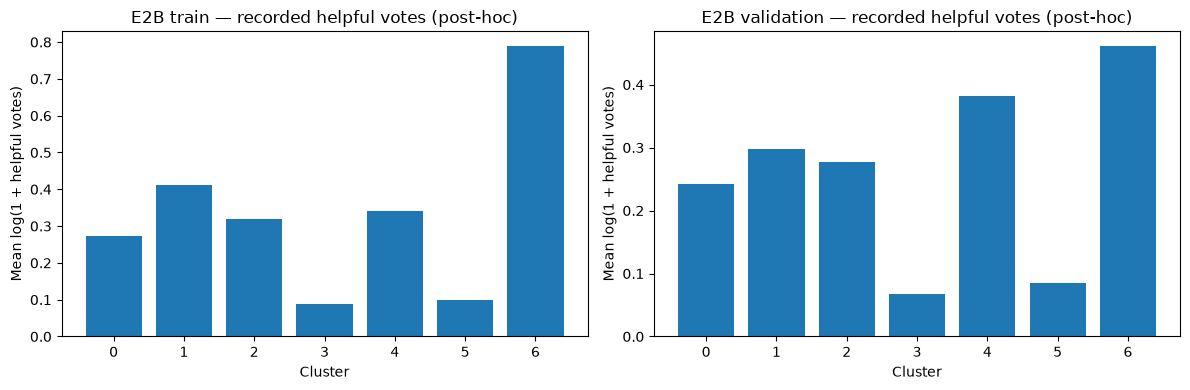

In [72]:
# TARGET-ONLY DESCRIPTIVE AUDIT: after ALL clustering choices are frozen.
# Never use the test set or these numbers to choose preprocessing, k or clustering weights.
def _phase2_helpful_profile(frame, labels, partition, model):
    labels=np.asarray(labels,dtype=int)
    if len(frame)!=len(labels): raise ValueError('Cluster labels are not row-aligned')
    raw=pd.to_numeric(frame['helpful_vote_num'],errors='coerce').to_numpy(dtype=float)
    good=np.isfinite(raw)&(raw>=0)&(raw==np.floor(raw))
    view=pd.DataFrame({'cluster':labels, 'votes':np.where(good,raw,np.nan),
                       'valid':good})
    def _p90(values):
        a=values.dropna().to_numpy(dtype=float)
        return float(np.quantile(a,.90)) if len(a) else np.nan
    view['nonzero']=np.where(view.valid, (view.votes>0).astype(float),np.nan)
    view['log1p_votes']=np.log1p(view.votes)
    p=view.groupby('cluster',as_index=False).agg(
        n_reviews=('cluster','size'), n_valid_votes=('valid','sum'),
        vote_mean=('votes','mean'),vote_median=('votes','median'),
        vote_p90=('votes',_p90), share_with_at_least_one_vote=('nonzero','mean'),
        mean_log1p_votes=('log1p_votes','mean'))
    p.insert(0,'partition',partition)
    p.insert(0,'model',model)
    return p

E2B_HELPFUL_PROFILES=pd.concat([
    _phase2_helpful_profile(br_train,E2B_TRAIN_LABELS,'train','E2B'),
    _phase2_helpful_profile(br_val,E2B_VALIDATION_LABELS,'validation','E2B'),
],ignore_index=True)
# Independent descriptive matched-stratum check; method was already defined in Section 8.9c.
E2B_HELPFUL_MATCHED=pd.concat([
    _br_time_matched_cluster_helpfulness(br_train,E2B_TRAIN_LABELS,'train',E2B_K,5),
    _br_time_matched_cluster_helpfulness(br_val,E2B_VALIDATION_LABELS,'validation',E2B_K,3),
],ignore_index=True)
E2B_HELPFUL_MATCHED.insert(0,'model','E2B')
# This table is a cross-period consistency diagnostic, not a new model-selection score.
E2B_HELPFUL_CONSISTENCY=(E2B_HELPFUL_MATCHED.loc[
    E2B_HELPFUL_MATCHED.partition.eq('train'),
    ['cluster','matched_month_category_strata','positive_helpful_vote_rate_difference',
     'log1p_helpful_votes_difference']].merge(
    E2B_HELPFUL_MATCHED.loc[E2B_HELPFUL_MATCHED.partition.eq('validation'),
    ['cluster','matched_month_category_strata','positive_helpful_vote_rate_difference',
     'log1p_helpful_votes_difference']], on='cluster',suffixes=('_train','_validation')))
E2B_HELPFUL_CONSISTENCY['positive_vote_rate_same_direction'] = (
    E2B_HELPFUL_CONSISTENCY.positive_helpful_vote_rate_difference_train *
    E2B_HELPFUL_CONSISTENCY.positive_helpful_vote_rate_difference_validation > 0)
E2B_HELPFUL_CONSISTENCY['log_votes_same_direction'] = (
    E2B_HELPFUL_CONSISTENCY.log1p_helpful_votes_difference_train *
    E2B_HELPFUL_CONSISTENCY.log1p_helpful_votes_difference_validation > 0)
for name,table in {
    'phase2_E2B_helpful_vote_profiles_POSTHOC.csv':E2B_HELPFUL_PROFILES,
    'phase2_E2B_helpful_vote_matched_month_category_POSTHOC.csv':E2B_HELPFUL_MATCHED,
    'phase2_E2B_helpful_vote_crossperiod_consistency_POSTHOC.csv':E2B_HELPFUL_CONSISTENCY,
}.items(): table.to_csv(OUTPUT_DIR/name,index=False)
print('E2B: helpful-vote distributions, AFTER clustering (train and validation only):')
display(E2B_HELPFUL_PROFILES.round(4))
print('E2B: matched within month × category; cluster vs other reviews:')
display(E2B_HELPFUL_MATCHED.round(4))
print('E2B: cross-period direction checks (only meaningful where both periods have adequate strata):')
display(E2B_HELPFUL_CONSISTENCY.round(4))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,(partition,subset) in zip(axs,E2B_HELPFUL_PROFILES.groupby('partition',sort=False)):
    ax.bar(subset.cluster.astype(str),subset.mean_log1p_votes)
    ax.set_title(f'E2B {partition} — recorded helpful votes (post-hoc)')
    ax.set_xlabel('Cluster');ax.set_ylabel('Mean log(1 + helpful votes)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'phase2_E2B_helpful_vote_by_cluster_POSTHOC.png',dpi=160)
plt.show()


### 8.18 Real product-image access and **frozen pretrained ResNet-18 embeddings**

Amazon Reviews ’23 product metadata contains **image URLs**, not image pixels. This experiment selects products reproducibly, retrieves **actual product-listing images** (not review-uploaded photos), extracts 512-dimensional embeddings from a **frozen ImageNet-pretrained ResNet-18**, and documents the exact matched review subset. No large model is trained from scratch.

**Reproducibility and URL-provenance fix:** Product selection is *category-stratified and deterministically ranked by seed + product key*, **independent of which images are already in the cache**. The exact selection, SHA-256 selection fingerprint, download outcomes, source-URL bindings, response SHA-256 hashes and image-file hashes are exported. An image file that merely opens in Pillow does NOT prove it corresponds to the current product URL. A cached image is eligible for embedding only if its authenticated-in-run acquisition sidecar binds it to a URL still listed by the product, its file hash matches, and a current HTTP 200 (matching source bytes) or conditional 304 confirms the remote resource. Old image files without provenance are not used until freshly downloaded. If the network is unavailable, unverified cached files are retained but excluded. New products are downloaded when permitted. The experiment remains an image-covered pilot, not a representative random sample of all reviews because successful URL retrieval is selective.

**Configuration:** The product-selection budgets are now 800 train / 400 validation products (increased from 400 / 200). `E_IMAGE_TRY_NETWORK=True` attempts HTTPS retrieval of missing selected images from allowlisted Amazon image hosts. Set it to `False` for an offline run; the strict provenance protocol will then *skip unconfirmed cached images*, rather than treating them as current. This is intentional and may reduce image coverage to zero. The pretrained checkpoint is loaded **locally by default** (`E_IMAGE_ALLOW_WEIGHTS_DOWNLOAD=False`); the program records a skip rather than using a randomly initialized encoder if weights are unavailable.

**Scientific interpretation:** Product images can be shared by many reviews of one product. This is not itself a bug, but results should report **both distinct products and covered review counts**, and should not be confused with an evaluation on unseen products. Image-only versus text+structured+image comparisons use the same image-covered rows. `helpful_vote` is never used to choose images, fit clusters or tune image weights; the weight sweep is a predeclared target-free sensitivity analysis, not an optimization for higher helpfulness values.


In [73]:
from pathlib import Path
# Configure a conservative, bounded real-image experiment. Uses existing joined metadata.
E_IMAGE_TRY_NETWORK = True          # Set False to use only already-cached image files.
E_IMAGE_ALLOW_WEIGHTS_DOWNLOAD = False  # OFF: avoid the earlier DNS error. Use a local official checkpoint.
# Download resnet18-f37072fd.pth via browser and place it in PROJECT_ROOT/models/ or PyTorch cache.
E_IMAGE_MANUAL_WEIGHTS_FILE = None  # Optional: absolute path, e.g. r'C:/Users/ASUS/Downloads/resnet18-f37072fd.pth'
E_IMAGE_TRAIN_MAX_PRODUCTS = 800   # deterministic category-stratified candidate budget
E_IMAGE_VALIDATION_MAX_PRODUCTS = 400   # may require new network downloads
E_IMAGE_MAX_BYTES = 7_000_000
E_IMAGE_TIMEOUT_SECONDS = 5
E_IMAGE_SEED = SEED + 1107
# Keep existing pixel files as untrusted candidates; only provenance-bound, CURRENTLY verified cache hits are eligible. Cache never affects selection.
_legacy_img_cache = LOCAL.output_root/'phase2_outputs_fused_behavior_text'/'amazon_product_images_cache'
E_IMAGE_DIR = _legacy_img_cache if _legacy_img_cache.is_dir() else LOCAL.output_root/'amazon_product_images_cache'
E_IMAGE_DIR.mkdir(parents=True,exist_ok=True)

from urllib.parse import urlparse
from urllib.request import Request, urlopen
from urllib.error import URLError, HTTPError
from io import BytesIO
import hashlib


def _e_image_urls(value):
    """Return preferred image URLs for native JSONL lists or HF dict-of-lists.

    Never mistake the presence of a URL for successful image retrieval.
    """
    candidates=[]
    if isinstance(value,list):
        ordered=sorted([x for x in value if isinstance(x,dict)],
                       key=lambda x: x.get('variant')!='MAIN')
        for obj in ordered:
            for key in ('large','hi_res','thumb'):
                u=obj.get(key)
                if isinstance(u,str) and u.startswith('https://'):candidates.append(u)
        for u in value:
            if isinstance(u,str) and u.startswith('https://'):candidates.append(u)
    elif isinstance(value,dict):
        for key in ('large','hi_res','thumb'):
            uris=value.get(key)
            if isinstance(uris,str):uris=[uris]
            if isinstance(uris,list):
                candidates += [u for u in uris if isinstance(u,str) and u.startswith('https://')]
    return list(dict.fromkeys(candidates))


def _e_safe_image_url(url):
    parsed=urlparse(url)
    host=(parsed.hostname or '').lower()
    # The Amazon dataset documents m.media-amazon.com; never fetch arbitrary input URLs.
    return parsed.scheme=='https' and host in {
        'm.media-amazon.com','images-na.ssl-images-amazon.com','images-eu.ssl-images-amazon.com',
    }


def _e_product_url_catalog(frame):
    if 'product_images' not in frame:
        return pd.DataFrame(columns=['product_key','dataset_category','url','urls','available_references'])
    records=[]
    for (_,key),g in frame.groupby(['dataset_category','_join_key'],dropna=False,sort=False):
        if pd.isna(key) or not str(key).strip():continue
        all_urls=[]
        for item in g['product_images']:
            all_urls=_e_image_urls(item)
            if all_urls:break
        valid_urls=[u for u in all_urls if _e_safe_image_url(u)]
        if valid_urls:
            records.append({'product_key':str(key),'dataset_category':str(g['dataset_category'].iloc[0]),
                            'url':valid_urls[0], 'urls':valid_urls[:3], 'available_references':len(valid_urls)})
    return pd.DataFrame(records,columns=['product_key','dataset_category','url','urls','available_references'])

E_img_train_catalog=_e_product_url_catalog(br_train)
E_img_val_catalog=_e_product_url_catalog(br_val)
E_IMAGE_SELECTION_POLICY = 'deterministic_category_stratified_sha256_rank_seed_product_key_v1'

def _e_pick_catalog(catalog, max_n, seed):
    """Deterministically select product keys without consulting the image cache.

    This fixes the old cache-first sample drift. A repeat run with the same
    input catalog, seed and budget selects identical products whether or not
    any image bytes have already been downloaded.
    """
    if catalog.empty:
        return catalog.copy()
    cat_order = sorted(catalog['dataset_category'].astype(str).unique())
    quota, remainder = divmod(int(max_n), len(cat_order))
    parts=[]
    for i, cat in enumerate(cat_order):
        group = catalog.loc[catalog['dataset_category'].astype(str).eq(cat)].copy()
        cap = quota + int(i < remainder)
        # Hash rank is independent of DataFrame order and external cache state.
        group['_selection_rank'] = [
            hashlib.sha256(f'{seed}|{cat}|{key}'.encode('utf-8')).hexdigest()
            for key in group['product_key'].astype(str)
        ]
        group = group.sort_values(['_selection_rank','product_key'], kind='mergesort')
        parts.append(group.head(cap).drop(columns='_selection_rank'))
    result = pd.concat(parts, ignore_index=True)
    print(f'Image selection: deterministic seed={seed}, selected {len(result)}/{max_n} '
          'products (cache contents NOT consulted)')
    return result

E_img_train_selection = _e_pick_catalog(E_img_train_catalog, E_IMAGE_TRAIN_MAX_PRODUCTS, E_IMAGE_SEED)
E_img_val_selection = _e_pick_catalog(E_img_val_catalog, E_IMAGE_VALIDATION_MAX_PRODUCTS, E_IMAGE_SEED + 1)
E_img_selected_split = pd.concat([
    E_img_train_selection.assign(source_split='train'),
    E_img_val_selection.assign(source_split='validation'),
], ignore_index=True)
# Distinct product images can serve more than one review or both periods.
E_img_requested = E_img_selected_split.drop_duplicates(
    subset=['dataset_category','product_key'], keep='first').reset_index(drop=True)
E_img_selected_split.to_csv(OUTPUT_DIR/'phase2_image_selected_products_by_split.csv', index=False)
E_img_requested.to_csv(OUTPUT_DIR/'phase2_image_selected_unique_products.csv', index=False)
_e_selection_canonical = E_img_selected_split[
    ['source_split','dataset_category','product_key']].to_csv(index=False, lineterminator='\n')
E_IMAGE_SELECTION_SHA256 = hashlib.sha256(_e_selection_canonical.encode('utf-8')).hexdigest()
(OUTPUT_DIR/'phase2_image_selection_provenance.json').write_text(json.dumps({
    'selection_policy': E_IMAGE_SELECTION_POLICY,
    'selection_seed_train': int(E_IMAGE_SEED),
    'selection_seed_validation': int(E_IMAGE_SEED + 1),
    'train_max_products': int(E_IMAGE_TRAIN_MAX_PRODUCTS),
    'validation_max_products': int(E_IMAGE_VALIDATION_MAX_PRODUCTS),
    'selected_train_products': int(len(E_img_train_selection)),
    'selected_validation_products': int(len(E_img_val_selection)),
    'selected_distinct_products': int(len(E_img_requested)),
    'selected_keys_sha256': E_IMAGE_SELECTION_SHA256,
    'helpful_vote_used_in_selection': False,
    'cache_used_for_selection': False,
    'cache_reused_only_after_selection': True,
    'selection_not_a_representative_review_sample': True,
}, indent=2), encoding='utf-8')
assert E_img_train_selection[['dataset_category','product_key']].reset_index(drop=True).equals(
    _e_pick_catalog(E_img_train_catalog, E_IMAGE_TRAIN_MAX_PRODUCTS, E_IMAGE_SEED)[
        ['dataset_category','product_key']].reset_index(drop=True))
print('Product images with usable Amazon URL references (NOT verified HTTP):',
      'train', len(E_img_train_catalog), 'validation', len(E_img_val_catalog))
print('Distinct selected product URLs queued:', len(E_img_requested))
print('Frozen selection fingerprint:', E_IMAGE_SELECTION_SHA256[:16])

# Actual network access test + cache. Never use a dataset URL that is not a product-image URL.
try:
    from PIL import Image
    _image_pil_available=True
except ImportError:
    _image_pil_available=False

# Strict default: no cached pixel may enter a model without a source URL binding
# and a CURRENT remote 200/304 verification on this execution. Local image validity
# alone establishes neither historical URL provenance nor current correspondence.
E_IMAGE_REQUIRE_CURRENT_URL_VERIFICATION = True
assert E_IMAGE_REQUIRE_CURRENT_URL_VERIFICATION, "Do not use stale cache in this strict image audit."


def _e_file_sha256(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''):
            h.update(block)
    return h.hexdigest()


def _e_valid_pixel_file(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except (OSError,ValueError):
        return False


def _e_read_provenance(sidecar,category,key,urls,path):
    """Require a product+current-listed-URL binding AND matching cached-byte SHA256."""
    if not path.is_file():
        return None,'no_pixel_file'
    if not sidecar.is_file():
        return None,'legacy_cache_missing_provenance'
    try:
        info=json.loads(sidecar.read_text(encoding='utf-8'))
        if (info.get('schema_version')!=1 or
            info.get('dataset_category')!=category or
            info.get('product_key')!=key or
            info.get('requested_url') not in urls or
            not _e_safe_image_url(info.get('requested_url','')) or
            not _e_safe_image_url(info.get('final_url','')) or
            not re.fullmatch(r'[a-f0-9]{64}',str(info.get('source_content_sha256',''))) or
            not re.fullmatch(r'[a-f0-9]{64}',str(info.get('cached_image_sha256',''))) or
            not info.get('retrieved_at_utc')):
            return None,'provenance_missing_or_url_mismatch'
        if path.stat().st_size<=0 or path.stat().st_size>E_IMAGE_MAX_BYTES:
            return None,'bad_cached_file_size'
        if _e_file_sha256(path)!=info['cached_image_sha256']:
            return None,'cached_image_sha256_mismatch'
        if not _e_valid_pixel_file(path):
            return None,'cached_image_decode_failed'
        return info,'provenance_bound_to_current_listed_url'
    except (OSError,ValueError,TypeError,KeyError):
        return None,'malformed_provenance'


def _e_write_provenance(sidecar,info):
    # Atomic file replacement: interrupted runs cannot leave half-written evidence.
    tmp=sidecar.with_name(sidecar.name+'.tmp.'+str(os.getpid()))
    tmp.write_text(json.dumps(info,indent=2,sort_keys=True),encoding='utf-8')
    os.replace(tmp,sidecar)


def _e_image_record(status, path='', used_url='', http_status=np.nan,
                    nbytes=0, provenance_verified=False,
                    current_url_verified=False, verification_method='',
                    provenance_reason='', source_sha256=''):
    return {'status':status,'http_status':http_status,'bytes':nbytes,
            'path':str(path) if path else '', 'used_url':used_url,
            'provenance_verified':bool(provenance_verified),
            'current_url_verified':bool(current_url_verified),
            'verification_method':verification_method,
            'provenance_reason':provenance_reason,
            'source_sha256':source_sha256}


def _e_fetch_image(row):
    key=str(row['product_key'])
    category=str(row['dataset_category'])
    urls=[u for u in row['urls'] if _e_safe_image_url(u)] if isinstance(row['urls'],list) else []
    digest=hashlib.sha256((category+'|'+key).encode('utf-8')).hexdigest()[:24]
    path=E_IMAGE_DIR/(digest+'.jpg')
    sidecar=path.with_suffix('.provenance.json')
    if not _image_pil_available:
        return _e_image_record('missing_pillow')
    if not urls:
        return _e_image_record('blocked_untrusted_host')

    old,reason=_e_read_provenance(sidecar,category,key,urls,path)
    if not E_IMAGE_TRY_NETWORK:
        # Even a URL-bound old sidecar cannot prove the CURRENT remote URL's bytes.
        return _e_image_record('cached_current_unverified' if old else
                               'offline_'+reason,provenance_reason=reason,
                               used_url=old['requested_url'] if old else '',
                               source_sha256=old['source_content_sha256'] if old else '',
                               provenance_verified=old is not None)

    # Prefer the exact historically verified URL while it is still in the product's
    # CURRENT list. With a stored validator, 304 verifies the existing source bytes.
    order=([old['requested_url']]+[u for u in urls if u!=old['requested_url']]
           if old is not None else urls)
    last=_e_image_record('unretrievable',provenance_reason=reason)
    for url in order[:3]:
        headers={'User-Agent':'Mozilla/5.0','Accept':'image/jpeg,image/png,image/webp,image/*'}
        if old is not None and url==old['requested_url']:
            if old.get('etag'): headers['If-None-Match']=old['etag']
            if old.get('last_modified'): headers['If-Modified-Since']=old['last_modified']
        try:
            req=Request(url,headers=headers)
            try:
                response=urlopen(req,timeout=E_IMAGE_TIMEOUT_SECONDS)
            except HTTPError as exc:
                if exc.code!=304 or old is None or url!=old['requested_url']:
                    raise
                response=exc
            with response as resp:
                status=int(getattr(resp,'status',getattr(resp,'code',200)))
                final_url=resp.geturl() or url
                if not _e_safe_image_url(final_url):
                    last=_e_image_record('blocked_redirect_host',used_url=url,http_status=status)
                    continue
                if status==304:
                    if not ('If-None-Match' in headers or 'If-Modified-Since' in headers):
                        last=_e_image_record('unexpected_unconditional_304',used_url=url,http_status=304)
                        continue
                    # Only the *validated provenance-bound* source can pass 304.
                    old['last_verified_at_utc']=pd.Timestamp.now(tz='UTC').isoformat()
                    old['last_verification_http_status']=304
                    _e_write_provenance(sidecar,old)
                    return _e_image_record('cached_http_304_verified',path,url,304,
                        path.stat().st_size,True,True,'conditional_http_304',reason,
                        old['source_content_sha256'])
                if status!=200:
                    last=_e_image_record('unexpected_http_status',used_url=url,http_status=status)
                    continue
                ctype=resp.headers.get('Content-Type','').lower()
                if not ctype.startswith('image/'):
                    last=_e_image_record('non_image_response',used_url=url,http_status=status)
                    continue
                content=resp.read(E_IMAGE_MAX_BYTES+1)
                if not content or len(content)>E_IMAGE_MAX_BYTES:
                    last=_e_image_record('empty_or_oversized_image',used_url=url,http_status=status,
                                          nbytes=len(content))
                    continue
                etag=resp.headers.get('ETag')
                last_modified=resp.headers.get('Last-Modified')
            source_sha=hashlib.sha256(content).hexdigest()
            # A fresh HTTP 200 binds the current URL to the downloaded source bytes.
            # If these match earlier provenance, the cached JPEG is still bound.
            if (old is not None and url==old['requested_url'] and
                source_sha==old['source_content_sha256']):
                old['last_verified_at_utc']=pd.Timestamp.now(tz='UTC').isoformat()
                old['last_verification_http_status']=200
                old['etag']=etag
                old['last_modified']=last_modified
                _e_write_provenance(sidecar,old)
                return _e_image_record('cached_http_200_verified',path,url,200,
                    path.stat().st_size,True,True,'source_sha256_http_200',reason,source_sha)
            # New or changed image: decode fresh source pixels and atomically
            # replace both JPEG and its provenance. No blind old-cache reuse.
            with Image.open(BytesIO(content)) as im:
                im.load()
                rgb=im.convert('RGB')
                tmp=path.with_name(path.stem+'.tmp.'+str(os.getpid())+'.jpg')
                try:
                    rgb.save(tmp,format='JPEG',quality=88)
                    if not _e_valid_pixel_file(tmp):
                        raise ValueError('JPEG conversion invalid')
                    os.replace(tmp,path)
                finally:
                    tmp.unlink(missing_ok=True)
            now=pd.Timestamp.now(tz='UTC').isoformat()
            provenance={
                'schema_version':1,'dataset_category':category,'product_key':key,
                'requested_url':url,'final_url':final_url,
                'source_content_sha256':source_sha,
                'cached_image_sha256':_e_file_sha256(path),
                'retrieved_at_utc':now,'last_verified_at_utc':now,
                'last_verification_http_status':200,
                'etag':etag,'last_modified':last_modified,
                'content_type':ctype,
            }
            _e_write_provenance(sidecar,provenance)
            return _e_image_record('downloaded_valid' if old is None else
                'cached_refreshed_valid',path,url,200,len(content),True,True,
                'fresh_http_200',reason,source_sha)
        except HTTPError as exc:
            last=_e_image_record('http_error_'+str(exc.code),used_url=url,http_status=int(exc.code),
                                 provenance_reason=reason)
        except (URLError,OSError,ValueError,TimeoutError) as exc:
            last=_e_image_record('access_failed_'+type(exc).__name__,used_url=url,
                                 provenance_reason=reason)
            if isinstance(exc,(URLError,TimeoutError)):
                break
    # Retain offline/failed cache files, but NEVER use them as verified pixels.
    if old is not None:
        last['provenance_verified']=True
        last['source_sha256']=old['source_content_sha256']
        last['provenance_reason']='valid_local_provenance_but_current_url_unverified'
        last['status']='cached_current_unverified_'+last['status']
    return last

E_img_download_rows=[]
_network_fail_streak=0
_abort_unreachable_host=False
for _,r in E_img_requested.iterrows():
    if _abort_unreachable_host:
        # Continue to read valid cached images after aborting NETWORK requests.
        # The previous implementation incorrectly skipped cached products too.
        _orig_network_setting = E_IMAGE_TRY_NETWORK
        E_IMAGE_TRY_NETWORK = False
        try:
            result = _e_fetch_image(r)
        finally:
            E_IMAGE_TRY_NETWORK = _orig_network_setting
        if result['status'] == 'offline_not_cached':
            result['status'] = 'skipped_after_network_failure'
    else:
        result=_e_fetch_image(r)
        if any(result['status'].endswith(s) for s in
               ('access_failed_URLError','access_failed_TimeoutError','http_error_403','http_error_429')):
            _network_fail_streak+=1
        elif result['status'] not in ('offline_not_cached','missing_pillow'):
            _network_fail_streak=0
        if _network_fail_streak >= 3:
            _abort_unreachable_host=True
    E_img_download_rows.append({**{k:r[k] for k in ['product_key','dataset_category','available_references']},
                                'first_url':r['url'],**result})
if _abort_unreachable_host:
    warnings.warn('Image retrieval stopped after 3 consecutive network failures or 403/429 responses. '
                  'Check Amazon image host access, VPN/firewall/DNS, and the manifest.')
E_img_downloads=pd.DataFrame(E_img_download_rows,columns=[
    'product_key','dataset_category','available_references','first_url','status','http_status','bytes','path','used_url',
    'provenance_verified','current_url_verified','verification_method','provenance_reason','source_sha256'])
# Provenance verification is a REQUIRED property of every image passed to ResNet.
_VERIFIED_IMAGE_STATUSES = {
    'downloaded_valid','cached_refreshed_valid',
    'cached_http_200_verified','cached_http_304_verified',
}
E_img_downloads['image_valid'] = (
    E_img_downloads['status'].isin(_VERIFIED_IMAGE_STATUSES)
    & E_img_downloads['provenance_verified']
    & E_img_downloads['current_url_verified']
)
assert not E_img_downloads.loc[E_img_downloads.image_valid,
                               ['provenance_verified','current_url_verified']].eq(False).any().any()
# Extra fail-closed check: the manifest URL and sha256 must match the actual sidecar
# bound to the same product and the CURRENT selected product URL list.
for _row in E_img_downloads.loc[E_img_downloads.image_valid].itertuples(index=False):
    _catalog_record=E_img_requested.loc[
        E_img_requested.dataset_category.astype(str).eq(str(_row.dataset_category)) &
        E_img_requested.product_key.astype(str).eq(str(_row.product_key))].iloc[0]
    _bound,_why=_e_read_provenance(Path(_row.path).with_suffix('.provenance.json'),
        str(_row.dataset_category),str(_row.product_key),_catalog_record['urls'],Path(_row.path))
    assert _bound is not None and _bound['requested_url']==_row.used_url, (_row.product_key,_why)
    assert _bound['source_content_sha256']==_row.source_sha256


def _e_cached_file_sha256(row):
    if not row['image_valid'] or not row['path']:
        return ''
    try:
        digest = hashlib.sha256()
        with open(row['path'], 'rb') as handle:
            for block in iter(lambda: handle.read(1024 * 1024), b''):
                digest.update(block)
        return digest.hexdigest()
    except OSError:
        return ''

E_img_downloads['image_sha256'] = E_img_downloads.apply(_e_cached_file_sha256, axis=1)
# Keep the real path in memory for encoding, but avoid exporting personal machine paths.
E_img_downloads['cache_filename'] = E_img_downloads['path'].apply(
    lambda path: Path(path).name if isinstance(path, str) and path else '')
E_img_downloads.drop(columns=['path']).to_csv(
    OUTPUT_DIR/'phase2_product_image_access_manifest.csv', index=False)
print('Actual product-image access results:')
if len(E_img_downloads):
    display(E_img_downloads.status.value_counts(dropna=False).rename_axis('download_status').to_frame('products'))
    print('CURRENT-URL verified image fraction:',round(E_img_downloads.image_valid.mean(),4))
    print('Old caches without sidecars and unverified cached URLs are excluded from the embeddings.')
else:
    print('No product-image URLs in the selected dataset frame; visual experiment skipped.')


Image selection: deterministic seed=1149, selected 800/800 products (cache contents NOT consulted)
Image selection: deterministic seed=1150, selected 400/400 products (cache contents NOT consulted)
Image selection: deterministic seed=1149, selected 800/800 products (cache contents NOT consulted)
Product images with usable Amazon URL references (NOT verified HTTP): train 8763 validation 7724
Distinct selected product URLs queued: 1182
Frozen selection fingerprint: 4a3b89699451c7aa
Actual product-image access results:


,products
download_status,
cached_http_304_verified,1181
cached_current_unverified_access_failed_TimeoutError,1


CURRENT-URL verified image fraction: 0.9992
Old caches without sidecars and unverified cached URLs are excluded from the embeddings.


#### Pretrained ResNet-18 checkpoint: verified local ImageNet weights

The actual image encoder requires an **official pretrained ResNet-18 checkpoint**, not randomly initialized weights. The following code verifies the file’s SHA-256 prefix encoded in the official checkpoint filename **before loading it**, and saves its full digest in the encoder metadata. The next cell checks these locations in order:

1. `E_IMAGE_MANUAL_WEIGHTS_FILE` if provided in Section 8.18.
2. `<PROJECT_ROOT>/models/resnet18-f37072fd.pth`.
3. PyTorch's `hub/checkpoints` cache.
4. Your local `Downloads` folder.

If no checkpoint is available, the visual experiment is **skipped** with a recorded reason. You can obtain the [official weights](https://download.pytorch.org/models/resnet18-f37072fd.pth) separately and place them in one of those locations. The model does not train ResNet from scratch; it extracts **512-dimensional** penultimate representations. The image access cell reports the current number of valid product images, which may change as new images are downloaded. Previous run counts should not be assumed to remain true.


In [74]:
# Convert *actual downloaded image pixels* to frozen pretrained embeddings, then
# compare behavior-only E2 vs E2 + vision on exactly the same image-covered rows.
E_img_embedding_result={'executed':False,'reason':'not enough accessible local image pixels'}
E_img_comparison=pd.DataFrame()
E_img_embeddings=pd.DataFrame()
E_img_vision_model=None
E_img_vision_manifest=pd.DataFrame()

if E_img_downloads.image_valid.sum() >= 12:
    try:
        import torch
        import torchvision
        from torchvision.models import resnet18, ResNet18_Weights
        import torch.nn as nn
        weights = ResNet18_Weights.IMAGENET1K_V1
        pretrained_filename = weights.url.rsplit('/', 1)[-1]
        search_candidates = []
        if E_IMAGE_MANUAL_WEIGHTS_FILE is not None:
            search_candidates.append(Path(E_IMAGE_MANUAL_WEIGHTS_FILE).expanduser())
        search_candidates += [
            PROJECT_ROOT/'models'/pretrained_filename,
            Path(torch.hub.get_dir())/'checkpoints'/pretrained_filename,
            Path.home()/'Downloads'/pretrained_filename,
            OUTPUT_DIR/pretrained_filename,
        ]
        available_checkpoint = next((p for p in search_candidates if p.is_file()), None)
        print('ResNet-18 checkpoint lookup:', available_checkpoint or 'not found locally')
        # Official torchvision filename contains the first 8 hex digits of SHA-256.
        # Verify file CONTENTS, not just the filename or state-dict compatibility.
        expected_checkpoint_sha256_prefix = pretrained_filename.rsplit('-', 1)[-1].split('.')[0]
        if not re.fullmatch(r'[0-9a-fA-F]{8,64}', expected_checkpoint_sha256_prefix):
            raise ValueError('Could not derive an official checkpoint hash from '+pretrained_filename)
        def _e_checkpoint_sha256(path):
            h = hashlib.sha256()
            with Path(path).open('rb') as f:
                for block in iter(lambda: f.read(1024 * 1024), b''):
                    h.update(block)
            return h.hexdigest()
        checkpoint_sha256 = None
        checkpoint_sha256_verified = False
        if available_checkpoint is None and not E_IMAGE_ALLOW_WEIGHTS_DOWNLOAD:
            raise FileNotFoundError(
                'Official ImageNet-pretrained ResNet18 checkpoint not found. '
                'Download resnet18-f37072fd.pth in your browser from '
                'https://download.pytorch.org/models/resnet18-f37072fd.pth '
                'and place it in PROJECT_ROOT/models/, Downloads, or PyTorch cache, '
                'or set E_IMAGE_MANUAL_WEIGHTS_FILE. Searched: ' +
                '; '.join(str(p) for p in search_candidates)
            )
        if available_checkpoint is not None:
            checkpoint_sha256 = _e_checkpoint_sha256(available_checkpoint)
            if not checkpoint_sha256.startswith(expected_checkpoint_sha256_prefix):
                raise ValueError('ResNet-18 checkpoint SHA-256 mismatch; refusing to load '+available_checkpoint.name)
            checkpoint_sha256_verified = True
            # weights_only=True avoids deserializing arbitrary Python objects.
            E_img_vision_model = resnet18(weights=None)
            state = torch.load(str(available_checkpoint), map_location='cpu', weights_only=True)
            E_img_vision_model.load_state_dict(state, strict=True)
            image_weight_location = available_checkpoint.name  # no machine-local directories in exports
        else:
            # Explicit opt-in only: download with content-hash checking BEFORE torch.load.
            # This branch is disabled by default; all normal runs use verified local weights.
            from torch.hub import download_url_to_file
            downloaded_checkpoint = Path(torch.hub.get_dir())/'checkpoints'/pretrained_filename
            downloaded_checkpoint.parent.mkdir(parents=True, exist_ok=True)
            download_url_to_file(weights.url, str(downloaded_checkpoint),
                                 hash_prefix=expected_checkpoint_sha256_prefix, progress=True)
            checkpoint_sha256 = _e_checkpoint_sha256(downloaded_checkpoint)
            if not checkpoint_sha256.startswith(expected_checkpoint_sha256_prefix):
                raise ValueError('Downloaded ResNet-18 checkpoint failed SHA-256 verification')
            checkpoint_sha256_verified = True
            E_img_vision_model = resnet18(weights=None)
            state = torch.load(str(downloaded_checkpoint), map_location='cpu', weights_only=True)
            E_img_vision_model.load_state_dict(state, strict=True)
            image_weight_location = weights.url
        print('Official ResNet-18 SHA-256 verified:', checkpoint_sha256[:16])
        E_img_vision_model.fc = nn.Identity()  # 512-dimensional penultimate features
        E_img_vision_model.eval()
        transform = weights.transforms()
        embeddings=[];embed_keys=[];embed_categories=[];failures=[]
        with torch.inference_mode():
            for row in E_img_downloads.loc[E_img_downloads.image_valid].itertuples(index=False):
                try:
                    with Image.open(row.path) as im:
                        x=transform(im.convert('RGB')).unsqueeze(0)
                    z=E_img_vision_model(x).cpu().numpy().astype('float32').reshape(-1)
                    embeddings.append(z)
                    embed_keys.append(row.product_key)
                    embed_categories.append(row.dataset_category)
                except (OSError,RuntimeError,ValueError) as exc:
                    failures.append({'product_key':row.product_key,'error':type(exc).__name__})
        if len(embeddings):
            embed_array=normalize(np.asarray(embeddings,dtype=np.float32))
            np.savez_compressed(OUTPUT_DIR/'phase2_E_product_image_resnet18_embeddings.npz',
                product_keys=np.asarray(embed_keys),categories=np.asarray(embed_categories),
                embeddings=embed_array)
            E_img_embeddings=pd.DataFrame({'dataset_category':embed_categories,
                                            'product_key':embed_keys})
            E_img_vision_manifest=pd.DataFrame(failures)
            E_img_embedding_result={
                'executed':True,'n_products_encoded':len(embed_array),
                'encoder':'frozen torchvision ResNet18 IMAGENET1K_V1',
                'embedding_dimension':int(embed_array.shape[1]),
                'weight_source':'ImageNet pretrained', 'checkpoint_location':image_weight_location,
                 'checkpoint_sha256':checkpoint_sha256,
                 'checkpoint_expected_sha256_prefix':expected_checkpoint_sha256_prefix,
                 'checkpoint_sha256_verified':bool(checkpoint_sha256_verified), 'fine_tuned':False,
                'feature_source':'actually downloaded product-image pixels',
                'image_files_saved':True,
            }
    except (ImportError,RuntimeError,OSError,FileNotFoundError,ValueError) as exc:
        E_img_embedding_result={'executed':False,'reason':type(exc).__name__+': '+str(exc)[:230]}
else:
    E_img_embedding_result={'executed':False,
        'reason':'Too few retrievable image pixels (requires >=12 actual products to attempt encoder)'}

if E_img_embedding_result['executed']:
    # Each image belongs to a product; do not treat it as a unique review image.
    key_to_pos={(str(c),str(k)):i for i,(c,k) in enumerate(zip(embed_categories,embed_keys))}
    def _e_image_rows(frame):
        indices=[key_to_pos.get((str(c),str(k))) for c,k in zip(frame.dataset_category,frame._join_key)]
        valid=np.array([j is not None for j in indices])
        Z=np.zeros((len(frame),embed_array.shape[1]),dtype='float32')
        if valid.any():Z[valid]=embed_array[np.asarray([j for j in indices if j is not None],dtype=int)]
        return valid,normalize(sparse.csr_matrix(Z))
    valid_train,Z_train_all=_e_image_rows(br_train)
    valid_val,Z_val_all=_e_image_rows(br_val)
    # Fetching one union of image files saves redundant downloads, but does NOT
    # make a product selected for one split eligible in the OTHER split.
    def _e_own_split_selected_mask(frame, selected_catalog):
        selected_keys = set(zip(selected_catalog['dataset_category'].astype(str),
                                selected_catalog['product_key'].astype(str)))
        return np.fromiter(
            ((str(category), str(key)) in selected_keys
             for category, key in zip(frame['dataset_category'], frame['_join_key'])),
            dtype=bool, count=len(frame))

    train_own_selected = _e_own_split_selected_mask(br_train, E_img_train_selection)
    val_own_selected = _e_own_split_selected_mask(br_val, E_img_val_selection)
    cross_split_train_excluded = int((valid_train & ~train_own_selected).sum())
    cross_split_val_excluded = int((valid_val & ~val_own_selected).sum())
    # A shared product can have DIFFERENT image URLs in train and validation metadata.
    # Product-key equality is insufficient: verify that the actually encoded URL is
    # in the current URL list of the corresponding split's selected catalog.
    _encoded_url_by_key = {
        (str(r.dataset_category),str(r.product_key)):str(r.used_url)
        for r in E_img_downloads.loc[E_img_downloads.image_valid].itertuples(index=False)
    }
    def _e_current_split_url_mask(frame,selected_catalog):
        _allowed = {
            (str(r.dataset_category),str(r.product_key)):set(r.urls)
            for r in selected_catalog.itertuples(index=False)
        }
        return np.fromiter((
            _encoded_url_by_key.get((str(category),str(key)),'') in
            _allowed.get((str(category),str(key)),set())
            for category,key in zip(frame.dataset_category,frame._join_key)
        ),dtype=bool,count=len(frame))
    _train_url_ok = _e_current_split_url_mask(br_train,E_img_train_selection)
    _val_url_ok = _e_current_split_url_mask(br_val,E_img_val_selection)
    cross_split_train_url_mismatch_excluded = int((valid_train & train_own_selected & ~_train_url_ok).sum())
    cross_split_val_url_mismatch_excluded = int((valid_val & val_own_selected & ~_val_url_ok).sum())
    valid_train &= train_own_selected & _train_url_ok
    valid_val &= val_own_selected & _val_url_ok
    assert not (valid_train & ~train_own_selected).any()
    assert not (valid_val & ~val_own_selected).any()
    assert not (valid_train & ~_train_url_ok).any()
    assert not (valid_val & ~_val_url_ok).any()
    print('Image rows excluded because of other-split selection / different current URL:',
          {'train_other_split':cross_split_train_excluded,
           'validation_other_split':cross_split_val_excluded,
           'train_url_mismatch':cross_split_train_url_mismatch_excluded,
           'validation_url_mismatch':cross_split_val_url_mismatch_excluded})
    E_img_embedding_result['split_specific_product_selection_enforced'] = True
    E_img_embedding_result['split_specific_current_url_binding_enforced'] = True
    E_img_embedding_result['train_url_mismatch_review_rows_excluded'] = cross_split_train_url_mismatch_excluded
    E_img_embedding_result['validation_url_mismatch_review_rows_excluded'] = cross_split_val_url_mismatch_excluded
    E_img_embedding_result['cross_split_union_only_train_rows_excluded'] = cross_split_train_excluded
    E_img_embedding_result['cross_split_union_only_validation_rows_excluded'] = cross_split_val_excluded
    E_img_embedding_result['train_own_selected_products_with_pixels'] = int(
        br_train.loc[valid_train, ['dataset_category','_join_key']].drop_duplicates().shape[0])
    E_img_embedding_result['validation_own_selected_products_with_pixels'] = int(
        br_val.loc[valid_val, ['dataset_category','_join_key']].drop_duplicates().shape[0])
    E_img_embedding_result['review_coverage_train']=float(valid_train.mean())
    E_img_embedding_result['review_coverage_validation']=float(valid_val.mean())
    E_img_embedding_result['n_train_reviews_with_pixels']=int(valid_train.sum())
    E_img_embedding_result['n_validation_reviews_with_pixels']=int(valid_val.sum())
    # Minimum sample size merely enables a PILOT; representative coverage requires much more.
    if valid_train.sum()>=60 and valid_val.sum()>=25:
        # Experimental subset only: E2 baseline is ALSO refitted on these same rows.
        b_train=E2_X_train[valid_train]
        b_val=E2_X_val[valid_val]
        v_train=Z_train_all[valid_train]
        v_val=Z_val_all[valid_val]
        E_IMAGE_WEIGHT = 0.35
        def _e_fused_with_images(b,v):
            return normalize(sparse.hstack([b,v.multiply(E_IMAGE_WEIGHT)],format='csr'))
        img_train=_e_fused_with_images(b_train,v_train)
        img_val=_e_fused_with_images(b_val,v_val)
        k, search,_ = _br_choose_k(img_train,'E2_plus_real_image_embeddings')
        noimg_model=KMeans(n_clusters=k,random_state=SEED,n_init=20)
        img_model=KMeans(n_clusters=k,random_state=SEED,n_init=20)
        noimg_train=noimg_model.fit_predict(b_train)
        noimg_val=noimg_model.predict(b_val)
        img_labels_train=img_model.fit_predict(img_train)
        img_labels_val=img_model.predict(img_val)
        def _e_im_sil(X,l):
            return float(silhouette_score(X,l,sample_size=min(1200,len(l)),random_state=SEED)) if len(np.unique(l))>1 else np.nan
        E_img_comparison=pd.DataFrame([{
            'image_model':'E2_plus_frozen_product_image_ResNet18',
            'k_selected_train_only':k,
            'same_train_rows':int(valid_train.sum()),
            'same_validation_rows':int(valid_val.sum()),
            'share_of_full_train_with_images':float(valid_train.mean()),
            'share_of_full_validation_with_images':float(valid_val.mean()),
            'silhouette_E2_only_same_rows':_e_im_sil(b_train,noimg_train),
            'silhouette_E2_plus_image_same_rows':_e_im_sil(img_train,img_labels_train),
            'ARI_train_image_vs_E2_no_image':float(adjusted_rand_score(img_labels_train,noimg_train)),
            'ARI_validation_image_vs_E2_no_image':float(adjusted_rand_score(img_labels_val,noimg_val)),
            'train_validation_TV_E2_only':_abc_tv(_abc_share(noimg_train,k),_abc_share(noimg_val,k)),
            'train_validation_TV_plus_image':_abc_tv(_abc_share(img_labels_train,k),_abc_share(img_labels_val,k)),
        }])
        E_img_comparison['representative_full_dataset_evidence'] = False
        E_img_comparison['image_added_distinct_cluster_information'] = (
            E_img_comparison['ARI_validation_image_vs_E2_no_image'].lt(0.95)
            & E_img_comparison['silhouette_E2_plus_image_same_rows'].gt(
                E_img_comparison['silhouette_E2_only_same_rows'])
        )
        joblib.dump({'image_model':img_model,'image_weight':E_IMAGE_WEIGHT,'k':k,
                     'encoder':'frozen ResNet18 IMAGENET1K_V1',
                     'image_embeddings_file':'phase2_E_product_image_resnet18_embeddings.npz',
                     'base_behavior_model':'E2 strict remaining features',
                     'train_subset_only':True,'helpful_votes_used_for_fitting':False},
                    OUTPUT_DIR/'phase2_E2_plus_images_PILOT.joblib',compress=3)
        print('Image clustering pilot (E2+actual image pixels versus E2 only, SAME ROWS):')
        display(E_img_comparison.round(4))
        # On the same subset, check whether visual clustering mostly separates product categories.
        E_img_category_mix=cluster_category_mix(br_train.loc[valid_train],img_labels_train)
        E_img_category_mix.to_csv(OUTPUT_DIR/'phase2_E_image_cluster_category_mix.csv',index=False)
        display(E_img_category_mix.round(3))
    else:
        E_img_embedding_result['reason']='Embeddings extracted, but <60 train or <25 validation reviews with pixels: no pilot.'

E_img_vision_manifest.to_csv(OUTPUT_DIR/'phase2_E_image_encode_failures.csv',index=False)
E_img_comparison.to_csv(OUTPUT_DIR/'phase2_E_image_incremental_comparison.csv',index=False)
(OUTPUT_DIR/'phase2_E_image_access_and_embeddings.json').write_text(
    json.dumps({**E_img_embedding_result,
                'successful_image_downloads':int(E_img_downloads.image_valid.sum()),
                'image_url_products_attempted':int(len(E_img_downloads)),
                'image_url_source':'Amazon Reviews 2023 joined product metadata',
                'visual_comparison_executed':bool(len(E_img_comparison)>0)},
               indent=2),encoding='utf-8')
print('Final image audit:',E_img_embedding_result)
if E_img_comparison.empty:
    print('Image clustering not run: metadata URLs are NOT equivalent to successfully downloaded pixels. See image_access_manifest.csv.')


ResNet-18 checkpoint lookup: C:\Users\ASUS\.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
Official ResNet-18 SHA-256 verified: f37072fd47e89c5e
Image rows excluded because of other-split selection / different current URL: {'train_other_split': 298, 'validation_other_split': 458, 'train_url_mismatch': 0, 'validation_url_mismatch': 0}
Image clustering pilot (E2+actual image pixels versus E2 only, SAME ROWS):


,image_model,k_selected_train_only,same_train_rows,same_validation_rows,share_of_full_train_with_images,share_of_full_validation_with_images,silhouette_E2_only_same_rows,silhouette_E2_plus_image_same_rows,ARI_train_image_vs_E2_no_image,ARI_validation_image_vs_E2_no_image,train_validation_TV_E2_only,train_validation_TV_plus_image,representative_full_dataset_evidence,image_added_distinct_cluster_information
0,E2_plus_frozen_product_image_ResNet18,4,1328,626,0.0932,0.0522,0.4209,0.3314,1.0,0.9948,0.0903,0.0919,False,False


dataset_category,cluster,Musical_Instruments,Video_Games
0,0,0.437,0.563
1,1,0.419,0.581
2,2,0.406,0.594
3,3,0.424,0.576


Final image audit: {'executed': True, 'n_products_encoded': 1181, 'encoder': 'frozen torchvision ResNet18 IMAGENET1K_V1', 'embedding_dimension': 512, 'weight_source': 'ImageNet pretrained', 'checkpoint_location': 'resnet18-f37072fd.pth', 'checkpoint_sha256': 'f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec', 'checkpoint_expected_sha256_prefix': 'f37072fd', 'checkpoint_sha256_verified': True, 'fine_tuned': False, 'feature_source': 'actually downloaded product-image pixels', 'image_files_saved': True, 'split_specific_product_selection_enforced': True, 'split_specific_current_url_binding_enforced': True, 'train_url_mismatch_review_rows_excluded': 0, 'validation_url_mismatch_review_rows_excluded': 0, 'cross_split_union_only_train_rows_excluded': 298, 'cross_split_union_only_validation_rows_excluded': 458, 'train_own_selected_products_with_pixels': 800, 'validation_own_selected_products_with_pixels': 399, 'review_coverage_train': 0.0931537598204265, 'review_coverage_validat

### 8.18a Controlled three-modality comparison on the **same image-covered reviews**

This compares (A) **review-body TF-IDF → train-fitted SVD + numerical/categorical structured features**, against (B) the **same representation plus actual frozen ResNet-18 product-image embeddings**. Both models receive exactly the same training and validation review rows, with each split restricted to its independently selected product set. To compare cluster profiles by number, image-model cluster IDs are optimally aligned to the baseline using **training assignments only**; the mapping is then applied unchanged to validation (ARI is permutation-invariant). `k` is selected from training features only, using the *nonimage* baseline, then held fixed for the image comparison. Weights are declared before seeing results. Success at fetching the deterministically selected images can still bias the covered sample; if images/weights are unavailable the experiment is **skipped and reported as such**. Helpful votes are not used for fitting or comparison selection.

Silhouettes computed in different representation spaces are descriptive and not a direct accuracy comparison. Identical assignments do **not** prove images lack predictive value for Phase 3 regression.


In [75]:
# Controlled matched-row three-modality PILOT. No target is used to fit representations or clusters.
E3_IMAGE_WEIGHT=0.35
E3_TEXT_WEIGHT=1.0
E3_NUMERIC_WEIGHT=1.0
E3_CATEGORICAL_WEIGHT=1.0
E3_MIN_TRAIN_ROWS=60
E3_MIN_VALIDATION_ROWS=25
E3_COMPARISON=pd.DataFrame()
E3_K_SEARCH=pd.DataFrame()
E3_HELPFUL_POSTHOC=pd.DataFrame()
E3_STATUS={'executed':False,'reason':'No image-covered subset with pretrained ResNet18 embeddings'}

if E_img_embedding_result.get('executed',False):
    if valid_train.sum()>=E3_MIN_TRAIN_ROWS and valid_val.sum()>=E3_MIN_VALIDATION_ROWS:
        def _e3_blocks(numeric,categorical,text,images,mask):
            # All text and categorical encoders were fitted on 2019+ training rows above.
            # Image vectors come from an official frozen pretrained model, not our helpful-vote target.
            n=normalize(sparse.csr_matrix(numeric[mask]))
            c=normalize(sparse.csr_matrix(categorical[mask]))
            t=normalize(sparse.csr_matrix(text[mask]))
            v=normalize(sparse.csr_matrix(images[mask]))
            common=[n.multiply(E3_NUMERIC_WEIGHT),c.multiply(E3_CATEGORICAL_WEIGHT),
                    t.multiply(E3_TEXT_WEIGHT)]
            base=normalize(sparse.hstack(common,format='csr'))
            combined=normalize(sparse.hstack(common+[v.multiply(E3_IMAGE_WEIGHT)],format='csr'))
            return base,combined
        E3_BASE_TRAIN,E3_MULTI_TRAIN=_e3_blocks(
            br_num_train,br_cat_train,br_text_train,Z_train_all,valid_train)
        E3_BASE_VAL,E3_MULTI_VAL=_e3_blocks(
            br_num_val,br_cat_val,br_text_val,Z_val_all,valid_val)
        assert E3_BASE_TRAIN.shape[0] == E3_MULTI_TRAIN.shape[0] == int(valid_train.sum())
        assert E3_BASE_VAL.shape[0] == E3_MULTI_VAL.shape[0] == int(valid_val.sum())
        # One common k (chosen without images or targets) ensures comparable partitions.
        E3_K,E3_K_SEARCH,_ = _br_choose_k(E3_BASE_TRAIN,'E3_text_structured_base')
        E3_BASE_KMEANS=KMeans(n_clusters=E3_K,random_state=SEED,n_init=20)
        E3_MULTI_KMEANS=KMeans(n_clusters=E3_K,random_state=SEED,n_init=20)
        E3_BASE_LAB_T=E3_BASE_KMEANS.fit_predict(E3_BASE_TRAIN)
        E3_BASE_LAB_V=E3_BASE_KMEANS.predict(E3_BASE_VAL)
        E3_MULTI_LAB_T=E3_MULTI_KMEANS.fit_predict(E3_MULTI_TRAIN)
        E3_MULTI_LAB_V=E3_MULTI_KMEANS.predict(E3_MULTI_VAL)
        # Cluster IDs are arbitrary: derive a one-to-one permutation from TRAIN
        # overlaps only, then apply that frozen mapping to validation as-is.
        from scipy.optimize import linear_sum_assignment
        E3_LABEL_OVERLAP_TRAIN = np.zeros((E3_K, E3_K), dtype=int)
        np.add.at(E3_LABEL_OVERLAP_TRAIN, (E3_BASE_LAB_T, E3_MULTI_LAB_T), 1)
        _rows, _cols = linear_sum_assignment(-E3_LABEL_OVERLAP_TRAIN)
        E3_IMAGE_TO_BASE_LABEL = {int(img):int(base) for base,img in zip(_rows,_cols)}
        assert set(E3_IMAGE_TO_BASE_LABEL) == set(range(E3_K))
        assert set(E3_IMAGE_TO_BASE_LABEL.values()) == set(range(E3_K))
        E3_MULTI_LAB_T_ALIGNED = np.array([E3_IMAGE_TO_BASE_LABEL[int(x)] for x in E3_MULTI_LAB_T], dtype=int)
        E3_MULTI_LAB_V_ALIGNED = np.array([E3_IMAGE_TO_BASE_LABEL[int(x)] for x in E3_MULTI_LAB_V], dtype=int)
        assert np.isclose(adjusted_rand_score(E3_BASE_LAB_T,E3_MULTI_LAB_T),
                          adjusted_rand_score(E3_BASE_LAB_T,E3_MULTI_LAB_T_ALIGNED))
        print('Image-model label alignment (trained on TRAIN overlap):',E3_IMAGE_TO_BASE_LABEL)
        def _e3_sil(X,lab):
            if len(np.unique(lab))<2: return np.nan
            return float(silhouette_score(X,lab,sample_size=min(1000,len(lab)),random_state=SEED))
        def _e3_stats(model_name,xtrain,xval,lt,lv):
            return {'model':model_name,'k':E3_K,
                'train_rows':len(lt),'validation_rows':len(lv),
                'train_silhouette_own_space':_e3_sil(xtrain,lt),
                'validation_silhouette_own_space':_e3_sil(xval,lv),
                'min_train_share':float(_abc_share(lt,E3_K).min()),
                'min_validation_share':float(_abc_share(lv,E3_K).min()),
                'train_validation_TV':_abc_tv(_abc_share(lt,E3_K),_abc_share(lv,E3_K)),
                'ARI_vs_base_train':float(adjusted_rand_score(E3_BASE_LAB_T,lt)),
                'ARI_vs_base_validation':float(adjusted_rand_score(E3_BASE_LAB_V,lv)),
                'train_image_coverage':float(valid_train.mean()),
                'validation_image_coverage':float(valid_val.mean()),
                'representative_of_full_dataset':False}
        E3_COMPARISON=pd.DataFrame([
            _e3_stats('TFIDF_SVD_plus_structured',E3_BASE_TRAIN,E3_BASE_VAL,E3_BASE_LAB_T,E3_BASE_LAB_V),
            _e3_stats('TFIDF_SVD_plus_structured_plus_image',E3_MULTI_TRAIN,E3_MULTI_VAL,
                      E3_MULTI_LAB_T,E3_MULTI_LAB_V)])
        assert E_img_embedding_result.get('split_specific_product_selection_enforced') is True
        assert E_img_embedding_result.get('checkpoint_sha256_verified') is True
        E3_STATUS={'executed':True,'k_selected_train_only':int(E3_K),
                   'n_train_reviews_with_pixels':int(valid_train.sum()),
                   'n_validation_reviews_with_pixels':int(valid_val.sum()),
                   'image_weight':E3_IMAGE_WEIGHT,'text_weight':E3_TEXT_WEIGHT,
                   'numeric_weight':E3_NUMERIC_WEIGHT,'categorical_weight':E3_CATEGORICAL_WEIGHT,
                   'photo_type':'product listing images, not customer review images',
                   'no_helpful_votes_in_fit_or_k_selection':True,
                   'sample_selection':E_IMAGE_SELECTION_POLICY,
                   'selection_sha256':E_IMAGE_SELECTION_SHA256,
                   'cache_used_for_selection':False,
                   'selected_unique_products':int(len(E_img_requested)),
                   'encoded_unique_products':int(len(E_img_embeddings)),
                   'split_specific_product_selection_enforced':True,
                   'image_cluster_to_baseline_label_mapping_train_only':E3_IMAGE_TO_BASE_LABEL,
                   'checkpoint_sha256_verified':bool(E_img_embedding_result.get('checkpoint_sha256_verified',False))}
        # Target-free assignments; useful for checking interpretation and row alignment.
        E3_ASSIGNMENTS=[]
        for part,frm,mask,base_labels,multi_labels in [
            ('train',br_train,valid_train,E3_BASE_LAB_T,E3_MULTI_LAB_T_ALIGNED),
            ('validation',br_val,valid_val,E3_BASE_LAB_V,E3_MULTI_LAB_V_ALIGNED)]:
            sub=frm.loc[mask,['sample_row_id','dataset_category','timestamp_dt']].copy()
            sub['partition']=part
            sub['cluster_text_structured']=base_labels
            sub['cluster_text_structured_image_aligned']=multi_labels
            sub['cluster_text_structured_image_raw'] = (
                E3_MULTI_LAB_T if part == 'train' else E3_MULTI_LAB_V)
            E3_ASSIGNMENTS.append(sub)
        pd.concat(E3_ASSIGNMENTS,ignore_index=True).to_csv(
            OUTPUT_DIR/'phase2_three_modality_assignments_TARGET_FREE.csv',index=False)
        # Optional post-hoc outcome summaries can be compared on the same selected rows.
        E3_HELPFUL_POSTHOC=pd.concat([
            _phase2_helpful_profile(br_train.loc[valid_train],E3_BASE_LAB_T,'train','text_structured'),
            _phase2_helpful_profile(br_val.loc[valid_val],E3_BASE_LAB_V,'validation','text_structured'),
            _phase2_helpful_profile(br_train.loc[valid_train],E3_MULTI_LAB_T_ALIGNED,'train','text_structured_image_aligned'),
            _phase2_helpful_profile(br_val.loc[valid_val],E3_MULTI_LAB_V_ALIGNED,'validation','text_structured_image_aligned'),
        ],ignore_index=True)
        E3_HELPFUL_POSTHOC.to_csv(OUTPUT_DIR/'phase2_three_modality_helpful_vote_POSTHOC.csv',index=False)
        # Save model+fitted text/structured transforms, not image pixels in a pickle.
        joblib.dump({'k':E3_K,'nonimage_kmeans':E3_BASE_KMEANS,
                     'image_kmeans':E3_MULTI_KMEANS,
                     'text_tfidf':br_tfidf,'text_svd':br_text_svd,
                     'numeric_pipeline':br_numeric_transformer,
                     'categorical_pipeline':br_categorical_transformer,
                     'numeric_features':BR_NUMERIC,'categorical_features':BR_CATEGORICAL,
                     'image_embedding_npz':'phase2_E_product_image_resnet18_embeddings.npz',
                     'pretrained_encoder':'ResNet18 IMAGENET1K_V1',
                     'weights':{'numeric':E3_NUMERIC_WEIGHT,'categorical':E3_CATEGORICAL_WEIGHT,
                                'text':E3_TEXT_WEIGHT,'image':E3_IMAGE_WEIGHT},
                     'image_subset_only':True,'used_helpful_votes_for_fit':False,
                      'image_cluster_to_baseline_label_mapping_train_only':E3_IMAGE_TO_BASE_LABEL},
                    OUTPUT_DIR/'phase2_three_modality_PILOT_models.joblib',compress=3)
    else:
        E3_STATUS={'executed':False,'reason':'Insufficient matched review rows with images',
                   'train_rows_with_pixels':int(valid_train.sum()),
                   'validation_rows_with_pixels':int(valid_val.sum())}

E3_COMPARISON.to_csv(OUTPUT_DIR/'phase2_three_modality_matched_comparison.csv',index=False)
E3_K_SEARCH.to_csv(OUTPUT_DIR/'phase2_three_modality_k_search.csv',index=False)
(OUTPUT_DIR/'phase2_three_modality_status.json').write_text(
    json.dumps(E3_STATUS,indent=2),encoding='utf-8')
print('Three-modality pilot status:',E3_STATUS)
if E3_STATUS['executed']:
    print('Matched-row text+structured versus text+structured+image (not a predictive evaluation):')
    display(E3_COMPARISON.round(4))
    display(E3_K_SEARCH.sort_values('k').round(4))
    print('Image-subset post-hoc helpful-vote profiles (NOT used to fit either model):')
    display(E3_HELPFUL_POSTHOC.round(4))
else:
    print('Pilot skipped: embeddings may still have been created or may need cached pixels/checkpoint.')


Image-model label alignment (trained on TRAIN overlap): {0: 0, 1: 1}
Three-modality pilot status: {'executed': True, 'k_selected_train_only': 2, 'n_train_reviews_with_pixels': 1328, 'n_validation_reviews_with_pixels': 626, 'image_weight': 0.35, 'text_weight': 1.0, 'numeric_weight': 1.0, 'categorical_weight': 1.0, 'photo_type': 'product listing images, not customer review images', 'no_helpful_votes_in_fit_or_k_selection': True, 'sample_selection': 'deterministic_category_stratified_sha256_rank_seed_product_key_v1', 'selection_sha256': '4a3b89699451c7aa3785a5928bd1cc95ace58115da8cbc0ee73cb2b0a245f926', 'cache_used_for_selection': False, 'selected_unique_products': 1182, 'encoded_unique_products': 1181, 'split_specific_product_selection_enforced': True, 'image_cluster_to_baseline_label_mapping_train_only': {0: 0, 1: 1}, 'checkpoint_sha256_verified': True}
Matched-row text+structured versus text+structured+image (not a predictive evaluation):


,model,k,train_rows,validation_rows,train_silhouette_own_space,validation_silhouette_own_space,min_train_share,min_validation_share,train_validation_TV,ARI_vs_base_train,ARI_vs_base_validation,train_image_coverage,validation_image_coverage,representative_of_full_dataset
0,TFIDF_SVD_plus_structured,2,1328,626,0.1314,0.1399,0.3404,0.2987,0.0416,1.0,1.0,0.0932,0.0522,False
1,TFIDF_SVD_plus_structured_plus_image,2,1328,626,0.1261,0.1343,0.3404,0.2987,0.0416,1.0,1.0,0.0932,0.0522,False


,k,inertia,silhouette,smallest_cluster_n,smallest_cluster_fraction,largest_cluster_fraction,fit_rows,seed_stability_ari,silhouette_rank,stability_rank,balance_rank,selection_score,model
0,2,481.9000,0.1313,452,0.3404,0.6596,1328,1.0000,1.0,0.9,1.0,0.965,E3_text_structured_base
1,3,442.3228,0.1153,385,0.2899,0.3697,1328,1.0000,0.8,0.9,0.8,0.835,E3_text_structured_base
2,4,419.4978,0.0844,265,0.1995,0.3404,1328,0.9852,0.2,0.6,0.6,0.400,E3_text_structured_base
3,5,400.7011,0.0919,222,0.1672,0.2349,1328,0.9848,0.4,0.4,0.4,0.400,E3_text_structured_base
4,6,384.9597,0.0957,186,0.1401,0.1995,1328,0.9847,0.6,0.2,0.2,0.400,E3_text_structured_base


Image-subset post-hoc helpful-vote profiles (NOT used to fit either model):


,model,partition,cluster,n_reviews,n_valid_votes,vote_mean,vote_median,vote_p90,share_with_at_least_one_vote,mean_log1p_votes
0,text_structured,train,0,876,876,1.1815,0.0,2.0,0.2203,0.2891
1,text_structured,train,1,452,452,0.2876,0.0,0.0,0.0752,0.0931
2,text_structured,validation,0,439,439,0.7244,0.0,2.0,0.2278,0.2571
3,text_structured,validation,1,187,187,0.1925,0.0,1.0,0.1123,0.1041
4,text_structured_image_aligned,train,0,876,876,1.1815,0.0,2.0,0.2203,0.2891
5,text_structured_image_aligned,train,1,452,452,0.2876,0.0,0.0,0.0752,0.0931
6,text_structured_image_aligned,validation,0,439,439,0.7244,0.0,2.0,0.2278,0.2571
7,text_structured_image_aligned,validation,1,187,187,0.1925,0.0,1.0,0.1123,0.1041


In [76]:

print("IMAGE COVERAGE")
print("---------------------------")
print("Training reviews:", int(valid_train.sum()))
print("Validation reviews:", int(valid_val.sum()))
print(f"Training coverage: {valid_train.mean():.2%}")
print(f"Validation coverage: {valid_val.mean():.2%}")

print("\nTHREE-MODALITY COMPARISON")
display(E3_COMPARISON.T)

print("\nEXPERIMENT STATUS")
print(E3_STATUS)


IMAGE COVERAGE
---------------------------
Training reviews: 1328
Validation reviews: 626
Training coverage: 9.32%
Validation coverage: 5.22%

THREE-MODALITY COMPARISON


,0,1
model,TFIDF_SVD_plus_structured,TFIDF_SVD_plus_structured_plus_image
k,2,2
train_rows,1328,1328
validation_rows,626,626
train_silhouette_own_space,0.131419,0.126085
validation_silhouette_own_space,0.139861,0.134271
min_train_share,0.340361,0.340361
min_validation_share,0.298722,0.298722
train_validation_TV,0.041639,0.041639
ARI_vs_base_train,1.0,1.0



EXPERIMENT STATUS
{'executed': True, 'k_selected_train_only': 2, 'n_train_reviews_with_pixels': 1328, 'n_validation_reviews_with_pixels': 626, 'image_weight': 0.35, 'text_weight': 1.0, 'numeric_weight': 1.0, 'categorical_weight': 1.0, 'photo_type': 'product listing images, not customer review images', 'no_helpful_votes_in_fit_or_k_selection': True, 'sample_selection': 'deterministic_category_stratified_sha256_rank_seed_product_key_v1', 'selection_sha256': '4a3b89699451c7aa3785a5928bd1cc95ace58115da8cbc0ee73cb2b0a245f926', 'cache_used_for_selection': False, 'selected_unique_products': 1182, 'encoded_unique_products': 1181, 'split_specific_product_selection_enforced': True, 'image_cluster_to_baseline_label_mapping_train_only': {0: 0, 1: 1}, 'checkpoint_sha256_verified': True}


In [77]:
# Section 8.18b — Predeclared image-weight sensitivity (no helpful-vote outcomes).
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd
import numpy as np

E3_IMAGE_WEIGHT_GRID = (0.0, 0.35, 0.70, 1.0, 1.50)
E3_WEIGHT_RESULTS_COLUMNS = [
    'image_weight','k','train_rows','validation_rows',
    'train_ARI_vs_baseline','validation_ARI_vs_baseline',
    'train_silhouette_own_space','validation_silhouette_own_space',
    'min_train_cluster_share','train_image_coverage','validation_image_coverage',
]
image_weight_results = pd.DataFrame(columns=E3_WEIGHT_RESULTS_COLUMNS)

if E3_STATUS.get('executed', False):
    def build_weighted_fusion(numeric, categorical, text, images, mask, image_weight):
        blocks = [
            normalize(sparse.csr_matrix(numeric[mask])).multiply(E3_NUMERIC_WEIGHT),
            normalize(sparse.csr_matrix(categorical[mask])).multiply(E3_CATEGORICAL_WEIGHT),
            normalize(sparse.csr_matrix(text[mask])).multiply(E3_TEXT_WEIGHT),
        ]
        if image_weight > 0:
            blocks.append(normalize(sparse.csr_matrix(images[mask])).multiply(image_weight))
        return normalize(sparse.hstack(blocks, format='csr'))

    _weight_rows = []
    for weight in E3_IMAGE_WEIGHT_GRID:
        X_t = build_weighted_fusion(br_num_train, br_cat_train, br_text_train,
                                    Z_train_all, valid_train, weight)
        X_v = build_weighted_fusion(br_num_val, br_cat_val, br_text_val,
                                    Z_val_all, valid_val, weight)
        km = KMeans(n_clusters=E3_K, random_state=SEED, n_init=20)
        lab_t = km.fit_predict(X_t)
        lab_v = km.predict(X_v)

        def _silhouette_safe(features, labels):
            if len(np.unique(labels)) < 2 or len(np.unique(labels)) >= len(labels):
                return np.nan
            return float(silhouette_score(features, labels,
                                          sample_size=min(1000, len(labels)),
                                          random_state=SEED))

        _weight_rows.append({
            'image_weight': weight,
            'k': int(E3_K),
            'train_rows': int(len(lab_t)),
            'validation_rows': int(len(lab_v)),
            'train_ARI_vs_baseline': float(adjusted_rand_score(E3_BASE_LAB_T, lab_t)),
            'validation_ARI_vs_baseline': float(adjusted_rand_score(E3_BASE_LAB_V, lab_v)),
            'train_silhouette_own_space': _silhouette_safe(X_t, lab_t),
            'validation_silhouette_own_space': _silhouette_safe(X_v, lab_v),
            'min_train_cluster_share': float(np.bincount(lab_t, minlength=E3_K).min()/len(lab_t)),
            'train_image_coverage': float(valid_train.mean()),
            'validation_image_coverage': float(valid_val.mean()),
        })
    image_weight_results = pd.DataFrame(_weight_rows, columns=E3_WEIGHT_RESULTS_COLUMNS)
    # Weight zero must reconstruct the already fitted text+structured baseline partition.
    assert np.isclose(image_weight_results.iloc[0]['train_ARI_vs_baseline'], 1.0)
    assert np.isclose(image_weight_results.iloc[0]['validation_ARI_vs_baseline'], 1.0)
    E3_WEIGHT_SWEEP_STATUS = {
        'executed': True, 'weights_predeclared': list(E3_IMAGE_WEIGHT_GRID),
        'k_held_fixed': int(E3_K),
        'model_selection_based_on_helpful_votes': False,
        'image_subset_selection_sha256': E_IMAGE_SELECTION_SHA256,
    }
    print('Image-weight sensitivity on identical matched rows (ARI versus weight 0 baseline):')
    display(image_weight_results.round(4))
else:
    E3_WEIGHT_SWEEP_STATUS = {
        'executed': False,
        'reason': 'The three-modality experiment was not executed',
        'weights_predeclared': list(E3_IMAGE_WEIGHT_GRID),
    }
    print('Image-weight sensitivity SKIPPED (three-modality image experiment unavailable).')

image_weight_results.to_csv(
    OUTPUT_DIR / 'phase2_three_modality_image_weight_sensitivity.csv', index=False)
(OUTPUT_DIR / 'phase2_three_modality_image_weight_sensitivity_status.json').write_text(
    json.dumps(E3_WEIGHT_SWEEP_STATUS, indent=2), encoding='utf-8')


Image-weight sensitivity on identical matched rows (ARI versus weight 0 baseline):


,image_weight,k,train_rows,validation_rows,train_ARI_vs_baseline,validation_ARI_vs_baseline,train_silhouette_own_space,validation_silhouette_own_space,min_train_cluster_share,train_image_coverage,validation_image_coverage
0,0.00,2,1328,626,1.0,1.0,0.1314,0.1399,0.3404,0.0932,0.0522
1,0.35,2,1328,626,1.0,1.0,0.1261,0.1343,0.3404,0.0932,0.0522
2,0.70,2,1328,626,1.0,1.0,0.1127,0.1203,0.3404,0.0932,0.0522
3,1.00,2,1328,626,1.0,1.0,0.0984,0.1057,0.3404,0.0932,0.0522
4,1.50,2,1328,626,1.0,1.0,0.0756,0.0826,0.3404,0.0932,0.0522


274

In [78]:
# One evidence-based summary. Conclusions are conditional on the actual observed results.
_e2_flag=bool(E_SPLIT_JUDGMENT['ready_to_claim_robust_new_discovery'].iloc[0])
_img_flag=bool(len(E_img_comparison)>0)
_image_status='Visual comparison executed on image-covered rows.' if _img_flag else (
    'Visual comparison NOT executed: successful URL references or pretrained weights are insufficient.')
_pieces=[
    '# Phase 2: split Model E + real product-image access audit','',
    '## Research hypothesis',
    'Split the original behavior-only Model E into rating/history-only E1 and strict remaining-behavior E2. '
    'Both models use identical train and validation cohorts and independent train-only K selection. '
    'The E2 branch deliberately excludes rating, rating disagreement, explicit prior-rating status, '
    'and numerical product-history proxies.','',
    '## Candidate comparison',E_SPLIT_SUMMARY.round(4).to_markdown(index=False),'',
    '## E2 alternative numeric scalers',E_SPLIT_SCALING.round(4).to_markdown(index=False),'',
    '## Alternative clustering algorithms: same E2 rows and k',
    E2_METHOD_SCALING_SUMMARY.round(4).to_markdown(index=False),
    'This is train-only diagnostic scaling robustness, not held-out temporal evaluation; do not select a method on this basis alone.', '',
    '## E2 feature dominance (Section 8.17b)',
    E2_DOMINANCE_SUMMARY.sort_values('share_of_total_BSS',ascending=False).round(4).to_markdown(index=False),
    'The three importance diagnostics are not equivalent and do not establish causal importance.', '',
    '## E2 qualification','E2 checks satisfied: '+str(_e2_flag)+'. '+
    ('The declared checks passed; this still does not establish manipulation.' if _e2_flag else
     'Do not claim E2 is a robust new discovery; inspect the failed checks.'),'',
    E_SPLIT_JUDGMENT.T.to_markdown(),'','## Helpfulness and behavioral controls',
    'Helpful votes were NOT clustering inputs. Within-month+category+rating+history results '
    'are observational and only estimable where both comparison groups have sufficient rows.','',
    E_SPLIT_CONDITIONAL.loc[E_SPLIT_CONDITIONAL.posthoc_target].round(3).to_markdown(index=False),'',
    '## E2B recorded helpful-vote analysis (post-hoc; not selected on target)',
    E2B_HELPFUL_PROFILES.to_markdown(index=False), '',
    'Within-month, category-matched E2B review-vs-rest comparisons:',
    E2B_HELPFUL_MATCHED.to_markdown(index=False), '',
    'These exploratory differences do not control actual exposure or imply predictive lift.', '',
    '## Actual image access',
    'The dataset supplies product-image URLs, not image pixels. URLs may fail or be blocked. Only products selected within each split make its review rows eligible.',
    'Unique product URL records attempted: '+str(len(E_img_downloads)),
    'Current-URL and provenance-verified image files: '+str(int(E_img_downloads.image_valid.sum())),
    'Products not currently URL-verified: '+str(int((~E_img_downloads.image_valid).sum())),
    'Visual experiment status: '+_image_status,'',
    'Pretrained encoder metadata: '+json.dumps(E_img_embedding_result,ensure_ascii=False),'',
    '## Three-modality matched-row PILOT',
    'Executed: '+str(E3_STATUS.get('executed',False)),
    E3_COMPARISON.to_markdown(index=False) if not E3_COMPARISON.empty else
        'Not executed; see phase2_three_modality_status.json.', '',
    'Product listing photos are not customer review photos. Product selection is deterministic and independent of cache, but successful retrieval may bias image-covered rows.',
    'Selected image-product SHA-256 fingerprint: ' + E_IMAGE_SELECTION_SHA256,
    '', '## Image weight sensitivity (same matched rows, no target tuning)',
    image_weight_results.to_markdown(index=False, floatfmt='.4f') if not image_weight_results.empty
        else 'Not executed; see weight sensitivity status JSON.',
    'These silhouettes are computed in different weighted feature geometries and are not direct predictive-performance comparisons.', '',
    '## Limitations',
    'Product-listing photos are associated with products, not particular review submissions. '
    'They may encode product type more strongly than reviewer behavior. The dataset image links '
    'are not guaranteed accessible or contemporaneous with historical reviews. '
    'Image-ablation comparisons are a small, image-covered pilot; not a representative estimate. '
    'No helpful-vote target was used in model fitting or k selection. No claim of fraud detection.',
]
(OUTPUT_DIR/'phase2_E_split_and_images_report.md').write_text('\n'.join(_pieces)+'\n',encoding='utf-8')
print('Wrote',OUTPUT_DIR/'phase2_E_split_and_images_report.md')


Wrote D:\Uni\Term 7\Data Analysis\Project\Data-Analysis-Project\outputs\phase2_revised_runs\20261120T213445744036Z\phase2_E_split_and_images_report.md


### 8.19 Visual comparison: dimensionality reduction and cluster assignments for every fitted model

These **train-only visualization diagnostics** supplement the original SVD and PCA figures from Sections 4.4–4.5 and the original Model A PCA cluster plot in Section 8.5.

For every **already fitted** model, the figure shows the same sampled training reviews twice:

- **Left — dimensionality-reduction map:** a two-dimensional projection (PCA for dense representations or TruncatedSVD for sparse representations), with all reviews drawn in gray.
- **Right — clustering:** the *same 2D coordinates*, colored using that model's **existing K-means labels**. We never re-cluster the two-dimensional image and never use helpful-vote outcomes to construct it.

Models A/B/C have different training cohorts and representations; D/E/E1/E2/E2B use the recent-training cohort. Optional E3 image models are included **only when the actual pretrained-image experiment ran**. Model F is archived and not refitted, so it is deliberately omitted.

**Reading these plots:** Each model has its own two-dimensional axes; distances, directions and colors **are not directly comparable across models**. PCA/SVD projections can hide separation that exists in the full model input space, or appear to show separation that is not reliable. These figures illustrate the fitted results; they do **not** select `k`, alter features, prove cluster quality, or establish anything about review manipulation. All plots appear *inline* and are also saved to the active `OUTPUT_DIR`.


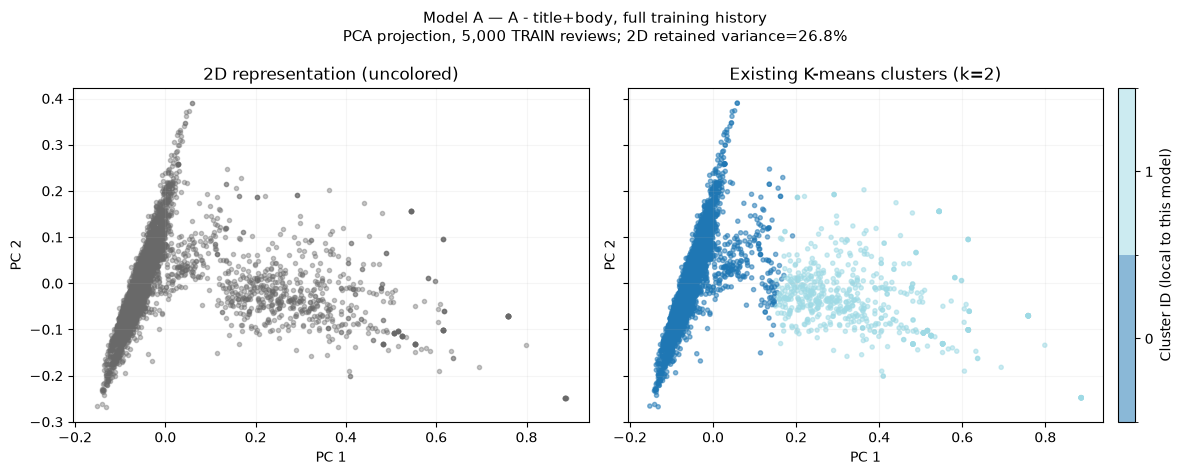

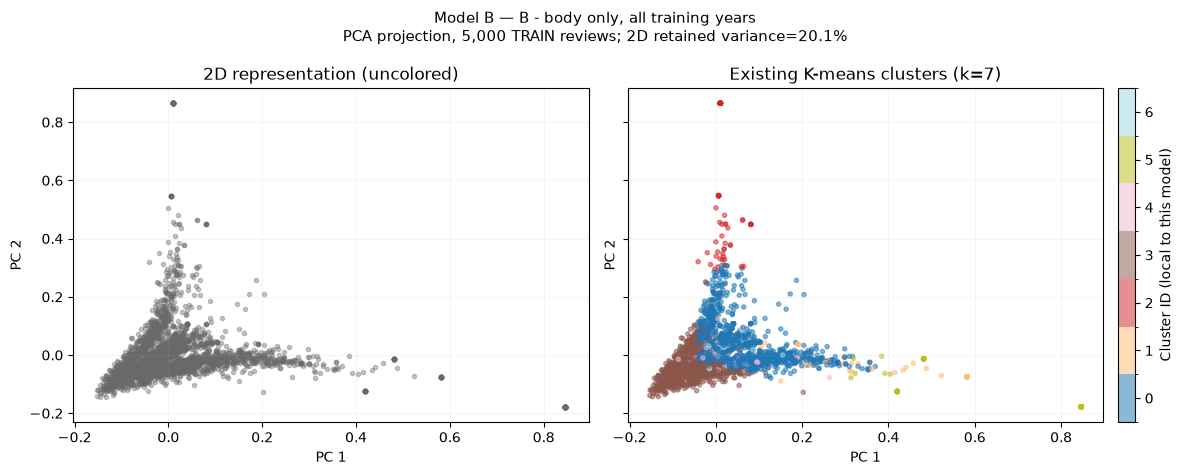

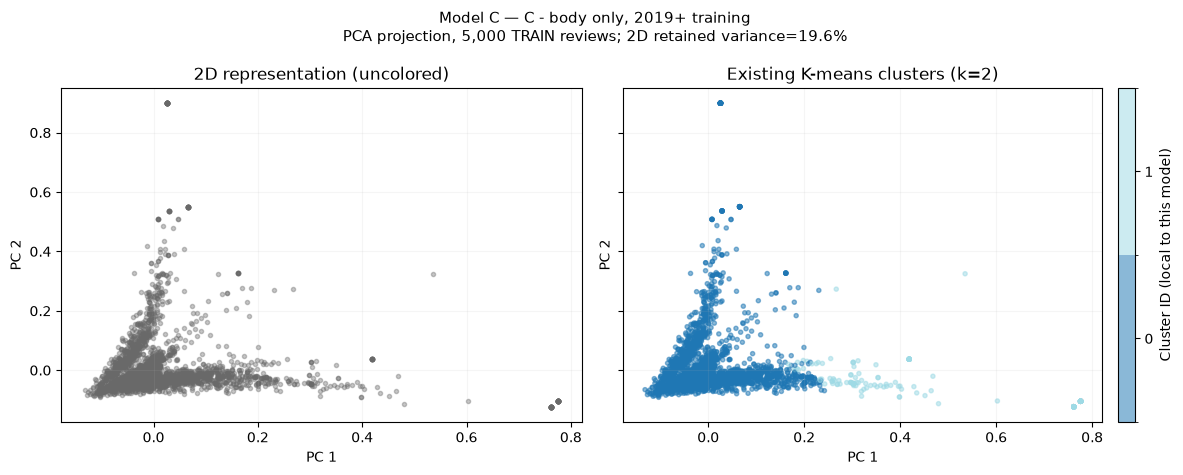

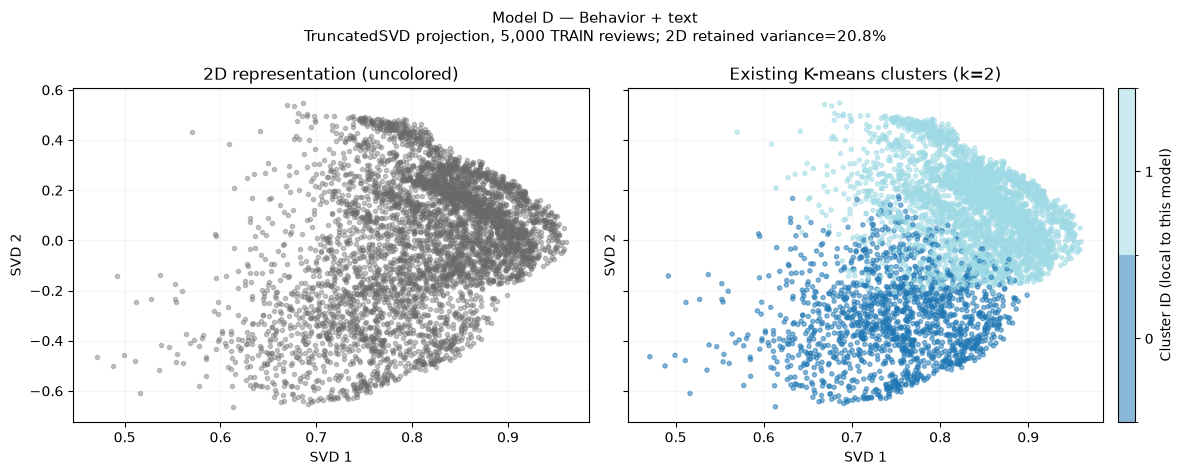

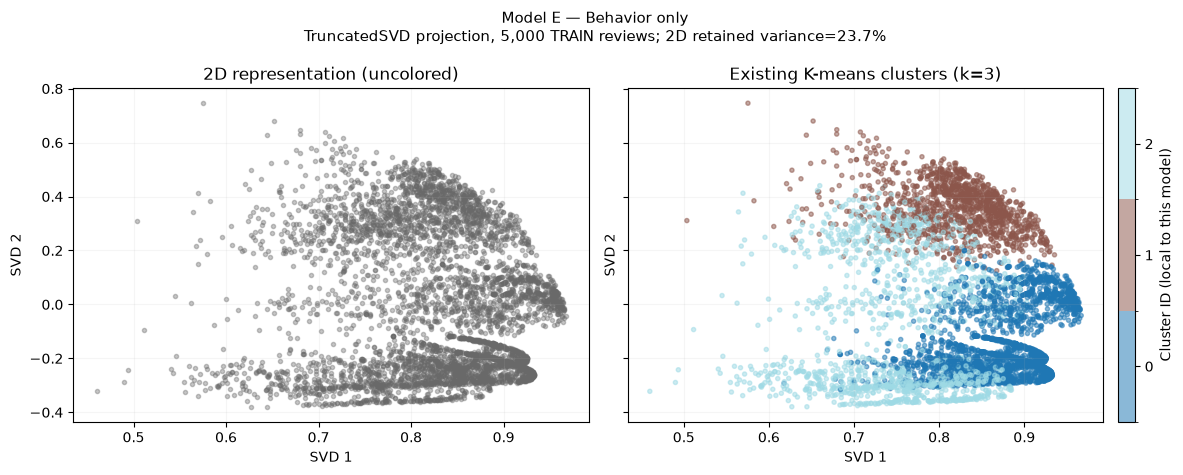

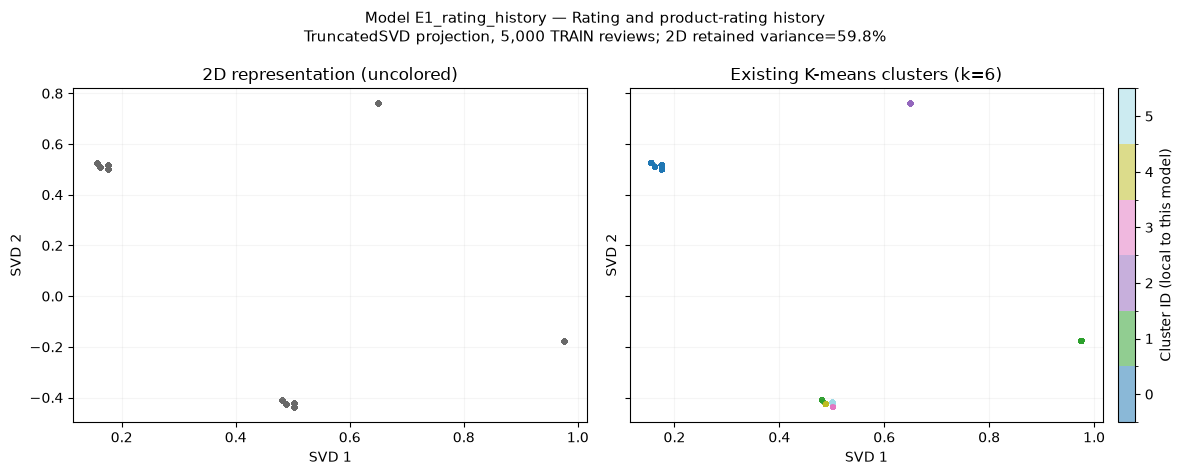

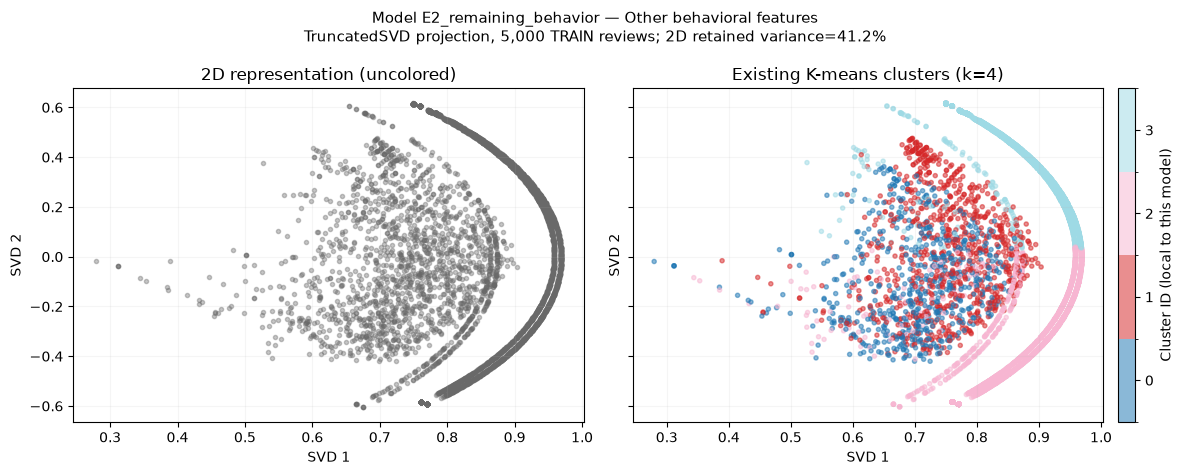

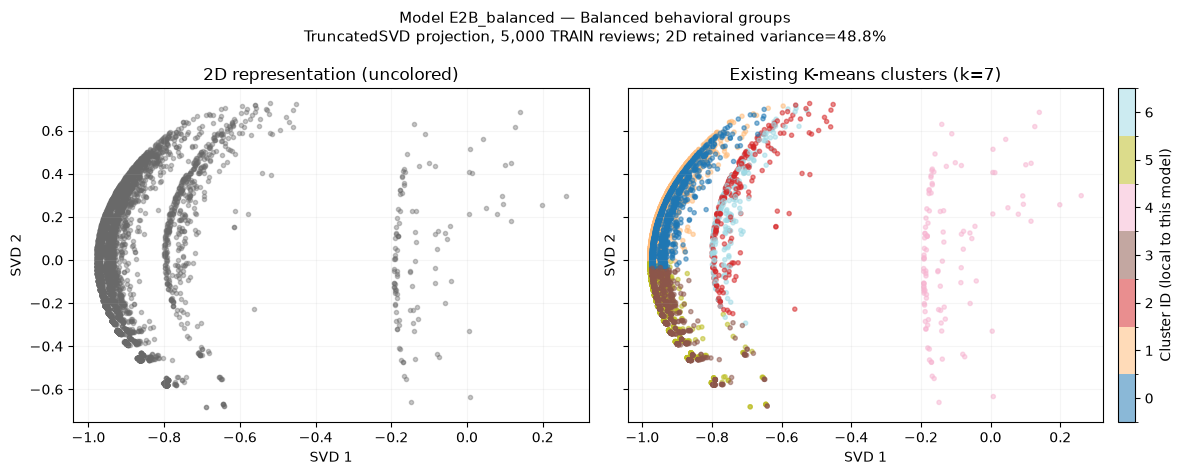

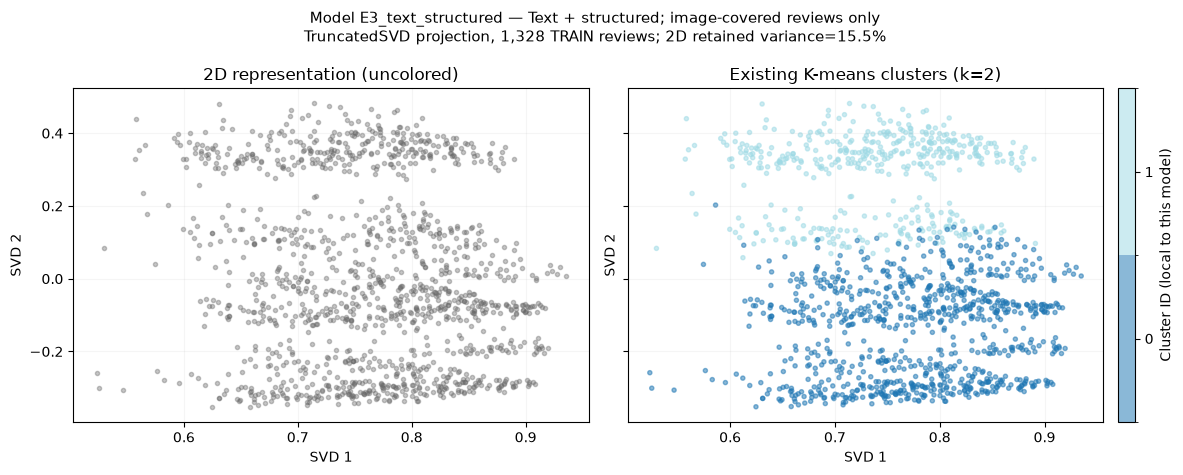

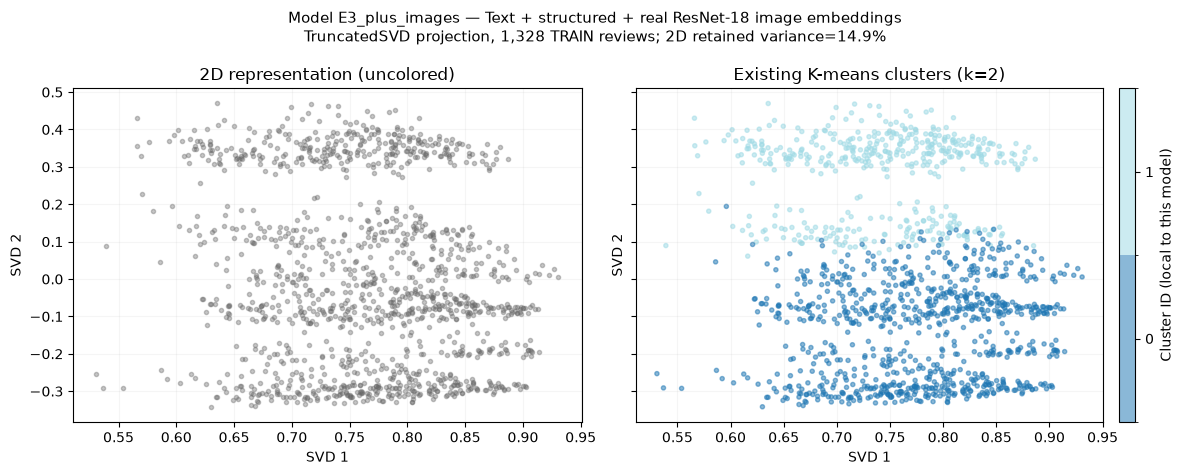

,model,description,n_train_rows,n_plotted_train_rows,k_distinct,projection,two_dimensional_explained_variance,figure_file
0,A,"A - title+body, full training history",56000,5000,2,PCA,0.267757,phase2_model_A_2d_and_clusters.png
1,B,"B - body only, all training years",56000,5000,7,PCA,0.201163,phase2_model_B_2d_and_clusters.png
2,C,"C - body only, 2019+ training",14256,5000,2,PCA,0.195664,phase2_model_C_2d_and_clusters.png
3,D,Behavior + text,14256,5000,2,TruncatedSVD,0.207995,phase2_model_D_2d_and_clusters.png
4,E,Behavior only,14256,5000,3,TruncatedSVD,0.237431,phase2_model_E_2d_and_clusters.png
5,E1_rating_history,Rating and product-rating history,14256,5000,6,TruncatedSVD,0.597990,phase2_model_E1_rating_history_2d_and_clusters.png
6,E2_remaining_behavior,Other behavioral features,14256,5000,4,TruncatedSVD,0.411872,phase2_model_E2_remaining_behavior_2d_and_clusters.png
7,E2B_balanced,Balanced behavioral groups,14256,5000,7,TruncatedSVD,0.488190,phase2_model_E2B_balanced_2d_and_clusters.png
8,E3_text_structured,Text + structured; image-covered reviews only,1328,1328,2,TruncatedSVD,0.154643,phase2_model_E3_text_structured_2d_and_clusters.png
9,E3_plus_images,Text + structured + real ResNet-18 image embeddings,1328,1328,2,TruncatedSVD,0.148548,phase2_model_E3_plus_images_2d_and_clusters.png


In [79]:
# Section 8.19 — Visualize the dimensionality reduction and clustering of EVERY fitted model.
# Plotting ONLY: no refitting of clustering, no test data, no helpful-vote targets.
from sklearn.decomposition import PCA, TruncatedSVD
from matplotlib.colors import BoundaryNorm

PLOT_MAX_TRAIN_ROWS = 5000  # Fixed random subset for readable, inexpensive figures.
PLOT_DPI = 160

model_visualizations = []

# Models A/B/C: independently fitted TF-IDF + structured SVD representations.
for _name in ('A', 'B', 'C'):
    _m = abc_models[_name]
    model_visualizations.append({
        'name': _name,
        'description': _m['name'],
        'X': _m['X_train'],
        'labels': _m['train_labels'],
    })

# Models D/E: fitted behavior/text-block representations.
for _name in ('D', 'E'):
    _m = br_models[_name]
    model_visualizations.append({
        'name': _name,
        'description': 'Behavior + text' if _name == 'D' else 'Behavior only',
        'X': _m['X_train'],
        'labels': _m['train_labels'],
    })

# E1/E2: independently fitted rating-history and remaining-behavior models.
for _name, _description in (
    ('E1_rating_history', 'Rating and product-rating history'),
    ('E2_remaining_behavior', 'Other behavioral features'),
):
    _m = E_SPLIT_MODELS[_name]
    model_visualizations.append({
        'name': _name,
        'description': _description,
        'X': _m['X_train'],
        'labels': _m['train_labels'],
    })

# E2B: domain-balanced alternative, using exactly its fitted representation.
model_visualizations.append({
    'name': 'E2B_balanced',
    'description': 'Balanced behavioral groups',
    'X': _e2b_ref['train'],
    'labels': E2B_TRAIN_LABELS,
})

# Optional image pilot. Never fabricate a plot when the image experiment did not run.
if E3_STATUS.get('executed', False):
    model_visualizations.extend([
        {'name': 'E3_text_structured',
         'description': 'Text + structured; image-covered reviews only',
         'X': E3_BASE_TRAIN, 'labels': E3_BASE_LAB_T},
        {'name': 'E3_plus_images',
         'description': 'Text + structured + real ResNet-18 image embeddings',
         'X': E3_MULTI_TRAIN, 'labels': E3_MULTI_LAB_T},
    ])
else:
    print('E3 excluded from visualization:', E3_STATUS.get('reason', 'experiment not executed'))


def _phase2_make_2d_map(X_sample, seed):
    """A TRAIN-sample-fitted visualization only; never changes clustering inputs."""
    if X_sample.shape[0] < 3 or X_sample.shape[1] < 1:
        raise ValueError('Need at least three rows and one feature for a 2D plot.')
    n_features = int(X_sample.shape[1])
    # The rare 1-D/2-D case is already low-dimensional.
    if n_features == 1:
        v = X_sample.toarray() if sparse.issparse(X_sample) else np.asarray(X_sample)
        return np.column_stack([v[:, 0], np.zeros(v.shape[0])]), 'original feature', None
    if sparse.issparse(X_sample) and n_features > 2:
        reducer = TruncatedSVD(n_components=2, random_state=seed)
        method = 'TruncatedSVD'
    else:
        dense = X_sample.toarray() if sparse.issparse(X_sample) else np.asarray(X_sample)
        reducer = PCA(n_components=2, random_state=seed)
        X_sample = dense
        method = 'PCA'
    coordinates = np.asarray(reducer.fit_transform(X_sample))
    variance = float(np.sum(reducer.explained_variance_ratio_))
    return coordinates, method, variance


visualization_cache = []
visualization_rows = []
for _i, _spec in enumerate(model_visualizations):
    _X, _labels = _spec['X'], np.asarray(_spec['labels'], dtype=int)
    if _X.shape[0] != len(_labels):
        raise ValueError(f"{_spec['name']}: input rows and cluster labels differ.")
    _n = min(PLOT_MAX_TRAIN_ROWS, len(_labels))
    _indices = np.sort(np.random.default_rng(SEED + 901 + _i).choice(
        len(_labels), size=_n, replace=False))
    _coordinates, _method, _variance = _phase2_make_2d_map(
        _X[_indices], seed=SEED + 100 + _i)
    _classes = np.unique(_labels)  # Label IDs are specific to each model.
    _codes = np.searchsorted(_classes, _labels[_indices])
    _colors = plt.get_cmap('tab20', max(2, len(_classes)))
    _norm = BoundaryNorm(np.arange(len(_classes) + 1) - 0.5, _colors.N)
    _x_label = 'PC 1' if _method == 'PCA' else ('SVD 1' if _method == 'TruncatedSVD' else 'Feature 1')
    _y_label = 'PC 2' if _method == 'PCA' else ('SVD 2' if _method == 'TruncatedSVD' else 'Zero')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
    axes[0].scatter(_coordinates[:, 0], _coordinates[:, 1], s=9,
                    color='dimgray', alpha=0.38, rasterized=True)
    axes[0].set_title('2D representation (uncolored)')
    _scatter = axes[1].scatter(_coordinates[:, 0], _coordinates[:, 1],
                               c=_codes, cmap=_colors, norm=_norm,
                               s=9, alpha=0.52, rasterized=True)
    axes[1].set_title(f'Existing K-means clusters (k={len(_classes)})')
    _bar = fig.colorbar(_scatter, ax=axes[1], ticks=np.arange(len(_classes)),
                        fraction=0.05, pad=0.03)
    _bar.ax.set_yticklabels([str(c) for c in _classes])
    _bar.set_label('Cluster ID (local to this model)')
    for _ax in axes:
        _ax.set_xlabel(_x_label)
        _ax.set_ylabel(_y_label)
        _ax.grid(alpha=0.12)
    _var_note = f'; 2D retained variance={_variance:.1%}' if _variance is not None else ''
    fig.suptitle(f"Model {_spec['name']} — {_spec['description']}\n"
                 f"{_method} projection, {_n:,} TRAIN reviews{_var_note}", fontsize=11)
    fig.tight_layout()
    _file = OUTPUT_DIR / f"phase2_model_{_spec['name']}_2d_and_clusters.png"
    fig.savefig(_file, dpi=PLOT_DPI, bbox_inches='tight')
    plt.show()  # Explicitly render INSIDE the notebook, not in a popup window.
    plt.close(fig)

    visualization_cache.append({
        'name': _spec['name'], 'coordinates': _coordinates, 'codes': _codes,
        'classes': _classes, 'cmap': _colors, 'norm': _norm,
        'method': _method, 'x_label': _x_label, 'y_label': _y_label,
    })
    visualization_rows.append({
        'model': _spec['name'], 'description': _spec['description'],
        'n_train_rows': len(_labels), 'n_plotted_train_rows': _n,
        'k_distinct': len(_classes), 'projection': _method,
        'two_dimensional_explained_variance': _variance,
        'figure_file': _file.name,
    })

MODEL_2D_VISUALIZATION_SUMMARY = pd.DataFrame(visualization_rows)
MODEL_2D_VISUALIZATION_SUMMARY.to_csv(
    OUTPUT_DIR / 'phase2_all_models_visualizations.csv', index=False)
display(MODEL_2D_VISUALIZATION_SUMMARY)


#### 8.19a Overview image and existing SVD-retained-variance comparison

The overview places the **already computed projections** together so all fitted clustering results can be found in a single image. Different panels have **independent projections and cluster IDs**; similar colors do *not* identify matching groups. The second figure compares the **previously fitted** cumulative SVD variance curves of A/B/C (they need not have identical total variance, since their input representations and data differ).


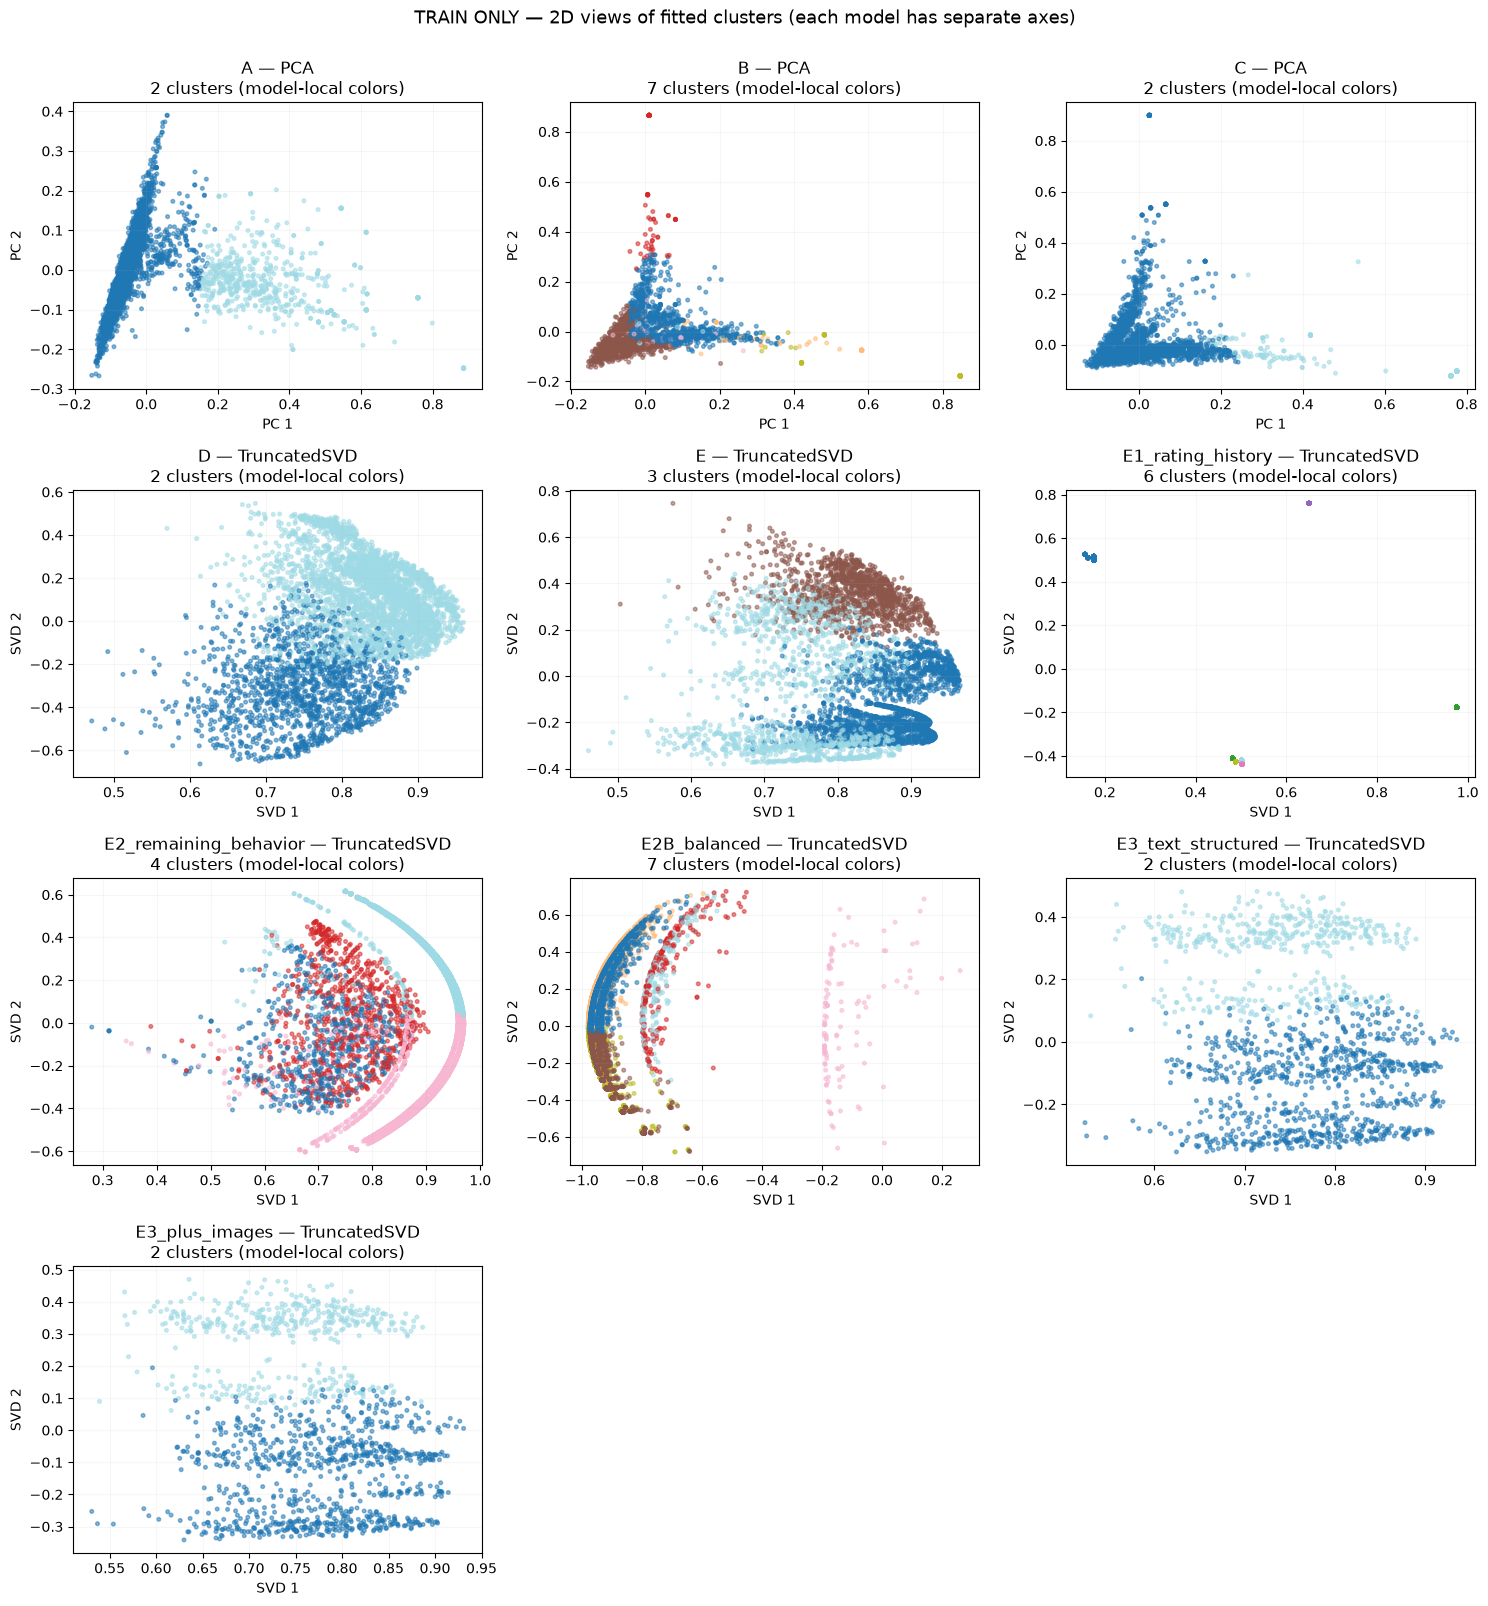

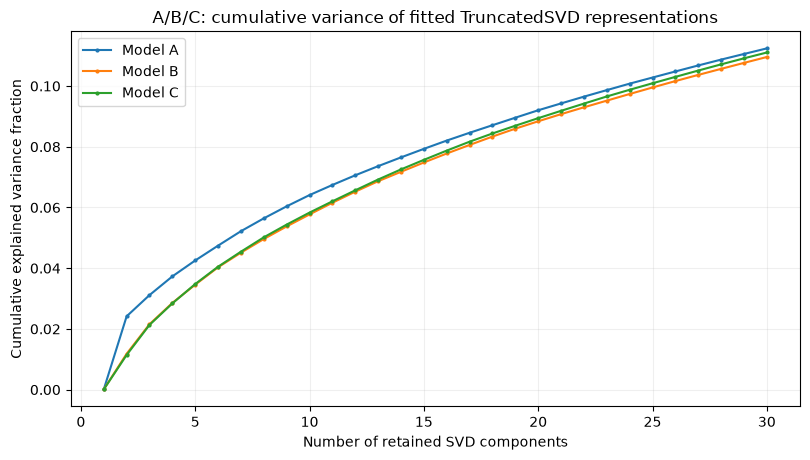

In [80]:
# One PNG overview, alongside the individual per-model images above.
import math
_ncols = 3
_nrows = math.ceil(len(visualization_cache) / _ncols)
fig, axes = plt.subplots(_nrows, _ncols, figsize=(15, 4.0 * _nrows), squeeze=False)
for _ax in axes.flat:
    _ax.set_visible(False)
for _ax, _view in zip(axes.flat, visualization_cache):
    _ax.set_visible(True)
    _z = _view['coordinates']
    _ax.scatter(_z[:, 0], _z[:, 1], c=_view['codes'], cmap=_view['cmap'],
                norm=_view['norm'], s=7, alpha=0.53, rasterized=True)
    _ax.set_title(f"{_view['name']} — {_view['method']}\n"
                  f"{len(_view['classes'])} clusters (model-local colors)")
    _ax.set_xlabel(_view['x_label'])
    _ax.set_ylabel(_view['y_label'])
    _ax.grid(alpha=0.10)
fig.suptitle('TRAIN ONLY — 2D views of fitted clusters (each model has separate axes)',
             fontsize=13, y=1.001)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'phase2_all_models_clustering_overview.png',
            dpi=PLOT_DPI, bbox_inches='tight')
plt.show()
plt.close(fig)

# Compare the EXISTING, fitted A/B/C high-dimensional -> SVD representations.
fig, ax = plt.subplots(figsize=(8.2, 4.7))
for _name in ('A', 'B', 'C'):
    _ratio = np.asarray(abc_models[_name]['svd'].explained_variance_ratio_)
    ax.plot(np.arange(1, len(_ratio) + 1), np.cumsum(_ratio),
            marker='.', markersize=4, label=f'Model {_name}')
ax.set_title('A/B/C: cumulative variance of fitted TruncatedSVD representations')
ax.set_xlabel('Number of retained SVD components')
ax.set_ylabel('Cumulative explained variance fraction')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'phase2_ABC_svd_variance_comparison.png',
            dpi=PLOT_DPI, bbox_inches='tight')
plt.show()
plt.close(fig)


#### 8.19b E2 algorithm × scaling visual comparison (existing diagnostic fits)

The E2 alternative-algorithm experiment already fitted K-means, Ward hierarchical clustering, cosine-average hierarchical clustering, and a diagonal-covariance Gaussian mixture under three scalers on the **same training subsample**. The next image illustrates those **existing** labels. Within each scaler (row), all four algorithms are plotted using the **same 2D coordinates**. Colors encode arbitrary cluster IDs, not semantically matched groups. This image is a qualitative sensitivity check, **not** a substitute for the ARI and silhouette numbers in Section 8.17a.


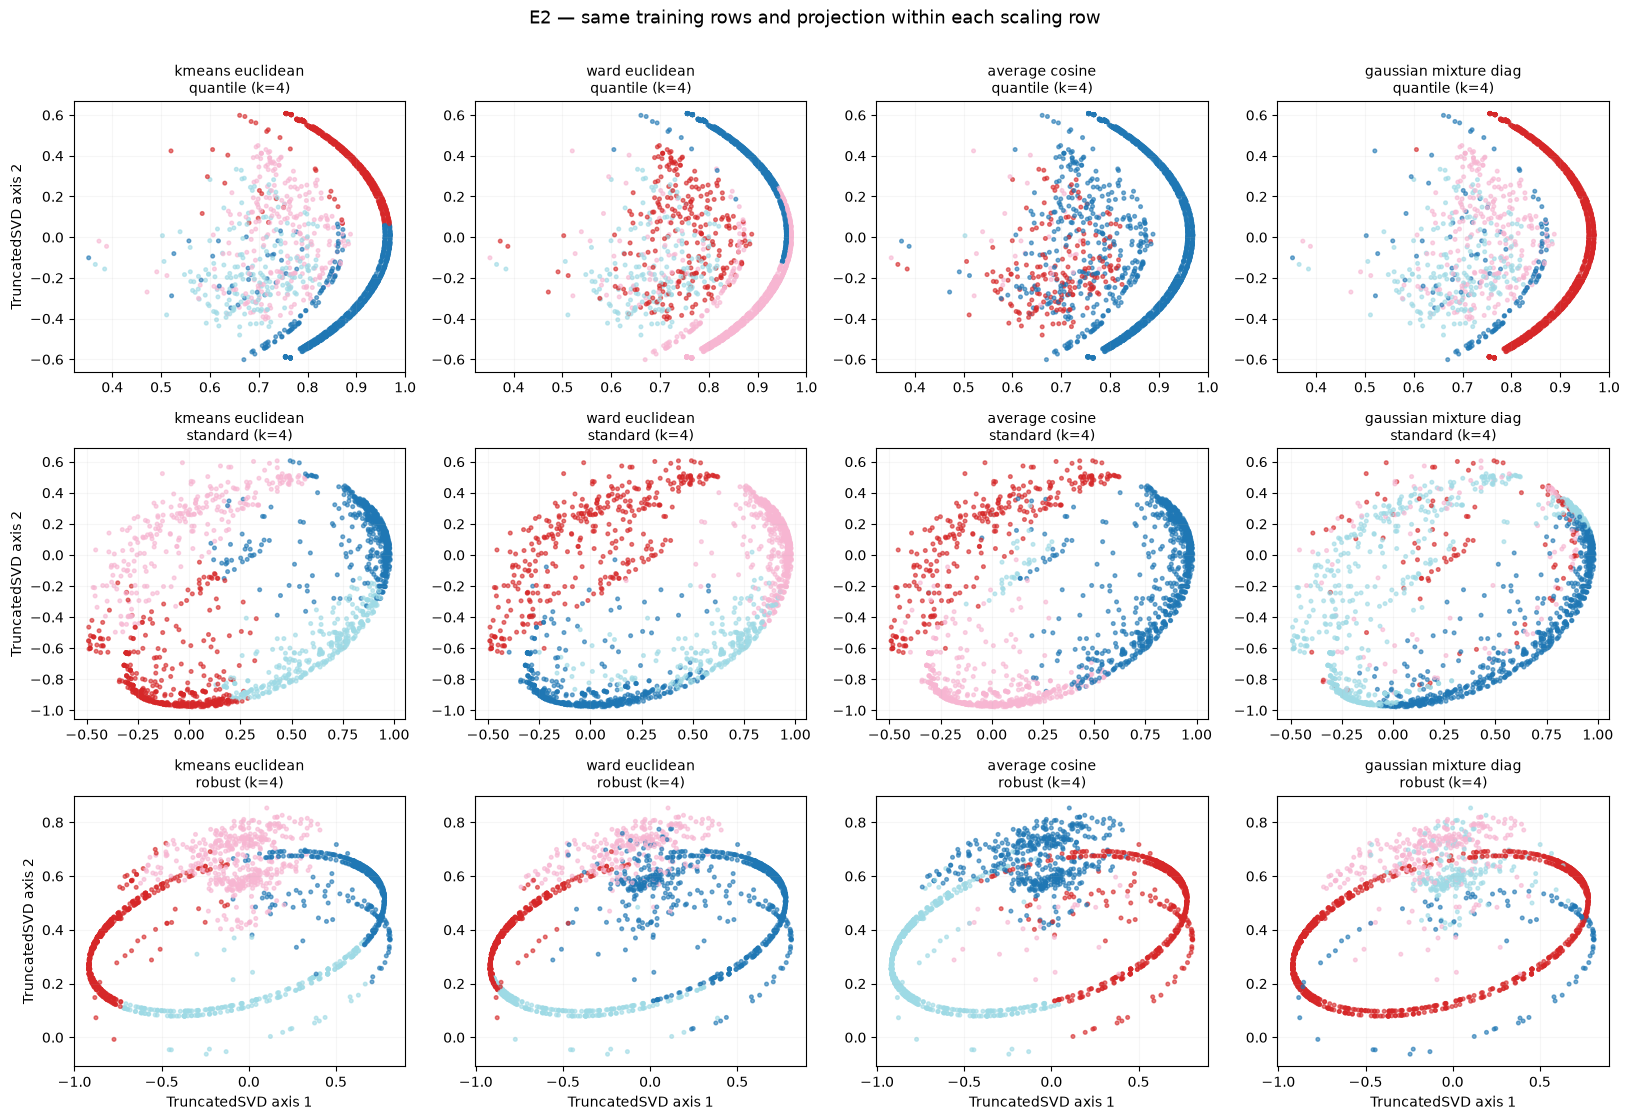

In [81]:
# Reuse fitted E2 method labels and the same 1600-row training diagnostic matrices.
# This cell fits 2D visualization projections ONLY; does not refit any cluster estimator.
_methods = list(E2_METHODS)
_scalers = list(E2_METHODS_SCALERS)
fig, axes = plt.subplots(len(_scalers), len(_methods),
                         figsize=(4.1 * len(_methods), 3.7 * len(_scalers)),
                         squeeze=False)
for _row, _scaler in enumerate(_scalers):
    _X = _e2_method_matrices[_scaler]
    _coords, _projection_name, _ = _phase2_make_2d_map(
        _X, seed=SEED + 700 + _row)
    for _col, _method in enumerate(_methods):
        _labels = np.asarray(_e2_method_labels_by_name[(_method, _scaler)], dtype=int)
        if len(_labels) != len(_coords):
            raise ValueError('E2 diagnostic algorithm labels do not match sample rows.')
        _unique = np.unique(_labels)
        _codes = np.searchsorted(_unique, _labels)
        _cmap = plt.get_cmap('tab20', max(2, len(_unique)))
        _norm = BoundaryNorm(np.arange(len(_unique) + 1) - 0.5, _cmap.N)
        _ax = axes[_row, _col]
        _ax.scatter(_coords[:, 0], _coords[:, 1], c=_codes,
                    cmap=_cmap, norm=_norm, s=7, alpha=0.6, rasterized=True)
        _ax.set_title(f'{_method.replace("_", " ")}\n{_scaler} (k={len(_unique)})', fontsize=10)
        if _col == 0:
            _ax.set_ylabel(f'{_projection_name} axis 2')
        if _row == len(_scalers) - 1:
            _ax.set_xlabel(f'{_projection_name} axis 1')
        _ax.grid(alpha=0.10)
fig.suptitle('E2 — same training rows and projection within each scaling row',
             fontsize=13, y=1.005)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'phase2_E2_algorithms_clustering_2d.png',
            dpi=PLOT_DPI, bbox_inches='tight')
plt.show()
plt.close(fig)


# 9. Save Phase 2 outputs


In [82]:
# Export target-free assignments. Test helpful-vote values remain untouched in Phase 2.
assignment_frames = []
for split_name, split_df, labels in [
    ('train', train_features, train_cluster_labels),
    ('validation', validation_features, validation_cluster_labels),
    *([('test', test_features, test_cluster_labels)] if RUN_FINAL_TEST_AUDIT else []),
]:
    part = split_df[['sample_row_id', 'dataset_category', 'timestamp_dt']].copy()
    part['split'] = split_name
    part['cluster'] = np.asarray(labels, dtype=int)
    assignment_frames.append(part)
cluster_assignments = pd.concat(assignment_frames, ignore_index=True)
assert not any('helpful_vote' in c for c in cluster_assignments.columns)
cluster_assignments.to_csv(OUTPUT_DIR / 'phase2_model_A_reference_assignments_TARGET_FREE.csv', index=False)

# Persist the full audit trail. The test cluster profile is TARGET-FREE by construction.
tables_to_save = {
    'phase2_ABC_k_selection.csv': abc_k_candidates,
    'phase2_ABC_distinctive_terms.csv': abc_distinctive_terms,
    'phase2_ABC_category_mix.csv': abc_category_mix,
    'phase2_ABC_model_comparison.csv': abc_model_comparison,
    'phase2_ABC_cluster_profiles.csv': abc_cluster_profiles,
    'phase2_ABC_validation_ARI.csv': abc_validation_ari,
    **({'phase2_ABC_selected_test_profile_TARGET_FREE.csv': abc_selected_test_profile} if RUN_FINAL_TEST_AUDIT else {}),
    'phase2_file_audit.csv': file_audit,
    'phase2_quality_checks.csv': quality_checks,
    'phase2_duplicate_checks.csv': duplicate_checks,
    'phase2_train_target_quality.csv': train_target_quality,
    'phase2_identifier_overlap_audit.csv': identifier_overlap_audit,
    'phase2_cross_split_exact_duplicates.csv': exact_cross_split,
    'phase2_cross_split_possible_resubmissions.csv': resubmission_cross_split,
    'phase2_semantic_missingness.csv': meaningful_missingness,
    'phase2_price_audit.csv': price_audit,
    'phase2_price_missingness_by_split.csv': price_missing_by_split,
    'phase2_price_missingness_by_category_year.csv': price_missing_by_category_year,
    'phase2_feature_filter.csv': feature_filter_table,
    'phase2_correlated_feature_pairs.csv': correlated_feature_pairs,
    'phase2_fitted_price_imputation.csv': price_imputation_check,
    'phase2_svd_variance.csv': variance_by_component,
    'phase2_svd_dimension_sensitivity.csv': svd_dimension_diagnostics,
    'phase2_modality_sensitivity.csv': modality_diagnostics,
    'phase2_robustness_ablation_results.csv': robustness_variant_table,
    'phase2_robustness_ablation_explanations.csv': robustness_comparison_notes,
    'phase2_cluster_share_by_split.csv': cluster_share_by_split,
    'phase2_phrase_and_length_drift.csv': phrase_and_length_drift,
    'phase2_five_stars_by_split.csv': title_phrase_by_period,
    'phase2_five_stars_by_year.csv': yearly_formulaic_title,
    'phase2_distinctive_cluster_terms.csv': distinctive_cluster_terms,
    'phase2_representative_examples.csv': representative_review_examples,
    'phase2_reference_cluster_interpretation.csv': reference_cluster_interpretation,
    'phase2_missingness_report.csv': missingness_report,
    'phase2_availability_by_category.csv': availability_by_category,
    'phase2_feature_registry.csv': feature_registry,
    'phase2_snapshot_metadata_feature_policy.csv': SNAPSHOT_FEATURE_POLICY,
    'phase2_feature_quality.csv': feature_quality,
    'phase2_history_feature_comparison.csv': history_feature_comparison,
    'phase2_history_cluster_comparison.csv': history_cluster_comparison,
    'phase2_split_info.csv': split_info,
    'phase2_kmeans_candidates.csv': candidate_table,
    'phase2_subsample_stability.csv': subsample_stability,
    'phase2_stability_summary.csv': stability_summary,
    'phase2_train_cluster_profile.csv': train_cluster_profile,
    'phase2_validation_cluster_profile.csv': validation_cluster_profile,
    **({'phase2_model_A_test_cluster_profile_TARGET_FREE.csv': test_cluster_profile} if RUN_FINAL_TEST_AUDIT else {}),
    'phase2_train_cluster_category_mix.csv': train_category_mix,
    'phase2_top_cluster_terms.csv': top_cluster_terms,
    'phase2_within_month_helpfulness_comparisons.csv': helpfulness_within_month,
    'phase2_within_week_helpfulness_comparisons.csv': helpfulness_within_week,
    'phase2_within_time_stratum_details.csv': helpfulness_stratum_details,
    'phase2_within_month_vs_week_directions.csv': helpfulness_month_week_comparison,
}
for filename, table in tables_to_save.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
(OUTPUT_DIR / 'phase2_identifier_only_test_leakage_audit.json').write_text(
    json.dumps(IDENTIFIER_LEAKAGE_AUDIT, indent=2), encoding='utf-8')

history_policy_assignments.to_csv(OUTPUT_DIR / 'phase2_history_policy_assignments_TARGET_FREE.csv', index=False)
if RUN_FINAL_TEST_AUDIT and not abc_selected_assignments.empty:
    abc_selected_assignments.to_csv(OUTPUT_DIR / 'phase2_ABC_preferred_test_assignments_TARGET_FREE.csv', index=False)

preprocessing_spec = {
    'offline_deterministic_entrypoint': 'prepare_phase2_feature_table(joined_sample)',
    'complete_frozen_reference_entrypoint': 'transform_phase2_reference(bundle, input_frame, input_stage=...)',
    'fitted_reference_bundle_PRIVATE': 'phase2_reference_workflow_PRIVATE.joblib',
    'snapshot_prediction_context': PREDICTION_CONTEXT,
    'product_metadata_point_in_time_verified': False,
    'at_review_publication_prediction_supported': False,
    'pre_split_exploration_scope': 'TRAIN-only after split fixed in Section 1.2',
    'deterministic_steps': [
        'src.data_io.build_reviews_dataframe: seeded input sampling and metadata join',
        'src.cleaning.clean_review_dataframe: immutable raw fields, normalized text, timestamp, price',
        'src.diagnostics.audit_duplicate_signatures: add non-destructive duplicate audits',
        'src.features.engineer_review_features: text/metadata/time and initial rolling strictly-earlier sampled history',
        'Section 4.1a apply_frozen_training_history: overwrite validation/test prior counts and log1p features from training events only',
    ],
    'train_fitted_steps': [
        'TF-IDF vocabulary/doc frequencies and L2 row normalization',
        'Numeric median imputation with missingness indicators (training rows only)',
        'Categorical missing category and train-fitted one-hot encoder',
        'Numeric scaling and structured row normalization (training rows only)',
        'TruncatedSVD (training rows only); PCA is visualization only',
        'K-means trained on training representation',
    ],
    'history_assumption': 'reference=frozen training events for validation/test; train uses strictly-earlier training events; comparison=rolling strictly-earlier sampled timeline; no votes',
    'historical_feature_names': list(HISTORY_GROUPS) + list(HISTORY_LOG_FEATURES.values()),
    'history_feature_comparison_csv': 'phase2_history_feature_comparison.csv',
    'history_cluster_comparison_csv': 'phase2_history_cluster_comparison.csv',
    'frozen_inference_requires_training_history': True,
    'frozen_inference_history_saved_separately_PRIVATE': True,
    'fit_partition': 'chronological train only',
    'diagnostic_variants_not_automatically_selected': True,
    'A_B_C_comparison': {'chosen': ABC_PREFERRED_MODEL, 'status': ABC_DECISION_STATUS, 'no_new_test_check': True},
    'D_E_behavior_aware': {'chosen': BR_PREFERRED_MODEL, 'status': BR_DECISION_STATUS, 'model_file': 'phase2_DE_behavior_aware_models.joblib', 'corrected_qualification_file': 'phase2_DE_model_comparison_corrected.csv'},
    'F_fused_behavior_text': {'status':'archived_negative_control_not_refitted',
                              'historical_ARI_vs_simple_control':1.0,
                              'historical_ARI_when_text_removed':1.0},
    'E2B_balanced': {'status':E2B_STATUS, 'selected_for_deployment':False,
                     'structurally_stable':E2B_STRUCTURALLY_STABLE,
                     'helpful_vote_posthoc_csv':'phase2_E2B_helpful_vote_profiles_POSTHOC.csv',
                     'model_file':'phase2_E2B_balanced_candidate.joblib'},
    'test_feature_audit_enabled': RUN_FINAL_TEST_AUDIT,
    'test_identifier_only_leakage_audit': IDENTIFIER_LEAKAGE_AUDIT,
    'prior_exploratory_test_inspection_disclosed': PRIOR_EXPLORATORY_TEST_INSPECTION,
    'test_helpful_votes_inspected_in_phase2_profiles': False,
}
(OUTPUT_DIR / 'phase2_preprocessing_spec.json').write_text(
    json.dumps(preprocessing_spec, indent=2), encoding='utf-8'
)

phase2_artifacts = {
    'preprocessing_spec': preprocessing_spec,
    'preprocessing_pipeline': phase2_pipeline,
    'svd_reducer': svd_reducer,
    'pca_projection': pca_projection,
    'kmeans_model': final_kmeans,
    'selected_k': selected_k,
    'active_text_representation': ACTIVE_TEXT_REPRESENTATION,
    'feature_columns': {'numeric': active_numeric, 'categorical': active_categorical},
    'config': {
        'seed': SEED,
        'categories': CATEGORIES,
        'sample_size_per_category': REVIEW_SAMPLE_SIZE_PER_CATEGORY,
        'max_tfidf_features': MAX_TFIDF_FEATURES,
        'tfidf_min_df': TFIDF_MIN_DF,
        'svd_components': int(X_reduced_train.shape[1]),
        'selected_k': selected_k,
        'diagnostic_sample_size': DIAGNOSTIC_SAMPLE_SIZE,
        'run_extended_diagnostics': RUN_EXTENDED_DIAGNOSTICS,
        'sensitivity_variants_are_diagnostics_only': True,
        'reference_history_regime': 'training-history-frozen',
        'comparison_history_regime': 'rolling-strict-earlier',
    },
    'sentence_embedding_metadata': sentence_embedding_metadata,
}
joblib.dump(phase2_artifacts, OUTPUT_DIR / 'phase2_model_A_reference_fitted_artifacts.joblib', compress=3)
# PRIVATE MODEL BUNDLE: contains train-history user/product identifiers, not helpful votes.
# Necessary for actual frozen-history transformation; do not commit/publish it.
_private_reference_path = OUTPUT_DIR / 'phase2_reference_workflow_PRIVATE.joblib'
joblib.dump(PHASE2_REFERENCE_BUNDLE, _private_reference_path, compress=3)
_loaded_bundle = joblib.load(_private_reference_path)
_X_reloaded = transform_phase2_reference(
    _loaded_bundle, rolling_validation_features.iloc[:_n_reference_smoke],
    input_stage='engineered_features')
assert np.allclose(_X_reloaded.toarray(), _expected_smoke.toarray(), atol=1e-7)
print('Private end-to-end frozen-history bundle saved/reloaded; keep it out of public repositories.')
# Candidate model objects (no raw reviews, reviewer IDs or helpful-vote targets).
_abc_serializable = {}
for _name, _model in abc_models.items():
    _abc_serializable[_name] = {
        'pipeline': _model['pipeline'], 'svd': _model['svd'],
        'kmeans': _model['kmeans'], 'selected_k': _model['k'],
        'text_mode': _model['text_mode'],
        'train_period': ('2019+ train' if _name == 'C' else 'all train'),
        'numeric_features': _model['numeric'],
        'categorical_features': _model['categorical'],
        'history_policy': 'training-history-frozen',
    }
joblib.dump({'models': _abc_serializable,
             'preferred': ABC_PREFERRED_MODEL,
             'decision_status': ABC_DECISION_STATUS,
             'requires_external_train_event_history_for_frozen_features': True},
            OUTPUT_DIR / 'phase2_ABC_candidate_models.joblib', compress=3)


# A usable model-side entry point for PRE-ENGINEERED reviews.
# Pass identical columns. To create reference (frozen) historical predictors,
# call prepare_phase2_feature_table with the available sample history, split it,
# and then apply_frozen_training_history(training_history, heldout_rows).
# The saved model does not itself store the training-event history.
def assign_clusters_to_prepared_reviews(prepared_reviews):
    if ACTIVE_TEXT_REPRESENTATION == 'tfidf':
        _X = phase2_pipeline.transform(prepared_reviews)
    else:
        _sentences, _ = extract_sentence_embeddings(
            prepared_reviews['cleaned_text'].fillna('').astype(str),
            model_name=SENTENCE_TRANSFORMER_MODEL,
        )
        _structured = structured_branch.transform(prepared_reviews)
        _X = combine_modalities(_sentences, _structured)
    return final_kmeans.predict(svd_reducer.transform(_X))

# Check that serialized-reference inference agrees with its training assignments.
_probe_indices = np.arange(min(8, len(train_features)))
assert np.array_equal(
    assign_clusters_to_prepared_reviews(train_features.iloc[_probe_indices]),
    train_cluster_labels[_probe_indices],
)

# Generate a concrete data-derived report. No test-set helpful-vote outcomes appear.
_fmt = lambda x: 'n/a' if pd.isna(x) else f'{float(x):.4f}'
report_lines = [
    '# Phase 2 — reproducible analysis report',
    '',
    '## Scope and data',
    f'- Dataset: Amazon Reviews 2023; categories: {", ".join(CATEGORIES)}.',
    f'- Sample: {len(features_df):,} reviews; chronological split; reference model fitted on training rows only.',
    '- Outcome of the overall project: recorded helpful-vote count (NOT authenticity).',
    '- Prior target-free test inspections were present in the historical notebook; no test target used for fitting.',
    '',
    '## Data split',
    split_info.to_markdown(index=False),
    '',
    '## Feature preparation and missingness',
    '- Offline sequence: JSONL reservoir sample → metadata join → deterministic cleaning → feature engineering → chronological split.',
    '- **Reference**: validation/test prior activity from training events only (training-history-frozen); train counts use strictly earlier training events.',
    '- **Comparison**: rolling strictly-earlier prior counts from the sampled timeline; same-timestamp events excluded. Both are proxies, not full Amazon activity.',
    '- Training-only median imputation, categorical encoding, TF-IDF vocabulary and SVD; raw target excluded.',
    '',
    'Price missingness by split:',
    price_missing_by_split.to_markdown(index=False, floatfmt='.3f'),
    '',
    '## Representation and clustering',
    f'- Active reference representation: {ACTIVE_TEXT_REPRESENTATION}; TF-IDF vocabulary size: {len(tfidf_vectorizer.get_feature_names_out()):,}.',
    f'- TruncatedSVD dimensions: {X_reduced_train.shape[1]}; cumulative explained variance ratio: {float(svd_reducer.explained_variance_ratio_.sum()):.4f}.',
    f'- Working K-means k: {selected_k}; selection: {selection_reason}',
    f'- Seed ARI: {_fmt(selected_seed_stability["mean_pairwise_ari"])}.',
    f'- Subsample ARI: {_fmt(subsample_stability["ari_vs_full_training_solution"].mean())}.',
    f'- SVD-axis scaling ARI: {_fmt(scaling_sensitivity["ari_vs_baseline"])}.',
    '',
    '## Training cluster characterization (not authenticity labels)',
    reference_cluster_interpretation.to_markdown(index=False, floatfmt='.4f'),
    '',
    '## Chronological cluster drift (features only)',
    cluster_share_by_split.to_markdown(index=False, floatfmt='.4f'),
    '',
    '## Frozen vs rolling historical-availability comparison (same frozen-trained model)',
    'Feature-distribution comparison (validation/test):',
    history_feature_comparison.to_markdown(index=False, floatfmt='.4f'),
    '',
    'Cluster-assignment comparison (validation/test; no target values):',
    history_cluster_comparison.to_markdown(index=False, floatfmt='.4f'),
    '',
    '## Time-matched recorded helpful-vote comparisons (post-hoc; train/validation only)',
    'Month + category strata require at least 10 reviews in EACH contrasted group; week + category require at least 5.',
    'Differences are (group A minus B) weighted by balanced stratum sample size; not causal effects.',
    'Historical exposure and product visibility are unmeasured, so posting in the same month does not fully equalize them.',
    '',
    'Within-month comparisons:',
    helpfulness_within_month.to_markdown(index=False, floatfmt='.4f'),
    '',
    'Within-week sensitivity:',
    helpfulness_within_week.to_markdown(index=False, floatfmt='.4f'),
    '',
    '## Train-only sensitivity experiments',
]
if len(robustness_variant_table):
    report_lines.append(robustness_variant_table.to_markdown(index=False, floatfmt='.4f'))
    report_lines.append('')
else:
    report_lines.extend(['- Skipped (extended diagnostics disabled or non-TF-IDF text representation).', ''])
report_lines += [
    '## Full A/B/C model comparison: title+body versus body-only versus recent body-only',
    'Each model fits preprocessing, SVD and K-means on its own TRAIN-only cohort; k selected from train-only silhouette/stability/balance.',
    'B and C also recompute structured text statistics from body alone and omit title/body length ratio.',
    '2019+ common-cohort drift is reported separately from each model\'s fitting-cohort drift.',
    'Candidate assessment uses training + validation features only; all test helpful-vote targets remain untouched.',
    '',
    abc_model_comparison.to_markdown(index=False, floatfmt='.4f'),
    '',
    'Distinctive cluster terms (TRAIN only):',
    abc_distinctive_terms.to_markdown(index=False, floatfmt='.4f'),
    '',
    'Cluster category mixtures (TRAIN only):',
    abc_category_mix.to_markdown(index=False, floatfmt='.4f'),
    '',
    'Per-cluster feature interpretation:',
    abc_cluster_profiles.to_markdown(index=False, floatfmt='.4f'),
    '',
    f'Predeclared preferred candidate: {ABC_PREFERRED_MODEL or "NONE"}. Status: {ABC_DECISION_STATUS}.',
    'The full cluster-meaning audit, including body-empty rates, is required before calling any grouping substantively useful.',
    'Preferred candidate TEST check (disabled during continued model development):',
    abc_selected_test_profile.to_markdown(index=False, floatfmt='.4f') if not abc_selected_test_profile.empty else 'Intentionally not performed during continued model development.',
    '',
]
report_lines += [
    '## Interpretation and limitations',
    '- K-means cluster membership is descriptive, not an authenticity or fake-review label.',
    '- High seed/subsample stability alone does not imply scaling or temporal stability.',
    '- A formulaic title cluster that disappears later may reflect platform/date conventions rather than a timeless behavior type.',
    '- Silhouette and ARI reflect geometry/assignment agreement, not a guarantee of useful prediction.',
    '- Pricing metadata are often missing and may vary with period and product category; see no-price ablation.',
    '- Validation cluster proportions are exploratory drift; test summaries remain deferred unless the final-audit switch is enabled.',
    '- Frozen counts exclude validation and test events; rolling counts can include strictly earlier events from those periods. Use only the regime supported at deployment.',
    '- The comparison does NOT refit K-means, and it does not establish which history regime is more predictive.',
    '- The age proxy references the full sample; it is used only for interpretation, never fitting.',
    '- Later helpful-vote differences are observational, affected by time/exposure and not causal.',
    '- Same-reviewer/product generalization is not guaranteed by this chronological split.',
    '- Some duplicate/resubmission signatures may cross split boundaries; no rows silently removed.',
    '- Diagnostic variants are NOT automatically substituted; rerun the full selection/stability process if changing the reference representation.',
    '- Additional D/E candidates use body-only text (D only) plus behavioral history and anomaly proxies; clustering still does NOT identify fake reviews.',
    '- New D/E scaling checks are invariance to numeric units and stability to block weights, NOT equivalence to arbitrary SVD-axis standardization.',
    '- New model checks and selection are train/validation only. No new test examination is performed while the models are changing.',
    '',
    '## Deliverables / next steps',
    '- Check notebook charts and saved CSVs; complete report interpretation as needed.',
    '- Save notebook and report to the repository, then create the phase-2 git tag after review.',
]

# Interpret warning signals automatically, without selecting models from validation/test outcomes.
report_lines.extend(['', '## Automated caution flags'])
for _row in history_cluster_comparison.itertuples(index=False):
    report_lines.append(f'- History regime sensitivity for {_row.partition}: {_row.fraction_changed_assignments:.2%} assignment changes (ARI={_row.ari_frozen_vs_rolling:.4f}).')
if scaling_sensitivity['ari_vs_baseline'] < 0.3:
    report_lines.append('- **Strong sensitivity to SVD-axis standardization:** reference clusters are not scaling-robust.')
else:
    report_lines.append('- The SVD-axis standardization ARI is reported above; interpret its magnitude alongside other tests.')
if small_cluster_share_validation < 0.01:
    report_lines.append('- **A reference cluster is below 1% in validation:** strong potential temporal cohort or title-convention drift.')
if len(robustness_variant_table):
    _ablation_ref = robustness_variant_table.set_index('variant')
    if 'without_price_signals' in _ablation_ref.index:
        _price_ari = _ablation_ref.loc['without_price_signals', 'ari_vs_diagnostic_baseline']
        report_lines.append(f'- The no-price diagnostic ARI is {_price_ari:.4f}; near 1 indicates price signals did not alter this particular diagnostic partition.')
    if 'without_five_stars_phrase' in _ablation_ref.index:
        _phrase_ari = _ablation_ref.loc['without_five_stars_phrase', 'ari_vs_diagnostic_baseline']
        report_lines.append(f'- The formulaic-title phrase removal ARI is {_phrase_ari:.4f}; low values mean the title phrase materially changes cluster membership.')
    if 'svd_row_l2_normalized' in _ablation_ref.index:
        _l2_ari = _ablation_ref.loc['svd_row_l2_normalized', 'ari_vs_diagnostic_baseline']
        report_lines.append(f'- The SVD row-L2 normalization ARI is {_l2_ari:.4f}; compare its stability and silhouette with the baseline.')
report_lines.append('- These observations are properties of the chosen representation and sample, NOT proof that reviews are genuine or manipulated.')

report_lines.extend(['', '## New D/E behavior-first clustering (2019+ TRAIN, unchanged validation)',
    'D combines rating disagreement with prior product ratings, reviewer/product history, repeated bodies, review characteristics and a small body-text topic block; E omits text.',
    'Historical rating and prior identical-text counts are strictly earlier in train, and frozen to TRAIN for validation; they are sample-dependent proxies.',
    'Quantile rank transform fitted on train + block-level normalization/weights avoids blindly standardizing a mixed-modality SVD.',
    'Scaling tests: numeric-unit invariance plus +-20% categorical/text weights. Stronger changes in distance geometry may still alter clusters.',
    '', br_model_comparison.to_markdown(index=False,floatfmt='.4f'), '',
    'Rate differences (inside versus outside each training cluster; positive/negative direction descriptive, not causal):',
    br_behavioral_distinctiveness.to_markdown(index=False,floatfmt='.4f'), '',
    'Train/validation feature profiles:',br_cluster_profiles.to_markdown(index=False,floatfmt='.4f'),'',
    'Time-matched helpfulness POST-HOC; NOT used in training or candidate selection:',
    br_helpfulness.to_markdown(index=False,floatfmt='.4f'),'',
    f'D/E selected candidate: {BR_PREFERRED_MODEL or "NONE"}; {BR_DECISION_STATUS}.',
    'If no model qualifies, record the issue as unresolved. Even a qualified model is descriptive, not a detector of authentic/fake reviews.',
    'The default Phase 2 assignment export remains the historical A baseline. New D/E assignments are saved separately and never include targets.',
    'No new TEST check was run for D/E. Earlier notebook versions already viewed a target-free C test audit; do not retune to TEST.',
    ''])
report_lines.extend([
    '', '## New E follow-up check 1: two-feature rating/history baseline',
    'Control S uses only observed star rating and availability of >=3 strictly earlier sampled product ratings; same k and training cohort as E. The one-hot encoder and K-means are fitted on 2019+ training reviews only.',
    'ARI and NMI measure assignment similarity. Conditional-majority purity summarizes how much of E is determined by the two simple input columns; high agreement would question the added value of E features.',
    '', EH_simple_comparison.to_markdown(index=False, floatfmt='.4f'), '',
    f'Simple model train-validation cluster-share TV: {float(EH_simple_validation_TV):.4f}.',
    'The simple model has no helpful-vote, text or additional behavior inputs; this is a model-parsimony diagnostic, not a supervised accuracy comparison.',
    '', '## New E follow-up check 2: alternate numerical scalers',
    'Same k, cohort, categorical features/weights and label-free evaluation as E. Numeric pipelines: original rank/quantile, robust 10th-90th percentile scaler clipped to ±5, and standard-zscore clipped to ±5. All new scaler fits are train-only.',
    'ARI is versus original E on the same rows. Silhouette on the same training subset, and validation cluster-share drift/size and behavioral profiles, provide context.',
    '', EH_scaler_comparison.to_markdown(index=False, floatfmt='.4f'), '',
    'Alternative scaler feature profiles:', EH_scaler_profiles.to_markdown(index=False,floatfmt='.4f'), '',
    'These are sensitivity tests; the original E and all existing A/B/C/D/E models remain unchanged. No test-set reviews or helpful votes were inspected in these checks.',
])
if EH_simple_comparison['high_similarity_ARI_ge_0p80'].all():
    report_lines.append('- **Caution:** simple rating/history nearly reconstructs E; demonstrate added behavioral value before describing E as rich discovery.')
else:
    report_lines.append('- The two-feature baseline does not fully reconstruct E; inspect its behavioral profiles before claiming added insight.')
if EH_scaler_comparison['ARI_below_caution_threshold'].any():
    report_lines.append('- **Caution:** at least one alternative numeric scaler produces a substantially different E partition. Broad scaling robustness remains unproven.')
else:
    report_lines.append('- E remains similar under the tested alternative numerical scalers, but this is not universal robustness.')

# Amazon-specific requirements: trace actual fitted representations and post-hoc cluster relationships.
report_lines.extend([
    '', '## Amazon Reviews 2023 — route B requirements',
    'The required TF-IDF baseline is fitted on TRAIN. Frozen pretrained sentence embeddings are optional; executed in this run: ' + str(bool(X_fused_train_sentence is not None)) + '.',
    'Product price/category, review length, age proxy, rating and activity features are engineered. Model E uses only its selected behavior subset; review-age proxy is descriptive only.',
    'Image references, image counts and availability flags are NOT pixel embeddings. Optional locally supplied images may be encoded with cached pretrained ResNet-18, but those vectors are not part of A–E.',
    'Clustering is at the REVIEW level; the following train/validation relationships examine category, rating and reviewer/product activity. Test helpful votes are not used.',
    '', 'Text representation audit:',
    AMAZON_TEXT_REPRESENTATIONS.to_markdown(index=False),
    '', 'Structured feature availability / model membership:',
    AMAZON_FEATURE_COVERAGE.to_markdown(index=False,floatfmt='.3f'),
    '', 'Model E category/rating/behavior relationships (all cells; share and lift):',
    AMAZON_E_ASSOCIATIONS.to_markdown(index=False,floatfmt='.3f'),
    '', 'Model E post-hoc body terms:',
    AMAZON_E_DISTINCTIVE_TERMS.to_markdown(index=False,floatfmt='.4f'),
    '', 'Model E behavior and time-matched helpfulness research summary:',
    AMAZON_E_RESEARCH_SUMMARY.to_markdown(index=False,floatfmt='.4f'),
    '- Category lift can be driven by category coverage; product-history counts are sample-based and potentially sparse.',
    '- Same-month helpfulness differences reduce time confounding but do not establish exposure equality or causation.',
    '- Model E is behavior-only: text terms are post-hoc and image pixels are not inputs.',
    '- Section 8.10 shows similarity to rating/history-only baseline; Section 8.11 shows numeric-scaler sensitivity. Both limitations remain.',
])

report_lines.extend([
    '', '## Archived Model F: negative control',
    'The previous run found ARI=1.0 versus the simpler rating/history control and ARI=1.0 when its text block was omitted. F is not refitted or promoted here.',
    'Historical figures are not newly measured outputs; use the original notebook for the full F audit.',
    '', '## E2 remaining-behavior audit and revised group-balanced candidate',
    E2_DOMINANCE_SUMMARY.to_markdown(index=False, floatfmt='.4f'),
    '', 'Original E2 scaling sensitivity:', E_SPLIT_SCALING.to_markdown(index=False, floatfmt='.4f'),
    '', 'Cross-period conditional support:', E2_CONDITIONAL_CONSISTENCY.to_markdown(index=False, floatfmt='.3f'),
    '', 'E2B train/validation and scaling checks:', E2B_SUMMARY.to_markdown(index=False, floatfmt='.4f'),
    '', E2B_SENSITIVITY.to_markdown(index=False, floatfmt='.4f'),
    '', 'E2B group-weight perturbations:', E2B_WEIGHT_SENSITIVITY.to_markdown(index=False,floatfmt='.4f'),
    '', 'E2B cluster profiles (TRAIN/VALIDATION, target-free):', E2B_CLUSTER_PROFILES.to_markdown(index=False,floatfmt='.4f'),
    '', 'E2B external diagnostics (NOT E2B inputs):', E2B_EXTERNAL_MATCHED.to_markdown(index=False,floatfmt='.4f'),
    '', 'IMPORTANT: matched-input differences do not independently validate the clusters.',
    '', 'E2B status: ' + E2B_STATUS,
    '', '## E2B and the helpful-vote research question',
    'The number of recorded helpful votes is not a clustering input; effects below are POST-HOC and observational.',
    'E2B cluster helpful-vote distributions in train and validation:',
    E2B_HELPFUL_PROFILES.to_markdown(index=False,floatfmt='.4f'),
    '', 'E2B month+category-matched cluster-versus-rest comparisons:',
    E2B_HELPFUL_MATCHED.to_markdown(index=False,floatfmt='.4f'),
    '', 'Reporting differences cannot establish whether cluster membership improves future regression.',
    '', '## Images — optional product-level pilot',
    'Pretrained encoder actually executed: ' + str(E_img_embedding_result.get('executed',False)),
    'Images are not necessarily contemporaneous with review submissions; image subset is not representative of all reviews.',
    'Same-row image comparison (E2 + image):',
    E_img_comparison.to_markdown(index=False, floatfmt='.4f') if not E_img_comparison.empty else 'Not executed (no suitable cached images/checkpoint or insufficient rows).',
    '', '## Three-modality matched-row image pilot (text + structured + image)',
    'Status: '+str(E3_STATUS),
    E3_COMPARISON.to_markdown(index=False,floatfmt='.4f') if not E3_COMPARISON.empty else
        'Not run: insufficient pixels, checkpoint, or image-covered cohort. This is not evidence of multimodal improvement.',
    '', '## Image subset selection and image-weight sensitivity',
    'Image product selection uses deterministic category-stratified SHA-256 ranking, not cache-first sampling.',
    'Identifier-only TRAIN/VALIDATION/TEST cross-split leakage review: '+json.dumps(IDENTIFIER_LEAKAGE_AUDIT),
    'Selection fingerprint: ' + E_IMAGE_SELECTION_SHA256,
    'Only provenance-bound cached image bytes with current HTTP 200/304 verification are used; missing sidecars, changed URLs, and offline-only cached files are excluded. The corresponding URL must occur in the selected split catalog. HTTP failures can still bias the matched image subset.',
    'Image-model cluster identifiers are mapped to nonimage identifiers using TRAIN assignments only, with the same mapping on validation.',
    'Legacy cache JPEG files without URL+source-hash sidecars are retained but never accepted as currently verified pixels. Fresh retrieval can create the missing provenance.',
    'Image-weight sensitivity on the SAME reviews (weights predeclared, no helpful-vote tuning):',
    image_weight_results.to_markdown(index=False, floatfmt='.4f') if not image_weight_results.empty
        else 'Not executed; see phase2_three_modality_image_weight_sensitivity_status.json.',
    'ARI=1.0 indicates an unchanged partition under the tested weights, not proof that images lack predictive content.',
    'Silhouettes across differently weighted feature spaces are not direct accuracy comparisons.',
    '', 'Image-subset helpfulness profile (POST-HOC only):',
    E3_HELPFUL_POSTHOC.to_markdown(index=False,floatfmt='.4f') if not E3_HELPFUL_POSTHOC.empty else
        'Not run.',
    '', '## Limitations',
    'Clustering is descriptive; no ground-truth manipulation labels. Helpful votes only evaluated post hoc.',
    'Model A fails temporal generalization; F is redundant; original E2 dominated by writing style and length.',
    'Seed stability is not scaling robustness. No non-qualifying experiment is automatically promoted.',
    'Temporal split does not guarantee user/product-disjoint generalization.',
    'Earlier historical notebook inspected target-free test features; current candidate development disables new test feature profiling by default.',
])
report_lines += [
    '## Prediction-time metadata boundary',
    'This is a retrospective fixed-snapshot study. Joined product listing metadata may postdate historical reviews. No at-publication or point-in-time metadata availability is claimed.',
    'The full frozen-reference preprocessing bundle is stored in phase2_reference_workflow_PRIVATE.joblib; it contains training event identifiers and MUST NOT be published.',
    'Chronological membership was fixed before exploratory missingness, availability and feature-quality analyses. Those summaries are TRAIN only.',
    'E2B external post-hoc diagnostics are automatically determined from the ACTUAL fitted feature groups, including derived-feature lineage.',
]
report_text = '\n'.join(report_lines) + '\n' 
(OUTPUT_DIR / 'phase2_report.md').write_text(report_text, encoding='utf-8')
(OUTPUT_DIR / 'phase2_summary.md').write_text(report_text, encoding='utf-8')
(OUTPUT_DIR/'phase2_model_selection_status.json').write_text(json.dumps({
    'A':'failed historical reference; not selected',
    'F':'archived negative control; not refitted',
    'E2':'scaling-sensitive diagnostic, not selected',
    'E2B':E2B_STATUS,
    'E2B_matched_external_diagnostic_consistent':E2B_ANY_EXTERNAL_CORROBORATION,
    'E2B_structural_qualification_only':E2B_STRUCTURALLY_STABLE,
    'E2B_helpful_voting_evaluated_posthoc':True,
    'three_modal_image_pilot_executed':bool(E3_STATUS.get('executed',False)),
    'image_weight_sweep_executed':bool(E3_WEIGHT_SWEEP_STATUS.get('executed',False)),
    'image_selection_policy': E_IMAGE_SELECTION_POLICY,
    'image_selection_sha256': E_IMAGE_SELECTION_SHA256,
    'cached_image_current_url_verification_required':E_IMAGE_REQUIRE_CURRENT_URL_VERIFICATION,
    'current_url_verified_image_products':int(E_img_downloads.image_valid.sum()),
    'identifier_only_test_leakage_audit':IDENTIFIER_LEAKAGE_AUDIT,
    'E2B_k_at_upper_search_boundary':E2B_K_AT_SEARCH_BOUNDARY,
    'E2B_min_group_weight_ARI':E2B_MIN_WEIGHT_ARI,
    'auto_selected':False,
    'prior_exploratory_test_inspection':PRIOR_EXPLORATORY_TEST_INSPECTION,
    'test_audit_executed':RUN_FINAL_TEST_AUDIT
},indent=2),encoding='utf-8')
# Nonmutating submission preflight. No Git tag is created automatically.
import subprocess
_required_src = (
    'project_paths.py', 'data_io.py', 'cleaning.py', 'features.py',
    'preprocessing.py', 'representations.py', 'diagnostics.py', 'clustering.py',
)
_src_audit = {name: bool((PROJECT_ROOT / 'src' / name).is_file()) for name in _required_src}
_repository_docs = {
    name: bool((PROJECT_ROOT / name).is_file())
    for name in ('README.md','PROJECT_CARD.md','requirements.txt','pyproject.toml','environment.yml')
}
_tag_exists = False
_tag_check_detail = 'not checked: Git command/repository unavailable'
try:
    _git_res = subprocess.run(['git','tag','--list','phase-2'], cwd=PROJECT_ROOT,
        capture_output=True, text=True, timeout=10, check=False)
    if _git_res.returncode == 0:
        _tag_exists = bool(_git_res.stdout.strip())
        _tag_check_detail = 'phase-2 tag exists' if _tag_exists else 'phase-2 tag not yet created'
    else:
        _tag_check_detail = 'git reported: ' + (_git_res.stderr.strip()[:180] or 'nonzero exit code')
except (OSError, subprocess.TimeoutExpired) as _git_exc:
    _tag_check_detail = type(_git_exc).__name__

_submission_preflight = {
    'project_folder_name': PROJECT_ROOT.name,
    'machine_local_project_path_exported': False,
    'required_src_presence': _src_audit,
    'src_files_all_present': all(_src_audit.values()),
    'repository_documentation_presence': _repository_docs,
    'dependency_definition_found': any(_repository_docs.get(x, False)
        for x in ('requirements.txt','pyproject.toml','environment.yml')),
    'phase2_markdown_report_created': (OUTPUT_DIR / 'phase2_report.md').is_file(),
    'phase2_image_weight_sensitivity_csv_created':
        (OUTPUT_DIR / 'phase2_three_modality_image_weight_sensitivity.csv').is_file(),
    'phase2_image_selection_manifest_created':
        (OUTPUT_DIR / 'phase2_image_selected_products_by_split.csv').is_file(),
    'phase2_images_selection_independent_of_cache': True,
    'phase2_git_tag_present': _tag_exists,
    'git_tag_check_detail': _tag_check_detail,
    'pdf_phase2_report_in_repository': (PROJECT_ROOT / 'reports' / 'phase2.pdf').is_file(),
    'no_git_mutation_performed': True,
    'note': ('File presence is not proof of correct content or reproducible execution '
             'outside the original project. Check README, dependencies, report, figures and tag.'),
}
(OUTPUT_DIR / 'phase2_submission_preflight.json').write_text(
    json.dumps(_submission_preflight, indent=2), encoding='utf-8')
print('SUBMISSION PREFLIGHT (missing external artifacts must be handled in your repository):')
print(json.dumps(_submission_preflight, indent=2))

# Hash ALL result files, including the model selection status, before creating
# the manifest. The manifest itself is omitted to avoid self-referential hashes.
import hashlib
_manifest_rows=[]
for _file in sorted(OUTPUT_DIR.iterdir()):
    if _file.is_file() and _file.name != 'phase2_run_manifest.csv':
        _manifest_rows.append({'file':_file.name, 'bytes':_file.stat().st_size,
            'sha256':hashlib.sha256(_file.read_bytes()).hexdigest()})
pd.DataFrame(_manifest_rows).to_csv(OUTPUT_DIR/'phase2_run_manifest.csv',index=False)
print('Saved revised Phase 2 outputs to:', OUTPUT_DIR)
print('Manifest entries (excluding manifest itself):',len(_manifest_rows))
print('Report:', OUTPUT_DIR / 'phase2_report.md')
print('History reference: training-history-frozen. Comparison: rolling past-only.')
print('A is a failed reference; F is an archived negative control; E2B requires substantive interpretation.')

Private end-to-end frozen-history bundle saved/reloaded; keep it out of public repositories.
SUBMISSION PREFLIGHT (missing external artifacts must be handled in your repository):
{
  "project_folder_name": "Data-Analysis-Project",
  "machine_local_project_path_exported": false,
  "required_src_presence": {
    "project_paths.py": true,
    "data_io.py": true,
    "cleaning.py": true,
    "features.py": true,
    "preprocessing.py": true,
    "representations.py": true,
    "diagnostics.py": true,
    "clustering.py": true
  },
  "src_files_all_present": true,
  "repository_documentation_presence": {
    "README.md": true,
    "PROJECT_CARD.md": true,
    "requirements.txt": true,
    "pyproject.toml": false,
    "environment.yml": false
  },
  "dependency_definition_found": true,
  "phase2_markdown_report_created": true,
  "phase2_image_weight_sensitivity_csv_created": true,
  "phase2_image_selection_manifest_created": true,
  "phase2_images_selection_independent_of_cache": true,
  "ph